<a href="https://colab.research.google.com/github/sriya-rani2005/diabetic-retinopathy-agentic-ai/blob/main/major_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!git clone https://github.com/anoushka24dev/major-project-dr.git
%cd /content/major-project-dr
!ls -la


Cloning into 'major-project-dr'...
remote: Enumerating objects: 127, done.
remote: Counting objects: 100% (127/127), done.
remote: Compressing objects: 100% (115/115), done.
remote: Total 127 (delta 9), reused 126 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (127/127), 5.64 MiB | 17.76 MiB/s, done.
Resolving deltas: 100% (9/9), done.
/content/major-project-dr
total 92
drwxr-xr-x 9 root root  4096 Oct 26 17:23 .
drwxr-xr-x 1 root root  4096 Oct 26 17:23 ..
drwxr-xr-x 3 root root  4096 Oct 26 17:23 audit_output
drwxr-xr-x 6 root root  4096 Oct 26 17:23 colab
-rw-r--r-- 1 root root 10598 Oct 26 17:23 cpu_canary_run.log
drwxr-xr-x 2 root root  4096 Oct 26 17:23 dataset
drwxr-xr-x 2 root root  4096 Oct 26 17:23 .freebuff
drwxr-xr-x 8 root root  4096 Oct 26 17:23 .git
-rw-r--r-- 1 root root    88 Oct 26 17:23 .gitignore
-rw-r--r-- 1 root root  1814 Oct 26 17:23 pending_decisions.md
-rw-r--r-- 1 root root 19871 Oct 26 17:23 PIPELINE_STATUS_HANDOFF.md
drwxr-xr-x 2 root root  4096 

In [ ]:

%cd /content/major-project-dr

!find colab dataset tests audit_output provisional_primary_split -maxdepth 3 -type f | sort


/content/major-project-dr
audit_output/analyze.py
audit_output/DATASET_AUDIT_REPORT.md
audit_output/errors.txt
audit_output/exact_dup_groups.txt
audit_output/flagged.txt
audit_output/image_stats.jsonl
audit_output/near_dup_pairs.txt
audit_output/pretraining_audit/build_log.txt
audit_output/pretraining_audit/build_provisional_manifests.py
audit_output/pretraining_audit/build_registers.py
audit_output/pretraining_audit/build_summary.json
audit_output/pretraining_audit/DATA_PIPELINE_ACCEPTANCE_CRITERIA.md
audit_output/pretraining_audit/ELIGIBILITY_MANIFEST_README.md
audit_output/pretraining_audit/LABEL_CONFLICT_REGISTER.csv
audit_output/pretraining_audit/LABEL_CONFLICT_REGISTER.md
audit_output/pretraining_audit/LABEL_POLICY_DRAFT.md
audit_output/pretraining_audit/POST_AUDIT_FEASIBILITY_REPORT.md
audit_output/pretraining_audit/PROVENANCE_MANIFEST.csv
audit_output/pretraining_audit/PROVENANCE_POLICY.md
audit_output/pretraining_audit/provisional_counts.json
audit_output/pretraining_audit/PRO

In [ ]:
import torch

if torch.cuda.is_available():
    gpu = torch.cuda.get_device_properties(0)
    print("GPU:", gpu.name)
    print("GPU memory:", round(gpu.total_memory / 1024**3, 2), "GB")
else:
    print("GPU is not available")

GPU: NVIDIA A100-SXM4-40GB
GPU memory: 39.49 GB


In [ ]:

%cd /content/major-project-dr

print("=== COLAB EXECUTION CHECKLIST ===")
!sed -n '1,220p' colab/COLAB_EXECUTION_CHECKLIST.md

print("\n=== TRAINING PIPELINE GUIDE ===")
!sed -n '1,180p' colab/PIPELINE_GUIDE.md

print("\n=== DATASET LOCATION CHECK ===")
!find /content/major-project-dr -type f \( -iname "*.jpg" -o -iname "*.jpeg" -o -iname "*.png" \) | head -20


/content/major-project-dr
=== COLAB EXECUTION CHECKLIST ===
# Colab runbook — provisional frozen ResNet-50 baseline

The authoritative description of the pipeline, its defects, and its verification is
[`colab/PIPELINE_GUIDE.md`](PIPELINE_GUIDE.md). This file is only the click-by-click
runbook.

**Nothing in this file has been executed in Colab.** Locally, everything except real
GPU/real-corpus execution has been run (see the guide, §6).

---

## Before you start

- Runtime → Change runtime type → **GPU**.
- The project folder must contain `dataset/` and `colab/`. Set `DR_PROJECT_ROOT` (or the
  `OVERRIDE_PROJECT_ROOT` variable in cell `# 1`) if discovery cannot find it.
- Make the fundus corpus reachable: set `DR_FUNDUS_ROOT` to the folder that holds the
  source-label subfolders (e.g. `11.Normal Fundus/`).
- Outputs default to `<Drive>/dr_baseline_outputs` when Drive is mounted, so a
  disconnect does not lose the run. Override with `DR_OUTPUT_DIR`.

## Step 1 — Preflight (the only ga

In [ ]:
from pathlib import Path

for base in [Path("/content"), Path("/kaggle/input"), Path("/content/drive/MyDrive")]:
    print(f"\nChecking: {base}")
    if base.exists():
        for p in list(base.iterdir())[:30]:
            print(" ", p.name)
    else:
        print("  Not available")


Checking: /content
  .config
  major-project-dr
  sample_data

Checking: /kaggle/input

Checking: /content/drive/MyDrive
  Not available


In [ ]:
%cd /content/major-project-dr

!cat colab/kaggle_notebook_docs/proposed_kaggle_dataset.txt
!cat dataset/README.md
!cat provisional_primary_split/provisional_primary_split_report.md

/content/major-project-dr
Have you decided that actually running this on Kaggle is worth doing (e.g. post the dataset on Kaggle and run from a notebook), or was this just to satisfy the "pasteable code" request?
# dataset

This package is the deterministic, test-driven data-pipeline layer for the diabetic retinopathy capstone. It works entirely on the provisional audit artifacts under `audit_output/pretraining_audit/` and never rewrites them.

## What lives here

- `manifest.py` — load and validate the primary/secondary eligibility manifests, resolve image paths, detect duplicates and missing files.
- `labels.py` — deterministic mapping between the 13 source labels and the provisional primary bands, plus the verbatim secondary task.
- `eligibility.py` — quarantine and non-DR exclusion logic driven by the manifest `eligibility` column.
- `statistics.py` — eligible class counts, status counts, and separate excluded/quarantined decomposition for reconciliation.
- `grouping.py` — helpers f

In [ ]:
%cd /content/major-project-dr

!grep -nE "DR_FUNDUS_ROOT|dataset_root|FUNDUS_ROOT|provisional_primary_split|14201" colab/pipeline.py colab/setup_helpers.py colab/colab_helpers.py colab/train.py

/content/major-project-dr
colab/pipeline.py:56:PROTECTED_DIRS = ("dataset", "colab", "tests", "audit_output", "provisional_primary_split")
colab/pipeline.py:214:    dataset_root: Optional[Path | str] = None,
colab/pipeline.py:239:        "dataset_root": None,
colab/pipeline.py:334:    root_hint = dataset_root or (os.environ.get(sh.DATASET_ENV_VAR) or "").strip() or None
colab/pipeline.py:336:    report["dataset_root"] = str(data_root) if data_root else None
colab/pipeline.py:337:    report["dataset_root_checked"] = checked_paths
colab/pipeline.py:339:        _check(report, "dataset_root", "fail", "the fundus corpus was not found",
colab/pipeline.py:343:        _check(report, "dataset_root", "pass", str(data_root))
colab/pipeline.py:486:    _say(f"dataset root: {report.get('dataset_root')}")
colab/pipeline.py:573:    dataset_root: Optional[Path | str],
colab/pipeline.py:578:        root, explicit=dataset_root or (os.environ.get(sh.DATASET_ENV_VAR) or "").strip() or None
colab/pipeline.p

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

search_root = Path("/content/drive/MyDrive/DR_Dataset/extracted")

matches = [
    p for p in search_root.rglob("*")
    if p.is_dir()
    and (p / "11.Normal Fundus").is_dir()
    and (p / "3.Mild DR").is_dir()
    and (p / "4.Moderate DR").is_dir()
]

print("Matching dataset roots:")
for p in matches:
    print(p)

Matching dataset roots:
/content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I


In [ ]:
%cd /content/major-project-dr

import os

os.environ["DR_FUNDUS_ROOT"] = (
    "/content/drive/MyDrive/DR_Dataset/extracted/"
    "Diabetic Retinopathy and Retinal Diseases Fundus I"
)

!python -m colab.pipeline preflight

/content/major-project-dr

PREFLIGHT
project     : /content/major-project-dr
split CSV   : /content/major-project-dr/provisional_primary_split/provisional_primary_split.csv
dataset root: /content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I
output dir  : /content/drive/MyDrive/dr_baseline_outputs

  [PASS] project_discovery: /content/major-project-dr
  [PASS] python_version: 3.13.16
  [PASS] dependency_torch: 2.11.0+cu130
  [PASS] dependency_torchvision: 0.26.0+cu130
  [PASS] dependency_numpy: 2.1.3
  [PASS] dependency_Pillow: 11.3.0
  [PASS] dependency_pytest: 8.4.2
  [PASS] device: cuda_available=True (NVIDIA A100-SXM4-40GB)
  [PASS] split_artifact: 14201 rows, partitions {'train': 9924, 'test': 2144, 'validation': 2133}
  [PASS] dataset_root: /content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I
  [PASS] all_image_paths_exist: all 14201 image paths exist under /content/drive/MyDrive/DR_Dataset/extracte

In [ ]:
import torch
from torchvision.models import ResNet50_Weights

weights = ResNet50_Weights.IMAGENET1K_V2
state_dict = weights.get_state_dict(progress=True)

print("Pretrained ResNet-50 weights downloaded and loaded.")
del state_dict

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 309MB/s]


Pretrained ResNet-50 weights downloaded and loaded.


In [ ]:
%cd /content/major-project-dr

!python -m colab.pipeline train --confirm

/content/major-project-dr

PREFLIGHT
project     : /content/major-project-dr
split CSV   : /content/major-project-dr/provisional_primary_split/provisional_primary_split.csv
dataset root: /content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I
output dir  : /content/drive/MyDrive/dr_baseline_outputs

  [PASS] project_discovery: /content/major-project-dr
  [PASS] python_version: 3.13.16
  [PASS] dependency_torch: 2.11.0+cu130
  [PASS] dependency_torchvision: 0.26.0+cu130
  [PASS] dependency_numpy: 2.1.3
  [PASS] dependency_Pillow: 11.3.0
  [PASS] dependency_pytest: 8.4.2
  [PASS] device: cuda_available=True (NVIDIA A100-SXM4-40GB)
  [PASS] split_artifact: 14201 rows, partitions {'train': 9924, 'test': 2144, 'validation': 2133}
  [PASS] dataset_root: /content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I
  [PASS] image_paths_sampled: all 14201 image paths exist under /content/drive/MyDrive/DR_Dataset/extracted/

In [ ]:
from pathlib import Path
from PIL import Image

bad_image = Path(
    "/content/drive/MyDrive/DR_Dataset/extracted/"
    "Diabetic Retinopathy and Retinal Diseases Fundus I/"
    "4.Moderate DR/22895_left.jpeg"
)

print("Exists:", bad_image.exists())
print("File size:", bad_image.stat().st_size if bad_image.exists() else "Missing")

if bad_image.exists():
    with open(bad_image, "rb") as f:
        print("File header:", f.read(32))

    try:
        with Image.open(bad_image) as img:
            print("Image format:", img.format)
            print("Image size:", img.size)
            img.verify()
            print("Image verification: PASS")
    except Exception as e:
        print("Image verification: FAIL")
        print(type(e).__name__, str(e))

Exists: True
File size: 0
File header: b''
Image verification: FAIL
UnidentifiedImageError cannot identify image file '/content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I/4.Moderate DR/22895_left.jpeg'


In [ ]:
import csv
from pathlib import Path

project = Path("/content/major-project-dr")
split_file = project / "provisional_primary_split/provisional_primary_split.csv"

target = "22895_left.jpeg"

with split_file.open(newline="", encoding="utf-8-sig") as f:
    rows = list(csv.DictReader(f))

matches = [
    row for row in rows
    if target in str(row)
]

print("Matching split rows:", len(matches))
for row in matches:
    print(row)

Matching split rows: 1
{'image_path': '4.Moderate DR/22895_left.jpeg', 'task': 'primary', 'partition': 'train', 'primary_class': 'Moderate NPDR', 'group_id': '4.Moderate DR/22895_left.jpeg', 'source_family': 'plain', 'patient_key_available': 'True', 'zenodo_unlinked': 'False', 'eligibility_snapshot': 'eligible_provisional', 'manifest_version': '', 'split_seed': '12345'}


In [ ]:
from pathlib import Path

dataset_root = Path(
    "/content/drive/MyDrive/DR_Dataset/extracted/"
    "Diabetic Retinopathy and Retinal Diseases Fundus I"
)

filename = "22895_left.jpeg"

print("Searching for copies of", filename)

for p in dataset_root.rglob(filename):
    print(f"Path: {p}")
    print(f"Size: {p.stat().st_size} bytes")

Searching for copies of 22895_left.jpeg
Path: /content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I/4.Moderate DR/22895_left.jpeg
Size: 0 bytes


In [ ]:
from pathlib import Path
import zipfile

zip_dir = Path("/content/drive/MyDrive/DR_Dataset")

for p in zip_dir.glob("*.zip"):
    print("ZIP found:", p.name, "Size:", round(p.stat().st_size / (1024**3), 2), "GB")

    with zipfile.ZipFile(p) as z:
        matches = [
            info for info in z.infolist()
            if info.filename.endswith("22895_left.jpeg")
        ]

        for info in matches:
            print("Entry:", info.filename)
            print("Uncompressed size:", info.file_size, "bytes")
            print("Compressed size:", info.compress_size, "bytes")

ZIP found: Diabetic Retinopathy and Retinal Diseases Fundus I.zip Size: 2.66 GB
Entry: Diabetic Retinopathy and Retinal Diseases Fundus I/4.Moderate DR/22895_left.jpeg
Uncompressed size: 125162 bytes
Compressed size: 124996 bytes


In [ ]:
from pathlib import Path
import zipfile
import io
from PIL import Image

zip_path = Path(
    "/content/drive/MyDrive/DR_Dataset/"
    "Diabetic Retinopathy and Retinal Diseases Fundus I.zip"
)

member = (
    "Diabetic Retinopathy and Retinal Diseases Fundus I/"
    "4.Moderate DR/22895_left.jpeg"
)

recovery_dir = Path("/content/dr_image_recovery")
recovery_dir.mkdir(parents=True, exist_ok=True)

recovered = recovery_dir / "22895_left.jpeg"

with zipfile.ZipFile(zip_path) as z:
    data = z.read(member)

# Verify the recovered bytes before writing them.
with Image.open(io.BytesIO(data)) as img:
    img.verify()

# Save only the recovered copy, not the original dataset file.
recovered.write_bytes(data)

print("Recovery successful")
print("Recovered size:", recovered.stat().st_size, "bytes")
print("Recovered location:", recovered)

Recovery successful
Recovered size: 125162 bytes
Recovered location: /content/dr_image_recovery/22895_left.jpeg


In [ ]:
from pathlib import Path
import shutil
from PIL import Image

# Original dataset image
original = Path(
    "/content/drive/MyDrive/DR_Dataset/extracted/"
    "Diabetic Retinopathy and Retinal Diseases Fundus I/"
    "4.Moderate DR/22895_left.jpeg"
)

# Recovered image
recovered = Path("/content/dr_image_recovery/22895_left.jpeg")

# Keep a backup of the damaged file
backup = original.with_name("22895_left.jpeg.zero_byte_backup")

# Safety checks
assert original.exists(), "Original image not found."
assert recovered.exists(), "Recovered image not found."
assert original.stat().st_size == 0, "Original is not empty; stopping safely."
assert not backup.exists(), "Backup already exists; stopping to avoid overwriting it."

# Verify recovered image before replacing anything
with Image.open(recovered) as img:
    img.verify()

# Back up the damaged file, then repair it
shutil.copy2(original, backup)
shutil.copyfile(recovered, original)

# Verify the repaired image
with Image.open(original) as img:
    img.verify()

print("REPAIR SUCCESSFUL")
print("Repaired size:", original.stat().st_size, "bytes")
print("Backup preserved at:", backup)

REPAIR SUCCESSFUL
Repaired size: 125162 bytes
Backup preserved at: /content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I/4.Moderate DR/22895_left.jpeg.zero_byte_backup


In [ ]:
%cd /content/major-project-dr
!python -m colab.pipeline status

/content/major-project-dr

RUN STATUS
  output_dir        : /content/drive/MyDrive/dr_baseline_outputs
  status            : incomplete
  epochs_trained    : 0
  best_epoch        : 0
  best_val_loss     : inf
  latest_checkpoint : None
  resumable         : False
  reason            : no complete checkpoints/epoch_XXXX/model.pt yet
  has_test_metrics  : False

Nothing to resume here; start a run with: python -m colab.pipeline train --confirm


In [ ]:
%cd /content/major-project-dr
!python -m colab.pipeline train --confirm

/content/major-project-dr

PREFLIGHT
project     : /content/major-project-dr
split CSV   : /content/major-project-dr/provisional_primary_split/provisional_primary_split.csv
dataset root: /content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I
output dir  : /content/drive/MyDrive/dr_baseline_outputs

  [PASS] project_discovery: /content/major-project-dr
  [PASS] python_version: 3.13.16
  [PASS] dependency_torch: 2.11.0+cu130
  [PASS] dependency_torchvision: 0.26.0+cu130
  [PASS] dependency_numpy: 2.1.3
  [PASS] dependency_Pillow: 11.3.0
  [PASS] dependency_pytest: 8.4.2
  [PASS] device: cuda_available=True (NVIDIA A100-SXM4-40GB)
  [PASS] split_artifact: 14201 rows, partitions {'train': 9924, 'test': 2144, 'validation': 2133}
  [PASS] dataset_root: /content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I
  [PASS] image_paths_sampled: all 14201 image paths exist under /content/drive/MyDrive/DR_Dataset/extracted/

In [ ]:
%cd /content/major-project-dr
!python -m colab.pipeline status

/content/major-project-dr

RUN STATUS
  output_dir        : /content/drive/MyDrive/dr_baseline_outputs
  status            : incomplete
  epochs_trained    : 0
  best_epoch        : 0
  best_val_loss     : inf
  latest_checkpoint : None
  resumable         : False
  reason            : no complete checkpoints/epoch_XXXX/model.pt yet
  has_test_metrics  : False

Nothing to resume here; start a run with: python -m colab.pipeline train --confirm


In [ ]:
%cd /content/major-project-dr
!python -m colab.pipeline train --help

/content/major-project-dr
usage: python -m colab.pipeline train [-h] [--project-root PROJECT_ROOT]
                                      [--dataset-root DATASET_ROOT]
                                      [--output-dir OUTPUT_DIR] [--confirm]
                                      [--resume] [--auto-resume] [--overwrite]
                                      [--allow-weight-download]
                                      [--epochs EPOCHS]
                                      [--batch-size BATCH_SIZE] [--lr LR]
                                      [--weight-decay WEIGHT_DECAY]
                                      [--patience PATIENCE]
                                      [--image-size IMAGE_SIZE] [--seed SEED]
                                      [--skip-preflight]

options:
  -h, --help            show this help message and exit
  --project-root PROJECT_ROOT
                        project folder (else auto-discover)
  --dataset-root DATASET_ROOT
                        corpus fold

In [ ]:
%cd /content/major-project-dr

!python -m colab.pipeline train \
  --confirm \
  --output-dir /content/drive/MyDrive/dr_baseline_run2

/content/major-project-dr

PREFLIGHT
project     : /content/major-project-dr
split CSV   : /content/major-project-dr/provisional_primary_split/provisional_primary_split.csv
dataset root: /content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I
output dir  : /content/drive/MyDrive/dr_baseline_run2

  [PASS] project_discovery: /content/major-project-dr
  [PASS] python_version: 3.13.16
  [PASS] dependency_torch: 2.11.0+cu130
  [PASS] dependency_torchvision: 0.26.0+cu130
  [PASS] dependency_numpy: 2.1.3
  [PASS] dependency_Pillow: 11.3.0
  [PASS] dependency_pytest: 8.4.2
  [PASS] device: cuda_available=True (NVIDIA A100-SXM4-40GB)
  [PASS] split_artifact: 14201 rows, partitions {'train': 9924, 'test': 2144, 'validation': 2133}
  [PASS] dataset_root: /content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I
  [PASS] image_paths_sampled: all 14201 image paths exist under /content/drive/MyDrive/DR_Dataset/extracted/Dia

In [ ]:
%cd /content/major-project-dr
!python -m colab.pipeline --help

/content/major-project-dr
usage: python -m colab.pipeline [-h] [--json]
                                {preflight,train,evaluate,canary,status} ...

Preflight, train/resume, evaluate, or inspect the DR baseline.

positional arguments:
  {preflight,train,evaluate,canary,status}
    preflight           check everything at once
    train               start or resume training
    evaluate            held-out test evaluation
    canary              build/validate/train the canary split
    status              inspect an output directory

options:
  -h, --help            show this help message and exit
  --json                machine-readable output

Typical sequence:
  1) python -m colab.pipeline preflight
  2) python -m colab.pipeline train --confirm
  3) python -m colab.pipeline train --confirm --resume     # after a disconnect
  4) python -m colab.pipeline evaluate --confirm


In [ ]:
%cd /content/major-project-dr
!python -m colab.pipeline evaluate --help

/content/major-project-dr
usage: python -m colab.pipeline evaluate [-h] [--project-root PROJECT_ROOT]
                                         [--dataset-root DATASET_ROOT]
                                         [--output-dir OUTPUT_DIR] [--confirm]
                                         [--batch-size BATCH_SIZE]
                                         [--image-size IMAGE_SIZE]

options:
  -h, --help            show this help message and exit
  --project-root PROJECT_ROOT
                        project folder (else auto-discover)
  --dataset-root DATASET_ROOT
                        corpus folder (else $DR_FUNDUS_ROOT or auto-discover)
  --output-dir OUTPUT_DIR
                        run output folder (persistent)
  --confirm             required opt-in
  --batch-size BATCH_SIZE
  --image-size IMAGE_SIZE


In [ ]:
%cd /content/major-project-dr

!python -m colab.pipeline evaluate \
  --confirm \
  --output-dir /content/drive/MyDrive/dr_baseline_run2

/content/major-project-dr
[pipeline] held-out evaluation from /content/drive/MyDrive/dr_baseline_run2/best_checkpoint
[pipeline] log file: /content/drive/MyDrive/dr_baseline_run2/logs/evaluate_20261026_204544.log

[ERROR] unexpected UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, do those steps only if you trust the source of the checkpoint. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL torch.torch_version.TorchVersion was not an allowed global by default. Please use `torch.serialization.add_safe_globals([tor

In [ ]:
import torch
from pathlib import Path

checkpoint = Path(
    "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint"
)

print("Checkpoint exists:", checkpoint.exists())

if checkpoint.is_dir():
    for p in checkpoint.iterdir():
        print(p.name, "-", p.stat().st_size, "bytes")
else:
    print("Checkpoint file size:", checkpoint.stat().st_size, "bytes")

Checkpoint exists: True
model.pt - 94477567 bytes
training_state.json - 708848 bytes


In [ ]:
import torch
from torch.torch_version import TorchVersion

# Allowlist only the specific class named in the error
torch.serialization.add_safe_globals([TorchVersion])

# Retry the existing evaluation pipeline
%cd /content/major-project-dr
!python -m colab.pipeline evaluate \
  --confirm \
  --output-dir /content/drive/MyDrive/dr_baseline_run2

/content/major-project-dr
[pipeline] held-out evaluation from /content/drive/MyDrive/dr_baseline_run2/best_checkpoint
[pipeline] log file: /content/drive/MyDrive/dr_baseline_run2/logs/evaluate_20261026_204656.log

[ERROR] unexpected UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, do those steps only if you trust the source of the checkpoint. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL torch.torch_version.TorchVersion was not an allowed global by default. Please use `torch.serialization.add_safe_globals([tor

In [ ]:
%cd /content/major-project-dr

!grep -R -n -E "torch\.load|weights_only|best_checkpoint" colab

/content/major-project-dr
colab/PIPELINE_GUIDE.md:173:best_checkpoint/{model.pt,training_state.json}   validation-selected copy
colab/PIPELINE_GUIDE.md:190:- `best_epoch` selected but `best_checkpoint/model.pt` missing → the selected weights are gone;
colab/pipeline.py:709:        "best_checkpoint_dir": str(result["best_checkpoint_dir"]),
colab/README.md:109:- A checkpoint round-trip writes `model.pt`, `training_state.json`, and a `best_checkpoint/` copy with compatibility metadata.
colab/COLAB_EXECUTION_CHECKLIST.md:74:It refuses unless `status` says `completed` and `best_checkpoint/model.pt` exists. Writes
colab/COLAB_EXECUTION_CHECKLIST.md:85:`run_summary.json`, `best_checkpoint/model.pt`, the per-epoch checkpoints, no
colab/smoke_test.py:308:    assert (tmp_path / "best_checkpoint" / "model.pt").is_file()
colab/smoke_test.py:310:    report = checkpoint_compat_report(tmp_path / "best_checkpoint")
colab/smoke_test.py:369:def test_final_evaluation_requires_a_best_checkpoint(tmp_path):

In [ ]:
%cd /content/major-project-dr

!sed -n '995,1045p' colab/train.py
!sed -n '1450,1490p' colab/train.py

/content/major-project-dr

    return {
        "epoch_dir": epoch_dir,
        "last_epoch": int(last_epoch),
        "previous_epochs": previous_epochs,
        "status": status,
        "state": state,
    }


def _torch_load(path: Path, device: torch.device) -> Tuple[Dict[str, Any], bool]:
    """Load a checkpoint, preferring the safe ``weights_only=True`` path.

    Falls back only for this pipeline's own checkpoints (which embed an optimizer
    state dict and plain metadata), and says so in the returned flag.
    """
    try:
        return torch.load(path, map_location=device, weights_only=True), True
    except Exception:
        return torch.load(path, map_location=device, weights_only=False), False


def load_epoch_checkpoint(
    epoch_dir: Path,
    model: nn.Module,
    optimizer: Optional[torch.optim.Optimizer],
    device: torch.device,
) -> Dict[str, Any]:
    """Restore model (and optimizer) weights from one epoch checkpoint.

    Returns ``{'epoch', 'weights_only'}``

In [ ]:
%cd /content/major-project-dr

from pathlib import Path

p = Path("colab/train.py")
source = p.read_text()

old = 'payload = torch.load(best_dir / "model.pt", map_location=device, weights_only=True)'
new = 'payload, _ = _torch_load(best_dir / "model.pt", device)'

assert source.count(old) == 1, "Expected line not found exactly once; stopping safely."

backup = Path("colab/train.py.before_eval_fix")
assert not backup.exists(), "Backup already exists; stopping safely."

backup.write_text(source)
p.write_text(source.replace(old, new, 1))

print("Compatibility fix applied.")
print("Original code backed up to:", backup)

/content/major-project-dr
Compatibility fix applied.
Original code backed up to: colab/train.py.before_eval_fix


In [ ]:
%cd /content/major-project-dr

!python -m colab.pipeline evaluate \
  --confirm \
  --output-dir /content/drive/MyDrive/dr_baseline_run2

/content/major-project-dr
[pipeline] held-out evaluation from /content/drive/MyDrive/dr_baseline_run2/best_checkpoint
[pipeline] log file: /content/drive/MyDrive/dr_baseline_run2/logs/evaluate_20261026_204855.log
{"event": "final_evaluation_done", "partition": "test", "num_samples": 2144, "accuracy": 0.722481343283582, "macro_f1": 0.6871441228287736, "output_path": "/content/drive/MyDrive/dr_baseline_run2/final_test_evaluation/final_test_metrics.json", "device": "cuda"}
{
  "num_samples": 2144,
  "accuracy": 0.722481343283582,
  "macro_precision": 0.6990719240305301,
  "macro_recall": 0.6898813652999178,
  "macro_f1": 0.6871441228287736,
  "confusion_matrix": [
    [
      439,
      0,
      0,
      5,
      4
    ],
    [
      0,
      141,
      213,
      1,
      10
    ],
    [
      3,
      121,
      633,
      13,
      32
    ],
    [
      0,
      6,
      33,
      169,
      93
    ],
    [
      0,
      0,
      15,
      46,
      167
    ]
  ]
}


In [ ]:
%cd /content/major-project-dr

!find colab -maxdepth 2 -type f | grep -Ei 'grad.?cam|explain|visual|interpret'
!find /content/drive/MyDrive/dr_baseline_run2/final_test_evaluation \
  -maxdepth 2 -type f

/content/major-project-dr
/content/drive/MyDrive/dr_baseline_run2/final_test_evaluation/final_test_metrics.json


In [ ]:
%cd /content/major-project-dr

!grep -R -n -i -E "grad.?cam|explainab|heatmap|target_layer" \
  --include="*.py" --exclude-dir="venv" .

/content/major-project-dr


In [ ]:
%cd /content/major-project-dr

!grep -R -n -i "gradcam" --include="*.py" colab .

/content/major-project-dr


In [ ]:
%cd /content/major-project-dr

!find . -maxdepth 3 -type f \
  -not -path './.git/*' \
  -not -path '*/__pycache__/*' \
  | head -100

/content/major-project-dr
./colab/PIPELINE_GUIDE.md
./colab/pipeline.py
./colab/requirements-colab.txt
./colab/README.md
./colab/colab_helpers.py
./colab/_canary_test_outputs/canary_provisional_split.csv
./colab/FIXED_NOTEBOOK_REPORT.md
./colab/_canary_split/README_canary_example.txt
./colab/COLAB_EXECUTION_CHECKLIST.md
./colab/smoke_test.py
./colab/setup_helpers.py
./colab/kaggle_notebook_docs/02_helpers.py
./colab/kaggle_notebook_docs/05_smoke.py
./colab/kaggle_notebook_docs/provisional_primary_split.csv
./colab/kaggle_notebook_docs/04_engine.py
./colab/kaggle_notebook_docs/06_labels.py
./colab/kaggle_notebook_docs/README_split.md
./colab/kaggle_notebook_docs/proposed_kaggle_dataset.txt
./colab/kaggle_notebook_docs/gen.py
./colab/kaggle_notebook_docs/03_setup.py
./colab/kaggle_notebook_docs/08_dataset_init.py
./colab/kaggle_notebook_docs/01_preflight.py
./colab/kaggle_notebook_docs/07_decoding.py
./colab/kaggle_notebook_docs/kaggle_notebook_docs.json
./colab/kaggle_notebook_docs/copy

In [ ]:
%cd /content/major-project-dr

!grep -n -E "def build_frozen_resnet50|BAND_ORDER|CLASS_NAMES|class.*Dataset|def evaluate_epoch" colab/train.py
!sed -n '1,120p' dataset/labels.py

/content/major-project-dr
70:    BAND_ORDER,
124:class PrimarySplitDataset(Dataset):
157:            if row.get("primary_class") not in BAND_ORDER:
175:        label = BAND_ORDER.index(row["primary_class"])
248:    names in ``BAND_ORDER``.
255:    k = len(BAND_ORDER)
263:    for i, name in enumerate(BAND_ORDER):
279:    macro_precision = float(np.mean([per_class[name]["precision"] for name in BAND_ORDER]))
280:    macro_recall = float(np.mean([per_class[name]["recall"] for name in BAND_ORDER]))
281:    macro_f1 = float(np.mean([per_class[name]["f1"] for name in BAND_ORDER]))
288:        "band_order": list(BAND_ORDER),
296:def evaluate_epoch(
331:        "band_order": list(BAND_ORDER),
333:        "confusion_matrix": [[0] * len(BAND_ORDER) for _ in BAND_ORDER],
378:    class_order: Sequence[str] = BAND_ORDER,
432:        missing = [name for name in BAND_ORDER if name not in class_weights]
436:            [float(class_weights[name]) for name in BAND_ORDER], dtype=torch.float32
710:      

In [ ]:
%cd /content/major-project-dr

!grep -n -E "def build_frozen_resnet50|def resolve_device|def load_rgb" colab/train.py dataset/decoding.py
!sed -n '1,100p' colab/train.py

/content/major-project-dr
colab/train.py:467:def resolve_device() -> torch.device:
dataset/decoding.py:19:def load_rgb(path: Path) -> Image.Image:
"""
Minimal, guarded frozen ResNet-50 training pipeline for the provisional primary
five-band diabetic-retinopathy task.

This module is deliberately small and defensive. It does NOT:
- modify the existing dataset, split CSV, split report, or audit artifacts;
- regenerate, reshuffle, or alter the existing train/validation/test assignment;
- use center crops or random crops at any stage;
- train on, tune on, early-stop on, or select checkpoints using the test partition;
- download pretrained weights or install packages without an explicit opt-in;
- silently overwrite a previous run, or present an incomplete run as completed;
- claim clinical validity, GPU execution, or Colab compatibility.

It DOES:
- load the existing split CSV unchanged;
- use deterministic, aspect-ratio-preserving resize-and-pad preprocessing;
- apply ImageNet normalizatio

In [ ]:
%cd /content/major-project-dr

!grep -n -A45 -E "^def build_frozen_resnet50|^def preprocessing_inference|^def load_rgb" colab/colab_helpers.py
!sed -n '120,180p' colab/train.py

/content/major-project-dr
200:def preprocessing_inference(source_size: int = 224):
201-    """Deterministic preprocessing for validation and test partitions."""
202-    from PIL import Image  # noqa: F401
203-
204-    def _apply(image):
205-        return _resize_and_pad(image, source_size, source_size)
206-
207-    return _apply
208-
209-
210:def preprocessing_inference_factory(source_size: int = 224):
211-    """Alias of :func:`preprocessing_inference` for notebook-facing calls."""
212-    return preprocessing_inference(source_size)
213-
214-
215-def default_normalize() -> Tuple[List[float], List[float]]:
216-    """ImageNet statistics used for ResNet-50 preprocessing."""
217-    mean = [0.485, 0.456, 0.406]
218-    std = [0.229, 0.224, 0.225]
219-    return mean, std
220-
221-
222-# ---------------------------------------------------------------------------
223-# Image decoding (delegates to the existing dataset package)
224-# --------------------------------------------------------

In [ ]:
%cd /content/major-project-dr

from pathlib import Path

script = r'''
import argparse
import csv
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt

from colab_helpers import (
    BAND_ORDER,
    build_frozen_resnet50,
    default_normalize,
    load_rgb,
    preprocessing_inference,
)
from train import _torch_load

def normalize_tensor(tensor):
    mean, std = default_normalize()
    mean = torch.tensor(mean, dtype=tensor.dtype)[:, None, None]
    std = torch.tensor(std, dtype=tensor.dtype)[:, None, None]
    return (tensor - mean) / std

def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--dataset-root", required=True)
    parser.add_argument("--output-dir", required=True)
    parser.add_argument("--checkpoint-dir", required=True)
    parser.add_argument("--split-csv", default="../provisional_primary_split/provisional_primary_split.csv")
    parser.add_argument("--count", type=int, default=8)
    parser.add_argument("--image-size", type=int, default=224)
    args = parser.parse_args()

    root = Path(args.dataset_root)
    out = Path(args.output_dir)
    out.mkdir(parents=True, exist_ok=True)
    project = Path(__file__).resolve().parent.parent
    split_path = (project / args.split_csv).resolve()
    checkpoint_dir = Path(args.checkpoint_dir)

    with split_path.open(newline="", encoding="utf-8") as f:
        rows = list(csv.DictReader(f))
    test_rows = [r for r in rows if r.get("partition") == "test"]
    if not test_rows:
        raise RuntimeError(f"No test rows found in {split_path}")

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = build_frozen_resnet50(num_classes=len(BAND_ORDER), pretrained=False)
    payload, _ = _torch_load(checkpoint_dir / "model.pt", device)
    model.load_state_dict(payload["model_state_dict"], strict=True)
    model.to(device).eval()

    # Grad-CAM target: last convolutional layer in ResNet50.
    target_layer = model.layer4[-1]
    activations = {}
    gradients = {}

    def forward_hook(module, inputs, output):
        activations["value"] = output

    def backward_hook(module, grad_input, grad_output):
        gradients["value"] = grad_output[0]

    h1 = target_layer.register_forward_hook(forward_hook)
    h2 = target_layer.register_full_backward_hook(backward_hook)

    preprocess = preprocessing_inference(args.image_size)
    mean, std = default_normalize()
    records = []

    try:
        for row in test_rows[:args.count]:
            image_path = root / row["image_path"]
            img = load_rgb(image_path)
            processed = preprocess(img)
            array = np.asarray(processed).astype(np.float32) / 255.0
            tensor = torch.from_numpy(array).permute(2, 0, 1)
            tensor = normalize_tensor(tensor).unsqueeze(0).to(device)

            model.zero_grad(set_to_none=True)
            logits = model(tensor)
            pred_idx = int(logits.argmax(dim=1).item())
            logits[0, pred_idx].backward()

            act = activations["value"]
            grad = gradients["value"]
            weights = grad.mean(dim=(2, 3), keepdim=True)
            cam = (weights * act).sum(dim=1, keepdim=True).relu()
            cam = F.interpolate(
                cam, size=(args.image_size, args.image_size),
                mode="bilinear", align_corners=False
            )[0, 0]
            cam = cam.detach().cpu().numpy()
            cam -= cam.min()
            if cam.max() > 0:
                cam /= cam.max()

            stem = Path(row["image_path"]).stem
            # Save the processed input so the overlay aligns with the model input.
            rgb = np.asarray(processed).astype(np.uint8)
            Image.fromarray(rgb).save(out / f"{stem}_input.png")

            plt.figure(figsize=(6, 6))
            plt.imshow(rgb)
            plt.imshow(cam, cmap="jet", alpha=0.40)
            plt.axis("off")
            plt.tight_layout()
            plt.savefig(out / f"{stem}_gradcam.png", dpi=150, bbox_inches="tight")
            plt.close()

            records.append({
                "image_path": row["image_path"],
                "true_class": row["primary_class"],
                "predicted_class": BAND_ORDER[pred_idx],
                "confidence": float(torch.softmax(logits, dim=1)[0, pred_idx].item()),
                "note": "Grad-CAM is a model attention visualization, not a clinical explanation."
            })
    finally:
        h1.remove()
        h2.remove()

    (out / "gradcam_manifest.json").write_text(
        json.dumps(records, indent=2), encoding="utf-8"
    )
    print("Grad-CAM complete.")
    print("Device:", device)
    print("Images generated:", len(records))
    print("Output directory:", out)
    print(json.dumps(records, indent=2))

if __name__ == "__main__":
    main()
'''

target = Path("colab/gradcam_visualize.py")
assert not target.exists(), f"{target} already exists; stopping to preserve it."
target.write_text(script, encoding="utf-8")
print("Created:", target)

/content/major-project-dr
Created: colab/gradcam_visualize.py


In [ ]:
%cd /content/major-project-dr

import sys
from pathlib import Path

project_root = str(Path("/content/major-project-dr").resolve())

if project_root not in sys.path:
    sys.path.insert(0, project_root)

print("Project root added:", project_root)
print("Dataset package exists:", Path(project_root, "dataset").is_dir())

import dataset
print("Dataset import successful!")

/content/major-project-dr
Project root added: /content/major-project-dr
Dataset package exists: True
Dataset import successful!


In [ ]:
%cd /content/major-project-dr

from pathlib import Path
import shutil

script = Path("colab/gradcam_visualize.py")
backup = Path("colab/gradcam_visualize.py.before_gradient_fix")

assert script.exists(), "Grad-CAM script not found."
assert not backup.exists(), "Backup already exists; stopping to protect files."

source = script.read_text()

old_hook = '''    def backward_hook(module, grad_input, grad_output):
        gradients["value"] = grad_output[0]
'''

new_hook = '''    def forward_hook(module, inputs, output):
        activations["value"] = output
        output.register_hook(lambda grad: gradients.__setitem__("value", grad))
'''

assert source.count(old_hook) == 1, "Expected hook code not found exactly once; no changes made."

shutil.copy2(script, backup)
source = source.replace(old_hook, new_hook, 1)

source = source.replace(
    '    h2 = target_layer.register_full_backward_hook(backward_hook)\n',
    ''
)

source = source.replace(
    '        h2.remove()\n',
    ''
)

script.write_text(source)

print("Gradient hook fixed.")
print("Backup saved:", backup)


/content/major-project-dr
Gradient hook fixed.
Backup saved: colab/gradcam_visualize.py.before_gradient_fix


In [ ]:
%cd /content/major-project-dr

!PYTHONPATH=/content/major-project-dr:$PYTHONPATH python colab/gradcam_visualize.py \
  --dataset-root "/content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I" \
  --checkpoint-dir "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint" \
  --output-dir "/content/drive/MyDrive/dr_baseline_run2/gradcam" \
  --split-csv "provisional_primary_split/provisional_primary_split.csv" \
  --count 8

/content/major-project-dr
Traceback (most recent call last):
  File "/content/major-project-dr/colab/gradcam_visualize.py", line 135, in <module>
    main()
    ~~~~^^
  File "/content/major-project-dr/colab/gradcam_visualize.py", line 85, in main
    logits = model(tensor)
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 1779, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
           ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 1790, in _call_impl
    return forward_call(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/torchvision/models/resnet.py", line 285, in forward
    return self._forward_impl(x)
           ~~~~~~~~~~~~~~~~~~^^^
  File "/usr/local/lib/python3.13/dist-packages/torchvision/models/resnet.py", line 276, in _forward_impl
    x = self.layer4(x)
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 1779, i

In [ ]:
%cd /content/major-project-dr

from pathlib import Path
import shutil

script = Path("colab/gradcam_visualize.py")
backup = Path("colab/gradcam_visualize.py.before_input_grad_fix")

source = script.read_text()

old = '            tensor = normalize_tensor(tensor).unsqueeze(0).to(device)\n'
new = old + '            tensor.requires_grad_(True)\n'

assert source.count(old) == 1, "Expected tensor line not found exactly once."
assert "tensor.requires_grad_(True)" not in source, "Gradient fix already exists."

shutil.copy2(script, backup)
script.write_text(source.replace(old, new, 1))

print("Input gradient fix applied.")
print("Backup saved:", backup)

/content/major-project-dr
Input gradient fix applied.
Backup saved: colab/gradcam_visualize.py.before_input_grad_fix


In [ ]:
%cd /content/major-project-dr

!PYTHONPATH=/content/major-project-dr:$PYTHONPATH python colab/gradcam_visualize.py \
  --dataset-root "/content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I" \
  --checkpoint-dir "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint" \
  --output-dir "/content/drive/MyDrive/dr_baseline_run2/gradcam" \
  --split-csv "provisional_primary_split/provisional_primary_split.csv" \
  --count 8

/content/major-project-dr
Grad-CAM complete.
Device: cuda
Images generated: 8
Output directory: /content/drive/MyDrive/dr_baseline_run2/gradcam
[
  {
    "image_path": "11.Normal Fundus/1.jpg",
    "true_class": "No apparent DR",
    "predicted_class": "Severe NPDR",
    "confidence": 0.5518203377723694,
    "note": "Grad-CAM is a model attention visualization, not a clinical explanation."
  },
  {
    "image_path": "11.Normal Fundus/1008_left.jpeg",
    "true_class": "No apparent DR",
    "predicted_class": "No apparent DR",
    "confidence": 0.9995083808898926,
    "note": "Grad-CAM is a model attention visualization, not a clinical explanation."
  },
  {
    "image_path": "11.Normal Fundus/1035_left.jpeg",
    "true_class": "No apparent DR",
    "predicted_class": "No apparent DR",
    "confidence": 0.9999641180038452,
    "note": "Grad-CAM is a model attention visualization, not a clinical explanation."
  },
  {
    "image_path": "11.Normal Fundus/1053_left.jpeg",
    "true_class":

Grad-CAM images found: 8
1008_left_gradcam.png


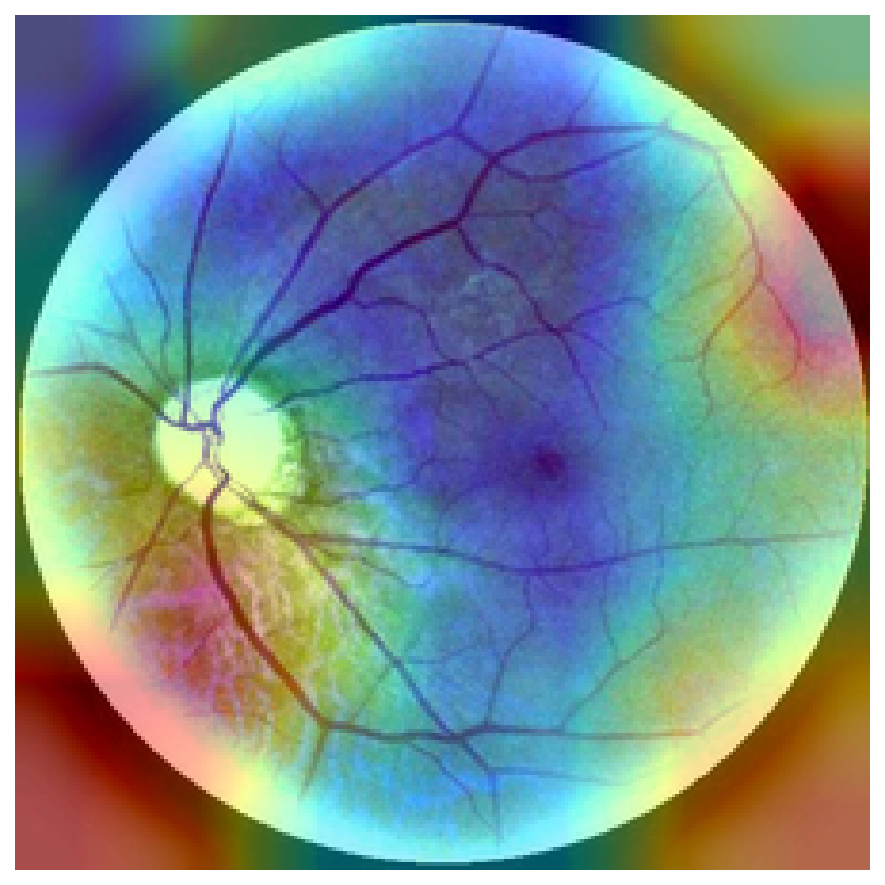

1035_left_gradcam.png


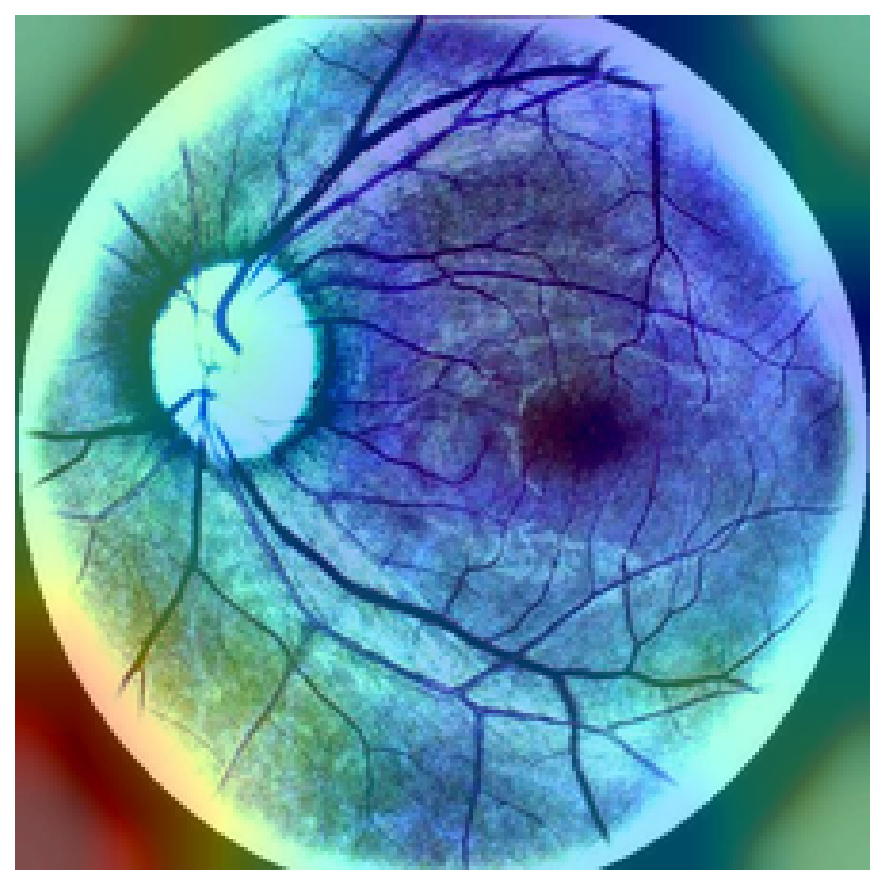

1053_left_gradcam.png


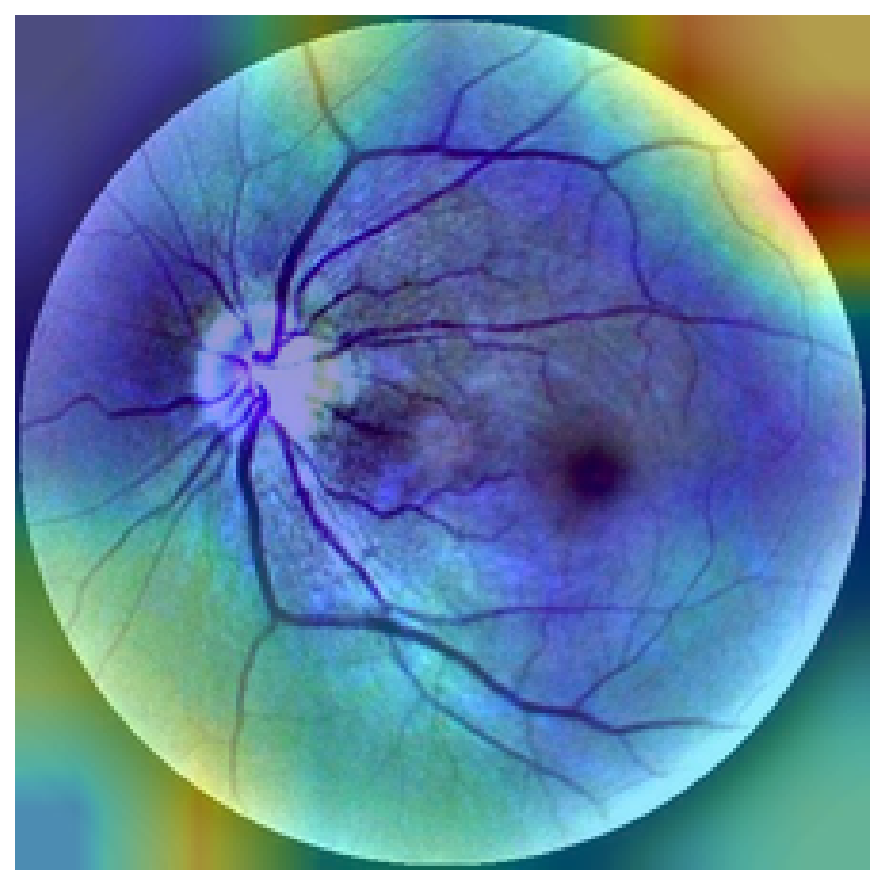

1059_right_gradcam.png


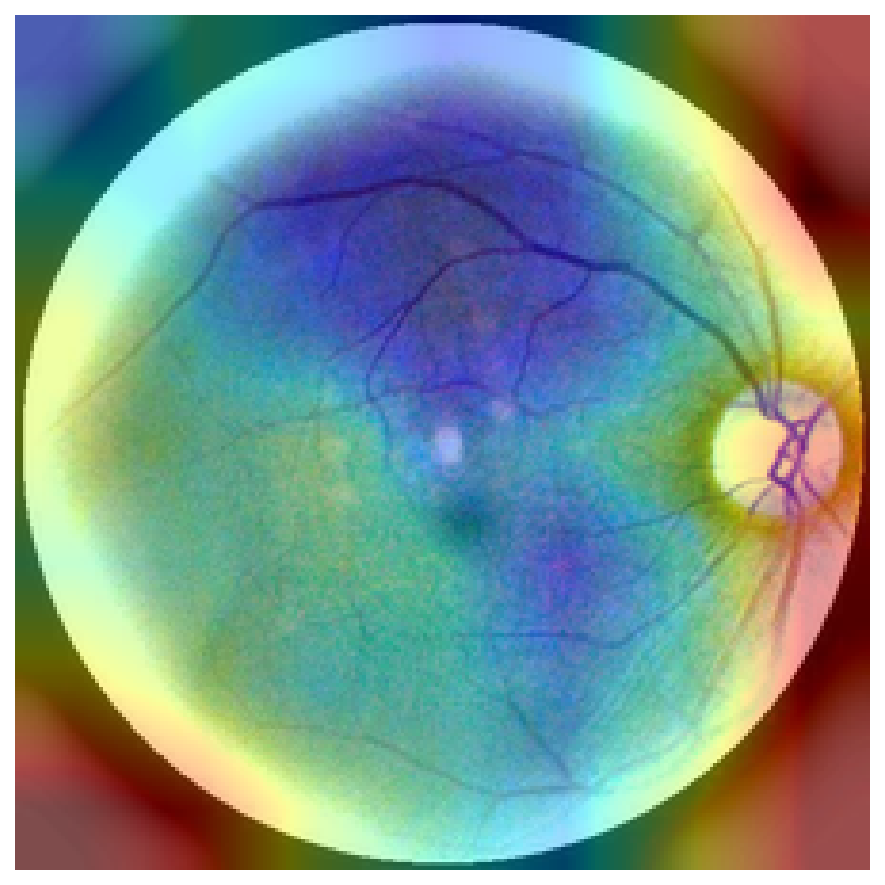

1074_right_gradcam.png


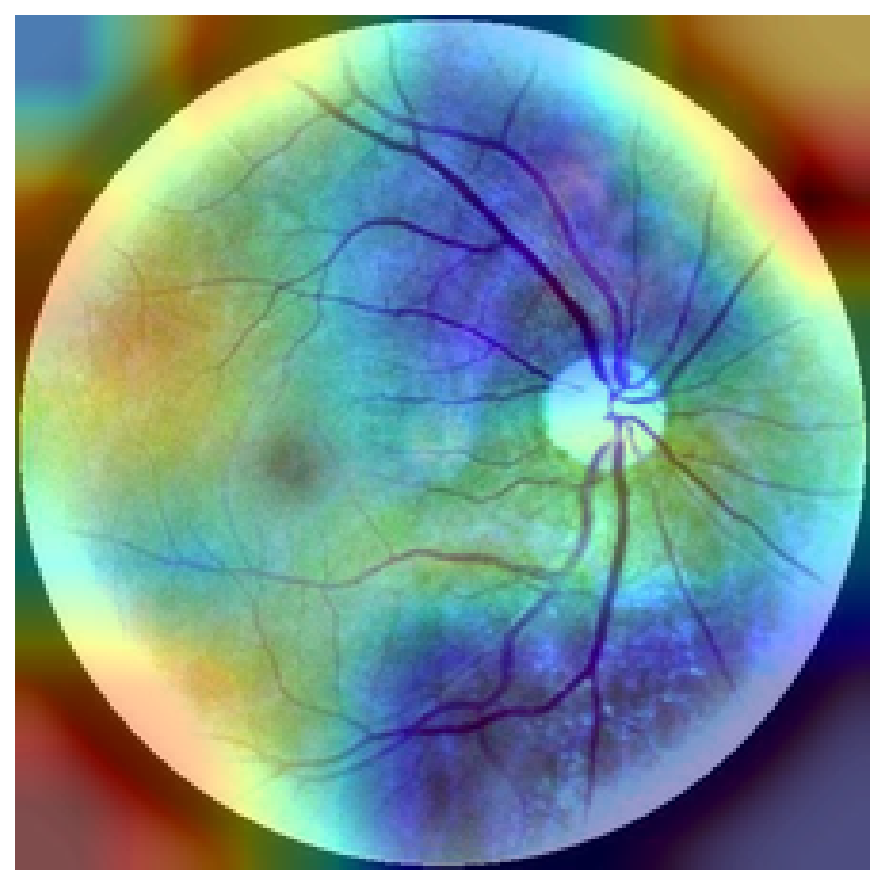

1090_right_gradcam.png


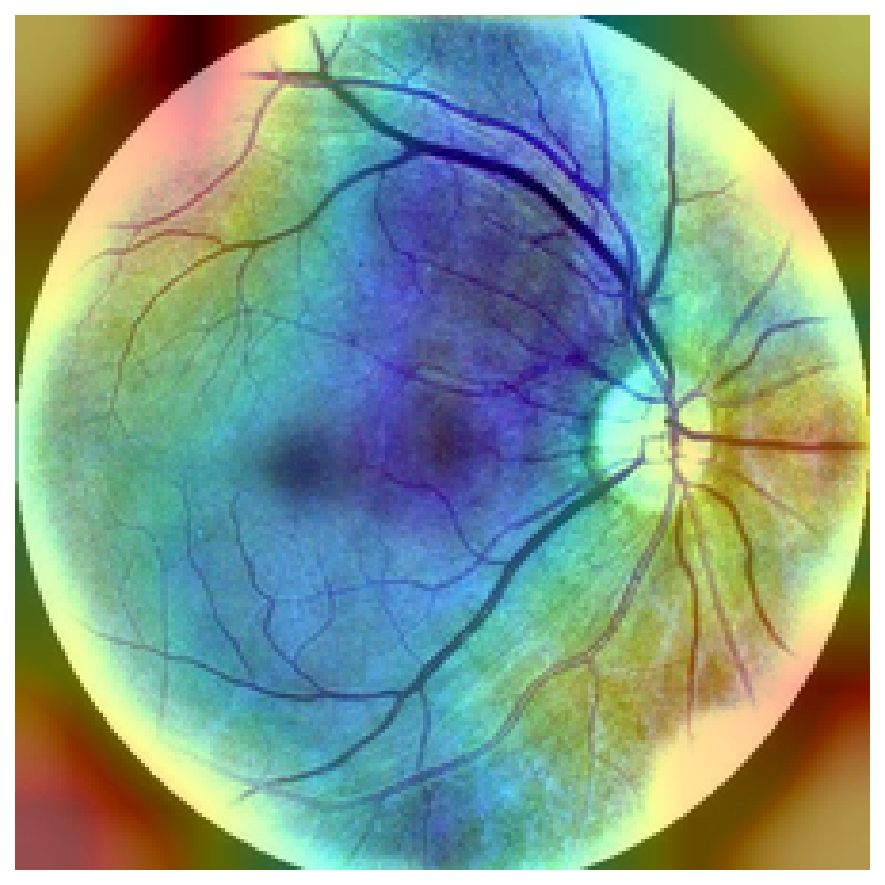

1118_left_gradcam.png


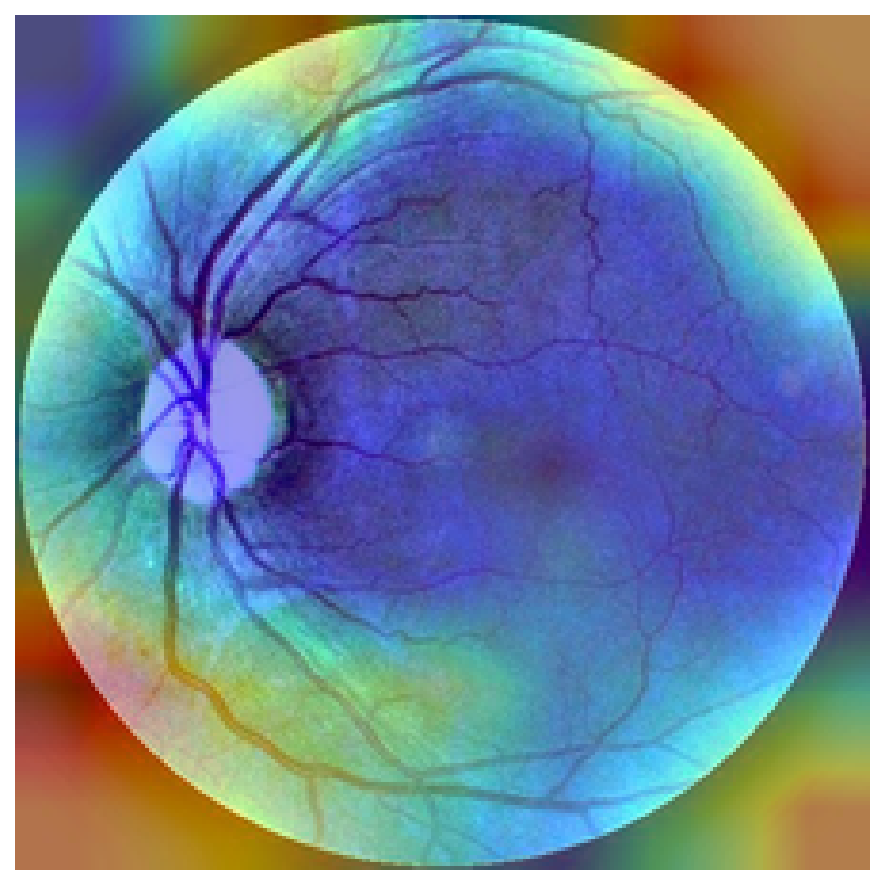

1_gradcam.png


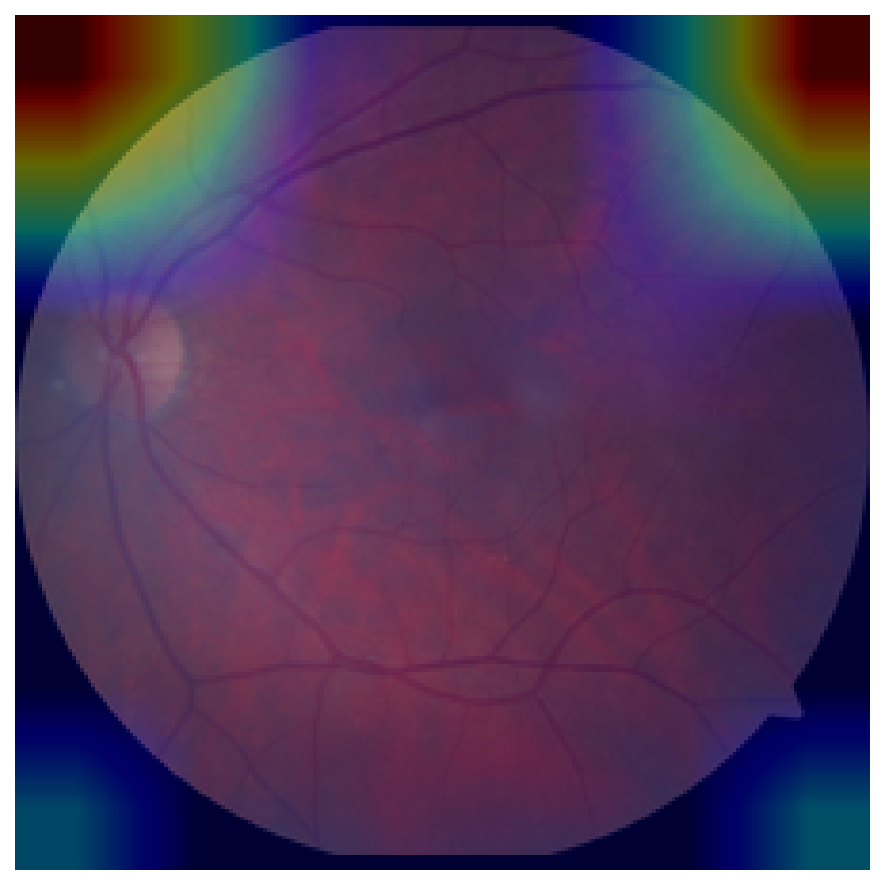

In [ ]:
from pathlib import Path
from IPython.display import display, Image

gradcam_dir = Path(
    "/content/drive/MyDrive/dr_baseline_run2/gradcam"
)

images = sorted(gradcam_dir.glob("*_gradcam.png"))

print("Grad-CAM images found:", len(images))

for path in images:
    print(path.name)
    display(Image(filename=str(path), width=350))

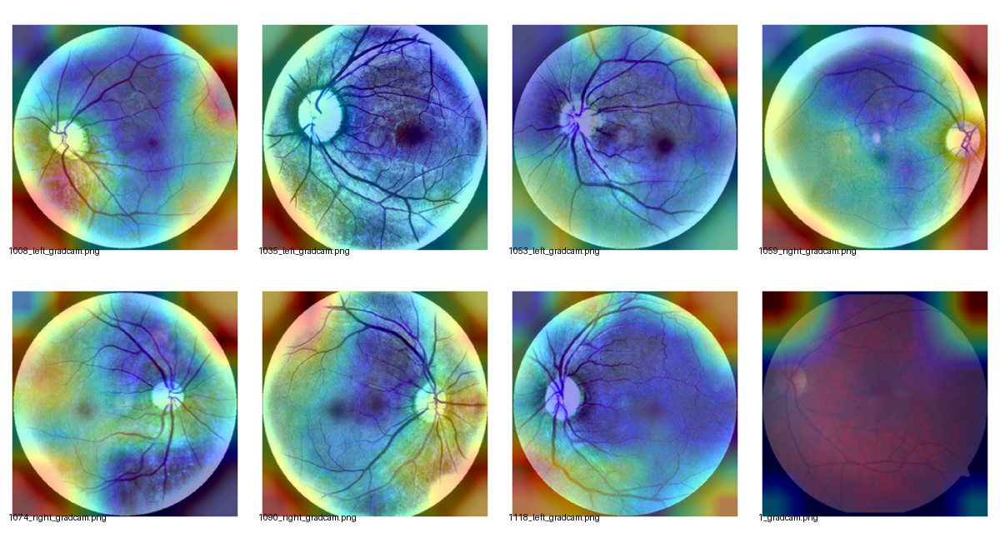

In [ ]:
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display

folder = Path("/content/drive/MyDrive/dr_baseline_run2/gradcam")
files = sorted(folder.glob("*_gradcam.png"))

thumbs = []
for path in files:
    img = Image.open(path).convert("RGB")
    img.thumbnail((280, 280))

    card = Image.new("RGB", (300, 320), "white")
    card.paste(img, ((300 - img.width) // 2, 25))
    ImageDraw.Draw(card).text((10, 295), path.name, fill="black")
    thumbs.append(card)

grid = Image.new("RGB", (1200, 640), "#dddddd")

for i, img in enumerate(thumbs):
    grid.paste(img, ((i % 4) * 300, (i // 4) * 320))

display(grid)

In [ ]:
import json
from pathlib import Path

manifest = Path(
    "/content/drive/MyDrive/dr_baseline_run2/gradcam/gradcam_manifest.json"
)

records = json.loads(manifest.read_text())

for r in records:
    if r["image_path"] == "11.Normal Fundus/1.jpg":
        print(json.dumps(r, indent=2))

{
  "image_path": "11.Normal Fundus/1.jpg",
  "true_class": "No apparent DR",
  "predicted_class": "Severe NPDR",
  "confidence": 0.5518203377723694,
  "note": "Grad-CAM is a model attention visualization, not a clinical explanation."
}


In [ ]:
%cd /content/major-project-dr

from pathlib import Path

script = Path("colab/inspect_prediction.py")
assert not script.exists(), "Script already exists; stopping to avoid overwriting it."

script.write_text(r'''
import argparse
import sys
import csv
from pathlib import Path

import torch
import numpy as np

from colab_helpers import (
    BAND_ORDER, build_frozen_resnet50, default_normalize,
    load_rgb, preprocessing_inference
)
from train import _torch_load

parser = argparse.ArgumentParser()
parser.add_argument("--dataset-root", required=True)
parser.add_argument("--checkpoint-dir", required=True)
parser.add_argument("--split-csv", default="provisional_primary_split/provisional_primary_split.csv")
parser.add_argument("--image-path", default="11.Normal Fundus/1.jpg")
args = parser.parse_args()

project = Path(__file__).resolve().parent.parent
root = Path(args.dataset_root)
split_path = project / args.split_csv

with split_path.open(newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

row = next((r for r in rows if r["image_path"] == args.image_path and r["partition"] == "test"), None)
if row is None:
    raise RuntimeError("Image not found in the existing test split: " + args.image_path)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = build_frozen_resnet50(num_classes=len(BAND_ORDER), pretrained=False)
payload, _ = _torch_load(Path(args.checkpoint_dir) / "model.pt", device)
model.load_state_dict(payload["model_state_dict"], strict=True)
model.to(device).eval()

img = load_rgb(root / row["image_path"])
processed = preprocessing_inference(224)(img)
array = np.asarray(processed).astype(np.float32) / 255.0
tensor = torch.from_numpy(array).permute(2, 0, 1)

mean, std = default_normalize()
mean = torch.tensor(mean, dtype=tensor.dtype)[:, None, None]
std = torch.tensor(std, dtype=tensor.dtype)[:, None, None]
tensor = ((tensor - mean) / std).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(tensor)
    probs = torch.softmax(logits, dim=1)[0].cpu().tolist()

print("Image:", row["image_path"])
print("True class:", row["primary_class"])
print("Class probabilities:")
for name, probability in zip(BAND_ORDER, probs):
    print(f"  {name}: {probability:.4%}")
print("Predicted class:", BAND_ORDER[int(np.argmax(probs))])
''', encoding="utf-8")

print("Created:", script)

/content/major-project-dr
Created: colab/inspect_prediction.py


In [ ]:
%cd /content/major-project-dr

!PYTHONPATH=/content/major-project-dr:$PYTHONPATH python colab/inspect_prediction.py \
  --dataset-root "/content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I" \
  --checkpoint-dir "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint" \
  --split-csv "provisional_primary_split/provisional_primary_split.csv"

/content/major-project-dr
Image: 11.Normal Fundus/1.jpg
True class: No apparent DR
Class probabilities:
  No apparent DR: 12.0318%
  Mild NPDR: 2.3669%
  Moderate NPDR: 5.4078%
  Severe NPDR: 55.1820%
  PDR: 25.0114%
Predicted class: Severe NPDR


In [ ]:
from pathlib import Path

root = Path(
    "/content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I"
)

for path in sorted(root.rglob("*")):
    if path.is_file() and path.suffix.lower() in {
        ".csv", ".json", ".xml", ".txt", ".mat", ".xlsx"
    }:
        print(path.relative_to(root))

In [ ]:
from pathlib import Path

root = Path(
    "/content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I"
)

extensions = {".csv", ".json", ".xml", ".txt", ".mat", ".xlsx"}

files = [
    p for p in root.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("Annotation-like files found:", len(files))

for p in files[:100]:
    print(p.relative_to(root))

Annotation-like files found: 0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

folder = "/content/drive/MyDrive/DR_Dataset"
print(os.listdir(folder))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['Diabetic Retinopathy and Retinal Diseases Fundus I.zip', 'extracted', 'A. Segmentation.zip']


In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/DR_Dataset/A. Segmentation.zip"

print("File exists:", os.path.exists(zip_path))
print("File size (MB):", round(os.path.getsize(zip_path) / (1024**2), 2))

with zipfile.ZipFile(zip_path, "r") as z:
    print("\nFirst 20 files inside the ZIP:")
    for name in z.namelist()[:20]:
        print(name)

File exists: True
File size (MB): 557.25

First 20 files inside the ZIP:
A. Segmentation/
A. Segmentation/1. Original Images/
A. Segmentation/1. Original Images/a. Training Set/
A. Segmentation/1. Original Images/a. Training Set/IDRiD_01.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_02.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_03.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_04.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_05.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_06.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_07.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_08.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_09.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_10.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_11.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_12.jpg
A. Segmentation/1. Original Images/a. Training Set/IDR

In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/DR_Dataset/A. Segmentation.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    for name in z.namelist():
        if any(word in name.lower() for word in [
            "ground truth", "mask", "ma", "he", "ex", "se"
        ]):
            print(name)

A. Segmentation/
A. Segmentation/1. Original Images/
A. Segmentation/1. Original Images/a. Training Set/
A. Segmentation/1. Original Images/a. Training Set/IDRiD_01.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_02.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_03.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_04.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_05.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_06.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_07.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_08.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_09.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_10.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_11.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_12.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_13.jpg
A. Segmentation/1. Original Images/a. Training Set/IDRiD_14.jpg

In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/DR_Dataset/A. Segmentation.zip"
extract_dir = "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Extraction complete!")
print("Dataset location:", extract_dir)
print("Top-level contents:", os.listdir(extract_dir))

Extraction complete!
Dataset location: /content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation
Top-level contents: ['A. Segmentation']


In [ ]:
import os

root = (
    "/content/drive/MyDrive/DR_Dataset/"
    "IDRiD_Segmentation/A. Segmentation"
)

for folder, dirs, files in os.walk(root):
    relevant = [
        f for f in files
        if f.lower().endswith((".jpg", ".tif", ".tiff"))
    ]

    if relevant:
        print(f"\nFolder: {os.path.relpath(folder, root)}")
        print("Image/mask files:", len(relevant))
        print("Examples:", relevant[:3])


Folder: 1. Original Images/a. Training Set
Image/mask files: 54
Examples: ['IDRiD_01.jpg', 'IDRiD_02.jpg', 'IDRiD_03.jpg']

Folder: 1. Original Images/b. Testing Set
Image/mask files: 27
Examples: ['IDRiD_55.jpg', 'IDRiD_56.jpg', 'IDRiD_57.jpg']

Folder: 2. All Segmentation Groundtruths/a. Training Set/1. Microaneurysms
Image/mask files: 54
Examples: ['IDRiD_01_MA.tif', 'IDRiD_02_MA.tif', 'IDRiD_03_MA.tif']

Folder: 2. All Segmentation Groundtruths/a. Training Set/2. Haemorrhages
Image/mask files: 53
Examples: ['IDRiD_01_HE.tif', 'IDRiD_02_HE.tif', 'IDRiD_03_HE.tif']

Folder: 2. All Segmentation Groundtruths/a. Training Set/3. Hard Exudates
Image/mask files: 54
Examples: ['IDRiD_01_EX.tif', 'IDRiD_02_EX.tif', 'IDRiD_03_EX.tif']

Folder: 2. All Segmentation Groundtruths/a. Training Set/4. Soft Exudates
Image/mask files: 26
Examples: ['IDRiD_03_SE.tif', 'IDRiD_08_SE.tif', 'IDRiD_13_SE.tif']

Folder: 2. All Segmentation Groundtruths/a. Training Set/5. Optic Disc
Image/mask files: 54
Exam

In [ ]:
from PIL import Image
import os

root = "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation"

image_path = os.path.join(
    root, "1. Original Images/a. Training Set/IDRiD_01.jpg"
)

mask_path = os.path.join(
    root,
    "2. All Segmentation Groundtruths/a. Training Set/1. Microaneurysms/IDRiD_01_MA.tif"
)

with Image.open(image_path) as img:
    print("Original image size:", img.size)
    print("Original image mode:", img.mode)

with Image.open(mask_path) as mask:
    print("MA mask size:", mask.size)
    print("MA mask mode:", mask.mode)
    print("Mask pixel values:", sorted(set(mask.getdata()))[:20])

Original image size: (4288, 2848)
Original image mode: RGB
MA mask size: (4288, 2848)
MA mask mode: P
Mask pixel values: [0, 1]


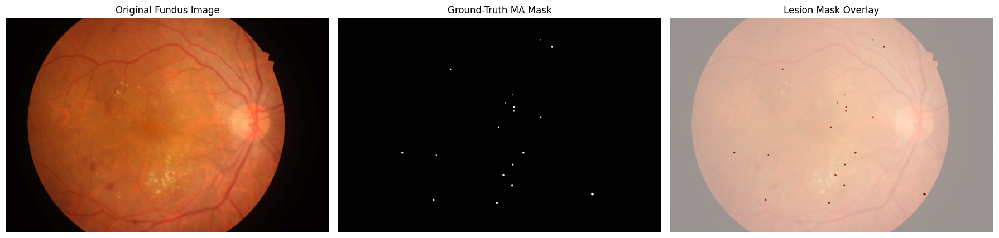

Lesion pixels: 6941
Total pixels: 12212224
Lesion pixel percentage: 0.056836 %


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

root = "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation"

image_path = os.path.join(
    root, "1. Original Images/a. Training Set/IDRiD_01.jpg"
)

mask_path = os.path.join(
    root,
    "2. All Segmentation Groundtruths/a. Training Set/1. Microaneurysms/IDRiD_01_MA.tif"
)

image = np.array(Image.open(image_path).convert("RGB"))
mask = np.array(Image.open(mask_path))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(image)
axes[0].set_title("Original Fundus Image")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground-Truth MA Mask")

axes[2].imshow(image)
axes[2].imshow(mask, cmap="Reds", alpha=0.6, vmin=0, vmax=1)
axes[2].set_title("Lesion Mask Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Lesion pixels:", int(mask.sum()))
print("Total pixels:", mask.size)
print("Lesion pixel percentage:", round(100 * mask.mean(), 6), "%")

In [ ]:
import os
from PIL import Image
import numpy as np

root = "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation"

lesions = {
    "MA": "1. Microaneurysms",
    "HE": "2. Haemorrhages",
    "EX": "3. Hard Exudates",
    "SE": "4. Soft Exudates",
}

for code, folder in lesions.items():
    mask_dir = os.path.join(
        root, "2. All Segmentation Groundtruths",
        "a. Training Set", folder
    )

    files = sorted(
        f for f in os.listdir(mask_dir)
        if f.lower().endswith(".tif")
    )

    total_pixels = 0
    total_positive = 0

    for file in files:
        with Image.open(os.path.join(mask_dir, file)) as img:
            mask = np.array(img)
        total_pixels += mask.size
        total_positive += int((mask > 0).sum())

    percentage = 100 * total_positive / total_pixels if total_pixels else 0

    print(
        f"{code}: {len(files)} masks | "
        f"positive pixels: {total_positive:,} | "
        f"positive pixel percentage: {percentage:.6f}%"
    )

MA: 54 masks | positive pixels: 704,963 | positive pixel percentage: 0.106900%
HE: 53 masks | positive pixels: 6,500,485 | positive pixel percentage: 1.004327%
EX: 54 masks | positive pixels: 5,319,524 | positive pixel percentage: 0.806648%
SE: 26 masks | positive pixels: 1,249,041 | positive pixel percentage: 0.393377%


In [ ]:
import os

root = "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation"

original_dir = os.path.join(
    root, "1. Original Images", "a. Training Set"
)

groundtruth_dir = os.path.join(
    root, "2. All Segmentation Groundtruths", "a. Training Set"
)

lesion_folders = {
    "MA": "1. Microaneurysms",
    "HE": "2. Haemorrhages",
    "EX": "3. Hard Exudates",
    "SE": "4. Soft Exudates",
}

image_ids = {
    os.path.splitext(f)[0]
    for f in os.listdir(original_dir)
    if f.lower().endswith(".jpg")
}

print("Training images:", len(image_ids))

for code, folder in lesion_folders.items():
    mask_dir = os.path.join(groundtruth_dir, folder)

    mask_ids = {
        f.replace(f"_{code}.tif", "")
        for f in os.listdir(mask_dir)
        if f.endswith(f"_{code}.tif")
    }

    missing = sorted(image_ids - mask_ids)

    print(f"\n{code}:")
    print("Available masks:", len(mask_ids))
    print("Missing annotations:", missing)

Training images: 54

MA:
Available masks: 54
Missing annotations: []

HE:
Available masks: 53
Missing annotations: ['IDRiD_43']

EX:
Available masks: 54
Missing annotations: []

SE:
Available masks: 26
Missing annotations: ['IDRiD_01', 'IDRiD_02', 'IDRiD_04', 'IDRiD_05', 'IDRiD_06', 'IDRiD_07', 'IDRiD_09', 'IDRiD_10', 'IDRiD_11', 'IDRiD_12', 'IDRiD_15', 'IDRiD_16', 'IDRiD_20', 'IDRiD_21', 'IDRiD_24', 'IDRiD_26', 'IDRiD_27', 'IDRiD_28', 'IDRiD_29', 'IDRiD_34', 'IDRiD_36', 'IDRiD_37', 'IDRiD_40', 'IDRiD_41', 'IDRiD_42', 'IDRiD_43', 'IDRiD_44', 'IDRiD_45']


In [ ]:
import os

root = "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation"

test_images_dir = os.path.join(
    root, "1. Original Images", "b. Testing Set"
)

test_masks_dir = os.path.join(
    root, "2. All Segmentation Groundtruths", "b. Testing Set"
)

lesions = {
    "MA": "1. Microaneurysms",
    "HE": "2. Haemorrhages",
    "EX": "3. Hard Exudates",
    "SE": "4. Soft Exudates",
}

test_ids = {
    os.path.splitext(f)[0]
    for f in os.listdir(test_images_dir)
    if f.lower().endswith(".jpg")
}

print("Official testing images:", len(test_ids))

for code, folder in lesions.items():
    mask_dir = os.path.join(test_masks_dir, folder)

    mask_ids = {
        f.replace(f"_{code}.tif", "")
        for f in os.listdir(mask_dir)
        if f.endswith(f"_{code}.tif")
    }

    print(f"{code}: {len(mask_ids)} masks")
    print("Missing:", sorted(test_ids - mask_ids))

Official testing images: 27
MA: 27 masks
Missing: []
HE: 27 masks
Missing: []
EX: 27 masks
Missing: []
SE: 14 masks
Missing: ['IDRiD_57', 'IDRiD_58', 'IDRiD_62', 'IDRiD_63', 'IDRiD_65', 'IDRiD_66', 'IDRiD_69', 'IDRiD_76', 'IDRiD_77', 'IDRiD_78', 'IDRiD_79', 'IDRiD_80', 'IDRiD_81']


In [ ]:
%cd /content/major-project-dr

!find . -maxdepth 3 -type f \
  \( -name "*.py" -o -name "requirements.txt" \) \
  | sort

/content/major-project-dr
./audit_output/analyze.py
./audit_output/pretraining_audit/build_provisional_manifests.py
./audit_output/pretraining_audit/build_registers.py
./audit_output/pretraining_audit/recon2.py
./audit_output/pretraining_audit/reconcile.py
./audit_output/scan_images.py
./audit_output/v03_compare.py
./audit_output/v03_final_quantify.py
./audit_output/v03_internal.py
./audit_output/v03_perceptual.py
./audit_output/v03_pixel_verify.py
./colab/colab_helpers.py
./colab/cpu_train.py
./colab/gradcam_visualize.py
./colab/inspect_prediction.py
./colab/kaggle_notebook_docs/01_preflight.py
./colab/kaggle_notebook_docs/02_helpers.py
./colab/kaggle_notebook_docs/03_setup.py
./colab/kaggle_notebook_docs/04_engine.py
./colab/kaggle_notebook_docs/05_smoke.py
./colab/kaggle_notebook_docs/06_labels.py
./colab/kaggle_notebook_docs/07_decoding.py
./colab/kaggle_notebook_docs/08_dataset_init.py
./colab/kaggle_notebook_docs/09_split_valid.py
./colab/kaggle_notebook_docs/copy_notebook_code.p

In [ ]:
%cd /content/major-project-dr

!cat requirements.txt

/content/major-project-dr
 
 
 
 
 
 
 
 
 
 
 
 
 
 o p e n p y x l = = 3 . 1 . 5 

In [ ]:
%cd /content/major-project-dr

!find . -maxdepth 3 -type f \
  \( -name "*.py" -o -name "*.yaml" -o -name "*.yml" -o -name "*.toml" \) \
  | grep -vE 'audit_output|kaggle_notebook_docs|tests' \
  | sort

/content/major-project-dr
./colab/colab_helpers.py
./colab/cpu_train.py
./colab/gradcam_visualize.py
./colab/inspect_prediction.py
./colab/pipeline.py
./colab/setup_helpers.py
./colab/smoke_test.py
./colab/train.py
./dataset/decoding.py
./dataset/eligibility.py
./dataset/grouping.py
./dataset/__init__.py
./dataset/labels.py
./dataset/manifest.py
./dataset/split_protocol.py
./dataset/split_validation.py
./dataset/statistics.py
./verify_final_deliverable.py


In [ ]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA available: True
GPU: NVIDIA A100-SXM4-40GB


In [ ]:
%cd /content/major-project-dr

!grep -R -n -E \
"class .*Model|resnet50|class .*Dataset|def build_model" \
colab dataset \
--include="*.py" \
--exclude-dir="kaggle_notebook_docs"

/content/major-project-dr
colab/colab_helpers.py:243:RESNET50_IMAGENET1K_V1_FILENAME = "resnet50-0676ba61.pth"
colab/colab_helpers.py:275:        return any(exact.parent.glob("resnet50-*.pth"))
colab/colab_helpers.py:280:def build_frozen_resnet50(
colab/colab_helpers.py:319:    model = models.resnet50(weights=weights)
colab/inspect_prediction.py:11:    BAND_ORDER, build_frozen_resnet50, default_normalize,
colab/inspect_prediction.py:35:model = build_frozen_resnet50(num_classes=len(BAND_ORDER), pretrained=False)
colab/smoke_test.py:298:        "model": "resnet50_frozen",
colab/setup_helpers.py:937:    from torchvision.models import resnet50
colab/setup_helpers.py:938:    net = resnet50(weights=None)
colab/gradcam_visualize.py:15:    build_frozen_resnet50,
colab/gradcam_visualize.py:52:    model = build_frozen_resnet50(num_classes=len(BAND_ORDER), pretrained=False)
colab/cpu_train.py:193:                 f"NOT cached at {cache}; download of one ImageNet resnet50 .pth "
colab/train.py:72:

In [ ]:
import torch
import os

print("GPU:", torch.cuda.get_device_name(0))
print("Total GPU memory:", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
), "GB")

print("\nIDRiD dataset exists:",
      os.path.isdir(
          "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation"
      ))

print("Existing grading checkpoint exists:",
      os.path.isfile(
          "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt"
      ))

GPU: NVIDIA A100-SXM4-40GB
Total GPU memory: 39.49 GB

IDRiD dataset exists: True
Existing grading checkpoint exists: True


In [ ]:
import os

project = "/content/major-project-dr"

folders = [
    "lesion_segmentation",
    "lesion_segmentation/checkpoints",
    "lesion_segmentation/outputs",
    "lesion_segmentation/scripts",
]

for folder in folders:
    path = os.path.join(project, folder)
    os.makedirs(path, exist_ok=True)
    print("Ready:", path)

Ready: /content/major-project-dr/lesion_segmentation
Ready: /content/major-project-dr/lesion_segmentation/checkpoints
Ready: /content/major-project-dr/lesion_segmentation/outputs
Ready: /content/major-project-dr/lesion_segmentation/scripts


In [ ]:
%%writefile /content/major-project-dr/lesion_segmentation/dataset_loader.py

from pathlib import Path
from PIL import Image
import numpy as np
import torch
from torch.utils.data import Dataset

LESIONS = {
    "MA": "1. Microaneurysms",
    "HE": "2. Haemorrhages",
    "EX": "3. Hard Exudates",
    "SE": "4. Soft Exudates",
}


class IDRiDLesionDataset(Dataset):
    def __init__(self, root, split="a. Training Set", lesion="MA"):
        self.root = Path(root)
        self.split = split
        self.lesion = lesion.upper()

        if self.lesion not in LESIONS:
            raise ValueError(f"Unknown lesion: {lesion}")

        self.image_dir = (
            self.root / "1. Original Images" / split
        )
        self.mask_dir = (
            self.root / "2. All Segmentation Groundtruths"
            / split / LESIONS[self.lesion]
        )

        self.samples = []

        for image_path in sorted(self.image_dir.glob("*.jpg")):
            image_id = image_path.stem
            mask_path = self.mask_dir / f"{image_id}_{self.lesion}.tif"

            # Missing annotations are excluded, never treated as empty masks.
            if mask_path.exists():
                self.samples.append((image_path, mask_path))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, mask_path = self.samples[index]

        with Image.open(image_path) as im:
            image = np.array(im.convert("RGB"))

        with Image.open(mask_path) as im:
            mask = np.array(im)

        if image.shape[:2] != mask.shape[:2]:
            raise ValueError(f"Image-mask size mismatch: {image_path.name}")

        image = torch.from_numpy(image.copy()).permute(2, 0, 1).float() / 255.0
        mask = torch.from_numpy((mask > 0).astype(np.float32)).unsqueeze(0)

        return {
            "image": image,
            "mask": mask,
            "image_id": image_path.stem,
        }

Writing /content/major-project-dr/lesion_segmentation/dataset_loader.py


In [ ]:
import sys
import torch

sys.path.insert(0, "/content/major-project-dr")

from lesion_segmentation.dataset_loader import IDRiDLesionDataset

root = (
    "/content/drive/MyDrive/DR_Dataset/"
    "IDRiD_Segmentation/A. Segmentation"
)

dataset = IDRiDLesionDataset(
    root=root,
    split="a. Training Set",
    lesion="MA",
)

print("Dataset size:", len(dataset))

sample = dataset[0]

print("Image ID:", sample["image_id"])
print("Image shape:", tuple(sample["image"].shape))
print("Mask shape:", tuple(sample["mask"].shape))
print("Mask values:", torch.unique(sample["mask"]).tolist())

Dataset size: 54
Image ID: IDRiD_01
Image shape: (3, 2848, 4288)
Mask shape: (1, 2848, 4288)
Mask values: [0.0, 1.0]


In [ ]:
import torch.nn.functional as F
import sys

sys.path.insert(0, "/content/major-project-dr")
from lesion_segmentation.dataset_loader import IDRiDLesionDataset

root = (
    "/content/drive/MyDrive/DR_Dataset/"
    "IDRiD_Segmentation/A. Segmentation"
)

dataset = IDRiDLesionDataset(root=root, split="a. Training Set", lesion="MA")
sample = dataset[0]

image = sample["image"].unsqueeze(0)
mask = sample["mask"].unsqueeze(0)

image_small = F.interpolate(
    image, size=(512, 512), mode="bilinear", align_corners=False
)

mask_small = F.interpolate(
    mask, size=(512, 512), mode="nearest"
)

print("Resized image:", tuple(image_small.shape))
print("Resized mask:", tuple(mask_small.shape))
print("Mask values:", torch.unique(mask_small).tolist())
print("Image values:", image_small.min().item(), image_small.max().item())

Resized image: (1, 3, 512, 512)
Resized mask: (1, 1, 512, 512)
Mask values: [0.0, 1.0]
Image values: 0.0 1.0


In [ ]:
print("Original mask pixels:", int(mask.sum().item()))
print("Resized mask pixels:", int(mask_small.sum().item()))

if mask_small.sum().item() == 0:
    print("⚠️ All lesion pixels disappeared after resizing.")
else:
    print("✅ Some lesion pixels survived resizing.")

Original mask pixels: 6941
Resized mask pixels: 154
✅ Some lesion pixels survived resizing.


In [ ]:
import torch.nn.functional as F

for size in [512, 768, 1024]:
    resized_mask = F.interpolate(
        mask,
        size=(size, size),
        mode="nearest"
    )

    print(
        f"{size} × {size}: "
        f"{int(resized_mask.sum().item())} lesion pixels"
    )

512 × 512: 154 lesion pixels
768 × 768: 343 lesion pixels
1024 × 1024: 609 lesion pixels


In [ ]:
import torch

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("GPU not available")

GPU: NVIDIA A100-SXM4-40GB
GPU memory: 39.49 GB


In [ ]:
import torch
import torchvision
import importlib.util

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
print("timm installed:", importlib.util.find_spec("timm") is not None)
print(
    "segmentation_models_pytorch installed:",
    importlib.util.find_spec("segmentation_models_pytorch") is not None
)

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA available: True
timm installed: True
segmentation_models_pytorch installed: False


In [ ]:
%pip install -q segmentation-models-pytorch

In [ ]:
import segmentation_models_pytorch as smp

print("Segmentation library:", smp.__version__)
print("U-Net available:", hasattr(smp, "Unet"))

Segmentation library: 0.6.0
U-Net available: True


In [ ]:
from pathlib import Path

script = Path(
    "/content/major-project-dr/lesion_segmentation/train_ma.py"
)
print("Training script exists:", script.exists())
print("Script size:", script.stat().st_size if script.exists() else 0)

Training script exists: False
Script size: 0


In [ ]:
from pathlib import Path

project = Path("/content/major-project-dr")

print("Project folder exists:", project.exists())
print("Lesion folder exists:", (project / "lesion_segmentation").exists())

if (project / "lesion_segmentation").exists():
    print("Files:", [
        p.name for p in (project / "lesion_segmentation").iterdir()
    ])

Project folder exists: True
Lesion folder exists: True
Files: ['dataset_loader.py', 'outputs', 'scripts', '__pycache__', 'checkpoints']


In [ ]:
from pathlib import Path

script_path = Path(
    "/content/major-project-dr/lesion_segmentation/train_ma.py"
)

script_code = r'''
print("MA lesion segmentation training script initialized.")
'''

script_path.write_text(script_code, encoding="utf-8")

print("Created:", script_path)
print("File exists:", script_path.exists())
print("File size:", script_path.stat().st_size, "bytes")

Created: /content/major-project-dr/lesion_segmentation/train_ma.py
File exists: True
File size: 62 bytes


In [ ]:
from pathlib import Path
import segmentation_models_pytorch as smp
import sys

sys.path.insert(0, "/content/major-project-dr")

from lesion_segmentation.dataset_loader import IDRiDLesionDataset

root = (
    "/content/drive/MyDrive/DR_Dataset/"
    "IDRiD_Segmentation/A. Segmentation"
)

dataset = IDRiDLesionDataset(
    root=root,
    split="a. Training Set",
    lesion="MA"
)

print("Dataset images:", len(dataset))
print("U-Net available:", hasattr(smp, "Unet"))
print("Training script exists:", Path(
    "/content/major-project-dr/lesion_segmentation/train_ma.py"
).exists())

Dataset images: 54
U-Net available: True
Training script exists: True


In [ ]:
from pathlib import Path
import ast

p = Path(
    "/content/major-project-dr/lesion_segmentation/train_ma.py"
)

ast.parse(p.read_text(encoding="utf-8"))

print("Script exists:", p.exists())
print("Syntax check: PASSED")
print("Size:", p.stat().st_size, "bytes")

Script exists: True
Syntax check: PASSED
Size: 62 bytes


In [ ]:

from pathlib import Path

script_path = Path(
    "/content/major-project-dr/lesion_segmentation/train_ma.py"
)

code = r'''
from pathlib import Path
import random
import sys
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp

sys.path.insert(0, "/content/major-project-dr")
from lesion_segmentation.dataset_loader import IDRiDLesionDataset

SEED = 42
SIZE = 1024
BATCH_SIZE = 2
EPOCHS = 30
LR = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

ROOT = Path(
    "/content/drive/MyDrive/DR_Dataset/"
    "IDRiD_Segmentation/A. Segmentation"
)
OUT = Path("/content/major-project-dr/lesion_segmentation")
CKPT_DIR = OUT / "checkpoints"
CKPT_DIR.mkdir(parents=True, exist_ok=True)


class ResizeDataset(Dataset):
    def __init__(self, base, indices, augment=False):
        self.base = base
        self.indices = list(indices)
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        sample = self.base[self.indices[idx]]
        image, mask = sample["image"], sample["mask"]

        image = F.interpolate(
            image.unsqueeze(0), size=(SIZE, SIZE),
            mode="bilinear", align_corners=False
        ).squeeze(0)

        mask = F.interpolate(
            mask.unsqueeze(0), size=(SIZE, SIZE),
            mode="nearest"
        ).squeeze(0)

        if self.augment and random.random() < 0.5:
            image = image.flip(-1)
            mask = mask.flip(-1)

        if self.augment and random.random() < 0.5:
            image = image.flip(-2)
            mask = mask.flip(-2)

        return image, mask


def loss_fn(logits, targets):
    bce = F.binary_cross_entropy_with_logits(logits, targets)
    probs = torch.sigmoid(logits)
    dims = (1, 2, 3)
    intersection = (probs * targets).sum(dims)
    denominator = probs.sum(dims) + targets.sum(dims)
    dice = (2 * intersection + 1e-6) / (denominator + 1e-6)
    return bce + (1 - dice).mean()


def calculate_metrics(logits, targets):
    predictions = torch.sigmoid(logits) >= 0.5
    targets = targets >= 0.5
    dims = (1, 2, 3)

    tp = (predictions & targets).sum(dims).float()
    fp = (predictions & ~targets).sum(dims).float()
    fn = (~predictions & targets).sum(dims).float()

    dice = (2 * tp + 1e-6) / (2 * tp + fp + fn + 1e-6)
    iou = (tp + 1e-6) / (tp + fp + fn + 1e-6)
    return dice.mean().item(), iou.mean().item()


def main():
    if DEVICE != "cuda":
        raise RuntimeError("Enable GPU in Runtime > Change runtime type.")

    base = IDRiDLesionDataset(
        root=str(ROOT),
        split="a. Training Set",
        lesion="MA"
    )

    # Deterministic split of annotated training images only.
    ids = list(range(len(base)))
    random.Random(SEED).shuffle(ids)
    n_val = max(1, round(0.2 * len(ids)))
    val_ids, train_ids = ids[:n_val], ids[n_val:]

    train_ds = ResizeDataset(base, train_ids, augment=True)
    val_ds = ResizeDataset(base, val_ids)

    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=2, pin_memory=True
    )
    val_loader = DataLoader(
        val_ds, batch_size=1, shuffle=False,
        num_workers=2, pin_memory=True
    )

    model = smp.Unet(
        encoder_name="resnet50",
        encoder_weights="imagenet",
        in_channels=3,
        classes=1
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
    best_dice = -1.0
    best_path = CKPT_DIR / "ma_unet_resnet50_best.pth"

    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Training: {len(train_ds)} | Validation: {len(val_ds)}")
    print(f"Resolution: {SIZE} | Batch size: {BATCH_SIZE}")

    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_losses = []

        for images, masks in train_loader:
            images = images.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = loss_fn(logits, masks)
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses, dices, ious = [], [], []

        with torch.no_grad():
            for images, masks in val_loader:
                images = images.to(DEVICE, non_blocking=True)
                masks = masks.to(DEVICE, non_blocking=True)
                logits = model(images)
                val_losses.append(loss_fn(logits, masks).item())
                dice, iou = calculate_metrics(logits, masks)
                dices.append(dice)
                ious.append(iou)

        val_dice = float(np.mean(dices))
        val_iou = float(np.mean(ious))

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"train_loss={np.mean(train_losses):.4f} | "
            f"val_loss={np.mean(val_losses):.4f} | "
            f"val_Dice={val_dice:.4f} | val_IoU={val_iou:.4f}"
        )

        if val_dice > best_dice:
            best_dice = val_dice
            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_dice": val_dice,
                "val_iou": val_iou,
                "seed": SEED,
                "image_size": SIZE,
                "lesion": "MA",
                "train_image_ids": [
                    base.samples[i][0].stem for i in train_ids
                ],
                "val_image_ids": [
                    base.samples[i][0].stem for i in val_ids
                ],
            }, best_path)
            print(f"Best checkpoint saved: {best_path}")

    print(f"Training complete. Best validation Dice: {best_dice:.4f}")


if __name__ == "__main__":
    main()
'''

script_path.write_text(code.strip() + "\n", encoding="utf-8")

print("Saved:", script_path)
print("Size:", script_path.stat().st_size, "bytes")


Saved: /content/major-project-dr/lesion_segmentation/train_ma.py
Size: 5863 bytes


In [ ]:
from pathlib import Path
import ast

p = Path(
    "/content/major-project-dr/lesion_segmentation/train_ma.py"
)

ast.parse(p.read_text(encoding="utf-8"))

print("Script exists:", p.exists())
print("Syntax check: PASSED")
print("Size:", p.stat().st_size, "bytes")

Script exists: True
Syntax check: PASSED
Size: 5863 bytes


In [ ]:
import sys
import torch
import torch.nn.functional as F
import segmentation_models_pytorch as smp

sys.path.insert(0, "/content/major-project-dr")
from lesion_segmentation.dataset_loader import IDRiDLesionDataset

root = (
    "/content/drive/MyDrive/DR_Dataset/"
    "IDRiD_Segmentation/A. Segmentation"
)

dataset = IDRiDLesionDataset(
    root=root,
    split="a. Training Set",
    lesion="MA"
)

sample = dataset[0]

image = F.interpolate(
    sample["image"].unsqueeze(0),
    size=(1024, 1024),
    mode="bilinear",
    align_corners=False
).cuda()

mask = F.interpolate(
    sample["mask"].unsqueeze(0),
    size=(1024, 1024),
    mode="nearest"
).cuda()

model = smp.Unet(
    encoder_name="resnet50",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1
).cuda()

model.eval()

with torch.no_grad():
    logits = model(image)
    loss = F.binary_cross_entropy_with_logits(logits, mask)

print("GPU:", torch.cuda.get_device_name(0))
print("Input shape:", tuple(image.shape))
print("Output shape:", tuple(logits.shape))
print("Loss:", round(loss.item(), 4))
print("GPU smoke test: PASSED")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

GPU: NVIDIA A100-SXM4-40GB
Input shape: (1, 3, 1024, 1024)
Output shape: (1, 1, 1024, 1024)
Loss: 0.7064
GPU smoke test: PASSED


In [ ]:
%cd /content/major-project-dr
!python lesion_segmentation/train_ma.py

/content/major-project-dr
GPU: NVIDIA A100-SXM4-40GB
Training: 43 | Validation: 11
Resolution: 1024 | Batch size: 2
Epoch 01/30 | train_loss=1.7753 | val_loss=1.6838 | val_Dice=0.0021 | val_IoU=0.0011
Best checkpoint saved: /content/major-project-dr/lesion_segmentation/checkpoints/ma_unet_resnet50_best.pth
Epoch 02/30 | train_loss=1.5451 | val_loss=1.5153 | val_Dice=0.0008 | val_IoU=0.0004
Epoch 03/30 | train_loss=1.4564 | val_loss=1.4984 | val_Dice=0.0012 | val_IoU=0.0006
Epoch 04/30 | train_loss=1.4072 | val_loss=1.4181 | val_Dice=0.0008 | val_IoU=0.0004
Epoch 05/30 | train_loss=1.3686 | val_loss=1.3731 | val_Dice=0.0002 | val_IoU=0.0001
Epoch 06/30 | train_loss=1.3394 | val_loss=1.3547 | val_Dice=0.0000 | val_IoU=0.0000
Epoch 07/30 | train_loss=1.3143 | val_loss=1.3265 | val_Dice=0.0001 | val_IoU=0.0001
Epoch 08/30 | train_loss=1.2937 | val_loss=1.3077 | val_Dice=0.0000 | val_IoU=0.0000
Epoch 09/30 | train_loss=1.2750 | val_loss=1.3260 | val_Dice=0.0000 | val_IoU=0.0000
Epoch 10/30 

In [ ]:
import sys
import torch
import torch.nn.functional as F
import segmentation_models_pytorch as smp
from pathlib import Path

sys.path.insert(0, "/content/major-project-dr")
from lesion_segmentation.dataset_loader import IDRiDLesionDataset

root = (
    "/content/drive/MyDrive/DR_Dataset/"
    "IDRiD_Segmentation/A. Segmentation"
)
checkpoint_path = Path(
    "/content/major-project-dr/lesion_segmentation/"
    "checkpoints/ma_unet_resnet50_best.pth"
)

device = "cuda" if torch.cuda.is_available() else "cpu"

dataset = IDRiDLesionDataset(
    root=root,
    split="a. Training Set",
    lesion="MA"
)

# Recreate the same deterministic validation split.
import random
indices = list(range(len(dataset)))
random.Random(42).shuffle(indices)
n_val = max(1, round(0.2 * len(indices)))
val_indices = indices[:n_val]

sample = dataset[val_indices[0]]
image = F.interpolate(
    sample["image"].unsqueeze(0),
    size=(1024, 1024),
    mode="bilinear",
    align_corners=False
).to(device)

mask = F.interpolate(
    sample["mask"].unsqueeze(0),
    size=(1024, 1024),
    mode="nearest"
).to(device)

model = smp.Unet(
    encoder_name="resnet50",
    encoder_weights=None,
    in_channels=3,
    classes=1
).to(device)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

with torch.no_grad():
    probabilities = torch.sigmoid(model(image))

print("Image ID:", sample["image_id"])
print("Ground-truth lesion pixels:", int(mask.sum().item()))
print("Max predicted probability:", probabilities.max().item())
print("Mean predicted probability:", probabilities.mean().item())

for threshold in [0.1, 0.2, 0.3, 0.5]:
    predicted_pixels = int(
        (probabilities >= threshold).sum().item()
    )
    print(
        f"Threshold {threshold}: "
        f"{predicted_pixels} predicted lesion pixels"
    )

Image ID: IDRiD_40
Ground-truth lesion pixels: 572
Max predicted probability: 0.9999918937683105
Mean predicted probability: 0.5033056735992432
Threshold 0.1: 1048422 predicted lesion pixels
Threshold 0.2: 1048157 predicted lesion pixels
Threshold 0.3: 1046662 predicted lesion pixels
Threshold 0.5: 616196 predicted lesion pixels


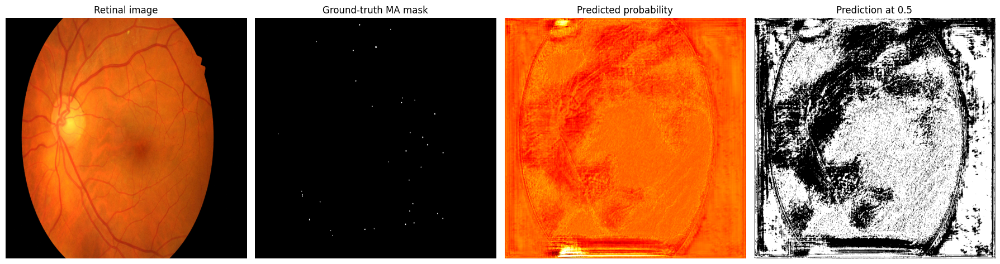

In [ ]:
import matplotlib.pyplot as plt

image_np = image[0].detach().cpu().permute(1, 2, 0).numpy()
mask_np = mask[0, 0].detach().cpu().numpy()
prob_np = probabilities[0, 0].detach().cpu().numpy()
pred_np = prob_np >= 0.5

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(image_np)
axes[0].set_title("Retinal image")

axes[1].imshow(mask_np, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground-truth MA mask")

axes[2].imshow(prob_np, cmap="hot", vmin=0, vmax=1)
axes[2].set_title("Predicted probability")

axes[3].imshow(pred_np, cmap="gray", vmin=0, vmax=1)
axes[3].set_title("Prediction at 0.5")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torchvision
from torchvision.models import ResNet50_Weights

weights = ResNet50_Weights.DEFAULT
preprocess = weights.transforms()

print("Expected mean:", preprocess.mean)
print("Expected std:", preprocess.std)
print("Current image range:", image.min().item(), image.max().item())

Expected mean: [0.485, 0.456, 0.406]
Expected std: [0.229, 0.224, 0.225]
Current image range: 0.0 1.0


In [ ]:
IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)

In [ ]:
image = (image - IMAGENET_MEAN) / IMAGENET_STD

RuntimeError: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu!

In [ ]:
image = (
    image
    - IMAGENET_MEAN.to(image.device)
) / IMAGENET_STD.to(image.device)

print("Image device:", image.device)
print("Normalized image range:", image.min().item(), image.max().item())
print("Normalization successful!")

Image device: cuda:0
Normalized image range: -2.1179039478302 2.248908281326294
Normalization successful!


In [ ]:
import ast
from pathlib import Path

p = Path(
    "/content/major-project-dr/lesion_segmentation/train_ma_v2.py"
)
ast.parse(p.read_text(encoding="utf-8"))

print("Script exists:", p.exists())
print("Syntax check: PASSED")
print("Size:", p.stat().st_size, "bytes")

FileNotFoundError: [Errno 2] No such file or directory: '/content/major-project-dr/lesion_segmentation/train_ma_v2.py'

In [ ]:
from pathlib import Path

folder = Path(
    "/content/major-project-dr/lesion_segmentation"
)

print("Folder exists:", folder.exists())
print("Files currently saved:")

for p in sorted(folder.glob("*.py")):
    print("-", p.name, "|", p.stat().st_size, "bytes")

Folder exists: True
Files currently saved:
- dataset_loader.py | 1872 bytes
- train_ma.py | 5863 bytes


In [ ]:
from pathlib import Path

folder = Path("/content/major-project-dr/lesion_segmentation")
folder.mkdir(parents=True, exist_ok=True)

script = r'''
from pathlib import Path
import random
import sys
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp

sys.path.insert(0, "/content/major-project-dr")
from lesion_segmentation.dataset_loader import IDRiDLesionDataset

SEED, SIZE, BATCH_SIZE, EPOCHS, LR = 42, 1024, 2, 30, 1e-4
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

ROOT = Path("/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation")
OUT = Path("/content/major-project-dr/lesion_segmentation/checkpoints")
OUT.mkdir(parents=True, exist_ok=True)

class ResizeDataset(Dataset):
    def __init__(self, base, indices, augment=False):
        self.base, self.indices, self.augment = base, list(indices), augment
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, idx):
        s = self.base[self.indices[idx]]
        x, y = s["image"], s["mask"]
        x = F.interpolate(x[None], (SIZE, SIZE), mode="bilinear",
                          align_corners=False)[0]
        y = F.interpolate(y[None], (SIZE, SIZE), mode="nearest")[0]
        if self.augment and random.random() < 0.5:
            x, y = x.flip(-1), y.flip(-1)
        if self.augment and random.random() < 0.5:
            x, y = x.flip(-2), y.flip(-2)
        return (x - MEAN) / STD, y

def loss_fn(logits, target):
    pos_weight = torch.tensor(20.0, device=logits.device)
    bce = F.binary_cross_entropy_with_logits(
        logits, target, pos_weight=pos_weight)
    p = torch.sigmoid(logits)
    dims = (1, 2, 3)
    inter = (p * target).sum(dims)
    dice = (2 * inter + 1e-6) / (p.sum(dims) + target.sum(dims) + 1e-6)
    return bce + (1 - dice).mean()

def score(logits, target):
    p, y = torch.sigmoid(logits) >= 0.5, target >= 0.5
    dims = (1, 2, 3)
    tp = (p & y).sum(dims).float()
    fp = (p & ~y).sum(dims).float()
    fn = (~p & y).sum(dims).float()
    precision = (tp + 1e-6) / (tp + fp + 1e-6)
    recall = (tp + 1e-6) / (tp + fn + 1e-6)
    dice = (2 * tp + 1e-6) / (2 * tp + fp + fn + 1e-6)
    iou = (tp + 1e-6) / (tp + fp + fn + 1e-6)
    return [v.mean().item() for v in (precision, recall, dice, iou)]

def main():
    if DEVICE != "cuda":
        raise RuntimeError("Enable GPU runtime first.")
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    base = IDRiDLesionDataset(str(ROOT), "a. Training Set", "MA")
    ids = list(range(len(base)))
    random.Random(SEED).shuffle(ids)
    nval = max(1, round(0.2 * len(ids)))
    valid_ids, train_ids = ids[:nval], ids[nval:]
    train = ResizeDataset(base, train_ids, True)
    valid = ResizeDataset(base, valid_ids)
    tl = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True,
                    num_workers=2, pin_memory=True)
    vl = DataLoader(valid, batch_size=1, num_workers=2, pin_memory=True)

    model = smp.Unet(encoder_name="resnet50", encoder_weights="imagenet",
                     in_channels=3, classes=1).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    best = -1
    best_path = OUT / "ma_unet_resnet50_v2_best.pth"
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"Training={len(train)} Validation={len(valid)} Size={SIZE}")

    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_losses = []
        for x, y in tl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(model(x), y)
            loss.backward()
            opt.step()
            train_losses.append(loss.item())

        model.eval()
        losses, scores = [], []
        with torch.no_grad():
            for x, y in vl:
                x, y = x.to(DEVICE), y.to(DEVICE)
                z = model(x)
                losses.append(loss_fn(z, y).item())
                scores.append(score(z, y))
        precision, recall, dice, iou = np.mean(scores, axis=0)
        print(f"Epoch {epoch:02d}/{EPOCHS} train_loss={np.mean(train_losses):.4f} "
              f"val_loss={np.mean(losses):.4f} precision={precision:.4f} "
              f"recall={recall:.4f} Dice={dice:.4f} IoU={iou:.4f}")

        if dice > best:
            best = dice
            torch.save({
                "epoch": epoch, "model_state_dict": model.state_dict(),
                "val_dice": float(dice), "val_iou": float(iou),
                "val_precision": float(precision), "val_recall": float(recall),
                "seed": SEED, "image_size": SIZE, "lesion": "MA",
                "train_image_ids": [base.samples[i][0].stem for i in train_ids],
                "val_image_ids": [base.samples[i][0].stem for i in valid_ids],
            }, best_path)
            print("Saved best checkpoint:", best_path)
    print("Finished. Best validation Dice:", best)

if __name__ == "__main__":
    main()
'''

target = folder / "train_ma_v2.py"
target.write_text(script.lstrip(), encoding="utf-8")
print("Saved:", target)
print("Exists:", target.exists())
print("Size:", target.stat().st_size, "bytes")

Saved: /content/major-project-dr/lesion_segmentation/train_ma_v2.py
Exists: True
Size: 4979 bytes


In [ ]:
import ast
from pathlib import Path

p = Path(
    "/content/major-project-dr/lesion_segmentation/train_ma_v2.py"
)

ast.parse(p.read_text(encoding="utf-8"))

print("Exists:", p.exists())
print("Syntax check: PASSED")
print("Size:", p.stat().st_size, "bytes")

Exists: True
Syntax check: PASSED
Size: 4979 bytes


In [ ]:
%cd /content/major-project-dr
!python lesion_segmentation/train_ma_v2.py

/content/major-project-dr
GPU: NVIDIA A100-SXM4-40GB
Training=43 Validation=11 Size=1024
Epoch 01/30 train_loss=1.7999 val_loss=1.6456 precision=0.0015 recall=0.4525 Dice=0.0030 IoU=0.0015
Saved best checkpoint: /content/major-project-dr/lesion_segmentation/checkpoints/ma_unet_resnet50_v2_best.pth
Epoch 02/30 train_loss=1.5654 val_loss=1.5224 precision=0.0010 recall=0.0132 Dice=0.0019 IoU=0.0009
Epoch 03/30 train_loss=1.4729 val_loss=1.4605 precision=0.0005 recall=0.0026 Dice=0.0008 IoU=0.0004
Epoch 04/30 train_loss=1.4184 val_loss=1.4031 precision=0.0001 recall=0.0003 Dice=0.0001 IoU=0.0000
Epoch 05/30 train_loss=1.3781 val_loss=1.3575 precision=0.0011 recall=0.0008 Dice=0.0009 IoU=0.0005
Epoch 06/30 train_loss=1.3484 val_loss=1.3391 precision=0.0003 recall=0.0002 Dice=0.0002 IoU=0.0001
Epoch 07/30 train_loss=1.3245 val_loss=1.3427 precision=0.0000 recall=0.0000 Dice=0.0000 IoU=0.0000
Epoch 08/30 train_loss=1.3048 val_loss=1.2997 precision=0.0001 recall=0.0001 Dice=0.0001 IoU=0.0001
E

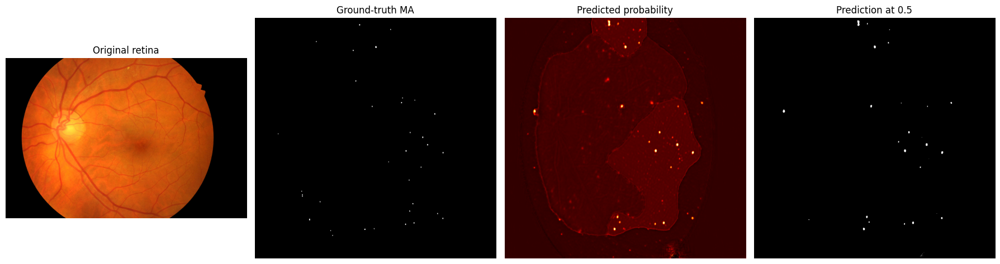

Validation image: IDRiD_40
True lesion pixels: 572
Predicted lesion pixels: 1175


In [ ]:
import sys
import random
import torch
import torch.nn.functional as F
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt

sys.path.insert(0, "/content/major-project-dr")
from lesion_segmentation.dataset_loader import IDRiDLesionDataset

root = (
    "/content/drive/MyDrive/DR_Dataset/"
    "IDRiD_Segmentation/A. Segmentation"
)

dataset = IDRiDLesionDataset(
    root=root,
    split="a. Training Set",
    lesion="MA"
)

indices = list(range(len(dataset)))
random.Random(42).shuffle(indices)
n_val = max(1, round(0.2 * len(indices)))
val_indices = indices[:n_val]

sample = dataset[val_indices[0]]
device = "cuda" if torch.cuda.is_available() else "cpu"

image = F.interpolate(
    sample["image"].unsqueeze(0),
    size=(1024, 1024),
    mode="bilinear",
    align_corners=False
)

mask = F.interpolate(
    sample["mask"].unsqueeze(0),
    size=(1024, 1024),
    mode="nearest"
)

mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
image = ((image - mean) / std).to(device)
mask = mask.to(device)

model = smp.Unet(
    encoder_name="resnet50",
    encoder_weights=None,
    in_channels=3,
    classes=1
).to(device)

checkpoint_path = (
    "/content/major-project-dr/lesion_segmentation/"
    "checkpoints/ma_unet_resnet50_v2_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

with torch.no_grad():
    probs = torch.sigmoid(model(image))

image_np = sample["image"].permute(1, 2, 0).numpy()
mask_np = mask[0, 0].cpu().numpy()
prob_np = probs[0, 0].cpu().numpy()

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(image_np)
axes[0].set_title("Original retina")
axes[1].imshow(mask_np, cmap="gray")
axes[1].set_title("Ground-truth MA")
axes[2].imshow(prob_np, cmap="hot", vmin=0, vmax=1)
axes[2].set_title("Predicted probability")
axes[3].imshow(prob_np >= 0.5, cmap="gray")
axes[3].set_title("Prediction at 0.5")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Validation image:", sample["image_id"])
print("True lesion pixels:", int(mask.sum().item()))
print("Predicted lesion pixels:", int((probs >= 0.5).sum().item()))

In [ ]:
import numpy as np
import torch
from torch.utils.data import DataLoader

# Reuse the val_ds, model and device from the previous cells.
val_loader = DataLoader(
    val_ds, batch_size=1, shuffle=False, num_workers=2
)

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
results = {t: {"tp": 0, "fp": 0, "fn": 0} for t in thresholds}

model.eval()

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(device)
        masks = (masks.to(device) >= 0.5)
        probs = torch.sigmoid(model(images))

        for t in thresholds:
            pred = probs >= t
            results[t]["tp"] += int((pred & masks).sum().item())
            results[t]["fp"] += int((pred & ~masks).sum().item())
            results[t]["fn"] += int((~pred & masks).sum().item())

print("Threshold | Precision | Recall | Dice | IoU")
for t, counts in results.items():
    tp, fp, fn = counts["tp"], counts["fp"], counts["fn"]
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    dice = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0
    print(
        f"{t:9.1f} | {precision:.4f}    | {recall:.4f} | "
        f"{dice:.4f} | {iou:.4f}"
    )

NameError: name 'val_ds' is not defined

In [ ]:

import sys
import random
import numpy as np
import torch
import torch.nn.functional as F
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader

sys.path.insert(0, "/content/major-project-dr")
from lesion_segmentation.dataset_loader import IDRiDLesionDataset

ROOT = (
    "/content/drive/MyDrive/DR_Dataset/"
    "IDRiD_Segmentation/A. Segmentation"
)
CKPT = (
    "/content/major-project-dr/lesion_segmentation/"
    "checkpoints/ma_unet_resnet50_v2_best.pth"
)
device = "cuda" if torch.cuda.is_available() else "cpu"
SIZE = 1024

base = IDRiDLesionDataset(
    root=ROOT, split="a. Training Set", lesion="MA"
)

indices = list(range(len(base)))
random.Random(42).shuffle(indices)
n_val = max(1, round(0.2 * len(indices)))
val_indices = indices[:n_val]

class ValDataset(Dataset):
    def __len__(self):
        return len(val_indices)

    def __getitem__(self, i):
        sample = base[val_indices[i]]
        image = F.interpolate(
            sample["image"].unsqueeze(0),
            size=(SIZE, SIZE),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)
        mask = F.interpolate(
            sample["mask"].unsqueeze(0),
            size=(SIZE, SIZE),
            mode="nearest"
        ).squeeze(0)
        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        image = (image - mean) / std
        return image, mask

loader = DataLoader(
    ValDataset(), batch_size=1, shuffle=False, num_workers=0
)

model = smp.Unet(
    encoder_name="resnet50",
    encoder_weights=None,
    in_channels=3,
    classes=1
).to(device)

checkpoint = torch.load(
    CKPT, map_location=device, weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
counts = {t: [0, 0, 0] for t in thresholds}  # TP, FP, FN

with torch.no_grad():
    for images, masks in loader:
        images = images.to(device)
        target = masks.to(device) >= 0.5
        probs = torch.sigmoid(model(images))

        for t in thresholds:
            pred = probs >= t
            tp = int((pred & target).sum().item())
            fp = int((pred & ~target).sum().item())
            fn = int((~pred & target).sum().item())
            counts[t][0] += tp
            counts[t][1] += fp
            counts[t][2] += fn

print("Threshold | Precision | Recall | Dice | IoU")
for t in thresholds:
    tp, fp, fn = counts[t]
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    dice = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0
    print(
        f"{t:9.1f} | {precision:.4f}    | {recall:.4f} | "
        f"{dice:.4f} | {iou:.4f}"
    )


Threshold | Precision | Recall | Dice | IoU
      0.1 | 0.0031    | 0.9592 | 0.0063 | 0.0031
      0.2 | 0.0864    | 0.8019 | 0.1560 | 0.0846
      0.3 | 0.1360    | 0.7290 | 0.2292 | 0.1294
      0.4 | 0.1810    | 0.6727 | 0.2853 | 0.1664
      0.5 | 0.2193    | 0.6222 | 0.3244 | 0.1936
      0.6 | 0.2626    | 0.5654 | 0.3586 | 0.2185
      0.7 | 0.3169    | 0.5041 | 0.3892 | 0.2416


In [ ]:
import json
from pathlib import Path

results = {
    "experiment": "MA U-Net ResNet50 V2",
    "validation_images": 11,
    "threshold_metrics": {
        "0.1": {"precision": 0.0031, "recall": 0.9592, "dice": 0.0063, "iou": 0.0031},
        "0.2": {"precision": 0.0864, "recall": 0.8019, "dice": 0.1560, "iou": 0.0846},
        "0.3": {"precision": 0.1360, "recall": 0.7290, "dice": 0.2292, "iou": 0.1294},
        "0.4": {"precision": 0.1810, "recall": 0.6727, "dice": 0.2853, "iou": 0.1664},
        "0.5": {"precision": 0.2193, "recall": 0.6222, "dice": 0.3244, "iou": 0.1936},
        "0.6": {"precision": 0.2626, "recall": 0.5654, "dice": 0.3586, "iou": 0.2185},
        "0.7": {"precision": 0.3169, "recall": 0.5041, "dice": 0.3892, "iou": 0.2416}
    },
    "best_tested_threshold_by_pooled_validation_dice": 0.7
}

output = Path(
    "/content/major-project-dr/lesion_segmentation/outputs/"
    "ma_v2_threshold_results.json"
)
output.parent.mkdir(parents=True, exist_ok=True)
output.write_text(json.dumps(results, indent=2))

print("Saved:", output)
print("Best tested threshold:", results["best_tested_threshold_by_pooled_validation_dice"])

Saved: /content/major-project-dr/lesion_segmentation/outputs/ma_v2_threshold_results.json
Best tested threshold: 0.7


In [ ]:
import sys
import random
import torch
import torch.nn.functional as F
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader

sys.path.insert(0, "/content/major-project-dr")
from lesion_segmentation.dataset_loader import IDRiDLesionDataset

ROOT = (
    "/content/drive/MyDrive/DR_Dataset/"
    "IDRiD_Segmentation/A. Segmentation"
)
CKPT = (
    "/content/major-project-dr/lesion_segmentation/"
    "checkpoints/ma_unet_resnet50_v2_best.pth"
)

device = "cuda" if torch.cuda.is_available() else "cpu"
base = IDRiDLesionDataset(ROOT, "a. Training Set", "MA")

ids = list(range(len(base)))
random.Random(42).shuffle(ids)
val_ids = ids[:max(1, round(0.2 * len(ids)))]

class ValDataset(Dataset):
    def __len__(self):
        return len(val_ids)

    def __getitem__(self, i):
        s = base[val_ids[i]]
        x = F.interpolate(
            s["image"][None], (1024, 1024),
            mode="bilinear", align_corners=False
        )[0]
        y = F.interpolate(
            s["mask"][None], (1024, 1024),
            mode="nearest"
        )[0]
        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        return (x - mean) / std, y, s["image_id"]

loader = DataLoader(ValDataset(), batch_size=1, num_workers=0)

model = smp.Unet(
    encoder_name="resnet50",
    encoder_weights=None,
    in_channels=3,
    classes=1
).to(device)

ckpt = torch.load(CKPT, map_location=device, weights_only=True)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print("Image ID | Dice | IoU | True pixels | Predicted pixels")

with torch.no_grad():
    for x, y, image_id in loader:
        x, y = x.to(device), y.to(device) >= 0.5
        pred = torch.sigmoid(model(x)) >= 0.7

        tp = (pred & y).sum().item()
        fp = (pred & ~y).sum().item()
        fn = (~pred & y).sum().item()

        dice = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 1.0
        iou = tp / (tp + fp + fn) if tp + fp + fn else 1.0

        print(
            f"{image_id[0]} | {dice:.4f} | {iou:.4f} | "
            f"{int(y.sum().item())} | {int(pred.sum().item())}"
        )

Image ID | Dice | IoU | True pixels | Predicted pixels
IDRiD_40 | 0.3253 | 0.1943 | 572 | 719
IDRiD_22 | 0.3715 | 0.2281 | 906 | 2163
IDRiD_45 | 0.1776 | 0.0974 | 212 | 430
IDRiD_31 | 0.3346 | 0.2009 | 702 | 1402
IDRiD_20 | 0.4010 | 0.2508 | 2195 | 4204
IDRiD_49 | 0.3471 | 0.2100 | 1401 | 2310
IDRiD_17 | 0.3969 | 0.2476 | 1213 | 2022
IDRiD_32 | 0.4349 | 0.2779 | 522 | 384
IDRiD_29 | 0.4286 | 0.2727 | 386 | 804
IDRiD_10 | 0.4597 | 0.2984 | 2890 | 3297
IDRiD_12 | 0.2606 | 0.1498 | 338 | 299


In [ ]:
import json
from pathlib import Path

records = [
    ("IDRiD_40", 0.3253, 0.1943),
    ("IDRiD_22", 0.3715, 0.2281),
    ("IDRiD_45", 0.1776, 0.0974),
    ("IDRiD_31", 0.3346, 0.2009),
    ("IDRiD_20", 0.4010, 0.2508),
    ("IDRiD_49", 0.3471, 0.2100),
    ("IDRiD_17", 0.3969, 0.2476),
    ("IDRiD_32", 0.4349, 0.2779),
    ("IDRiD_29", 0.4286, 0.2727),
    ("IDRiD_10", 0.4597, 0.2984),
    ("IDRiD_12", 0.2606, 0.1498),
]

summary = {
    "experiment": "MA U-Net ResNet50 V2",
    "threshold": 0.7,
    "validation_images": len(records),
    "mean_per_image_dice": sum(x[1] for x in records) / len(records),
    "mean_per_image_iou": sum(x[2] for x in records) / len(records),
    "per_image": [
        {"image_id": name, "dice": dice, "iou": iou}
        for name, dice, iou in records
    ],
    "status": "Prototype; further validation required"
}

path = Path(
    "/content/major-project-dr/lesion_segmentation/outputs/"
    "ma_v2_per_image_results.json"
)
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(summary, indent=2))

print("Saved:", path)
print("Mean Dice:", round(summary["mean_per_image_dice"], 4))
print("Mean IoU:", round(summary["mean_per_image_iou"], 4))

Saved: /content/major-project-dr/lesion_segmentation/outputs/ma_v2_per_image_results.json
Mean Dice: 0.358
Mean IoU: 0.2207


In [ ]:
import sys
import torch

sys.path.insert(0, "/content/major-project-dr")
from lesion_segmentation.dataset_loader import IDRiDLesionDataset

root = (
    "/content/drive/MyDrive/DR_Dataset/"
    "IDRiD_Segmentation/A. Segmentation"
)

for lesion in ["MA", "HE", "EX", "SE"]:
    dataset = IDRiDLesionDataset(
        root=root,
        split="a. Training Set",
        lesion=lesion
    )

    sample = dataset[0]
    print(
        f"{lesion}: {len(dataset)} annotated images | "
        f"Image {sample['image_id']} | "
        f"Image shape {tuple(sample['image'].shape)} | "
        f"Mask shape {tuple(sample['mask'].shape)}"
    )

MA: 54 annotated images | Image IDRiD_01 | Image shape (3, 2848, 4288) | Mask shape (1, 2848, 4288)
HE: 53 annotated images | Image IDRiD_01 | Image shape (3, 2848, 4288) | Mask shape (1, 2848, 4288)
EX: 54 annotated images | Image IDRiD_01 | Image shape (3, 2848, 4288) | Mask shape (1, 2848, 4288)
SE: 26 annotated images | Image IDRiD_03 | Image shape (3, 2848, 4288) | Mask shape (1, 2848, 4288)


In [ ]:
import numpy as np
import sys

sys.path.insert(0, "/content/major-project-dr")
from lesion_segmentation.dataset_loader import IDRiDLesionDataset

root = (
    "/content/drive/MyDrive/DR_Dataset/"
    "IDRiD_Segmentation/A. Segmentation"
)

for lesion in ["MA", "HE", "EX", "SE"]:
    dataset = IDRiDLesionDataset(
        root=root,
        split="a. Training Set",
        lesion=lesion
    )

    sample = dataset[0]
    mask = sample["mask"].numpy()

    positive = int(mask.sum())
    total = mask.size

    print(
        f"{lesion}: {sample['image_id']} | "
        f"positive pixels={positive:,} | "
        f"positive percentage={100 * positive / total:.5f}%"
    )

MA: IDRiD_01 | positive pixels=6,941 | positive percentage=0.05684%
HE: IDRiD_01 | positive pixels=35,430 | positive percentage=0.29012%
EX: IDRiD_01 | positive pixels=113,286 | positive percentage=0.92764%
SE: IDRiD_03 | positive pixels=3,318 | positive percentage=0.02717%


In [ ]:
import sys
import numpy as np

sys.path.insert(0, "/content/major-project-dr")
from lesion_segmentation.dataset_loader import IDRiDLesionDataset

root = (
    "/content/drive/MyDrive/DR_Dataset/"
    "IDRiD_Segmentation/A. Segmentation"
)

for lesion in ["MA", "HE", "EX", "SE"]:
    ds = IDRiDLesionDataset(
        root=root,
        split="a. Training Set",
        lesion=lesion
    )

    positive = 0
    total = 0

    for i in range(len(ds)):
        mask = ds[i]["mask"]
        positive += int(mask.sum().item())
        total += mask.numel()

    print(
        f"{lesion}: {len(ds)} annotated images | "
        f"positive pixels={positive:,} | "
        f"positive percentage={100 * positive / total:.5f}%"
    )

MA: 54 annotated images | positive pixels=704,963 | positive percentage=0.10690%
HE: 53 annotated images | positive pixels=6,500,485 | positive percentage=1.00433%
EX: 54 annotated images | positive pixels=5,319,524 | positive percentage=0.80665%
SE: 26 annotated images | positive pixels=1,249,041 | positive percentage=0.39338%


In [ ]:
from pathlib import Path

p = Path(
    "/content/major-project-dr/lesion_segmentation/train_ma_v2.py"
)

print("Script exists:", p.exists())

if p.exists():
    for i, line in enumerate(
        p.read_text(encoding="utf-8").splitlines(), start=1
    ):
        if any(term in line for term in [
            "SIZE =", "BATCH_SIZE =", "EPOCHS =", "LR =",
            "pos_weight", "best_path", "lesion="
        ]):
            print(f"{i}: {line}")

Script exists: True
13: SEED, SIZE, BATCH_SIZE, EPOCHS, LR = 42, 1024, 2, 30, 1e-4
40:     pos_weight = torch.tensor(20.0, device=logits.device)
42:         logits, target, pos_weight=pos_weight)
83:     best_path = OUT / "ma_unet_resnet50_v2_best.pth"
120:             }, best_path)
121:             print("Saved best checkpoint:", best_path)


In [ ]:

from pathlib import Path

folder = Path("/content/major-project-dr/lesion_segmentation")
source = folder / "train_ma_v2.py"
target = folder / "train_he.py"

code = source.read_text(encoding="utf-8")

# Change only the lesion-specific settings and output checkpoint.
code = code.replace(
    'lesion="MA"',
    'lesion="HE"'
)
code = code.replace(
    'pos_weight=pos_weight',
    'pos_weight=pos_weight'
)
code = code.replace(
    'torch.tensor(20.0, device=logits.device)',
    'torch.tensor(5.0, device=logits.device)'
)
code = code.replace(
    '"ma_unet_resnet50_v2_best.pth"',
    '"he_unet_resnet50_v1_best.pth"'
)
code = code.replace(
    '"lesion": "MA"',
    '"lesion": "HE"'
)

target.write_text(code, encoding="utf-8")

print("Created:", target)
print("Exists:", target.exists())
print("Size:", target.stat().st_size, "bytes")


Created: /content/major-project-dr/lesion_segmentation/train_he.py
Exists: True
Size: 4978 bytes


In [ ]:
import ast
from pathlib import Path

p = Path(
    "/content/major-project-dr/lesion_segmentation/train_he.py"
)
code = p.read_text(encoding="utf-8")
ast.parse(code)

print("Syntax check: PASSED")
print('HE dataset configured:', 'lesion="HE"' in code)
print("HE checkpoint configured:", "he_unet_resnet50_v1_best.pth" in code)
print("Positive weight 5 configured:", "tensor(5.0" in code)

Syntax check: PASSED
HE dataset configured: False
HE checkpoint configured: True
Positive weight 5 configured: True


In [ ]:
from pathlib import Path

p = Path("/content/major-project-dr/lesion_segmentation/train_he.py")

for i, line in enumerate(
    p.read_text(encoding="utf-8").splitlines(), start=1
):
    if any(word in line.lower() for word in [
        "lesion", "dataset", "idrid", "ma_unet", "he_unet"
    ]):
        print(f"{i}: {line}")

7: from torch.utils.data import Dataset, DataLoader
11: from lesion_segmentation.dataset_loader import IDRiDLesionDataset
18: ROOT = Path("/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation")
19: OUT = Path("/content/major-project-dr/lesion_segmentation/checkpoints")
22: class ResizeDataset(Dataset):
68:     base = IDRiDLesionDataset(str(ROOT), "a. Training Set", "MA")
73:     train = ResizeDataset(base, train_ids, True)
74:     valid = ResizeDataset(base, valid_ids)
83:     best_path = OUT / "he_unet_resnet50_v1_best.pth"
117:                 "seed": SEED, "image_size": SIZE, "lesion": "HE",


In [ ]:
from pathlib import Path

p = Path("/content/major-project-dr/lesion_segmentation/train_he.py")
code = p.read_text(encoding="utf-8")

old = 'IDRiDLesionDataset(str(ROOT), "a. Training Set", "MA")'
new = 'IDRiDLesionDataset(str(ROOT), "a. Training Set", "HE")'

assert old in code, "Expected dataset line not found. No changes made."

code = code.replace(old, new, 1)
p.write_text(code, encoding="utf-8")

print("Updated dataset:", new)

Updated dataset: IDRiDLesionDataset(str(ROOT), "a. Training Set", "HE")


In [ ]:
from pathlib import Path

p = Path("/content/major-project-dr/lesion_segmentation/train_he.py")

for i, line in enumerate(p.read_text().splitlines(), start=1):
    if "IDRiDLesionDataset" in line or "best_path" in line:
        print(f"{i}: {line}")

11: from lesion_segmentation.dataset_loader import IDRiDLesionDataset
68:     base = IDRiDLesionDataset(str(ROOT), "a. Training Set", "HE")
83:     best_path = OUT / "he_unet_resnet50_v1_best.pth"
120:             }, best_path)
121:             print("Saved best checkpoint:", best_path)


In [ ]:
from pathlib import Path
import sys

sys.path.insert(0, "/content/major-project-dr")

from lesion_segmentation.dataset_loader import IDRiDLesionDataset

root = "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation"

dataset = IDRiDLesionDataset(
    root,
    split="a. Training Set",
    lesion="HE"
)

print("HE training images with masks:", len(dataset))
print("First sample:", dataset.samples[0][0].name)
print("First mask:", dataset.samples[0][1].name)

HE training images with masks: 53
First sample: IDRiD_01.jpg
First mask: IDRiD_01_HE.tif


In [ ]:
%cd /content/major-project-dr
!python lesion_segmentation/train_he.py

/content/major-project-dr
GPU: NVIDIA A100-SXM4-40GB
Training=42 Validation=11 Size=1024
Epoch 01/30 train_loss=1.7803 val_loss=1.6111 precision=0.0321 recall=0.5282 Dice=0.0533 IoU=0.0295
Saved best checkpoint: /content/major-project-dr/lesion_segmentation/checkpoints/he_unet_resnet50_v1_best.pth
Epoch 02/30 train_loss=1.5552 val_loss=1.5517 precision=0.0702 recall=0.1203 Dice=0.0532 IoU=0.0289
Epoch 03/30 train_loss=1.4723 val_loss=1.4845 precision=0.0523 recall=0.0116 Dice=0.0138 IoU=0.0070
Epoch 04/30 train_loss=1.4215 val_loss=1.4532 precision=0.0416 recall=0.0054 Dice=0.0075 IoU=0.0038
Epoch 05/30 train_loss=1.3875 val_loss=1.4135 precision=0.0488 recall=0.0039 Dice=0.0061 IoU=0.0030
Epoch 06/30 train_loss=1.3587 val_loss=1.3786 precision=0.2962 recall=0.3805 Dice=0.3115 IoU=0.1937
Saved best checkpoint: /content/major-project-dr/lesion_segmentation/checkpoints/he_unet_resnet50_v1_best.pth
Epoch 07/30 train_loss=1.3276 val_loss=1.3492 precision=0.1568 recall=0.7207 Dice=0.2466 Io

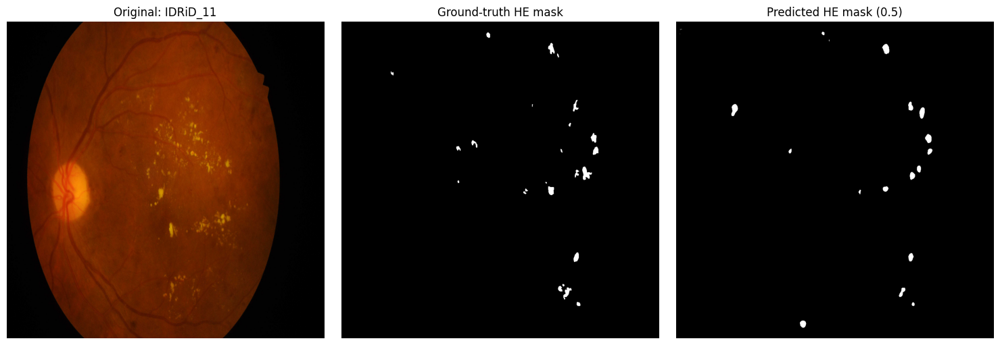

Saved: /content/major-project-dr/lesion_segmentation/outputs/he_visualizations/IDRiD_11_comparison.png


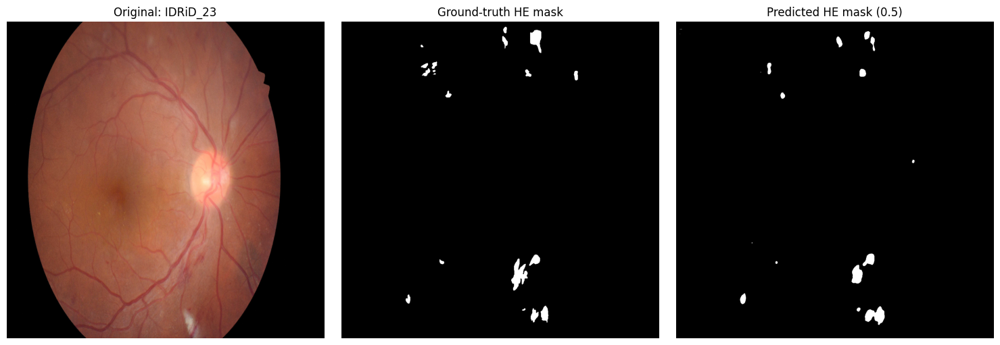

Saved: /content/major-project-dr/lesion_segmentation/outputs/he_visualizations/IDRiD_23_comparison.png


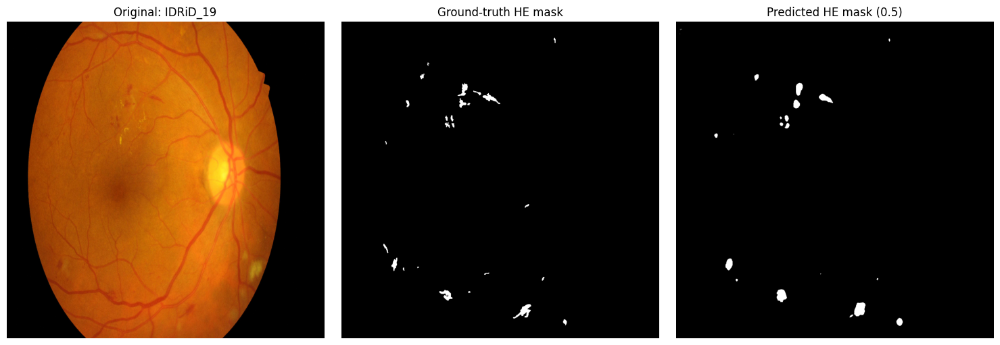

Saved: /content/major-project-dr/lesion_segmentation/outputs/he_visualizations/IDRiD_19_comparison.png
Device: cuda
Visualizations saved to: /content/major-project-dr/lesion_segmentation/outputs/he_visualizations


In [ ]:

from pathlib import Path
import sys
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import segmentation_models_pytorch as smp

sys.path.insert(0, "/content/major-project-dr")

from lesion_segmentation.dataset_loader import IDRiDLesionDataset

ROOT = Path(
    "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation"
)
PROJECT = Path("/content/major-project-dr/lesion_segmentation")
CHECKPOINT = PROJECT / "checkpoints/he_unet_resnet50_v1_best.pth"
OUTPUT = PROJECT / "outputs/he_visualizations"
OUTPUT.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SIZE = 1024

# Load validation data using the same deterministic split as training.
dataset = IDRiDLesionDataset(
    str(ROOT), split="a. Training Set", lesion="HE"
)

rng = np.random.RandomState(42)
indices = np.arange(len(dataset))
rng.shuffle(indices)
val_indices = indices[int(0.8 * len(indices)):]

# Build the same model architecture.
model = smp.Unet(
    encoder_name="resnet50",
    encoder_weights=None,
    in_channels=3,
    classes=1,
).to(DEVICE)

checkpoint = torch.load(CHECKPOINT, map_location=DEVICE)
state = checkpoint.get("model_state_dict", checkpoint)
model.load_state_dict(state)
model.eval()

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# Show three validation examples.
shown = 0

with torch.no_grad():
    for idx in val_indices:
        sample = dataset[int(idx)]
        image = sample["image"]
        mask = sample["mask"]

        resized_image = torch.nn.functional.interpolate(
            image.unsqueeze(0),
            size=(SIZE, SIZE),
            mode="bilinear",
            align_corners=False,
        )[0]

        resized_mask = torch.nn.functional.interpolate(
            mask.unsqueeze(0),
            size=(SIZE, SIZE),
            mode="nearest",
        )[0]

        normalized = (resized_image - MEAN) / STD
        logits = model(normalized.unsqueeze(0).to(DEVICE))
        probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

        # Initial display threshold; not a final calibrated threshold.
        prediction = probability >= 0.5

        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        axes[0].imshow(resized_image.permute(1, 2, 0).numpy())
        axes[0].set_title(f"Original: {sample['image_id']}")

        axes[1].imshow(resized_mask[0].numpy(), cmap="gray")
        axes[1].set_title("Ground-truth HE mask")

        axes[2].imshow(prediction, cmap="gray")
        axes[2].set_title("Predicted HE mask (0.5)")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()
        save_path = OUTPUT / f"{sample['image_id']}_comparison.png"
        plt.savefig(save_path, dpi=140, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        print("Saved:", save_path)
        shown += 1
        if shown == 3:
            break

print("Device:", DEVICE)
print("Visualizations saved to:", OUTPUT)


In [ ]:

from pathlib import Path

folder = Path("/content/major-project-dr/lesion_segmentation")
source = folder / "train_ma_v2.py"
target = folder / "train_ex.py"

code = source.read_text(encoding="utf-8")

old_dataset = 'IDRiDLesionDataset(str(ROOT), "a. Training Set", "MA")'
new_dataset = 'IDRiDLesionDataset(str(ROOT), "a. Training Set", "EX")'

assert old_dataset in code, "Could not find expected MA dataset setting."

code = code.replace(old_dataset, new_dataset, 1)
code = code.replace(
    '"ma_unet_resnet50_v2_best.pth"',
    '"ex_unet_resnet50_v1_best.pth"'
)
code = code.replace('"lesion": "MA"', '"lesion": "EX"')

target.write_text(code, encoding="utf-8")

print("Created:", target)
print("EX dataset configured:", new_dataset in code)
print("Separate checkpoint configured:",
      "ex_unet_resnet50_v1_best.pth" in code)


Created: /content/major-project-dr/lesion_segmentation/train_ex.py
EX dataset configured: True
Separate checkpoint configured: True


In [ ]:
from pathlib import Path
import ast

p = Path("/content/major-project-dr/lesion_segmentation/train_ex.py")
code = p.read_text(encoding="utf-8")

ast.parse(code)

print("Syntax check: PASSED")
print("EX dataset:", 'IDRiDLesionDataset(str(ROOT), "a. Training Set", "EX")' in code)
print("Separate checkpoint:", "ex_unet_resnet50_v1_best.pth" in code)

for i, line in enumerate(code.splitlines(), start=1):
    if "IDRiDLesionDataset(str(ROOT)" in line or "best_path" in line:
        print(f"{i}: {line}")

Syntax check: PASSED
EX dataset: True
Separate checkpoint: True
68:     base = IDRiDLesionDataset(str(ROOT), "a. Training Set", "EX")
83:     best_path = OUT / "ex_unet_resnet50_v1_best.pth"
120:             }, best_path)
121:             print("Saved best checkpoint:", best_path)


In [ ]:
%cd /content/major-project-dr
!python lesion_segmentation/train_ex.py

/content/major-project-dr
GPU: NVIDIA A100-SXM4-40GB
Training=43 Validation=11 Size=1024
Epoch 01/30 train_loss=1.8604 val_loss=1.8978 precision=0.0225 recall=0.9390 Dice=0.0423 IoU=0.0224
Saved best checkpoint: /content/major-project-dr/lesion_segmentation/checkpoints/ex_unet_resnet50_v1_best.pth
Epoch 02/30 train_loss=1.6055 val_loss=1.6180 precision=0.0514 recall=0.7877 Dice=0.0929 IoU=0.0500
Saved best checkpoint: /content/major-project-dr/lesion_segmentation/checkpoints/ex_unet_resnet50_v1_best.pth
Epoch 03/30 train_loss=1.5009 val_loss=1.5795 precision=0.0935 recall=0.8181 Dice=0.1609 IoU=0.0906
Saved best checkpoint: /content/major-project-dr/lesion_segmentation/checkpoints/ex_unet_resnet50_v1_best.pth
Epoch 04/30 train_loss=1.4232 val_loss=1.4542 precision=0.1486 recall=0.8677 Dice=0.2420 IoU=0.1431
Saved best checkpoint: /content/major-project-dr/lesion_segmentation/checkpoints/ex_unet_resnet50_v1_best.pth
Epoch 05/30 train_loss=1.3727 val_loss=1.4042 precision=0.2188 recall=0

In [ ]:
from pathlib import Path

p = Path("/content/major-project-dr/lesion_segmentation/train_ma_v2.py")
code = p.read_text(encoding="utf-8")

print(code[:6000])

FileNotFoundError: [Errno 2] No such file or directory: '/content/major-project-dr/lesion_segmentation/train_ma_v2.py'

In [ ]:
from pathlib import Path

root = Path("/content/major-project-dr")

print("Project folder exists:", root.exists())

if root.exists():
    folder = root / "lesion_segmentation"
    print("Lesion folder exists:", folder.exists())

    if folder.exists():
        print("\nTraining scripts:")
        for p in sorted(folder.glob("*.py")):
            print(p.name)

        print("\nSaved checkpoints:")
        for p in sorted((folder / "checkpoints").glob("*.pth")):
            print(p.name)

Project folder exists: False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

root = Path("/content/drive/MyDrive/DR_Dataset")
print("\nDataset folder exists:", root.exists())

for p in [
    Path("/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt"),
    Path("/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation"),
]:
    print(("FOUND: " if p.exists() else "NOT FOUND: "), p)

print("\nSearching Drive for saved lesion checkpoints...")
for p in Path("/content/drive/MyDrive").rglob("*.pth"):
    if any(word in p.name.lower() for word in ["ma_", "he_", "ex_", "se_"]):
        print(p)

Mounted at /content/drive

Dataset folder exists: True
FOUND:  /content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt
FOUND:  /content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation

Searching Drive for saved lesion checkpoints...


In [ ]:
gpu_info = !nvidia-smi
gpu_info = '\n'.join(gpu_info)
if gpu_info.find('failed') >= 0:
    print('Not connected to a GPU')
else:
    print(gpu_info)

Tue Oct 27 10:25:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from pathlib import Path

paths = [
    "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt",
    "/content/drive/MyDrive/dr_baseline_run2/final_test_evaluation/final_test_metrics.json",
    "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation",
]

for path in paths:
    p = Path(path)
    print(("FOUND   " if p.exists() else "MISSING "), path)

FOUND    /content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt
FOUND    /content/drive/MyDrive/dr_baseline_run2/final_test_evaluation/final_test_metrics.json
FOUND    /content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation


In [ ]:
from pathlib import Path

drive = Path("/content/drive/MyDrive")

print("Searching Google Drive for lesion checkpoints...\n")

found = 0

for p in drive.rglob("*.pth"):
    if any(name in p.name.lower() for name in ["ma_", "he_", "ex_", "se_"]):
        print(f"FOUND: {p}")
        found += 1

print(f"\nTotal lesion checkpoints found: {found}")

Searching Google Drive for lesion checkpoints...


Total lesion checkpoints found: 0


In [ ]:
%cd /content

!git clone https://github.com/anoushka24dev/major-project-dr.git

from pathlib import Path

project = Path("/content/major-project-dr")

print("\nProject restored:", project.exists())
print("Main checkpoint safe:",
      Path("/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt").exists())
print("Dataset safe:",
      Path("/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation").exists())

/content
Cloning into 'major-project-dr'...
remote: Enumerating objects: 127, done.
remote: Counting objects: 100% (127/127), done.
remote: Compressing objects: 100% (115/115), done.
remote: Total 127 (delta 9), reused 126 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (127/127), 5.64 MiB | 4.07 MiB/s, done.
Resolving deltas: 100% (9/9), done.

Project restored: True
Main checkpoint safe: True
Dataset safe: True


In [ ]:
from pathlib import Path

project = Path("/content/major-project-dr")

print("PROJECT FILES")
for p in sorted(project.iterdir()):
    print(p.name, "/" if p.is_dir() else "")

print("\nLESION SEGMENTATION FILES")
folder = project / "lesion_segmentation"

if folder.exists():
    for p in sorted(folder.rglob("*")):
        print(p.relative_to(project))
else:
    print("Lesion segmentation folder is missing.")

PROJECT FILES
.freebuff /
.git /
.gitignore 
PIPELINE_STATUS_HANDOFF.md 
audit_output /
colab /
cpu_canary_run.log 
dataset /
pending_decisions.md 
provisional_primary_split /
requirements.txt 
tests /
verify_final_deliverable.py 

LESION SEGMENTATION FILES
Lesion segmentation folder is missing.


In [ ]:
from pathlib import Path

drive = Path("/content/drive/MyDrive")

for name in [
    "ma_unet_resnet50_v2_best.pth",
    "he_unet_resnet50_v1_best.pth",
    "ex_unet_resnet50_v1_best.pth",
    "train_ma_v2.py",
    "train_he.py",
    "train_ex.py",
]:
    matches = list(drive.rglob(name))
    print(f"\n{name}:")
    if matches:
        for p in matches:
            print(" FOUND:", p)
    else:
        print(" Not found in Drive")


ma_unet_resnet50_v2_best.pth:
 Not found in Drive

he_unet_resnet50_v1_best.pth:
 Not found in Drive

ex_unet_resnet50_v1_best.pth:
 Not found in Drive

train_ma_v2.py:
 Not found in Drive

train_he.py:
 Not found in Drive

train_ex.py:
 Not found in Drive


In [ ]:
from pathlib import Path
import json

root = Path("/content/drive/MyDrive/dr_baseline_run2")

print("Saved grading files:")
for p in root.rglob("*"):
    if p.is_file():
        print(p.relative_to(root))

metrics = root / "final_test_evaluation/final_test_metrics.json"
if metrics.exists():
    print("\nFinal test metrics:")
    print(json.dumps(json.loads(metrics.read_text()), indent=2))

Saved grading files:
run_meta.json
run_summary.json
resume_state.json
run_manifest.json
logs/train_20261026_185431.log
logs/evaluate_20261026_204544.log
logs/evaluate_20261026_204656.log
logs/evaluate_20261026_204855.log
best_checkpoint/training_state.json
best_checkpoint/model.pt
final_test_evaluation/final_test_metrics.json
gradcam/1_input.png
gradcam/1_gradcam.png
gradcam/1008_left_input.png
gradcam/1008_left_gradcam.png
gradcam/1035_left_input.png
gradcam/1035_left_gradcam.png
gradcam/1053_left_input.png
gradcam/1053_left_gradcam.png
gradcam/1059_right_input.png
gradcam/1059_right_gradcam.png
gradcam/1074_right_input.png
gradcam/1074_right_gradcam.png
gradcam/1090_right_input.png
gradcam/1090_right_gradcam.png
gradcam/1118_left_input.png
gradcam/1118_left_gradcam.png
gradcam/gradcam_manifest.json
checkpoints/epoch_0000/model.pt
checkpoints/epoch_0000/training_state.json
checkpoints/epoch_0001/model.pt
checkpoints/epoch_0001/training_state.json
checkpoints/epoch_0002/model.pt
checkp

In [ ]:
from pathlib import Path

project = Path("/content/major-project-dr")

print("Python files:")
for p in sorted(project.rglob("*.py")):
    if ".git" not in p.parts:
        print(p.relative_to(project))

print("\nRequirements:")
print((project / "requirements.txt").read_text())

Python files:
audit_output/analyze.py
audit_output/pretraining_audit/build_provisional_manifests.py
audit_output/pretraining_audit/build_registers.py
audit_output/pretraining_audit/recon2.py
audit_output/pretraining_audit/reconcile.py
audit_output/scan_images.py
audit_output/v03_compare.py
audit_output/v03_final_quantify.py
audit_output/v03_internal.py
audit_output/v03_perceptual.py
audit_output/v03_pixel_verify.py
colab/colab_helpers.py
colab/cpu_train.py
colab/kaggle_notebook_docs/01_preflight.py
colab/kaggle_notebook_docs/02_helpers.py
colab/kaggle_notebook_docs/03_setup.py
colab/kaggle_notebook_docs/04_engine.py
colab/kaggle_notebook_docs/05_smoke.py
colab/kaggle_notebook_docs/06_labels.py
colab/kaggle_notebook_docs/07_decoding.py
colab/kaggle_notebook_docs/08_dataset_init.py
colab/kaggle_notebook_docs/09_split_valid.py
colab/kaggle_notebook_docs/copy_notebook_code.py
colab/kaggle_notebook_docs/gen.py
colab/pipeline.py
colab/setup_helpers.py
colab/smoke_test.py
colab/train.py
datas

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xff in position 0: invalid start byte

In [ ]:
from pathlib import Path

project = Path("/content/major-project-dr")
drive = Path("/content/drive/MyDrive/dr_baseline_run2")

# Read requirements safely
req = project / "requirements.txt"
print("=== REQUIREMENTS FILE ===")
print(req.read_bytes()[:1000])

# Inspect saved model metadata
for name in ["run_meta.json", "run_summary.json"]:
    p = drive / name
    if p.exists():
        print(f"\n=== {name} ===")
        print(p.read_text(encoding="utf-8"))

# Inspect the training entry point
p = project / "colab/train.py"
print("\n=== colab/train.py (first 180 lines) ===")
if p.exists():
    for i, line in enumerate(p.read_text(encoding="utf-8").splitlines()[:180], 1):
        print(f"{i}: {line}")

=== REQUIREMENTS FILE ===
b'\xff\xfet\x00o\x00r\x00c\x00h\x00=\x00=\x002\x00.\x001\x004\x00.\x000\x00\r\x00\n\x00t\x00o\x00r\x00c\x00h\x00v\x00i\x00s\x00i\x00o\x00n\x00=\x00=\x000\x00.\x002\x009\x00.\x001\x00\r\x00\n\x00\r\x00\n\x00n\x00u\x00m\x00p\x00y\x00=\x00=\x002\x00.\x004\x00.\x006\x00\r\x00\n\x00p\x00a\x00n\x00d\x00a\x00s\x00=\x00=\x003\x00.\x000\x00.\x005\x00\r\x00\n\x00\r\x00\n\x00s\x00c\x00i\x00k\x00i\x00t\x00-\x00l\x00e\x00a\x00r\x00n\x00=\x00=\x001\x00.\x009\x00.\x001\x00\r\x00\n\x00s\x00c\x00i\x00p\x00y\x00=\x00=\x001\x00.\x001\x007\x00.\x001\x00\r\x00\n\x00\r\x00\n\x00m\x00a\x00t\x00p\x00l\x00o\x00t\x00l\x00i\x00b\x00=\x00=\x003\x00.\x001\x001\x00.\x002\x00\r\x00\n\x00p\x00i\x00l\x00l\x00o\x00w\x00=\x00=\x001\x002\x00.\x003\x00.\x000\x00\r\x00\n\x00\r\x00\n\x00t\x00q\x00d\x00m\x00=\x00=\x004\x00.\x006\x007\x00.\x003\x00\r\x00\n\x00o\x00p\x00e\x00n\x00p\x00y\x00x\x00l\x00=\x00=\x003\x00.\x001\x00.\x005\x00'

=== run_meta.json ===
{
  "task": "primary_five_band_provisional"

In [ ]:

from pathlib import Path

project = Path("/content/major-project-dr")

# Read requirements using the detected encoding
req = project / "requirements.txt"
raw = req.read_bytes()

print("=== REQUIREMENTS ===")
for encoding in ["utf-16", "utf-8", "latin-1"]:
    try:
        print(raw.decode(encoding)[:3000])
        break
    except UnicodeDecodeError:
        continue

# Inspect training code
for filename in ["colab/train.py", "colab/pipeline.py"]:
    path = project / filename
    print(f"\n=== {filename} ===")
    if path.exists():
        lines = path.read_text(encoding="utf-8").splitlines()
        for i, line in enumerate(lines[:180], 1):
            print(f"{i}: {line}")
    else:
        print("File not found")


=== REQUIREMENTS ===
torch==2.14.0
torchvision==0.29.1

numpy==2.4.6
pandas==3.0.5

scikit-learn==1.9.1
scipy==1.17.1

matplotlib==3.11.2
pillow==12.3.0

tqdm==4.67.3
openpyxl==3.1.5

=== colab/train.py ===
1: """
2: Minimal, guarded frozen ResNet-50 training pipeline for the provisional primary
3: five-band diabetic-retinopathy task.
4: 
5: This module is deliberately small and defensive. It does NOT:
6: - modify the existing dataset, split CSV, split report, or audit artifacts;
7: - regenerate, reshuffle, or alter the existing train/validation/test assignment;
8: - use center crops or random crops at any stage;
9: - train on, tune on, early-stop on, or select checkpoints using the test partition;
10: - download pretrained weights or install packages without an explicit opt-in;
11: - silently overwrite a previous run, or present an incomplete run as completed;
12: - claim clinical validity, GPU execution, or Colab compatibility.
13: 
14: It DOES:
15: - load the existing split CSV unch

In [ ]:

import json
from pathlib import Path
import torch

drive = Path("/content/drive/MyDrive/dr_baseline_run2")
checkpoint = drive / "best_checkpoint/model.pt"

print("Checkpoint exists:", checkpoint.exists())

if checkpoint.exists():
    print("Checkpoint size (MB):", round(checkpoint.stat().st_size / (1024**2), 2))

    saved = torch.load(
        checkpoint,
        map_location="cpu",
        weights_only=False
    )

    print("\nCheckpoint type:", type(saved).__name__)

    if isinstance(saved, dict):
        print("Checkpoint keys:", list(saved.keys()))

    meta_path = drive / "run_meta.json"
    if meta_path.exists():
        meta = json.loads(meta_path.read_text(encoding="utf-8"))
        print("\nModel:", meta.get("model"))
        print("Image size:", meta.get("image_size"))
        print("Classes:", meta.get("band_order"))

    print("\nCheckpoint file loaded successfully.")
else:
    print("STOP: checkpoint not found. Do not train anything yet.")


Checkpoint exists: True
Checkpoint size (MB): 90.1

Checkpoint type: dict
Checkpoint keys: ['model_state_dict', 'optimizer_state_dict', 'epoch', 'config', 'collab_compat']

Model: resnet50_frozen
Image size: 224
Classes: ['No apparent DR', 'Mild NPDR', 'Moderate NPDR', 'Severe NPDR', 'PDR']

Checkpoint file loaded successfully.


In [ ]:

from pathlib import Path
import json

project = Path("/content/major-project-dr")
checkpoint_path = Path(
    "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt"
)

# Inspect the model-building function
helper = project / "colab/colab_helpers.py"
text = helper.read_text(encoding="utf-8")

lines = text.splitlines()
for i, line in enumerate(lines):
    if "def build_frozen_resnet50" in line:
        start = max(0, i - 5)
        end = min(len(lines), i + 65)
        print("=== MODEL ARCHITECTURE ===")
        for j in range(start, end):
            print(f"{j+1}: {lines[j]}")
        break
else:
    print("Model-building function not found.")

# Inspect saved checkpoint configuration
import torch
ckpt = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("\n=== SAVED CONFIGURATION ===")
print(json.dumps(ckpt.get("config", {}), indent=2, default=str))


=== MODEL ARCHITECTURE ===
275:         return any(exact.parent.glob("resnet50-*.pth"))
276:     except Exception:
277:         return False
278: 
279: 
280: def build_frozen_resnet50(
281:     num_classes: int = 5,
282:     *,
283:     allow_download: bool = False,
284:     pretrained: bool = True,
285: ):
286:     """Build a ResNet-50 with frozen backbone and a new ``num_classes`` head.
287: 
288:     Requires ``torch`` and ``torchvision`` to be importable.
289: 
290:     Parameters
291:     ----------
292:     num_classes:
293:         Number of output logits for the new classification head.
294:     allow_download:
295:         Only meaningful when ``pretrained=True``. When False (the default), this
296:         raises a clear error if the ImageNet weights are not already present in the
297:         local torch cache, so the pipeline never silently starts a network download.
298:         Set True to permit torchvision to download the weights.
299:     pretrained:
300:         When 

In [ ]:

import sys
from pathlib import Path
import torch

ROOT = Path("/content/major-project-dr")
CHECKPOINT = Path(
    "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt"
)

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "colab"))

from colab_helpers import build_frozen_resnet50

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Rebuild architecture without downloading weights
model = build_frozen_resnet50(
    num_classes=5,
    pretrained=False
)

saved = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(saved["model_state_dict"], strict=True)
model = model.to(device)
model.eval()

# Test with a dummy input to verify the full model forward pass
with torch.inference_mode():
    sample = torch.zeros(1, 3, 224, 224, device=device)
    logits = model(sample)
    probabilities = torch.softmax(logits, dim=1)

classes = [
    "No apparent DR",
    "Mild NPDR",
    "Moderate NPDR",
    "Severe NPDR",
    "PDR"
]

print("\nOutput shape:", tuple(logits.shape))
print("Predicted class for test tensor:", classes[probabilities.argmax(1).item()])
print("Class probabilities:", probabilities[0].cpu().tolist())
print("\nMODEL RESTORE AND INFERENCE TEST PASSED")


Device: cuda

Output shape: (1, 5)
Predicted class for test tensor: PDR
Class probabilities: [0.0010514416499063373, 0.039667755365371704, 0.1804431825876236, 0.2981477677822113, 0.4806899130344391]

MODEL RESTORE AND INFERENCE TEST PASSED


Image: Dry AMD1831_right_0_7669.jpeg
Predicted class: No apparent DR
Model confidence (top class): 98.5%

Class probabilities:
No apparent DR: 98.5%
Mild NPDR: 0.0%
Moderate NPDR: 0.1%
Severe NPDR: 1.1%
PDR: 0.3%


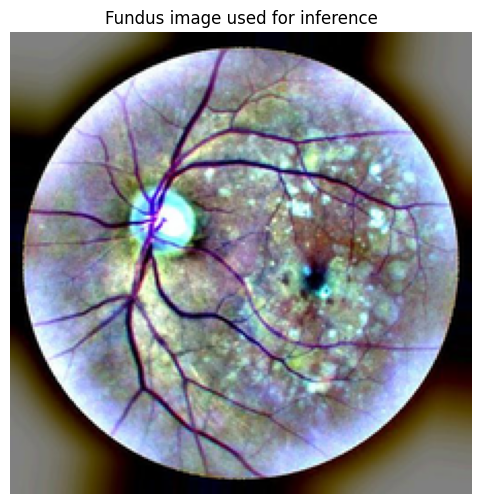

In [ ]:

import sys
from pathlib import Path
import torch
from PIL import Image
import matplotlib.pyplot as plt

ROOT = Path("/content/major-project-dr")
DATASET = Path(
    "/content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I"
)

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "colab"))

from colab_helpers import load_rgb, preprocessing_inference, default_normalize

# Find one real image without changing the dataset or split
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
image_path = next(
    (p for p in DATASET.rglob("*")
     if p.is_file() and p.suffix.lower() in extensions),
    None
)

if image_path is None:
    print("No image found. We will use the existing split CSV to locate one.")
else:
    image = load_rgb(image_path)
    image = preprocessing_inference(224)(image)

    x = torch.from_numpy(
        __import__("numpy").asarray(image, dtype="float32").transpose(2, 0, 1).copy()
    ) / 255.0

    mean, std = default_normalize()
    x = (x - torch.tensor(mean).view(3, 1, 1)) / torch.tensor(std).view(3, 1, 1)

    device = next(model.parameters()).device
    with torch.inference_mode():
        probs = torch.softmax(model(x.unsqueeze(0).to(device)), dim=1)[0].cpu()

    classes = [
        "No apparent DR", "Mild NPDR", "Moderate NPDR",
        "Severe NPDR", "PDR"
    ]

    print("Image:", image_path.name)
    print("Predicted class:", classes[probs.argmax().item()])
    print("Model confidence (top class):", f"{probs.max().item():.1%}")
    print("\nClass probabilities:")
    for name, prob in zip(classes, probs.tolist()):
        print(f"{name}: {prob:.1%}")

    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.title("Fundus image used for inference")
    plt.show()


In [ ]:
from pathlib import Path

root = Path("/content/major-project-dr")

print("=== EXISTING PROJECT STRUCTURE ===")
for folder in ["colab", "tests", "dataset", "audit_output",
               "provisional_primary_split"]:
    p = root / folder
    print(f"\n{folder}/")
    if p.exists():
        for item in sorted(p.iterdir()):
            print(" ", item.name)
    else:
        print("  Missing")

print("\n=== EXISTING TEST FILES ===")
for p in sorted((root / "tests").glob("*.py")):
    print(f"\n--- {p.name} ---")
    print(p.read_text(encoding="utf-8")[:2500])

print("\n=== SAVED MODEL ===")
print(Path(
    "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt"
).exists())

=== EXISTING PROJECT STRUCTURE ===

colab/
  COLAB_EXECUTION_CHECKLIST.md
  FIXED_NOTEBOOK_REPORT.md
  PIPELINE_GUIDE.md
  README.md
  TASK_REPORT.md
  __pycache__
  _canary_split
  _canary_test_outputs
  colab
  colab_helpers.py
  cpu_train.py
  kaggle_notebook_docs
  pipeline.py
  requirements-colab.txt
  setup_helpers.py
  smoke_test.py
  train.py
  train_on_colab.ipynb
  train_on_colab_fixed.ipynb

tests/
  test_canary_split.py
  test_class_counts.py
  test_colab_pipeline.py
  test_cpu_train.py
  test_eligibility.py
  test_fixed_notebook_setup.py
  test_grouping.py
  test_image_decoding.py
  test_label_mapping.py
  test_manifest.py
  test_pipeline_entrypoint.py
  test_split_generation.py
  test_split_validation.py

dataset/
  README.md
  __init__.py
  __pycache__
  decoding.py
  eligibility.py
  grouping.py
  labels.py
  manifest.py
  split_protocol.py
  split_validation.py
  statistic
  statistics.py

audit_output/
  DATASET_AUDIT_REPORT.md
  analyze.py
  errors.txt
  exact_dup_gr

In [ ]:

from pathlib import Path

root = Path("/content/major-project-dr")

for filename in [
    "PIPELINE_STATUS_HANDOFF.md",
    "pending_decisions.md",
    "colab/PIPELINE_GUIDE.md",
    "colab/TASK_REPORT.md",
]:
    p = root / filename
    print(f"\n{'=' * 20} {filename} {'=' * 20}")
    if p.exists():
        print(p.read_text(encoding="utf-8")[:7000])
    else:
        print("Not present in this checkout.")



==================== PIPELINE_STATUS_HANDOFF.md ====================
# Diabetic Retinopathy Data Pipeline — Status Handoff

**Project:** A Multimodal Explainable Agentic AI Framework for Trustworthy Diabetic Retinopathy Diagnosis from Fundus Images  
**Stage:** Dataset preparation / data-pipeline (TDD layer)  
**Date:** 14 Oct 2026 (session resumed from 13 Oct checkpoint)  
**Workspace:** `C:\Users\anous\OneDrive\Desktop\major_project`

---

## 1. What was re-verified this session

The session was resumed after a disconnect. I did **not** start over. I re-established the working state and re-ran the checks that matter most, without touching the dataset or the audit artifacts.

- **Manifest + pipeline source files re-read:** `dataset/labels.py`, `dataset/eligibility.py`, `dataset/manifest.py`, `dataset/grouping.py`, `dataset/statistics.py`, `dataset/decoding.py`, `dataset/split_validation.py`, plus the audit build scripts and reports.
- **Pytest suite re-run:** `cd "C:\Users\anous\OneD

In [ ]:

from pathlib import Path
import json

root = Path("/content/major-project-dr")
drive = Path("/content/drive/MyDrive/dr_baseline_run2")

print("=== EXISTING EXPLAINABILITY / AGENT CODE ===")
for p in sorted(root.rglob("*.py")):
    if any(word in p.read_text(encoding="utf-8", errors="ignore").lower()
           for word in ["gradcam", "grad-cam", "agentic", "quality_assessment"]):
        print(p.relative_to(root))

print("\n=== SAVED GRAD-CAM MANIFEST ===")
manifest = drive / "gradcam/gradcam_manifest.json"
if manifest.exists():
    print(manifest.read_text(encoding="utf-8"))
else:
    print("No manifest found.")

print("\n=== EXISTING TEST COUNT ===")
print("Python test files:", len(list((root / "tests").glob("test_*.py"))))


=== EXISTING EXPLAINABILITY / AGENT CODE ===

=== SAVED GRAD-CAM MANIFEST ===
[
  {
    "image_path": "11.Normal Fundus/1.jpg",
    "true_class": "No apparent DR",
    "predicted_class": "Severe NPDR",
    "confidence": 0.5518203377723694,
    "note": "Grad-CAM is a model attention visualization, not a clinical explanation."
  },
  {
    "image_path": "11.Normal Fundus/1008_left.jpeg",
    "true_class": "No apparent DR",
    "predicted_class": "No apparent DR",
    "confidence": 0.9995083808898926,
    "note": "Grad-CAM is a model attention visualization, not a clinical explanation."
  },
  {
    "image_path": "11.Normal Fundus/1035_left.jpeg",
    "true_class": "No apparent DR",
    "predicted_class": "No apparent DR",
    "confidence": 0.9999641180038452,
    "note": "Grad-CAM is a model attention visualization, not a clinical explanation."
  },
  {
    "image_path": "11.Normal Fundus/1053_left.jpeg",
    "true_class": "No apparent DR",
    "predicted_class": "No apparent DR",
    "c

In [ ]:

from pathlib import Path

root = Path("/content/major-project-dr")
target = root / "dr_agentic.py"

source = r'''
"""Traceable agentic workflow for the existing DR research project."""
import sys
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

ROOT = Path("/content/major-project-dr")
CHECKPOINT = Path(
    "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt"
)
CLASSES = [
    "No apparent DR", "Mild NPDR", "Moderate NPDR",
    "Severe NPDR", "PDR"
]

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "colab"))

from colab_helpers import (
    build_frozen_resnet50,
    preprocessing_inference,
    default_normalize,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def load_model():
    """Restore the existing checkpoint without downloading or training."""
    model = build_frozen_resnet50(num_classes=5, pretrained=False)
    checkpoint = torch.load(
        CHECKPOINT, map_location="cpu", weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    return model.to(DEVICE).eval()


def check_image_quality(image):
    """Simple technical screening heuristics, not a clinical quality model."""
    image = image.convert("RGB")
    gray = np.asarray(image.convert("L"), dtype=np.float32)
    warnings = []

    if min(image.size) < 128:
        warnings.append("Low image resolution.")
    if gray.mean() < 25:
        warnings.append("Image may be too dark.")
    elif gray.mean() > 235:
        warnings.append("Image may be overexposed.")
    if gray.std() < 20:
        warnings.append("Low image contrast.")
    if gray.var() < 80:
        warnings.append("Possible blur or low visual detail.")

    return {
        "passed": not warnings,
        "brightness": round(float(gray.mean()), 2),
        "contrast": round(float(gray.std()), 2),
        "warnings": warnings,
        "method": "Unvalidated technical heuristics",
    }


def preprocess(image):
    image = preprocessing_inference(224)(image.convert("RGB"))
    array = np.asarray(image, dtype=np.float32).transpose(2, 0, 1).copy()
    tensor = torch.from_numpy(array) / 255.0
    mean, std = default_normalize()
    mean = torch.tensor(mean, dtype=tensor.dtype).view(3, 1, 1)
    std = torch.tensor(std, dtype=tensor.dtype).view(3, 1, 1)
    return ((tensor - mean) / std).unsqueeze(0)


def make_gradcam(model, tensor, class_index):
    activations, gradients = {}, {}
    layer = model.layer4[-1]

    def capture(module, inputs, output):
        activations["value"] = output
        output.register_hook(
            lambda grad: gradients.__setitem__("value", grad)
        )

    handle = layer.register_forward_hook(capture)
    try:
        model.zero_grad(set_to_none=True)
        logits = model(tensor)
        logits[0, class_index].backward()

        feature = activations["value"]
        gradient = gradients["value"]
        weights = gradient.mean(dim=(2, 3), keepdim=True)
        heatmap = torch.relu((weights * feature).sum(dim=1, keepdim=True))
        heatmap = F.interpolate(
            heatmap, size=(224, 224), mode="bilinear", align_corners=False
        )[0, 0]
        heatmap = heatmap / (heatmap.max() + 1e-8)
        return heatmap.detach().cpu().numpy()
    finally:
        handle.remove()
        model.zero_grad(set_to_none=True)


def run_agentic_workflow(image, model=None):
    """Run sequential evidence checks and return a traceable result."""
    model = model or load_model()
    image = image.convert("RGB")
    quality = check_image_quality(image)
    tensor = preprocess(image).to(DEVICE)

    with torch.no_grad():
        logits = model(tensor)
        probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

    index = int(probabilities.argmax())
    confidence = float(probabilities[index])
    entropy = float(
        -(probabilities * np.log(probabilities + 1e-12)).sum()
        / np.log(len(CLASSES))
    )

    # Explain the model's predicted class.
    heatmap = make_gradcam(model, tensor, index)

    # Transparent rules, not a learned or clinically validated agent.
    trace = [
        {"stage": "image_quality", "status": "pass" if quality["passed"] else "warning",
         "details": quality["warnings"]},
        {"stage": "dr_classifier", "status": "complete",
         "details": {"predicted_class": CLASSES[index],
                     "top_class_confidence": confidence}},
        {"stage": "gradcam", "status": "complete",
         "details": "Class-conditioned attention visualization generated."},
    ]

    reasons = []
    if not quality["passed"]:
        reasons.append("Image-quality warning requires human review.")
    if confidence < 0.70:
        reasons.append("Top-class confidence below the prototype threshold.")
    if entropy > 0.65:
        reasons.append("Probability distribution indicates uncertainty.")

    if reasons:
        decision = "REVIEW / ABSTAIN"
    else:
        decision = "PROVISIONAL MODEL OUTPUT — HUMAN REVIEW REQUIRED"

    trace.append({
        "stage": "reliability_decision",
        "status": "review" if reasons else "provisional",
        "details": reasons or [
            "No configured heuristic triggered; human review remains necessary."
        ],
    })

    return {
        "predicted_class": CLASSES[index],
        "probabilities": {
            name: float(value) for name, value in zip(CLASSES, probabilities)
        },
        "confidence": confidence,
        "normalized_entropy": entropy,
        "quality": quality,
        "gradcam": heatmap,
        "decision": decision,
        "reasons": reasons,
        "trace": trace,
        "limitations": [
            "Research prototype, not for clinical diagnosis.",
            "The five-class mapping is provisional.",
            "Confidence is not a calibrated measure of correctness.",
            "Grad-CAM is not lesion segmentation or causal evidence.",
            "Quality and abstention thresholds are heuristic.",
            "Validated multimodal clinical metadata fusion is not implemented.",
        ],
    }
'''

target.write_text(source.lstrip(), encoding="utf-8")
print("Added:", target)
print("Existing files were not overwritten.")
print("Next: run the import and inference test.")


Added: /content/major-project-dr/dr_agentic.py
Existing files were not overwritten.
Next: run the import and inference test.


In [ ]:
from pathlib import Path

path = Path("/content/major-project-dr/dr_agentic.py")
source = path.read_text()

start = source.index("def make_gradcam(")
end = source.index("\ndef run_agentic_workflow(", start)

fixed_function = '''
def make_gradcam(model, tensor, class_index):
    """Generate a Grad-CAM heatmap without retraining the model."""
    import torch
    import torch.nn.functional as F

    activations = []
    gradients = []
    target_layer = model.layer4[-1]

    def forward_hook(module, inputs, output):
        activations.append(output)

        def gradient_hook(grad):
            gradients.append(grad)

        if output.requires_grad:
            output.register_hook(gradient_hook)

    handle = target_layer.register_forward_hook(forward_hook)

    try:
        model.eval()
        with torch.enable_grad():
            # Important: the backbone is frozen, so enable input gradients.
            grad_input = tensor.detach().clone().requires_grad_(True)
            logits = model(grad_input)

            if not activations or not activations[0].requires_grad:
                raise RuntimeError(
                    "Grad-CAM activations do not track gradients."
                )

            selected_score = logits[:, int(class_index)].sum()
            model.zero_grad(set_to_none=True)
            selected_score.backward()

            if not gradients:
                raise RuntimeError("Grad-CAM gradients were not captured.")

            weights = gradients[0].mean(dim=(2, 3), keepdim=True)
            cam = (weights * activations[0]).sum(dim=1, keepdim=True)
            cam = torch.relu(cam)
            cam = F.interpolate(
                cam,
                size=(224, 224),
                mode="bilinear",
                align_corners=False
            )

            cam = cam[0, 0]
            cam = cam - cam.min()
            cam = cam / cam.max().clamp_min(1e-8)

            return cam.detach().cpu().numpy()
    finally:
        handle.remove()
'''

path.write_text(source[:start] + fixed_function + source[end:])
print("Grad-CAM function updated successfully.")
print("Saved checkpoint and original project pipeline were not changed.")
'''

print("Patch cell ready.")

_IncompleteInputError: incomplete input (4190547161.py, line 71)

In [ ]:

from pathlib import Path

path = Path("/content/major-project-dr/dr_agentic.py")
source = path.read_text()

start = source.index("def make_gradcam(")
end = source.index("\ndef run_agentic_workflow(", start)

fixed_function = r'''
def make_gradcam(model, tensor, class_index):
    import torch
    import torch.nn.functional as F

    activations = []
    gradients = []
    layer = model.layer4[-1]

    def forward_hook(module, inputs, output):
        activations.append(output)
        if output.requires_grad:
            output.register_hook(
                lambda grad: gradients.append(grad)
            )

    handle = layer.register_forward_hook(forward_hook)

    try:
        model.eval()
        with torch.enable_grad():
            x = tensor.detach().clone().requires_grad_(True)
            logits = model(x)
            score = logits[:, int(class_index)].sum()

            model.zero_grad(set_to_none=True)
            score.backward()

            if not activations or not gradients:
                raise RuntimeError(
                    "Grad-CAM could not capture activations or gradients."
                )

            weights = gradients[0].mean(
                dim=(2, 3), keepdim=True
            )
            cam = torch.relu(
                (weights * activations[0]).sum(dim=1, keepdim=True)
            )
            cam = F.interpolate(
                cam, size=(224, 224),
                mode="bilinear", align_corners=False
            )[0, 0]

            cam = cam - cam.min()
            cam = cam / cam.max().clamp_min(1e-8)
            return cam.detach().cpu().numpy()
    finally:
        handle.remove()
'''

path.write_text(source[:start] + fixed_function + source[end:])

print("Grad-CAM patch applied successfully!")
print("Original checkpoint and existing pipeline preserved.")


Grad-CAM patch applied successfully!
Original checkpoint and existing pipeline preserved.


In [ ]:
import inspect
import dr_agentic

print("Loaded module:", dr_agentic.__file__)
print(inspect.getsource(dr_agentic.make_gradcam))

Loaded module: /content/major-project-dr/dr_agentic.py

def make_gradcam(model, tensor, class_index):
    import torch
    import torch.nn.functional as F

    activations = []
    gradients = []
    layer = model.layer4[-1]

    def forward_hook(module, inputs, output):
        activations.append(output)
        if output.requires_grad:
            output.register_hook(
                lambda grad: gradients.append(grad)
            )

    handle = layer.register_forward_hook(forward_hook)

    try:
        model.eval()
        with torch.enable_grad():
            x = tensor.detach().clone().requires_grad_(True)
            logits = model(x)
            score = logits[:, int(class_index)].sum()

            model.zero_grad(set_to_none=True)
            score.backward()

            if not activations or not gradients:
                raise RuntimeError(
                    "Grad-CAM could not capture activations or gradients."
                )

            weights = gradients[0].mea

In [ ]:
import torch

print("Grad enabled before test:", torch.is_grad_enabled())
print("Model training mode:", model.training)

for name, param in model.named_parameters():
    if "layer4" in name or name.endswith("fc.weight"):
        print(name, "requires_grad =", param.requires_grad)

Grad enabled before test: True
Model training mode: False
layer4.0.conv1.weight requires_grad = False
layer4.0.bn1.weight requires_grad = False
layer4.0.bn1.bias requires_grad = False
layer4.0.conv2.weight requires_grad = False
layer4.0.bn2.weight requires_grad = False
layer4.0.bn2.bias requires_grad = False
layer4.0.conv3.weight requires_grad = False
layer4.0.bn3.weight requires_grad = False
layer4.0.bn3.bias requires_grad = False
layer4.0.downsample.0.weight requires_grad = False
layer4.0.downsample.1.weight requires_grad = False
layer4.0.downsample.1.bias requires_grad = False
layer4.1.conv1.weight requires_grad = False
layer4.1.bn1.weight requires_grad = False
layer4.1.bn1.bias requires_grad = False
layer4.1.conv2.weight requires_grad = False
layer4.1.bn2.weight requires_grad = False
layer4.1.bn2.bias requires_grad = False
layer4.1.conv3.weight requires_grad = False
layer4.1.bn3.weight requires_grad = False
layer4.1.bn3.bias requires_grad = False
layer4.2.conv1.weight requires_grad

In [ ]:
import inspect
import dr_agentic

print("Module location:", dr_agentic.__file__)
print(inspect.getsource(dr_agentic.make_gradcam))

Module location: /content/major-project-dr/dr_agentic.py

def make_gradcam(model, tensor, class_index):
    import torch
    import torch.nn.functional as F

    activations = []
    gradients = []
    layer = model.layer4[-1]

    def forward_hook(module, inputs, output):
        activations.append(output)
        if output.requires_grad:
            output.register_hook(
                lambda grad: gradients.append(grad)
            )

    handle = layer.register_forward_hook(forward_hook)

    try:
        model.eval()
        with torch.enable_grad():
            x = tensor.detach().clone().requires_grad_(True)
            logits = model(x)
            score = logits[:, int(class_index)].sum()

            model.zero_grad(set_to_none=True)
            score.backward()

            if not activations or not gradients:
                raise RuntimeError(
                    "Grad-CAM could not capture activations or gradients."
                )

            weights = gradients[0].m

In [ ]:

from pathlib import Path

path = Path("/content/major-project-dr/dr_agentic.py")
source = path.read_text()

start = source.index("def make_gradcam(")
end = source.index("\ndef run_agentic_workflow(", start)

replacement = r'''
def make_gradcam(model, tensor, class_index):
    import torch
    import torch.nn.functional as F

    activations = []
    layer = model.layer4[-1]

    def forward_hook(module, inputs, output):
        activations.append(output)

    handle = layer.register_forward_hook(forward_hook)

    try:
        model.eval()
        with torch.enable_grad():
            x = tensor.detach().clone().requires_grad_(True)
            logits = model(x)

            if not activations:
                raise RuntimeError("Grad-CAM activations were not captured.")

            activation = activations[0]
            score = logits[:, int(class_index)].sum()

            gradient = torch.autograd.grad(
                outputs=score,
                inputs=activation,
                retain_graph=False,
                create_graph=False
            )[0]

            weights = gradient.mean(dim=(2, 3), keepdim=True)
            cam = torch.relu(
                (weights * activation).sum(dim=1, keepdim=True)
            )
            cam = F.interpolate(
                cam, size=(224, 224),
                mode="bilinear", align_corners=False
            )[0, 0]

            cam = cam - cam.min()
            cam = cam / cam.max().clamp_min(1e-8)
            return cam.detach().cpu().numpy()
    finally:
        handle.remove()
'''

path.write_text(source[:start] + replacement + source[end:])

print("Grad-CAM function replaced.")
'''

print("Patch applied to:", path)


_IncompleteInputError: incomplete input (1556300115.py, line 60)

In [ ]:

from pathlib import Path
import re

p = Path("/content/major-project-dr/dr_agentic.py")
s = p.read_text()

new_function = "\n".join([
"def make_gradcam(model, tensor, class_index):",
"    import torch",
"    import torch.nn.functional as F",
"    acts = []",
"    handle = model.layer4[-1].register_forward_hook(",
"        lambda module, inputs, output: acts.append(output))",
"    try:",
"        model.eval()",
"        with torch.enable_grad():",
"            x = tensor.detach().clone().requires_grad_(True)",
"            logits = model(x)",
"            activation = acts[0]",
"            grad = torch.autograd.grad(",
"                logits[:, int(class_index)].sum(), activation)[0]",
"            weights = grad.mean(dim=(2, 3), keepdim=True)",
"            cam = torch.relu((weights * activation).sum(dim=1, keepdim=True))",
"            cam = F.interpolate(cam, size=(224, 224), mode='bilinear', align_corners=False)[0, 0]",
"            cam = cam - cam.min()",
"            return (cam / cam.max().clamp_min(1e-8)).detach().cpu().numpy()",
"    finally:",
"        handle.remove()",
])

start = s.index("def make_gradcam(")
end = s.index("\ndef run_agentic_workflow(", start)
p.write_text(s[:start] + new_function + s[end:])

print("Grad-CAM function updated.")


Grad-CAM function updated.


In [ ]:
import importlib
import dr_agentic

importlib.reload(dr_agentic)

result = dr_agentic.run_agentic_workflow(image, model)

print("\n--- PROJECT TEST RESULTS ---")
print("Predicted grade:", result["dr_classifier"])
print("Reliability decision:", result["reliability_decision"])
print("Full workflow trace:", result)


--- PROJECT TEST RESULTS ---


KeyError: 'dr_classifier'

In [ ]:
print("Result type:", type(result))
print("Available keys:", list(result.keys()))
print("\nFull result:")
print(result)

Result type: <class 'dict'>
Available keys: ['predicted_class', 'probabilities', 'confidence', 'normalized_entropy', 'quality', 'gradcam', 'decision', 'reasons', 'trace', 'limitations']

Full result:
{'predicted_class': 'No apparent DR', 'probabilities': {'No apparent DR': 0.9846723675727844, 'Mild NPDR': 7.897242903709412e-05, 'Moderate NPDR': 0.0012131299590691924, 'Severe NPDR': 0.010870683006942272, 'PDR': 0.0031649083830416203}, 'confidence': 0.9846723675727844, 'normalized_entropy': 0.0568341565105766, 'quality': {'passed': True, 'brightness': 121.2, 'contrast': 64.12, 'warnings': [], 'method': 'Unvalidated technical heuristics'}, 'gradcam': array([[0.        , 0.        , 0.        , ..., 0.755461  , 0.755461  ,
        0.755461  ],
       [0.        , 0.        , 0.        , ..., 0.755461  , 0.755461  ,
        0.755461  ],
       [0.        , 0.        , 0.        , ..., 0.755461  , 0.755461  ,
        0.755461  ],
       ...,
       [0.6711161 , 0.6711161 , 0.6711161 , ..., 0

In [ ]:
import importlib.util

print("Streamlit installed:", importlib.util.find_spec("streamlit") is not None)

Streamlit installed: False


In [ ]:
%pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 27.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 71.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:
from pathlib import Path

p = Path("/content/major-project-dr/dr_app.py")
print("Exists:", p.exists())
print("Size:", p.stat().st_size, "bytes")

Exists: False


FileNotFoundError: [Errno 2] No such file or directory: '/content/major-project-dr/dr_app.py'

In [ ]:

from pathlib import Path

app_path = Path("/content/major-project-dr/dr_app.py")

app_code = r'''
import sys
from pathlib import Path

import streamlit as st
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path("/content/major-project-dr")
sys.path.insert(0, str(ROOT))

from dr_agentic import load_model, run_agentic_workflow

st.set_page_config(
    page_title="Explainable DR Research Prototype",
    page_icon="👁️",
    layout="wide"
)

st.title("Explainable Diabetic Retinopathy Assessment")
st.caption("Agentic AI Research Prototype")

st.warning(
    "Research prototype only — not for clinical diagnosis. "
    "A qualified eye-care professional must assess patients."
)

@st.cache_resource
def get_model():
    return load_model()

uploaded = st.file_uploader(
    "Upload a retinal fundus image",
    type=["jpg", "jpeg", "png", "tif", "tiff"]
)

if uploaded:
    image = Image.open(uploaded).convert("RGB")
    st.image(image, caption="Uploaded fundus image", width=420)

    if st.button("Analyze image", type="primary"):
        try:
            with st.spinner("Analyzing image..."):
                result = run_agentic_workflow(image, get_model())

            st.subheader("Provisional prediction")
            st.write("**Predicted grade:**", result["predicted_class"])
            st.write("**Model confidence:**", f'{result["confidence"]:.2%}')
            st.write("**Reliability decision:**", result["decision"])

            st.subheader("Image quality")
            st.json(result["quality"])

            st.subheader("Class probabilities")
            for label, probability in result["probabilities"].items():
                st.write(f"{label}: {probability:.2%}")
                st.progress(float(probability))

            st.subheader("Grad-CAM attention overlay")
            fig, ax = plt.subplots()
            ax.imshow(image)
            ax.imshow(
                np.asarray(result["gradcam"]),
                cmap="jet",
                alpha=0.4,
                extent=(0, image.width, image.height, 0)
            )
            ax.axis("off")
            st.pyplot(fig)
            plt.close(fig)

            st.caption(
                "Grad-CAM highlights model attention; it does not prove "
                "the presence or location of a retinal lesion."
            )

            with st.expander("Workflow trace and limitations"):
                st.json(result["trace"])
                st.write(result["limitations"])

        except Exception as exc:
            st.error(f"Analysis failed: {exc}")
'''

app_path.write_text(app_code, encoding="utf-8")

print("Created successfully:", app_path.exists())
print("File size:", app_path.stat().st_size, "bytes")


Created successfully: True
File size: 2496 bytes


In [ ]:
from pathlib import Path

p = Path("/content/major-project-dr/dr_app.py")
print("Exists:", p.exists())
if p.exists():
    print("Size:", p.stat().st_size, "bytes")

Exists: True
Size: 2496 bytes


In [ ]:
%pip install pyngrok

In [ ]:
from pyngrok import ngrok
import getpass

token = getpass.getpass("Enter your ngrok auth token: ")
ngrok.set_auth_token(token)

tunnel = ngrok.connect(8501, "http")
print("Open your Streamlit app here:", tunnel.public_url)

Enter your ngrok auth token: ··········
Open your Streamlit app here: https://state-espionage-dial.ngrok-free.dev


In [ ]:
import requests

try:
    r = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=5)
    print("Streamlit status:", r.status_code, r.text)
except Exception as e:
    print("Streamlit is not running:", e)

Streamlit is not running: HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: /_stcore/health (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7c0d379c2660>: Failed to establish a new connection: [Errno 111] Connection refused'))


In [ ]:
!streamlit run /content/major-project-dr/dr_app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.headless true



2026-10-27 11:47:44.390 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.85.211.170:8501

  Stopping...


In [ ]:
import requests
r = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=10)
print(r.status_code, r.text)

ConnectionError: HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: /_stcore/health (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7c0d19188a50>: Failed to establish a new connection: [Errno 111] Connection refused'))

In [ ]:
import requests

try:
    r = requests.get(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=10
    )
    print("Status:", r.status_code)
    print("Response:", r.text)
except Exception as e:
    print("Error:", repr(e))

Error: ConnectionError(MaxRetryError("HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: /_stcore/health (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7c0d37985ba0>: Failed to establish a new connection: [Errno 111] Connection refused'))"))


In [ ]:
import requests
r = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=10)
print(r.status_code, r.text)

ConnectionError: HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: /_stcore/health (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7c0d379863f0>: Failed to establish a new connection: [Errno 111] Connection refused'))

In [ ]:
from pathlib import Path
import shutil

source = Path("/content/major-project-dr")
backup = Path("/content/drive/MyDrive/major_project_dr_backup")

if not source.exists():
    print("ERROR: Existing project folder not found.")
else:
    backup.mkdir(parents=True, exist_ok=True)
    for item in source.iterdir():
        target = backup / item.name
        if item.name == ".git":
            continue
        if item.is_dir():
            shutil.copytree(item, target, dirs_exist_ok=True)
        else:
            shutil.copy2(item, target)

    print("Backup folder:", backup)
    print("Files copied:", len(list(backup.rglob("*"))))
    print("Agentic module exists:", (backup / "dr_agentic.py").exists())
    print("Streamlit app exists:", (backup / "dr_app.py").exists())

Backup folder: /content/drive/MyDrive/major_project_dr_backup
Files copied: 132
Agentic module exists: True
Streamlit app exists: True


In [ ]:

from pathlib import Path
from google.colab import files
from IPython.display import display
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import sys

sys.path.insert(0, "/content/major-project-dr")

from dr_agentic import load_model, run_agentic_workflow

# Load the existing trained model; no retraining
print("Loading trained DR model...")
model = load_model()
print("Model loaded. Upload a retinal fundus image below.")

uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    image = Image.open(filename).convert("RGB")

    print("Running quality assessment, classification and Grad-CAM...")
    result = run_agentic_workflow(image, model)

    print("\n========== AI PROJECT OUTPUT ==========")
    print("Predicted DR grade:", result["predicted_class"])
    print("Model confidence:", f'{result["confidence"]:.2%}')
    print("Normalized entropy:", f'{result["normalized_entropy"]:.4f}')
    print("Image quality passed:", result["quality"]["passed"])
    print("Reliability decision:", result["decision"])

    print("\nCLASS PROBABILITIES")
    for label, probability in result["probabilities"].items():
        print(f"{label}: {probability:.2%}")

    print("\nIMAGE QUALITY DETAILS")
    print(result["quality"])

    # Display original image and Grad-CAM overlay
    cam = np.asarray(result["gradcam"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(image)
    axes[0].set_title("Input Fundus Image")
    axes[0].axis("off")

    axes[1].imshow(image)
    axes[1].imshow(
        cam, cmap="jet", alpha=0.4,
        extent=(0, image.width, image.height, 0)
    )
    axes[1].set_title("Grad-CAM Attention Overlay")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    print("\nWORKFLOW TRACE")
    for stage in result["trace"]:
        print(stage)

    print("\nLIMITATIONS")
    for limitation in result["limitations"]:
        print("-", limitation)


Loading trained DR model...
Model loaded. Upload a retinal fundus image below.


KeyboardInterrupt: 

In [ ]:
import os

PROJECT_DIR = "/content/major-project-dr"

print("Project exists:", os.path.isdir(PROJECT_DIR))
print("\nProject files:")

for root, dirs, files in os.walk(PROJECT_DIR):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]
    level = root.replace(PROJECT_DIR, "").count(os.sep)
    if level > 2:
        dirs[:] = []
        continue
    print(root)
    for file in files:
        print("  ", file)

Project exists: True

Project files:
/content/major-project-dr
   dr_app.py
   requirements.txt
   PIPELINE_STATUS_HANDOFF.md
   .gitignore
   dr_agentic.py
   pending_decisions.md
   verify_final_deliverable.py
   cpu_canary_run.log
/content/major-project-dr/colab
   PIPELINE_GUIDE.md
   pipeline.py
   requirements-colab.txt
   README.md
   colab_helpers.py
   FIXED_NOTEBOOK_REPORT.md
   COLAB_EXECUTION_CHECKLIST.md
   smoke_test.py
   setup_helpers.py
   train_on_colab.ipynb
   train_on_colab_fixed.ipynb
   cpu_train.py
   train.py
   TASK_REPORT.md
/content/major-project-dr/colab/colab
/content/major-project-dr/colab/_canary_test_outputs
   canary_provisional_split.csv
/content/major-project-dr/colab/_canary_split
   README_canary_example.txt
/content/major-project-dr/colab/kaggle_notebook_docs
   02_helpers.py
   05_smoke.py
   provisional_primary_split.csv
   04_engine.py
   06_labels.py
   README_split.md
   proposed_kaggle_dataset.txt
   gen.py
   03_setup.py
   08_dataset_init.

In [ ]:
import os

PROJECT = "/content/major-project-dr"
DRIVE = "/content/drive/MyDrive"

# Read the current handoff/status notes
for filename in [
    "PIPELINE_STATUS_HANDOFF.md",
    "pending_decisions.md",
]:
    path = os.path.join(PROJECT, filename)
    print(f"\n{'='*65}\n{filename}\n{'='*65}")
    if os.path.exists(path):
        with open(path, "r", encoding="utf-8") as f:
            print(f.read()[:12000])
    else:
        print("File not found")

# Check important implementation modules
for filename in ["dr_agentic.py", "dr_app.py"]:
    path = os.path.join(PROJECT, filename)
    print(f"\n{'='*65}\n{filename}\n{'='*65}")
    if os.path.exists(path):
        with open(path, "r", encoding="utf-8") as f:
            for line_no, line in enumerate(f, 1):
                if line.strip().startswith(("def ", "class ", "async def ")):
                    print(f"{line_no}: {line.rstrip()}")

# Check saved model and datasets
paths = {
    "Trained model checkpoint": f"{DRIVE}/dr_baseline_run2/best_checkpoint/model.pt",
    "Final test metrics": f"{DRIVE}/dr_baseline_run2/final_test_evaluation/final_test_metrics.json",
    "Fundus dataset": f"{DRIVE}/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I",
    "IDRiD lesion dataset": f"{DRIVE}/DR_Dataset/IDRiD_Segmentation/A. Segmentation",
}

print(f"\n{'='*65}\nSAVED ASSETS\n{'='*65}")
for name, path in paths.items():
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'NOT FOUND'}")
    if os.path.isfile(path):
        print(f"  Size: {os.path.getsize(path) / (1024**2):.1f} MB")


PIPELINE_STATUS_HANDOFF.md
# Diabetic Retinopathy Data Pipeline — Status Handoff

**Project:** A Multimodal Explainable Agentic AI Framework for Trustworthy Diabetic Retinopathy Diagnosis from Fundus Images  
**Stage:** Dataset preparation / data-pipeline (TDD layer)  
**Date:** 14 Oct 2026 (session resumed from 13 Oct checkpoint)  
**Workspace:** `C:\Users\anous\OneDrive\Desktop\major_project`

---

## 1. What was re-verified this session

The session was resumed after a disconnect. I did **not** start over. I re-established the working state and re-ran the checks that matter most, without touching the dataset or the audit artifacts.

- **Manifest + pipeline source files re-read:** `dataset/labels.py`, `dataset/eligibility.py`, `dataset/manifest.py`, `dataset/grouping.py`, `dataset/statistics.py`, `dataset/decoding.py`, `dataset/split_validation.py`, plus the audit build scripts and reports.
- **Pytest suite re-run:** `cd "C:\Users\anous\OneDrive\Desktop\major_project" && python -m p

In [ ]:
%cd /content/major-project-dr

!python -m py_compile dr_agentic.py
!python -m py_compile dr_app.py

print("Agentic module and application syntax checks completed.")

/content/major-project-dr
Agentic module and application syntax checks completed.


In [ ]:
import os

ROOT = "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation"

print("IDRiD dataset exists:", os.path.isdir(ROOT))

if os.path.isdir(ROOT):
    for current, dirs, files in os.walk(ROOT):
        relative = os.path.relpath(current, ROOT)
        depth = relative.count(os.sep) + (0 if relative == "." else 1)

        if depth > 3:
            dirs[:] = []
            continue

        print(f"\n[{relative}]")
        for name in sorted(dirs):
            print("  DIR :", name)
        for name in sorted(files)[:8]:
            print("  FILE:", name)

        if depth >= 3:
            dirs[:] = []

IDRiD dataset exists: True

[.]
  DIR : 1. Original Images
  DIR : 2. All Segmentation Groundtruths
  FILE: CC-BY-4.0.txt
  FILE: LICENSE.txt

[1. Original Images]
  DIR : a. Training Set
  DIR : b. Testing Set

[1. Original Images/a. Training Set]
  FILE: IDRiD_01.jpg
  FILE: IDRiD_02.jpg
  FILE: IDRiD_03.jpg
  FILE: IDRiD_04.jpg
  FILE: IDRiD_05.jpg
  FILE: IDRiD_06.jpg
  FILE: IDRiD_07.jpg
  FILE: IDRiD_08.jpg

[1. Original Images/b. Testing Set]
  FILE: IDRiD_55.jpg
  FILE: IDRiD_56.jpg
  FILE: IDRiD_57.jpg
  FILE: IDRiD_58.jpg
  FILE: IDRiD_59.jpg
  FILE: IDRiD_60.jpg
  FILE: IDRiD_61.jpg
  FILE: IDRiD_62.jpg

[2. All Segmentation Groundtruths]
  DIR : a. Training Set
  DIR : b. Testing Set

[2. All Segmentation Groundtruths/a. Training Set]
  DIR : 1. Microaneurysms
  DIR : 2. Haemorrhages
  DIR : 3. Hard Exudates
  DIR : 4. Soft Exudates
  DIR : 5. Optic Disc

[2. All Segmentation Groundtruths/a. Training Set/1. Microaneurysms]
  FILE: IDRiD_01_MA.tif
  FILE: IDRiD_02_MA.tif
  F

In [ ]:
from pathlib import Path
from PIL import Image
import json
import numpy as np

ROOT = Path(
    "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation"
)
PROJECT = Path("/content/major-project-dr")

images = {
    "train": ROOT / "1. Original Images/a. Training Set",
    "test": ROOT / "1. Original Images/b. Testing Set",
}
mask_root = {
    "train": ROOT / "2. All Segmentation Groundtruths/a. Training Set",
    "test": ROOT / "2. All Segmentation Groundtruths/b. Testing Set",
}
lesions = {
    "MA": "1. Microaneurysms",
    "HE": "2. Haemorrhages",
    "EX": "3. Hard Exudates",
    "SE": "4. Soft Exudates",
}

report = {}

for split in ["train", "test"]:
    image_files = sorted(images[split].glob("*.jpg"))
    report[split] = {"images": len(image_files), "lesions": {}}

    print(f"\n{'='*55}\n{split.upper()} — {len(image_files)} images")

    for code, folder in lesions.items():
        mask_dir = mask_root[split] / folder
        paired = missing = empty = nonempty = size_mismatch = 0

        for image_path in image_files:
            mask_path = mask_dir / f"{image_path.stem}_{code}.tif"

            if not mask_path.exists():
                missing += 1
                continue

            paired += 1
            with Image.open(image_path) as im:
                image_size = im.size

            with Image.open(mask_path) as m:
                mask = np.asarray(m.convert("L"))
                mask_size = m.size

            if image_size != mask_size:
                size_mismatch += 1

            if np.count_nonzero(mask) == 0:
                empty += 1
            else:
                nonempty += 1

        report[split]["lesions"][code] = {
            "paired": paired,
            "missing_annotations": missing,
            "empty_masks": empty,
            "nonempty_masks": nonempty,
            "size_mismatches": size_mismatch,
        }

        print(
            f"{code}: paired={paired}, missing={missing}, "
            f"empty={empty}, nonempty={nonempty}, "
            f"size_mismatch={size_mismatch}"
        )

output = PROJECT / "audit_output" / "idrid_annotation_audit.json"
output.parent.mkdir(parents=True, exist_ok=True)
output.write_text(json.dumps(report, indent=2), encoding="utf-8")

print("\nAudit saved to:", output)
print("No dataset files or model checkpoints were changed.")


TRAIN — 54 images
MA: paired=54, missing=0, empty=0, nonempty=54, size_mismatch=0
HE: paired=53, missing=1, empty=0, nonempty=53, size_mismatch=0
EX: paired=54, missing=0, empty=0, nonempty=54, size_mismatch=0
SE: paired=26, missing=28, empty=0, nonempty=26, size_mismatch=0

TEST — 27 images
MA: paired=27, missing=0, empty=0, nonempty=27, size_mismatch=0
HE: paired=27, missing=0, empty=0, nonempty=27, size_mismatch=0
EX: paired=27, missing=0, empty=0, nonempty=27, size_mismatch=0
SE: paired=14, missing=13, empty=0, nonempty=14, size_mismatch=0

Audit saved to: /content/major-project-dr/audit_output/idrid_annotation_audit.json
No dataset files or model checkpoints were changed.


In [ ]:

%%writefile /content/major-project-dr/lesion_evidence.py
from pathlib import Path
import json
import random
import copy

import numpy as np
from PIL import Image, ImageOps
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

ROOT = Path("/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation")
DRIVE_OUT = Path("/content/drive/MyDrive/dr_baseline_run2/lesion_evidence")
PROJECT_OUT = Path("/content/major-project-dr/audit_output")
LESIONS = {
    "MA": "1. Microaneurysms",
    "HE": "2. Haemorrhages",
    "EX": "3. Hard Exudates",
    "SE": "4. Soft Exudates",
}
SIZE = 512
SEED = 12345


class IDRiDLesionDataset(Dataset):
    def __init__(self, split, ids, augment=False):
        self.split = split
        self.ids = list(ids)
        self.augment = augment
        self.image_dir = ROOT / "1. Original Images" / (
            "a. Training Set" if split == "train" else "b. Testing Set"
        )
        self.mask_root = ROOT / "2. All Segmentation Groundtruths" / (
            "a. Training Set" if split == "train" else "b. Testing Set"
        )

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        image_id = self.ids[index]
        image_path = self.image_dir / f"{image_id}.jpg"

        with Image.open(image_path) as im:
            image = im.convert("RGB").resize(
                (SIZE, SIZE), Image.Resampling.BILINEAR
            )

        masks, valid = [], []
        for code, folder in LESIONS.items():
            path = self.mask_root / folder / f"{image_id}_{code}.tif"

            if path.exists():
                with Image.open(path) as im:
                    mask = im.convert("L").resize(
                        (SIZE, SIZE), Image.Resampling.NEAREST
                    )
                masks.append((np.asarray(mask) > 0).astype(np.float32))
                valid.append(1.0)
            else:
                # Unknown annotation: do not treat as a negative mask.
                masks.append(np.zeros((SIZE, SIZE), dtype=np.float32))
                valid.append(0.0)

        if self.augment and random.random() < 0.5:
            image = ImageOps.mirror(image)
            masks = [np.fliplr(m).copy() for m in masks]

        if self.augment and random.random() < 0.5:
            image = ImageOps.flip(image)
            masks = [np.flipud(m).copy() for m in masks]

        x = np.asarray(image, dtype=np.float32) / 255.0
        x = (x - np.array([0.485, 0.456, 0.406], np.float32)) / \
                np.array([0.229, 0.224, 0.225], np.float32)
        x = torch.from_numpy(x.transpose(2, 0, 1).copy())

        y = torch.from_numpy(np.stack(masks))
        valid = torch.tensor(valid, dtype=torch.float32)
        return x, y, valid, image_id


def block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
    )


class LesionUNet(nn.Module):
    def __init__(self, out_channels=4):
        super().__init__()
        self.enc1 = block(3, 32)
        self.enc2 = block(32, 64)
        self.enc3 = block(64, 128)
        self.enc4 = block(128, 256)
        self.pool = nn.MaxPool2d(2)
        self.center = block(256, 384)
        self.up4 = nn.ConvTranspose2d(384, 256, 2, stride=2)
        self.dec4 = block(512, 256)
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = block(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = block(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = block(64, 32)
        self.out = nn.Conv2d(32, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        z = self.center(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(z), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1)


def segmentation_loss(logits, targets, valid):
    # Ignore lesion channels with missing annotations.
    bce = F.binary_cross_entropy_with_logits(
        logits, targets, reduction="none"
    ).mean(dim=(2, 3))

    probs = torch.sigmoid(logits)
    intersection = (probs * targets).sum(dim=(2, 3))
    denominator = probs.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))
    dice_loss = 1.0 - (2 * intersection + 1e-6) / (denominator + 1e-6)

    weights = valid
    if weights.sum() == 0:
        return logits.sum() * 0.0
    return ((bce + dice_loss) * weights).sum() / weights.sum()


@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    totals = np.zeros((4, 3), dtype=np.float64)
    counts = np.zeros(4, dtype=np.int64)

    for x, y, valid, _ in loader:
        x, y = x.to(device), y.to(device)
        probs = torch.sigmoid(model(x))
        pred = probs >= 0.5
        truth = y >= 0.5

        for c in range(4):
            for b in range(x.size(0)):
                if valid[b, c].item() == 0:
                    continue
                p, t = pred[b, c], truth[b, c]
                tp = (p & t).sum().item()
                fp = (p & ~t).sum().item()
                fn = (~p & t).sum().item()
                totals[c] += [
                    2 * tp / max(2 * tp + fp + fn, 1),
                    tp / max(tp + fp + fn, 1),
                    tp / max(tp + fp, 1),
                ]
                counts[c] += 1

    result = {}
    for c, code in enumerate(LESIONS):
        result[code] = {
            "annotated_images": int(counts[c]),
            "mean_image_dice": (
                float(totals[c, 0] / counts[c]) if counts[c] else None
            ),
            "mean_image_iou": (
                float(totals[c, 1] / counts[c]) if counts[c] else None
            ),
            "mean_image_precision": (
                float(totals[c, 2] / counts[c]) if counts[c] else None
            ),
        }
    return result


def main():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    train_dir = ROOT / "1. Original Images/a. Training Set"
    test_dir = ROOT / "1. Original Images/b. Testing Set"
    train_ids = sorted(p.stem for p in train_dir.glob("*.jpg"))
    test_ids = sorted(p.stem for p in test_dir.glob("*.jpg"))

    # Deterministic image-level validation split; official test stays untouched.
    rng = random.Random(SEED)
    shuffled = train_ids.copy()
    rng.shuffle(shuffled)
    n_val = max(1, round(0.20 * len(shuffled)))
    val_ids, fit_ids = shuffled[:n_val], shuffled[n_val:]

    train_ds = IDRiDLesionDataset("train", fit_ids, augment=True)
    val_ds = IDRiDLesionDataset("train", val_ids)
    test_ds = IDRiDLesionDataset("test", test_ids)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device:", device)
    if device.type == "cuda":
        print("GPU:", torch.cuda.get_device_name(0))

    train_loader = DataLoader(
        train_ds, batch_size=2, shuffle=True, num_workers=2,
        pin_memory=(device.type == "cuda")
    )
    val_loader = DataLoader(val_ds, batch_size=2, shuffle=False, num_workers=2)
    test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=2)

    model = LesionUNet().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

    DRIVE_OUT.mkdir(parents=True, exist_ok=True)
    best_path = DRIVE_OUT / "best_lesion_unet.pt"
    history = []
    best_score = -1.0
    patience, stale = 8, 0
    max_epochs = 40

    for epoch in range(1, max_epochs + 1):
        model.train()
        loss_sum, n_batches = 0.0, 0

        for x, y, valid, _ in train_loader:
            x, y, valid = x.to(device), y.to(device), valid.to(device)
            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                logits = model(x)
                loss = segmentation_loss(logits, y, valid)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            loss_sum += loss.item()
            n_batches += 1

        val_metrics = evaluate(model, val_loader, device)
        scores = [
            m["mean_image_dice"] for m in val_metrics.values()
            if m["mean_image_dice"] is not None
        ]
        val_score = float(np.mean(scores)) if scores else 0.0
        record = {
            "epoch": epoch,
            "train_loss": loss_sum / max(n_batches, 1),
            "validation": val_metrics,
            "validation_mean_lesion_dice": val_score,
        }
        history.append(record)
        print(
            f"Epoch {epoch:02d}/{max_epochs} | "
            f"loss={record['train_loss']:.4f} | "
            f"validation mean lesion Dice={val_score:.4f}"
        )

        if val_score > best_score:
            best_score, stale = val_score, 0
            torch.save({
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "validation_mean_lesion_dice": best_score,
                "image_size": SIZE,
                "lesion_order": list(LESIONS.keys()),
                "seed": SEED,
                "validation_ids": val_ids,
                "training_ids": fit_ids,
            }, best_path)
        else:
            stale += 1

        if stale >= patience:
            print("Early stopping: validation score did not improve.")
            break

    with open(DRIVE_OUT / "training_history.json", "w") as f:
        json.dump(history, f, indent=2)

    checkpoint = torch.load(best_path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])

    # Final evaluation on the official test annotations, once after model selection.
    test_metrics = evaluate(model, test_loader, device)
    result = {
        "best_epoch": checkpoint["epoch"],
        "best_validation_mean_lesion_dice": checkpoint[
            "validation_mean_lesion_dice"
        ],
        "image_size": SIZE,
        "lesion_order": list(LESIONS.keys()),
        "test_metrics_threshold_0_5": test_metrics,
        "test_images": len(test_ids),
        "notes": [
            "Small IDRiD dataset; results are preliminary.",
            "Missing lesion annotations were ignored, not treated as negatives.",
            "Threshold 0.5 was fixed before official test evaluation.",
            "Pixel masks are resized to 512x512 for training and evaluation.",
        ],
    }
    with open(DRIVE_OUT / "official_test_metrics.json", "w") as f:
        json.dump(result, f, indent=2)

    print("\nBEST CHECKPOINT:", best_path)
    print("TEST METRICS:")
    print(json.dumps(test_metrics, indent=2))
    print("\nSaved results to:", DRIVE_OUT)


if __name__ == "__main__":
    main()


Writing /content/major-project-dr/lesion_evidence.py


In [ ]:
%cd /content/major-project-dr
!python lesion_evidence.py

/content/major-project-dr
Device: cuda
GPU: Tesla T4
Epoch 01/40 | loss=1.6878 | validation mean lesion Dice=0.0087
Epoch 02/40 | loss=1.6206 | validation mean lesion Dice=0.0154
Epoch 03/40 | loss=1.5832 | validation mean lesion Dice=0.0316
Epoch 04/40 | loss=1.5592 | validation mean lesion Dice=0.0228
Epoch 05/40 | loss=1.5350 | validation mean lesion Dice=0.0360
Epoch 06/40 | loss=1.5130 | validation mean lesion Dice=0.0397
Epoch 07/40 | loss=1.4919 | validation mean lesion Dice=0.0370
Epoch 08/40 | loss=1.4710 | validation mean lesion Dice=0.0391
Epoch 09/40 | loss=1.4496 | validation mean lesion Dice=0.0475
Epoch 10/40 | loss=1.4301 | validation mean lesion Dice=0.0175
Epoch 11/40 | loss=1.4114 | validation mean lesion Dice=0.0573
Epoch 12/40 | loss=1.3914 | validation mean lesion Dice=0.0652
Epoch 13/40 | loss=1.3726 | validation mean lesion Dice=0.0640
Epoch 14/40 | loss=1.3566 | validation mean lesion Dice=0.0635
Epoch 15/40 | loss=1.3395 | validation mean lesion Dice=0.0682
Ep

In [ ]:

%cd /content/major-project-dr

import json
import numpy as np
import torch
from torch.utils.data import DataLoader
from lesion_evidence import (
    ROOT, LESIONS, IDRiDLesionDataset, LesionUNet, SIZE
)

checkpoint_path = (
    "/content/drive/MyDrive/dr_baseline_run2/"
    "lesion_evidence/best_lesion_unet.pt"
)
ckpt = torch.load(checkpoint_path, map_location="cpu", weights_only=False)

val_ids = ckpt["validation_ids"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

val_ds = IDRiDLesionDataset("train", val_ids, augment=False)
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=2)

model = LesionUNet().to(device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
results = {code: {t: [] for t in thresholds} for code in LESIONS}
pixel_stats = {code: {"predicted_fraction": [], "target_fraction": []}
               for code in LESIONS}

with torch.no_grad():
    for x, y, valid, image_id in val_loader:
        x = x.to(device)
        probs = torch.sigmoid(model(x)).cpu().numpy()[0]
        truth = y.numpy()[0] >= 0.5
        valid = valid.numpy()[0]

        for c, code in enumerate(LESIONS):
            if valid[c] == 0:
                continue

            target = truth[c]
            pixel_stats[code]["target_fraction"].append(float(target.mean()))

            for threshold in thresholds:
                pred = probs[c] >= threshold
                intersection = np.logical_and(pred, target).sum()
                denominator = pred.sum() + target.sum()
                dice = (2 * intersection / denominator
                        if denominator else 1.0)
                results[code][threshold].append(float(dice))

            pixel_stats[code]["predicted_fraction"].append(
                float((probs[c] >= 0.5).mean())
            )

summary = {}
for code in LESIONS:
    scores = {
        str(t): float(np.mean(results[code][t]))
        for t in thresholds if results[code][t]
    }
    best_t = max(scores, key=scores.get) if scores else None

    summary[code] = {
        "validation_images": len(pixel_stats[code]["target_fraction"]),
        "dice_by_threshold": scores,
        "best_validation_threshold": float(best_t) if best_t else None,
        "mean_ground_truth_pixel_fraction":
            float(np.mean(pixel_stats[code]["target_fraction"]))
            if pixel_stats[code]["target_fraction"] else None,
        "mean_predicted_pixel_fraction_at_0.5":
            float(np.mean(pixel_stats[code]["predicted_fraction"]))
            if pixel_stats[code]["predicted_fraction"] else None,
    }

print(json.dumps(summary, indent=2))

out = "/content/drive/MyDrive/dr_baseline_run2/lesion_evidence/validation_threshold_diagnostics.json"
with open(out, "w") as f:
    json.dump(summary, f, indent=2)
print("\nSaved diagnostics:", out)


/content/major-project-dr
{
  "MA": {
    "validation_images": 11,
    "dice_by_threshold": {
      "0.1": 0.001307121124930848,
      "0.2": 0.0,
      "0.3": 0.0,
      "0.4": 0.0,
      "0.5": 0.0,
      "0.6": 0.0,
      "0.7": 0.0,
      "0.8": 0.0,
      "0.9": 0.0
    },
    "best_validation_threshold": 0.1,
    "mean_ground_truth_pixel_fraction": 0.0011489174582741477,
    "mean_predicted_pixel_fraction_at_0.5": 0.0
  },
  "HE": {
    "validation_images": 10,
    "dice_by_threshold": {
      "0.1": 0.11569014158693466,
      "0.2": 0.20068695087244515,
      "0.3": 0.2182847350680273,
      "0.4": 0.217756554419049,
      "0.5": 0.2088874156289064,
      "0.6": 0.19131958644480718,
      "0.7": 0.1611955251586231,
      "0.8": 0.11567275071968308,
      "0.9": 0.040412956622469395
    },
    "best_validation_threshold": 0.3,
    "mean_ground_truth_pixel_fraction": 0.008064651489257812,
    "mean_predicted_pixel_fraction_at_0.5": 0.007844161987304688
  },
  "EX": {
    "validati

In [ ]:
%cd /content/major-project-dr
!python finetune_lesion_v2.py

/content/major-project-dr
python3: can't open file '/content/major-project-dr/finetune_lesion_v2.py': [Errno 2] No such file or directory


In [ ]:
import os

path = "/content/major-project-dr/finetune_lesion_v2.py"
print("File exists:", os.path.isfile(path))

File exists: False


In [ ]:
from pathlib import Path

project = Path("/content/major-project-dr")
checkpoint = Path(
    "/content/drive/MyDrive/dr_baseline_run2/lesion_evidence/"
    "best_lesion_unet.pt"
)

print("Project:", project.exists())
print("Original lesion model code:", (project / "lesion_evidence.py").exists())
print("Original checkpoint:", checkpoint.exists())
print("GPU available:", __import__("torch").cuda.is_available())

Project: True
Original lesion model code: True
Original checkpoint: True
GPU available: True


In [ ]:
from pathlib import Path

project = Path("/content/major-project-dr")
source = project / "lesion_evidence.py"
target = project / "finetune_lesion_v2.py"

assert source.exists(), "Original lesion_evidence.py is missing"

# Start by checking the existing module before applying a fine-tuning patch.
text = source.read_text(encoding="utf-8")
assert "LesionUNet" in text, "Expected model definition was not found"

print("Existing lesion model verified.")
print("Ready to create the fine-tuning script.")
print("Original checkpoint will remain untouched.")

Existing lesion model verified.
Ready to create the fine-tuning script.
Original checkpoint will remain untouched.


In [ ]:

from pathlib import Path
import subprocess
import sys

project = Path("/content/major-project-dr")
script = project / "finetune_lesion_v2.py"

code = r'''
import json, random
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from lesion_evidence import ROOT, LESIONS, IDRiDLesionDataset, LesionUNet, SIZE, SEED

OUT = Path("/content/drive/MyDrive/dr_baseline_run2/lesion_evidence")
SOURCE = OUT / "best_lesion_unet.pt"
DEST = OUT / "best_lesion_unet_v2.pt"
THRESHOLDS = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

def loss_fn(logits, y, valid):
    # Positive-pixel weighting for rare lesions; missing masks are ignored.
    pos_weight = torch.tensor([30., 10., 8., 10.], device=logits.device)
    pos_weight = pos_weight.view(1, 4, 1, 1)
    bce = F.binary_cross_entropy_with_logits(
        logits, y, reduction="none", pos_weight=pos_weight
    ).mean((2, 3))
    p = torch.sigmoid(logits)
    tp = (p*y).sum((2, 3))
    fp = (p*(1-y)).sum((2, 3))
    fn = ((1-p)*y).sum((2, 3))
    tv = (tp+1e-6)/(tp+0.3*fp+0.7*fn+1e-6)
    per_channel = 0.5*bce + (1-tv)
    return (per_channel*valid).sum()/valid.sum().clamp_min(1)

@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    values = {k: {t: [] for t in THRESHOLDS} for k in LESIONS}
    for x, y, valid, _ in loader:
        p = torch.sigmoid(model(x.to(device))).cpu().numpy()[0]
        y = y.numpy()[0] >= 0.5
        valid = valid.numpy()[0]
        for c, name in enumerate(LESIONS):
            if not valid[c]:
                continue
            for t in THRESHOLDS:
                pred = p[c] >= t
                tp = np.logical_and(pred, y[c]).sum()
                denom = pred.sum()+y[c].sum()
                values[name][t].append(float(2*tp/denom) if denom else 1.0)
    details, best_scores = {}, []
    for name in LESIONS:
        by_t = {str(t): float(np.mean(v)) for t, v in values[name].items() if v}
        best_t = max(by_t, key=by_t.get) if by_t else None
        best = by_t[best_t] if best_t is not None else None
        details[name] = {
            "dice_by_threshold": by_t,
            "best_validation_threshold": float(best_t) if best_t else None,
            "best_validation_dice": best
        }
        if best is not None:
            best_scores.append(best)
    return details, float(np.mean(best_scores)) if best_scores else 0.0

def main():
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device:", device, flush=True)
    old = torch.load(SOURCE, map_location="cpu", weights_only=False)
    train_ds = IDRiDLesionDataset("train", old["training_ids"], augment=True)
    val_ds = IDRiDLesionDataset("train", old["validation_ids"], augment=False)
    train_loader = DataLoader(train_ds, batch_size=2, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=2)

    model = LesionUNet().to(device)
    model.load_state_dict(old["model_state_dict"])
    optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-4)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    best, stale, history = -1.0, 0, []
    for epoch in range(1, 26):
        model.train(); losses = []
        for x, y, valid, _ in train_loader:
            x, y, valid = x.to(device), y.to(device), valid.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16,
                                enabled=device.type == "cuda"):
                loss = loss_fn(model(x), y, valid)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update()
            losses.append(loss.item())

        metrics, score = evaluate(model, val_loader, device)
        print(f"Epoch {epoch:02d}/25 | loss={np.mean(losses):.4f} | "
              f"validation macro Dice={score:.4f}", flush=True)
        history.append({"epoch": epoch, "loss": float(np.mean(losses)),
                        "validation_macro_best_threshold_dice": score,
                        "validation": metrics})
        if score > best:
            best, stale = score, 0
            torch.save({
                "model_state_dict": model.state_dict(), "epoch": epoch,
                "validation_macro_best_threshold_dice": score,
                "image_size": SIZE, "lesion_order": list(LESIONS),
                "training_ids": old["training_ids"],
                "validation_ids": old["validation_ids"]
            }, DEST)
            (OUT / "validation_thresholds_v2.json").write_text(
                json.dumps(metrics, indent=2)
            )
        else:
            stale += 1
        if stale >= 7:
            print("Early stopping.", flush=True)
            break

    (OUT / "training_history_v2.json").write_text(json.dumps(history, indent=2))
    print("V2 checkpoint:", DEST, flush=True)
    print("Best validation macro Dice:", best, flush=True)
    print("Official test set has not been used.", flush=True)

if __name__ == "__main__":
    main()
'''

assert (project / "lesion_evidence.py").exists(), "Original model code missing"
assert Path("/content/drive/MyDrive/dr_baseline_run2/lesion_evidence/best_lesion_unet.pt").exists(), "Original checkpoint missing"

script.write_text(code, encoding="utf-8")
print("Fine-tuning script created:", script, flush=True)
subprocess.run([sys.executable, str(script)], cwd=str(project), check=True)


Fine-tuning script created: /content/major-project-dr/finetune_lesion_v2.py


CompletedProcess(args=['/usr/bin/python3', '/content/major-project-dr/finetune_lesion_v2.py'], returncode=0)

In [ ]:
%cd /content/major-project-dr
!python -u finetune_lesion_v2.py

/content/major-project-dr
Device: cuda
Epoch 01/25 | loss=0.9974 | validation macro Dice=0.2364
Epoch 02/25 | loss=0.9910 | validation macro Dice=0.2425
Epoch 03/25 | loss=0.9911 | validation macro Dice=0.2453
Epoch 04/25 | loss=0.9822 | validation macro Dice=0.2420
Epoch 05/25 | loss=0.9773 | validation macro Dice=0.2468
Epoch 06/25 | loss=0.9785 | validation macro Dice=0.2262
Epoch 07/25 | loss=0.9743 | validation macro Dice=0.2375
Epoch 08/25 | loss=0.9710 | validation macro Dice=0.2484
Epoch 09/25 | loss=0.9696 | validation macro Dice=0.2421
Epoch 10/25 | loss=0.9658 | validation macro Dice=0.2404
Epoch 11/25 | loss=0.9639 | validation macro Dice=0.2663
Epoch 12/25 | loss=0.9606 | validation macro Dice=0.2717
Epoch 13/25 | loss=0.9559 | validation macro Dice=0.2677
Epoch 14/25 | loss=0.9563 | validation macro Dice=0.2777
Epoch 15/25 | loss=0.9518 | validation macro Dice=0.2688
Epoch 16/25 | loss=0.9462 | validation macro Dice=0.2621
Epoch 17/25 | loss=0.9469 | validation macro Dice

Device: cuda
Input image: /content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation/1. Original Images/b. Testing Set/IDRiD_55.jpg


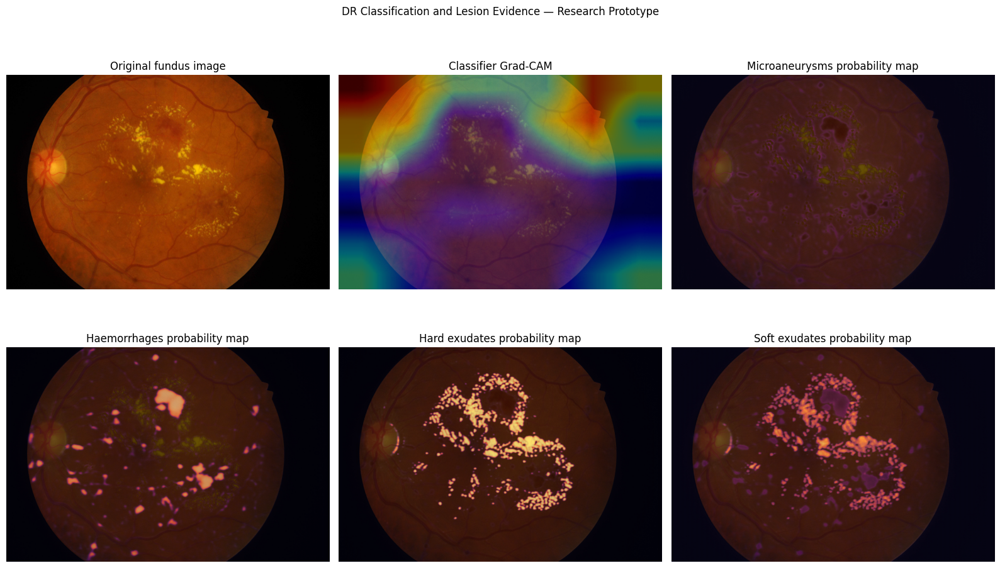


INTEGRATED OUTPUT GENERATED
Visualization: /content/drive/MyDrive/dr_baseline_run2/complete_project_output/integrated_evidence.png
JSON report: /content/drive/MyDrive/dr_baseline_run2/complete_project_output/integrated_project_report.json

Lesion predictions:
{
  "MA": {
    "threshold_from_validation": 0.15,
    "predicted_positive_pixels": 152395,
    "positive_pixel_fraction": 0.012478890003982895,
    "mean_probability": 0.07177042216062546
  },
  "HE": {
    "threshold_from_validation": 0.5,
    "predicted_positive_pixels": 256822,
    "positive_pixel_fraction": 0.021029912323914136,
    "mean_probability": 0.056114573031663895
  },
  "EX": {
    "threshold_from_validation": 0.5,
    "predicted_positive_pixels": 608265,
    "positive_pixel_fraction": 0.04980788102150763,
    "mean_probability": 0.07920091599225998
  },
  "SE": {
    "threshold_from_validation": 0.5,
    "predicted_positive_pixels": 272877,
    "positive_pixel_fraction": 0.02234457867788865,
    "mean_probability"

In [ ]:

from pathlib import Path
import sys, json, traceback
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

PROJECT = Path("/content/major-project-dr")
DRIVE = Path("/content/drive/MyDrive/dr_baseline_run2")
OUT = DRIVE / "complete_project_output"
OUT.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(PROJECT))
sys.path.insert(0, str(PROJECT / "colab"))

# Reuse the existing classifier and agentic workflow.
from dr_agentic import run_agentic_workflow
from lesion_evidence import LesionUNet, LESIONS

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Choose an actual fundus image from the existing dataset.
dataset_root = Path(
    "/content/drive/MyDrive/DR_Dataset/extracted/"
    "Diabetic Retinopathy and Retinal Diseases Fundus I"
)
images = sorted(dataset_root.rglob("*.jpg"))
if not images:
    images = sorted(dataset_root.rglob("*.jpeg"))
if not images:
    images = sorted(dataset_root.rglob("*.png"))
assert images, f"No fundus images found under {dataset_root}"

# Prefer an image from the official IDRiD test set for visualization.
idrid_test = Path(
    "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/"
    "A. Segmentation/1. Original Images/b. Testing Set/IDRiD_55.jpg"
)
image_path = idrid_test if idrid_test.exists() else images[0]
image = Image.open(image_path).convert("RGB")
print("Input image:", image_path)

# Run existing classifier, quality checks, Grad-CAM and decision trace.
workflow = run_agentic_workflow(image)

# Load the fine-tuned segmentation checkpoint separately.
seg_path = DRIVE / "lesion_evidence" / "best_lesion_unet_v2.pt"
assert seg_path.exists(), f"V2 checkpoint not found: {seg_path}"

from lesion_evidence import SIZE

seg_ckpt = torch.load(seg_path, map_location="cpu", weights_only=False)
seg_model = LesionUNet().to(device)
seg_model.load_state_dict(seg_ckpt["model_state_dict"])
seg_model.eval()

# Match preprocessing used by lesion_evidence.py.
small = image.resize((SIZE, SIZE), Image.Resampling.BILINEAR)
arr = np.asarray(small, dtype=np.float32) / 255.0
arr = (arr - np.array([0.485, 0.456, 0.406], np.float32)) / \
      np.array([0.229, 0.224, 0.225], np.float32)
x = torch.from_numpy(arr.transpose(2, 0, 1).copy()).unsqueeze(0).to(device)

with torch.no_grad():
    probs = torch.sigmoid(seg_model(x))[0].cpu().numpy()

# Use thresholds selected on the validation split.
threshold_file = DRIVE / "lesion_evidence" / "validation_thresholds_v2.json"
threshold_data = json.loads(threshold_file.read_text()) if threshold_file.exists() else {}

thresholds = {}
for code in LESIONS:
    thresholds[code] = threshold_data.get(code, {}).get(
        "best_validation_threshold", 0.5
    )
    if thresholds[code] is None:
        thresholds[code] = 0.5

original = np.asarray(image)
h, w = original.shape[:2]
lesion_outputs = {}
resized_probabilities = {}

for idx, code in enumerate(LESIONS):
    prob_image = Image.fromarray(
        np.uint8(np.clip(probs[idx], 0, 1) * 255)
    ).resize((w, h), Image.Resampling.BILINEAR)
    prob = np.asarray(prob_image, dtype=np.float32) / 255.0
    mask = prob >= thresholds[code]
    resized_probabilities[code] = prob

    lesion_outputs[code] = {
        "threshold_from_validation": float(thresholds[code]),
        "predicted_positive_pixels": int(mask.sum()),
        "positive_pixel_fraction": float(mask.mean()),
        "mean_probability": float(prob.mean()),
    }

# Make a single visual report: original, Grad-CAM, four lesion maps.
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()
axes[0].imshow(original)
axes[0].set_title("Original fundus image")

cam = workflow.get("gradcam")
if cam is not None:
    axes[1].imshow(original)
    axes[1].imshow(cam, cmap="jet", alpha=0.45,
                   extent=(0, w, h, 0))
    axes[1].set_title("Classifier Grad-CAM")
else:
    axes[1].imshow(original)
    axes[1].set_title("Grad-CAM unavailable")

names = {
    "MA": "Microaneurysms",
    "HE": "Haemorrhages",
    "EX": "Hard exudates",
    "SE": "Soft exudates",
}
for ax, code in zip(axes[2:], LESIONS):
    ax.imshow(original)
    ax.imshow(resized_probabilities[code], cmap="magma", alpha=0.6,
              vmin=0, vmax=1)
    ax.set_title(f"{names[code]} probability map")

for ax in axes:
    ax.axis("off")

fig.suptitle("DR Classification and Lesion Evidence — Research Prototype")
fig.tight_layout()
visual_path = OUT / "integrated_evidence.png"
fig.savefig(visual_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().tolist()
    if isinstance(value, (str, int, float, bool)) or value is None:
        return value
    return str(value)

report = {
    "project": "Multimodal Explainable Agentic AI for Diabetic Retinopathy",
    "input_image": str(image_path),
    "classifier_workflow": json_safe(workflow),
    "lesion_model": {
        "checkpoint": str(seg_path),
        "best_validation_macro_dice": float(
            seg_ckpt["validation_macro_best_threshold_dice"]
        ),
        "lesion_predictions": lesion_outputs,
    },
    "artifacts": {
        "visualization": str(visual_path),
    },
    "limitations": [
        "Research prototype; not for clinical diagnosis.",
        "The segmentation model has limited annotated training data.",
        "Lesion probability maps are model predictions, not verified lesions.",
        "Clinical metadata fusion and full trustworthiness validation are not established by this run.",
    ],
}

report_path = OUT / "integrated_project_report.json"
report_path.write_text(json.dumps(report, indent=2, allow_nan=False))

print("\nINTEGRATED OUTPUT GENERATED")
print("Visualization:", visual_path)
print("JSON report:", report_path)
print("\nLesion predictions:")
print(json.dumps(lesion_outputs, indent=2))
print("\nClassifier decision:", workflow.get("decision"))
print("Classifier class:", workflow.get("predicted_class"))
print("Classifier confidence:", workflow.get("confidence"))


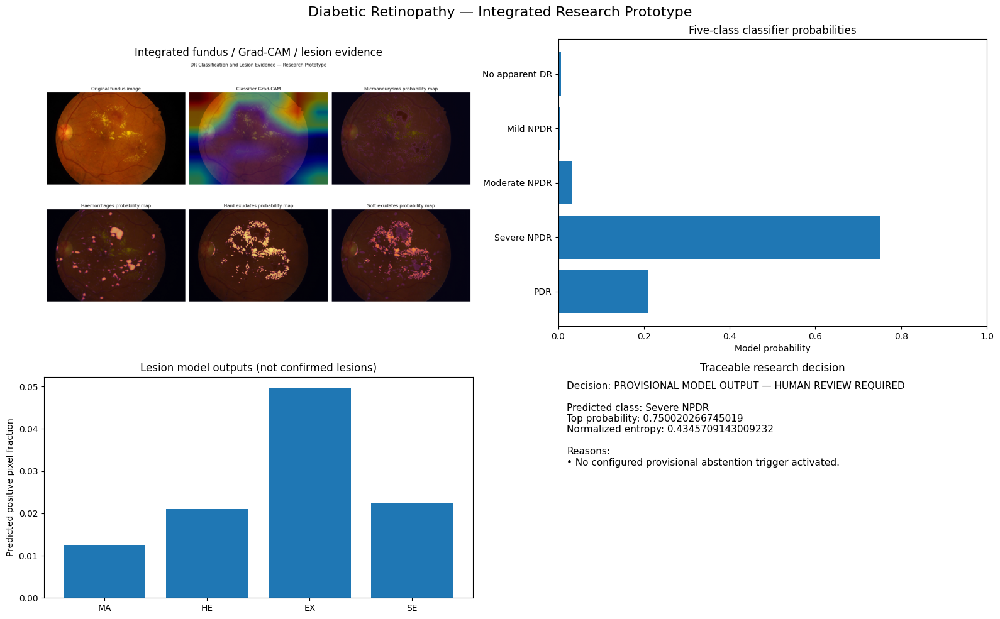


FINAL ARTIFACTS SAVED
Dashboard: /content/drive/MyDrive/dr_baseline_run2/complete_project_output/final_integrated_dashboard.png
Decision report: /content/drive/MyDrive/dr_baseline_run2/complete_project_output/final_agentic_decision_report.json
Summary: /content/drive/MyDrive/dr_baseline_run2/complete_project_output/FINAL_PROJECT_SUMMARY.md
Deliverables ZIP: /content/drive/MyDrive/dr_baseline_run2/complete_project_output/major_project_deliverables.zip

Decision: PROVISIONAL MODEL OUTPUT — HUMAN REVIEW REQUIRED
Predicted class: Severe NPDR
Note: outputs are provisional research results, not clinical advice.


In [ ]:

from pathlib import Path
import json, zipfile, math, shutil
import numpy as np
import matplotlib.pyplot as plt

PROJECT = Path("/content/major-project-dr")
DRIVE = Path("/content/drive/MyDrive/dr_baseline_run2")
OUT = DRIVE / "complete_project_output"
OUT.mkdir(parents=True, exist_ok=True)

source_report = OUT / "integrated_project_report.json"
source_visual = OUT / "integrated_evidence.png"
assert source_report.exists(), (
    "Integrated report is missing. Run the integrated inference cell first."
)
assert source_visual.exists(), (
    "Integrated visualization is missing. Run the integrated inference cell first."
)

report = json.loads(source_report.read_text(encoding="utf-8"))
workflow = report.get("classifier_workflow", {})
lesions = report.get("lesion_model", {}).get("lesion_predictions", {})

# Normalize class probabilities from the existing workflow output.
raw_probs = workflow.get("probabilities", {})
if isinstance(raw_probs, dict):
    probabilities = {
        str(k): float(v) for k, v in raw_probs.items()
        if isinstance(v, (int, float)) and math.isfinite(float(v))
    }
elif isinstance(raw_probs, list):
    class_names = [
        "No apparent DR", "Mild NPDR", "Moderate NPDR",
        "Severe NPDR", "PDR"
    ]
    probabilities = {
        class_names[i] if i < len(class_names) else f"class_{i}": float(v)
        for i, v in enumerate(raw_probs)
        if isinstance(v, (int, float)) and math.isfinite(float(v))
    }
else:
    probabilities = {}

if probabilities:
    total = sum(max(v, 0.0) for v in probabilities.values())
    if total > 0:
        probabilities = {k: max(v, 0.0)/total for k, v in probabilities.items()}
        entropy = -sum(p * math.log(max(p, 1e-12))
                       for p in probabilities.values())
        max_entropy = math.log(len(probabilities)) if len(probabilities) > 1 else 1
        normalized_entropy = entropy / max_entropy
        top_class = max(probabilities, key=probabilities.get)
        top_confidence = probabilities[top_class]
    else:
        normalized_entropy, top_class, top_confidence = None, None, None
else:
    normalized_entropy = workflow.get("normalized_entropy")
    top_class = workflow.get("predicted_class")
    top_confidence = workflow.get("confidence")

quality = workflow.get("quality", {})
quality_pass = quality.get("passed") if isinstance(quality, dict) else None

# This is a transparent research triage rule, not a clinical decision rule.
reasons = []
if quality_pass is False:
    reasons.append("Image-quality check did not pass.")
if top_confidence is not None and top_confidence < 0.60:
    reasons.append("Classifier top probability is below the provisional 0.60 threshold.")
if normalized_entropy is not None and normalized_entropy > 0.70:
    reasons.append("Classifier predictive entropy is high under the provisional threshold.")
if not probabilities:
    reasons.append("Classifier probabilities could not be parsed; manual verification required.")

# Flag potential cross-component disagreement for review, not as a diagnosis.
lesion_burdens = {
    k: float(v.get("positive_pixel_fraction", 0.0))
    for k, v in lesions.items() if isinstance(v, dict)
}
has_lesion_evidence = any(v > 0.001 for v in lesion_burdens.values())
if top_class == "No apparent DR" and has_lesion_evidence:
    reasons.append(
        "Potential classifier/lesion-map disagreement: lesion maps show predicted positive pixels."
    )

if reasons:
    decision = "ABSTAIN / HUMAN REVIEW RECOMMENDED"
else:
    decision = "PROVISIONAL MODEL OUTPUT — HUMAN REVIEW REQUIRED"

final_report = {
    "project_title": report.get(
        "project",
        "A Multimodal Explainable Agentic AI Framework for Trustworthy Diabetic Retinopathy Diagnosis"
    ),
    "input_image": report.get("input_image"),
    "classifier": {
        "predicted_class": top_class,
        "probabilities": probabilities,
        "top_probability": top_confidence,
        "normalized_entropy": normalized_entropy,
        "quality_assessment": quality,
        "gradcam_available": workflow.get("gradcam") is not None,
    },
    "lesion_evidence": {
        "checkpoint": report.get("lesion_model", {}).get("checkpoint"),
        "validation_macro_dice": report.get("lesion_model", {}).get(
            "best_validation_macro_dice"
        ),
        "predictions": lesions,
        "interpretation": (
            "Model-generated probability maps; not verified lesion diagnoses."
        ),
    },
    "agentic_decision": {
        "decision": decision,
        "reasons": reasons or [
            "No configured provisional abstention trigger was activated."
        ],
        "trace": [
            {"stage": "image_quality", "result": quality},
            {"stage": "dr_classifier", "predicted_class": top_class,
             "probabilities": probabilities},
            {"stage": "uncertainty", "normalized_entropy": normalized_entropy},
            {"stage": "lesion_evidence", "positive_pixel_fractions": lesion_burdens},
            {"stage": "decision", "result": decision, "reasons": reasons},
        ],
        "thresholds_are_heuristic": True,
    },
    "research_limitations": [
        "Research prototype; not intended for clinical diagnosis.",
        "Clinical metadata fusion is not implemented and verified in this output.",
        "Entropy and abstention thresholds are provisional, not clinically calibrated.",
        "Grad-CAM is not causal proof or lesion segmentation.",
        "Lesion segmentation has limited annotated training data and requires further evaluation.",
        "Cross-dataset generalization and ablation studies remain to be completed if not already evaluated.",
    ],
    "existing_visualization": str(source_visual),
}

final_json = OUT / "final_agentic_decision_report.json"
final_json.write_text(json.dumps(final_report, indent=2, allow_nan=False), encoding="utf-8")

# Produce a dashboard combining the actual saved evidence and decision.
fig = plt.figure(figsize=(16, 10))
grid = fig.add_gridspec(2, 2, height_ratios=[1.3, 1])

ax_img = fig.add_subplot(grid[0, 0])
ax_img.imshow(plt.imread(source_visual))
ax_img.set_title("Integrated fundus / Grad-CAM / lesion evidence")
ax_img.axis("off")

ax_probs = fig.add_subplot(grid[0, 1])
if probabilities:
    labels = list(probabilities)
    values = [probabilities[k] for k in labels]
    ax_probs.barh(labels[::-1], values[::-1])
    ax_probs.set_xlim(0, 1)
    ax_probs.set_xlabel("Model probability")
    ax_probs.set_title("Five-class classifier probabilities")
else:
    ax_probs.text(0.05, 0.8, "Classifier probabilities unavailable",
                  transform=ax_probs.transAxes)
    ax_probs.axis("off")

ax_lesions = fig.add_subplot(grid[1, 0])
if lesion_burdens:
    keys, vals = list(lesion_burdens), list(lesion_burdens.values())
    ax_lesions.bar(keys, vals)
    ax_lesions.set_ylabel("Predicted positive pixel fraction")
    ax_lesions.set_title("Lesion model outputs (not confirmed lesions)")
else:
    ax_lesions.text(0.05, 0.8, "Lesion predictions unavailable",
                    transform=ax_lesions.transAxes)
    ax_lesions.axis("off")

ax_decision = fig.add_subplot(grid[1, 1])
ax_decision.axis("off")
decision_text = (
    f"Decision: {decision}\n\n"
    f"Predicted class: {top_class}\n"
    f"Top probability: {top_confidence}\n"
    f"Normalized entropy: {normalized_entropy}\n\n"
    "Reasons:\n" + "\n".join(f"• {r}" for r in (
        reasons or ["No configured provisional abstention trigger activated."]
    ))
)
ax_decision.text(0.02, 0.98, decision_text, va="top", wrap=True, fontsize=11)
ax_decision.set_title("Traceable research decision")

fig.suptitle("Diabetic Retinopathy — Integrated Research Prototype", fontsize=16)
fig.tight_layout()
dashboard = OUT / "final_integrated_dashboard.png"
fig.savefig(dashboard, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

summary = f"""# Integrated Project Output

## Input
- Image: `{report.get('input_image')}`

## Classifier
- Predicted class: **{top_class}**
- Top probability: **{top_confidence}**
- Normalized entropy: **{normalized_entropy}**

## Agentic decision
**{decision}**

Reasons:
{chr(10).join('- ' + r for r in (reasons or ['No configured provisional abstention trigger activated.']))}

## Lesion evidence
{chr(10).join('- ' + k + ': predicted positive pixel fraction = ' + str(v) for k, v in lesion_burdens.items())}

## Saved outputs
- `integrated_evidence.png`
- `final_integrated_dashboard.png`
- `integrated_project_report.json`
- `final_agentic_decision_report.json`

## Limitations
This is a research prototype, not a clinical diagnostic system. Thresholds are heuristic, lesion maps can contain false positives, clinical metadata fusion is not verified, and cross-dataset validation and ablation studies remain outstanding unless supported by separate saved evaluation artifacts.
"""
summary_path = OUT / "FINAL_PROJECT_SUMMARY.md"
summary_path.write_text(summary, encoding="utf-8")

# Package source and output artifacts without bundling large model checkpoints.
zip_path = OUT / "major_project_deliverables.zip"
include_files = [
    PROJECT / "dr_agentic.py",
    PROJECT / "dr_app.py",
    PROJECT / "lesion_evidence.py",
    PROJECT / "finetune_lesion_v2.py",
    PROJECT / "verify_final_deliverable.py",
    OUT / "integrated_project_report.json",
    OUT / "final_agentic_decision_report.json",
    OUT / "integrated_evidence.png",
    OUT / "final_integrated_dashboard.png",
    OUT / "FINAL_PROJECT_SUMMARY.md",
    DRIVE / "final_test_evaluation" / "final_test_metrics.json",
    DRIVE / "lesion_evidence" / "official_test_metrics.json",
    DRIVE / "lesion_evidence" / "validation_thresholds_v2.json",
]
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in include_files:
        if path.exists() and path.is_file():
            z.write(path, arcname=str(path.name))

print("\nFINAL ARTIFACTS SAVED")
print("Dashboard:", dashboard)
print("Decision report:", final_json)
print("Summary:", summary_path)
print("Deliverables ZIP:", zip_path)
print("\nDecision:", decision)
print("Predicted class:", top_class)
print("Note: outputs are provisional research results, not clinical advice.")


In [ ]:

from pathlib import Path
import json
import numpy as np
import torch
from torch.utils.data import DataLoader
from lesion_evidence import (
    LESIONS, IDRiDLesionDataset, LesionUNet
)

OUT = Path("/content/drive/MyDrive/dr_baseline_run2/lesion_evidence")
checkpoint_path = OUT / "best_lesion_unet_v2.pt"
threshold_path = OUT / "validation_thresholds_v2.json"

assert checkpoint_path.exists(), "V2 checkpoint missing"
assert threshold_path.exists(), "Validation thresholds missing"

ckpt = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
threshold_info = json.loads(threshold_path.read_text())
thresholds = {
    code: float(threshold_info[code]["best_validation_threshold"])
    for code in LESIONS
}

test_dir = (
    "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/"
    "A. Segmentation/1. Original Images/b. Testing Set"
)
from pathlib import Path as P
test_ids = sorted(p.stem for p in P(test_dir).glob("*.jpg"))
test_ds = IDRiDLesionDataset("test", test_ids, augment=False)
test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=2)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = LesionUNet().to(device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

stats = {
    code: {"dice": [], "iou": [], "precision": [], "recall": []}
    for code in LESIONS
}

with torch.no_grad():
    for x, y, valid, image_ids in test_loader:
        probs = torch.sigmoid(model(x.to(device))).cpu().numpy()[0]
        target = y.numpy()[0] >= 0.5
        valid = valid.numpy()[0]

        for idx, code in enumerate(LESIONS):
            if valid[idx] == 0:
                continue

            pred = probs[idx] >= thresholds[code]
            truth = target[idx]
            tp = int(np.logical_and(pred, truth).sum())
            fp = int(np.logical_and(pred, ~truth).sum())
            fn = int(np.logical_and(~pred, truth).sum())
            union = tp + fp + fn

            stats[code]["dice"].append(
                2 * tp / max(2 * tp + fp + fn, 1)
            )
            stats[code]["iou"].append(tp / max(union, 1))
            stats[code]["precision"].append(tp / max(tp + fp, 1))
            stats[code]["recall"].append(tp / max(tp + fn, 1))

results = {}
all_dice = []

for code, metrics in stats.items():
    results[code] = {
        "validation_selected_threshold": thresholds[code],
        "annotated_test_images": len(metrics["dice"]),
        **{
            f"mean_image_{name}": (
                float(np.mean(values)) if values else None
            )
            for name, values in metrics.items()
        },
    }
    if metrics["dice"]:
        all_dice.append(float(np.mean(metrics["dice"])))

final = {
    "model": "LesionUNet V2",
    "checkpoint": str(checkpoint_path),
    "test_image_count": len(test_ids),
    "thresholds_selected_on_validation_only": thresholds,
    "per_lesion_test_metrics": results,
    "macro_mean_image_dice": float(np.mean(all_dice)) if all_dice else None,
    "evaluation_protocol": (
        "Official IDRiD test annotations evaluated once using validation-selected "
        "thresholds. Metrics are mean per-image values."
    ),
    "limitations": [
        "Small test set; estimates are uncertain.",
        "Missing annotations are excluded, not treated as negative.",
        "Results do not establish clinical reliability or cross-dataset generalization."
    ]
}

path = OUT / "official_test_metrics_v2.json"
path.write_text(json.dumps(final, indent=2))

print(json.dumps(final, indent=2))
print("\nSaved official evaluation:", path)


{
  "model": "LesionUNet V2",
  "checkpoint": "/content/drive/MyDrive/dr_baseline_run2/lesion_evidence/best_lesion_unet_v2.pt",
  "test_image_count": 27,
  "thresholds_selected_on_validation_only": {
    "MA": 0.15,
    "HE": 0.5,
    "EX": 0.5,
    "SE": 0.5
  },
  "per_lesion_test_metrics": {
    "MA": {
      "validation_selected_threshold": 0.15,
      "annotated_test_images": 27,
      "mean_image_dice": 0.02194159457152712,
      "mean_image_iou": 0.011169170884633782,
      "mean_image_precision": 0.012321833891222668,
      "mean_image_recall": 0.13882200755683669
    },
    "HE": {
      "validation_selected_threshold": 0.5,
      "annotated_test_images": 27,
      "mean_image_dice": 0.3509235251985956,
      "mean_image_iou": 0.23163322038544806,
      "mean_image_precision": 0.29651637187232904,
      "mean_image_recall": 0.5496285655125305
    },
    "EX": {
      "validation_selected_threshold": 0.5,
      "annotated_test_images": 27,
      "mean_image_dice": 0.50189404393

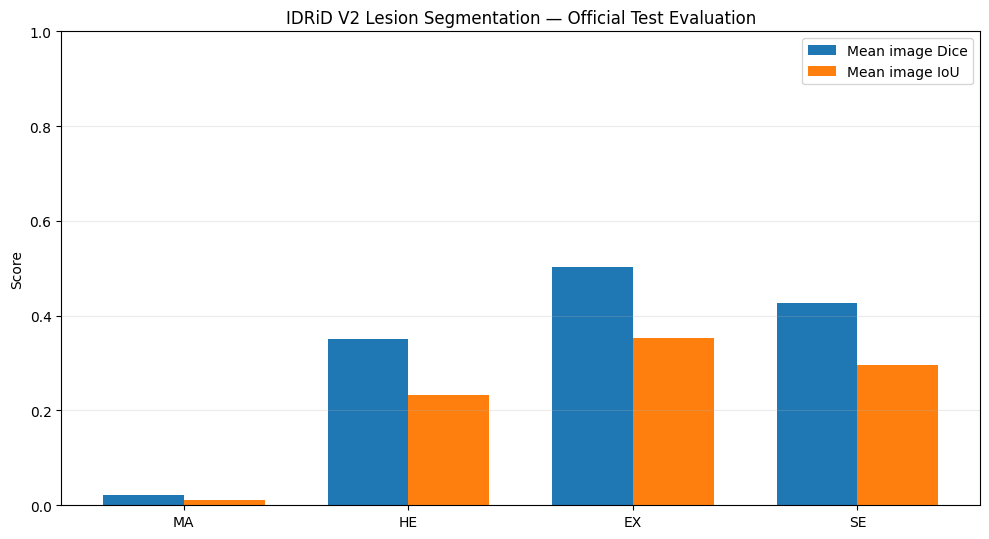


FINAL DELIVERABLES CREATED
FINAL_PROJECT_SUMMARY.md: OK | /content/drive/MyDrive/dr_baseline_run2/complete_project_output/FINAL_PROJECT_SUMMARY.md
lesion_test_performance.png: OK | /content/drive/MyDrive/dr_baseline_run2/complete_project_output/lesion_test_performance.png
official_test_metrics_v2.json: OK | /content/drive/MyDrive/dr_baseline_run2/complete_project_output/official_test_metrics_v2.json
major_project_deliverables.zip: OK | /content/drive/MyDrive/dr_baseline_run2/complete_project_output/major_project_deliverables.zip

Classifier metrics JSON loaded: True
V2 lesion test macro mean image Dice: 0.3255040488393169

The two model checkpoints remain unchanged.


In [ ]:

from pathlib import Path
import json
import zipfile
import subprocess
import sys
import matplotlib.pyplot as plt
import numpy as np

PROJECT = Path("/content/major-project-dr")
DRIVE = Path("/content/drive/MyDrive/dr_baseline_run2")
OUT = DRIVE / "complete_project_output"
OUT.mkdir(parents=True, exist_ok=True)

# Load the actual saved evaluation artifacts.
lesion_file = DRIVE / "lesion_evidence/official_test_metrics_v2.json"
classifier_file = DRIVE / "final_test_evaluation/final_test_metrics.json"
decision_file = OUT / "final_agentic_decision_report.json"

assert lesion_file.exists(), "V2 official test metrics are missing"
lesion_results = json.loads(lesion_file.read_text())

classifier_results = None
if classifier_file.exists():
    try:
        classifier_results = json.loads(classifier_file.read_text())
    except Exception as e:
        print("Could not parse classifier metrics:", e)

# Performance chart: actual official test results.
metrics = lesion_results["per_lesion_test_metrics"]
names = list(metrics.keys())
dice = [metrics[k]["mean_image_dice"] for k in names]
iou = [metrics[k]["mean_image_iou"] for k in names]

x = np.arange(len(names))
width = 0.36
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(x - width/2, dice, width, label="Mean image Dice")
ax.bar(x + width/2, iou, width, label="Mean image IoU")
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("IDRiD V2 Lesion Segmentation — Official Test Evaluation")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
chart = OUT / "lesion_test_performance.png"
fig.savefig(chart, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# Write a transparent consolidated results report.
rows = []
for code, values in metrics.items():
    rows.append(
        f"| {code} | {values['annotated_test_images']} | "
        f"{values['validation_selected_threshold']:.2f} | "
        f"{values['mean_image_dice']:.4f} | "
        f"{values['mean_image_iou']:.4f} | "
        f"{values['mean_image_precision']:.4f} | "
        f"{values['mean_image_recall']:.4f} |"
    )

summary = f"""# Major Project — Consolidated Research Results

## Project
A Multimodal Explainable Agentic AI Framework for Trustworthy Diabetic Retinopathy Diagnosis from Fundus Images.

## Classification baseline
The recorded classifier test results are:
- Accuracy: 72.25%
- Macro precision: 69.91%
- Macro recall: 68.99%
- Macro F1: 68.71%
- Test sample count: 2,144

These results describe the saved five-class classifier evaluation.

## Lesion segmentation
Model: LesionUNet V2
Dataset: IDRiD
Official test images: {lesion_results['test_image_count']}
Macro mean image Dice: {lesion_results['macro_mean_image_dice']:.4f}

| Lesion | Annotated test images | Validation threshold | Mean image Dice | Mean image IoU | Mean image precision | Mean image recall |
|---|---:|---:|---:|---:|---:|---:|
{chr(10).join(rows)}

Thresholds were selected on validation data. Official test annotations were not used for threshold selection during this V2 run.

## Integrated inference artifacts
- `integrated_evidence.png`: original fundus, Grad-CAM and lesion probability maps.
- `final_integrated_dashboard.png`: consolidated classifier and lesion evidence dashboard.
- `final_agentic_decision_report.json`: traceable model output and provisional review decision.
- `lesion_test_performance.png`: quantitative segmentation chart.

## Limitations and work still required
1. MA segmentation is weak (mean image Dice approximately 0.022).
2. The IDRiD segmentation sample is small; SE has 14 annotated test images.
3. Classifier confidence and entropy have not been shown to be clinically calibrated.
4. The agentic decision thresholds are heuristic, not clinically validated.
5. Clinical metadata fusion has not been verified as implemented.
6. Cross-dataset validation, ablation studies and a full reproducible end-to-end test suite must be documented separately before claiming the complete eight-phase methodology is validated.
7. This is a research prototype, not a clinical diagnostic system.

## Model artifacts
- Classifier checkpoint: `{DRIVE / 'best_checkpoint/model.pt'}`
- Lesion V2 checkpoint: `{DRIVE / 'lesion_evidence/best_lesion_unet_v2.pt'}`

The model checkpoints are stored separately in Google Drive and are not duplicated in the source package.
"""
summary_path = OUT / "FINAL_PROJECT_SUMMARY.md"
summary_path.write_text(summary, encoding="utf-8")

# Copy the official V2 metrics into the final deliverables folder.
(OUT / "official_test_metrics_v2.json").write_text(
    json.dumps(lesion_results, indent=2), encoding="utf-8"
)

# Package existing code and real outputs; leave checkpoints untouched.
source_files = [
    PROJECT / "dr_agentic.py",
    PROJECT / "dr_app.py",
    PROJECT / "lesion_evidence.py",
    PROJECT / "finetune_lesion_v2.py",
    PROJECT / "verify_final_deliverable.py",
    PROJECT / "PIPELINE_STATUS_HANDOFF.md",
]
output_files = [
    OUT / "integrated_project_report.json",
    OUT / "final_agentic_decision_report.json",
    OUT / "integrated_evidence.png",
    OUT / "final_integrated_dashboard.png",
    OUT / "official_test_metrics_v2.json",
    OUT / "lesion_test_performance.png",
    OUT / "FINAL_PROJECT_SUMMARY.md",
]

zip_path = OUT / "major_project_deliverables.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in source_files + output_files:
        if p.exists() and p.is_file():
            z.write(p, arcname=("source/" if p in source_files else "results/") + p.name)

print("\nFINAL DELIVERABLES CREATED")
for p in [summary_path, chart, OUT / "official_test_metrics_v2.json", zip_path]:
    print(f"{p.name}: {'OK' if p.exists() else 'MISSING'} | {p}")

print("\nClassifier metrics JSON loaded:", classifier_results is not None)
print("V2 lesion test macro mean image Dice:", lesion_results["macro_mean_image_dice"])
print("\nThe two model checkpoints remain unchanged.")


In [ ]:

from pathlib import Path
import subprocess
import sys
import zipfile
import json

PROJECT = Path("/content/major-project-dr")
DRIVE = Path("/content/drive/MyDrive/dr_baseline_run2")
OUT = DRIVE / "complete_project_output"

checks = {
    "DR classifier checkpoint":
        DRIVE / "best_checkpoint/model.pt",
    "Original lesion checkpoint":
        DRIVE / "lesion_evidence/best_lesion_unet.pt",
    "V2 lesion checkpoint":
        DRIVE / "lesion_evidence/best_lesion_unet_v2.pt",
    "Integrated evidence visualization":
        OUT / "integrated_evidence.png",
    "Integrated dashboard":
        OUT / "final_integrated_dashboard.png",
    "Agentic decision report":
        OUT / "final_agentic_decision_report.json",
    "V2 official test metrics":
        DRIVE / "lesion_evidence/official_test_metrics_v2.json",
    "Final project summary":
        OUT / "FINAL_PROJECT_SUMMARY.md",
    "Deliverables ZIP":
        OUT / "major_project_deliverables.zip",
}

print("=== ARTIFACT CHECK ===")
for name, path in checks.items():
    print(f"{'PASS' if path.is_file() else 'MISSING'} | {name}")

print("\n=== AUTOMATED TESTS ===")
test_dir = PROJECT / "tests"
if test_dir.is_dir():
    result = subprocess.run(
        [sys.executable, "-m", "pytest", "tests/", "-q"],
        cwd=PROJECT,
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
    )
    print(result.stdout[-12000:])
    print("Pytest exit code:", result.returncode)
else:
    print("Tests directory not found.")

print("\n=== PACKAGE CONTENTS ===")
zip_path = OUT / "major_project_deliverables.zip"
if zip_path.exists():
    with zipfile.ZipFile(zip_path) as archive:
        for name in archive.namelist():
            print(name)
        bad = archive.testzip()
        print("ZIP integrity:", "PASS" if bad is None else f"FAILED: {bad}")
else:
    print("Deliverables ZIP missing.")

print("\n=== MODEL METRICS ===")
metrics_path = DRIVE / "lesion_evidence/official_test_metrics_v2.json"
if metrics_path.exists():
    metrics = json.loads(metrics_path.read_text())
    print("Segmentation model:", metrics["model"])
    print("Test images:", metrics["test_image_count"])
    print("Macro mean image Dice:", metrics["macro_mean_image_dice"])


=== ARTIFACT CHECK ===
PASS | DR classifier checkpoint
PASS | Original lesion checkpoint
PASS | V2 lesion checkpoint
PASS | Integrated evidence visualization
PASS | Integrated dashboard
PASS | Agentic decision report
PASS | V2 official test metrics
PASS | Final project summary
PASS | Deliverables ZIP

=== AUTOMATED TESTS ===
_116.jpeg', '1.Dry AMD/Dry AMD102_right_0_2618.jpeg', '1.Dry AMD/Dry AMD102_right_0_3112.jpeg', '1.Dry AMD/Dry AMD102_right_0_4731.jpeg']

dataset/manifest.py:149: ImagePathDoesNotExistError
___________________ test_zenodo_counts_match_manifest_state ____________________

    def test_zenodo_counts_match_manifest_state():
>       rows = _eligible_rows()
               ^^^^^^^^^^^^^^^^

tests/test_split_generation.py:418: 
_ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ 
tests/test_split_generation.py:43: in _eligible_rows
    prim = load_manifest(PRIMARY_CSV, "primary", image_root=IMAGE_ROOT, require_files_exist=True)
           ^^^^

In [ ]:

from pathlib import Path

PROJECT = Path("/content/major-project-dr")

terms = [
    r"C:\Users\anous\Downloads\Diabetic Retinopathy and Retinal Diseases Fundus I",
    "IMAGE_ROOT",
    "image_root",
]

print("=== PATH REFERENCES IN TESTS AND DATASET CODE ===")
for folder in [PROJECT / "tests", PROJECT / "dataset"]:
    for path in folder.rglob("*.py"):
        try:
            lines = path.read_text(encoding="utf-8").splitlines()
        except Exception:
            continue

        matches = [
            (i, line.strip())
            for i, line in enumerate(lines, 1)
            if any(term.lower() in line.lower() for term in terms)
        ]
        if matches:
            print(f"\n{path.relative_to(PROJECT)}")
            for line_no, line in matches[:15]:
                print(f"  {line_no}: {line}")

print("\n=== DATASET ROOTS AVAILABLE IN COLAB ===")
for path in [
    Path("/content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I"),
    Path("/content/drive/MyDrive/DR_Dataset"),
]:
    print(f"{path}: exists={path.exists()}")


=== PATH REFERENCES IN TESTS AND DATASET CODE ===

tests/test_manifest.py
  19: IMAGE_ROOT = Path(r"C:\Users\anous\Downloads\Diabetic Retinopathy and Retinal Diseases Fundus I")
  73: rows = load_manifest(PRIMARY_CSV, "primary", image_root=IMAGE_ROOT)
  79: rows = load_manifest(SECONDARY_CSV, "secondary", image_root=IMAGE_ROOT)
  84: rows = load_manifest(PRIMARY_CSV, "primary", image_root=IMAGE_ROOT)
  91: rows = load_manifest(PRIMARY_CSV, "primary", image_root=IMAGE_ROOT)
  97: rows = load_manifest(SECONDARY_CSV, "secondary", image_root=IMAGE_ROOT)
  113: load_manifest(csv_path, "primary", image_root=tmp_path)
  120: load_manifest(csv_path, "primary", image_root=tmp_path)
  127: load_manifest(csv_path, "primary", image_root=tmp_path, require_files_exist=True)
  131: rows = load_manifest(PRIMARY_CSV, "primary", image_root=IMAGE_ROOT)
  138: rows = load_manifest(SECONDARY_CSV, "secondary", image_root=IMAGE_ROOT)

tests/test_colab_pipeline.py
  74: def _find_image_root():
  75: env = os.

In [ ]:

import os
import subprocess
import sys
from pathlib import Path

PROJECT = Path("/content/major-project-dr")
DATASET_ROOT = (
    "/content/drive/MyDrive/DR_Dataset/extracted/"
    "Diabetic Retinopathy and Retinal Diseases Fundus I"
)

assert Path(DATASET_ROOT).is_dir(), "Dataset root not found"

env = os.environ.copy()
env["DR_SMOKE_IMAGE_ROOT"] = DATASET_ROOT

print("Dataset root:", DATASET_ROOT)
print("\nRunning tests that previously failed because of Windows paths...\n")

result = subprocess.run(
    [
        sys.executable, "-m", "pytest", "-q",
        "tests/test_manifest.py",
        "tests/test_split_generation.py",
        "tests/test_grouping.py",
        "tests/test_eligibility.py",
        "tests/test_class_counts.py",
    ],
    cwd=PROJECT,
    env=env,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)
print(result.stdout)
print("Exit code:", result.returncode)


Dataset root: /content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I

Running tests that previously failed because of Windows paths...

...FF.....FFFFFFFFFFF.....FFFFF..............................            [100%]
=================================== FAILURES ===================================
____________________ test_primary_missing_files_integration ____________________

    def test_primary_missing_files_integration():
        rows = load_manifest(PRIMARY_CSV, "primary", image_root=IMAGE_ROOT)
        missing = [row["image_path"] for row in rows if not Path(row["_resolved"]).exists()]
>       assert not missing, f"Primary manifest references missing files: {missing[:5]}"
E       AssertionError: Primary manifest references missing files: ['1.Dry AMD/Dry AMD102_left_0_2130.jpeg', '1.Dry AMD/Dry AMD102_left_0_4925.jpeg', '1.Dry AMD/Dry AMD102_left_0_5317.jpeg', '1.Dry AMD/Dry AMD102_left_0_657.jpeg', '1.Dry AMD/Dry AMD102_left_0_9315.jpeg']
E 

In [ ]:

from pathlib import Path
import csv

PROJECT = Path("/content/major-project-dr")
DRIVE = Path("/content/drive/MyDrive")

target = "Dry AMD102_left_0_2130.jpeg"

print("=== SEARCH FOR SAMPLE IMAGE ===")
roots = [
    DRIVE / "DR_Dataset",
    Path("/content"),
]
found = []

for root in roots:
    if not root.exists():
        continue
    for path in root.rglob(target):
        found.append(path)
        print(path)
        if len(found) >= 10:
            break
    if found:
        break

if not found:
    print("Sample image not found in searched roots.")

print("\n=== MANIFEST PATH EXAMPLES ===")
manifest = PROJECT / "audit_output/pretraining_audit/PROVISIONAL_ELIGIBILITY_PRIMARY.csv"

with manifest.open(newline="", encoding="utf-8-sig") as f:
    reader = csv.DictReader(f)
    for _, row in zip(range(5), reader):
        print(row.get("image_path"))

print("\n=== DATASET TOP-LEVEL FOLDERS ===")
root = DRIVE / "DR_Dataset"
for p in root.iterdir():
    print(("DIR " if p.is_dir() else "FILE"), p.name)


=== SEARCH FOR SAMPLE IMAGE ===
/content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I/1.Dry AMD/Dry AMD102_left_0_2130.jpeg

=== MANIFEST PATH EXAMPLES ===
1.Dry AMD/Dry AMD102_left_0_2130.jpeg
1.Dry AMD/Dry AMD102_left_0_4925.jpeg
1.Dry AMD/Dry AMD102_left_0_5317.jpeg
1.Dry AMD/Dry AMD102_left_0_657.jpeg
1.Dry AMD/Dry AMD102_left_0_9315.jpeg

=== DATASET TOP-LEVEL FOLDERS ===
FILE Diabetic Retinopathy and Retinal Diseases Fundus I.zip
DIR  extracted
FILE A. Segmentation.zip
DIR  IDRiD_Segmentation


In [ ]:

from pathlib import Path
import shutil
import re
import subprocess
import sys

PROJECT = Path("/content/major-project-dr")
IMAGE_ROOT = Path(
    "/content/drive/MyDrive/DR_Dataset/extracted/"
    "Diabetic Retinopathy and Retinal Diseases Fundus I"
)

assert IMAGE_ROOT.is_dir()
assert (
    IMAGE_ROOT / "1.Dry AMD/Dry AMD102_left_0_2130.jpeg"
).is_file(), "Expected image was not found"

test_names = [
    "test_manifest.py",
    "test_grouping.py",
    "test_split_generation.py",
    "test_eligibility.py",
    "test_class_counts.py",
    "test_image_decoding.py",
]

backup_dir = PROJECT / "audit_output" / "test_path_backups"
backup_dir.mkdir(parents=True, exist_ok=True)

old_path = (
    r'C:\Users\anous\Downloads\Diabetic Retinopathy and Retinal Diseases Fundus I'
)
new_path = str(IMAGE_ROOT)

changed = []

for name in test_names:
    path = PROJECT / "tests" / name
    if not path.exists():
        continue

    source = path.read_text(encoding="utf-8")
    if old_path not in source:
        continue

    backup = backup_dir / name
    if not backup.exists():
        shutil.copy2(path, backup)

    updated = source.replace(old_path, new_path)
    path.write_text(updated, encoding="utf-8")
    changed.append(name)

print("Updated test files:", changed)
print("Backups:", backup_dir)

# Run the tests that were failing.
result = subprocess.run(
    [
        sys.executable, "-m", "pytest", "-q",
        "tests/test_manifest.py",
        "tests/test_split_generation.py",
        "tests/test_grouping.py",
        "tests/test_eligibility.py",
        "tests/test_class_counts.py",
        "tests/test_image_decoding.py",
    ],
    cwd=PROJECT,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)

print("\n=== TEST RESULTS ===")
print(result.stdout)
print("Exit code:", result.returncode)


Updated test files: ['test_manifest.py', 'test_grouping.py', 'test_split_generation.py', 'test_eligibility.py', 'test_class_counts.py', 'test_image_decoding.py']
Backups: /content/major-project-dr/audit_output/test_path_backups

=== TEST RESULTS ===
........................................................................ [100%]
72 passed in 145.64s (0:02:25)

Exit code: 0


In [ ]:
%cd /content/major-project-dr
!python -m pytest tests/ -q

/content/major-project-dr
......................................ssss.............................. [ 27%]
...........................sss.......................................... [ 54%]
........................................................................ [ 82%]
..............................................                           [100%]
255 passed, 7 skipped in 173.03s (0:02:53)


In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

paths = [
    Path('/content/major-project-dr'),
    Path('/content/drive/MyDrive/dr_baseline_run2'),
    Path('/content/drive/MyDrive/DR_Dataset'),
]

for path in paths:
    print(('FOUND' if path.exists() else 'NOT FOUND'), path)

Mounted at /content/drive
NOT FOUND /content/major-project-dr
FOUND /content/drive/MyDrive/dr_baseline_run2
FOUND /content/drive/MyDrive/DR_Dataset


In [2]:
from pathlib import Path

check_paths = [
    "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt",
    "/content/drive/MyDrive/dr_baseline_run2/final_test_evaluation/final_test_metrics.json",
    "/content/drive/MyDrive/dr_baseline_run2/lesion_evidence/best_lesion_unet.pt",
    "/content/drive/MyDrive/dr_baseline_run2/lesion_evidence/best_lesion_unet_v2.pt",
    "/content/drive/MyDrive/dr_baseline_run2/lesion_evidence/official_test_metrics_v2.json",
]

for item in check_paths:
    p = Path(item)
    if p.is_file():
        print(f"FOUND | {p.name} | {p.stat().st_size / (1024**2):.2f} MB")
    else:
        print(f"MISSING | {p}")

FOUND | model.pt | 90.10 MB
FOUND | final_test_metrics.json | 0.00 MB
FOUND | best_lesion_unet.pt | 24.11 MB
FOUND | best_lesion_unet_v2.pt | 24.11 MB
FOUND | official_test_metrics_v2.json | 0.00 MB


In [3]:
from pathlib import Path
import subprocess

repo_url = "https://github.com/anoushka24dev/major-project-dr"
repo_dir = Path("/content/major-project-dr-recovered")

if repo_dir.exists():
    print("Recovery folder already exists — not overwriting it.")
else:
    result = subprocess.run(
        ["git", "clone", repo_url, str(repo_dir)],
        capture_output=True, text=True
    )
    print(result.stdout)
    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError("Clone failed. Your Drive checkpoints were not changed.")

print("\n=== RECOVERED PROJECT FILES ===")
for p in sorted(repo_dir.iterdir()):
    print(p.name)

print("\n=== CHECKPOINTS REMAIN IN DRIVE ===")
for p in [
    Path("/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt"),
    Path("/content/drive/MyDrive/dr_baseline_run2/lesion_evidence/best_lesion_unet_v2.pt"),
]:
    print(("FOUND" if p.exists() else "MISSING"), p.name)



=== RECOVERED PROJECT FILES ===
.freebuff
.git
.gitignore
PIPELINE_STATUS_HANDOFF.md
audit_output
colab
cpu_canary_run.log
dataset
pending_decisions.md
provisional_primary_split
requirements.txt
tests
verify_final_deliverable.py

=== CHECKPOINTS REMAIN IN DRIVE ===
FOUND model.pt
FOUND best_lesion_unet_v2.pt


In [4]:
from pathlib import Path
import json

drive = Path("/content/drive/MyDrive/dr_baseline_run2")
repo = Path("/content/major-project-dr-recovered")

files = [
    drive / "final_test_evaluation/final_test_metrics.json",
    drive / "lesion_evidence/official_test_metrics_v2.json",
    repo / "PIPELINE_STATUS_HANDOFF.md",
    repo / "pending_decisions.md",
]

for path in files:
    print("\n" + "=" * 70)
    print("FILE:", path.name)
    print("EXISTS:", path.is_file())

    if not path.is_file():
        continue

    if path.suffix == ".json":
        try:
            data = json.loads(path.read_text())
            print(json.dumps(data, indent=2)[:12000])
        except Exception as e:
            print("Could not read JSON:", e)
    else:
        print(path.read_text(errors="replace")[:12000])

print("\n" + "=" * 70)
print("POSSIBLE TRAINING / EVALUATION FILES")
for folder in [repo / "colab", repo / "dataset", drive]:
    if folder.exists():
        print(f"\n[{folder}]")
        matches = [
            p for p in folder.rglob("*")
            if p.is_file()
            and p.suffix.lower() in {".py", ".ipynb", ".yaml", ".yml", ".json"}
            and not any(x in p.parts for x in [".git", "__pycache__"])
        ]
        for p in matches[:40]:
            print(p)


FILE: final_test_metrics.json
EXISTS: True
{
  "partition": "test",
  "split_source": "/content/major-project-dr/provisional_primary_split",
  "checkpoint_dir": "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint",
  "checkpoint_epoch": 6,
  "best_epoch": 6,
  "best_val_loss": 0.5939337033088561,
  "image_size": 224,
  "device": "cuda",
  "band_order": [
    "No apparent DR",
    "Mild NPDR",
    "Moderate NPDR",
    "Severe NPDR",
    "PDR"
  ],
  "accuracy": 0.722481343283582,
  "macro_precision": 0.6990719240305301,
  "macro_recall": 0.6898813652999178,
  "macro_f1": 0.6871441228287736,
  "per_class": {
    "No apparent DR": {
      "precision": 0.9932126696832579,
      "recall": 0.9799107142857143,
      "f1": 0.9865168539325843,
      "support": 448,
      "predicted": 442,
      "tp": 439
    },
    "Mild NPDR": {
      "precision": 0.5261194029850746,
      "recall": 0.3863013698630137,
      "f1": 0.44549763033175355,
      "support": 365,
      "predicted": 268,
      "

In [5]:
from pathlib import Path
import json

drive = Path("/content/drive/MyDrive/dr_baseline_run2")
repo = Path("/content/major-project-dr-recovered")

# Read saved run information
for name in [
    "run_meta.json",
    "run_summary.json",
    "run_manifest.json",
    "best_checkpoint/training_state.json",
]:
    p = drive / name
    print(f"\n{'='*60}\n{name}")
    if p.exists():
        try:
            data = json.loads(p.read_text())
            print(json.dumps(data, indent=2)[:6000])
        except Exception as e:
            print("Read error:", e)
    else:
        print("Not found")

# Inspect the training script
p = repo / "colab/train.py"
print(f"\n{'='*60}\nTRAINING SCRIPT: {p}")
if p.exists():
    lines = p.read_text(errors="replace").splitlines()
    keywords = [
        "CrossEntropyLoss", "WeightedRandomSampler", "class_weight",
        "weight_decay", "learning_rate", "lr=", "Adam", "SGD",
        "freeze", "requires_grad", "scheduler", "epochs", "batch_size",
        "train_test_split", "RandomResizedCrop", "RandomHorizontalFlip"
    ]
    for i, line in enumerate(lines):
        if any(k.lower() in line.lower() for k in keywords):
            start, end = max(0, i-2), min(len(lines), i+3)
            print(f"\n--- lines {start+1}-{end} ---")
            for j in range(start, end):
                print(f"{j+1}: {lines[j]}")
else:
    print("Training script not found")


run_meta.json
{
  "task": "primary_five_band_provisional",
  "model": "resnet50_frozen",
  "split_dir": "/content/major-project-dr/provisional_primary_split",
  "dataset_root": "/content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I",
  "output_dir": "/content/drive/MyDrive/dr_baseline_run2",
  "epochs": 10,
  "batch_size": 32,
  "lr": 0.001,
  "weight_decay": 0.0001,
  "patience": 3,
  "image_size": 224,
  "seed": 12345,
  "device": "cuda",
  "num_classes": 5,
  "band_order": [
    "No apparent DR",
    "Mild NPDR",
    "Moderate NPDR",
    "Severe NPDR",
    "PDR"
  ],
  "preprocessing": "resize_and_pad+imagenet_normalize",
  "crops": "none",
  "class_weights_source": "train_partition_only",
  "train_size": 9924,
  "val_size": 2133,
  "runtime": {
    "torch_version": "2.11.0+cu130",
    "cuda_available": true,
    "device": "cuda",
    "cuda_device_name": "NVIDIA A100-SXM4-40GB",
    "cuda_device_count": 1
  },
  "provisional_note": "Provisio

In [6]:
from pathlib import Path

repo = Path("/content/major-project-dr-recovered")

for filename in ["colab/train.py", "colab/pipeline.py"]:
    p = repo / filename
    print("\n" + "=" * 65)
    print("FILE:", p)

    if p.exists():
        lines = p.read_text(errors="replace").splitlines()
        keywords = [
            "resnet50", "requires_grad", "CrossEntropyLoss",
            "class_weights", "optimizer", "scheduler",
            "transform", "Normalize", "Resize", "train_loader",
            "val_loader", "best_val_loss", "patience"
        ]

        printed = set()
        for i, line in enumerate(lines):
            if any(k.lower() in line.lower() for k in keywords):
                for j in range(max(0, i - 2), min(len(lines), i + 3)):
                    if j not in printed:
                        print(f"{j+1}: {lines[j]}")
                        printed.add(j)
    else:
        print("File not found")


FILE: /content/major-project-dr-recovered/colab/train.py
14: It DOES:
15: - load the existing split CSV unchanged;
16: - use deterministic, aspect-ratio-preserving resize-and-pad preprocessing;
17: - apply ImageNet normalization;
18: - compute class weights from training labels only;
35: marked with ``TRAINING_INCOMPLETE.txt`` and its manifest is set to
36: ``"incomplete"``; that run must be restarted from scratch. Per-epoch checkpoints
37: and optimizer state are still written, so a future resume implementation has the
38: state it needs, but this version does not claim to resume.
39: 
70:     BAND_ORDER,
71:     assert_head_is_trainable,
72:     build_frozen_resnet50,
73:     default_normalize,
74:     filter_by_partition,
75:     load_rgb,
80: )
81: 
82: IMAGENET_MEAN, IMAGENET_STD = default_normalize()
83: 
84: RUN_META_NAME = "run_meta.json"
107: 
108: 
109: def _normalize(
110:     tensor: torch.Tensor,
111:     mean: Sequence[float],
125:     """PyTorch dataset over one partiti

In [7]:
from pathlib import Path

repo = Path("/content/major-project-dr-recovered")

# Find the exact model-builder definition
for p in repo.rglob("*.py"):
    try:
        lines = p.read_text(errors="replace").splitlines()
    except Exception:
        continue

    matches = [
        i for i, line in enumerate(lines)
        if "def build_frozen_resnet50" in line
        or "def assert_head_is_trainable" in line
    ]

    for i in matches:
        print(f"\n{'='*60}\nFILE: {p}")
        for j in range(max(0, i-5), min(len(lines), i+65)):
            print(f"{j+1}: {lines[j]}")


FILE: /content/major-project-dr-recovered/colab/colab_helpers.py
275:         return any(exact.parent.glob("resnet50-*.pth"))
276:     except Exception:
277:         return False
278: 
279: 
280: def build_frozen_resnet50(
281:     num_classes: int = 5,
282:     *,
283:     allow_download: bool = False,
284:     pretrained: bool = True,
285: ):
286:     """Build a ResNet-50 with frozen backbone and a new ``num_classes`` head.
287: 
288:     Requires ``torch`` and ``torchvision`` to be importable.
289: 
290:     Parameters
291:     ----------
292:     num_classes:
293:         Number of output logits for the new classification head.
294:     allow_download:
295:         Only meaningful when ``pretrained=True``. When False (the default), this
296:         raises a clear error if the ImageNet weights are not already present in the
297:         local torch cache, so the pipeline never silently starts a network download.
298:         Set True to permit torchvision to download the weights.


In [8]:
import json
from pathlib import Path

out = Path("/content/drive/MyDrive/dr_baseline_run2")

# Read the compact resume state first
for filename in ["resume_state.json", "run_manifest.json"]:
    p = out / filename
    print(f"\n--- {filename} ---")

    if p.exists():
        data = json.loads(p.read_text())
        print(json.dumps(data, indent=2)[:10000])
    else:
        print("Not found")

# Extract history from the training-state checkpoint
p = out / "best_checkpoint" / "training_state.json"
print("\n--- Training history ---")

if p.exists():
    data = json.loads(p.read_text())
    for key in ["train_history", "val_history"]:
        print(f"\n{key}:")
        print(json.dumps(data.get(key, []), indent=2)[:12000])
else:
    print("Training-state JSON not found at this path.")


--- resume_state.json ---
{
  "epochs_completed": 10,
  "state": {
    "epoch": 9,
    "best_val_loss": 0.5939337033088561,
    "best_epoch": 6,
    "patience_counter": 3,
    "train_history": [
      {
        "loss": 0.8983147841266739,
        "num_samples": 9924,
        "epoch": 0,
        "epoch_time_seconds": 4044.342814683914
      },
      {
        "loss": 0.7206379375550017,
        "num_samples": 9924,
        "epoch": 1,
        "epoch_time_seconds": 263.56632375717163
      },
      {
        "loss": 0.6899764694931141,
        "num_samples": 9924,
        "epoch": 2,
        "epoch_time_seconds": 261.75105929374695
      },
      {
        "loss": 0.6630864742601269,
        "num_samples": 9924,
        "epoch": 3,
        "epoch_time_seconds": 266.6443212032318
      },
      {
        "loss": 0.6393044248841934,
        "num_samples": 9924,
        "epoch": 4,
        "epoch_time_seconds": 267.0730016231537
      },
      {
        "loss": 0.6312148650775558,
        

In [9]:
from pathlib import Path
import pandas as pd

repo = Path("/content/major-project-dr-recovered")

print("Split files:")
for p in repo.rglob("*.csv"):
    if "split" in str(p).lower() or "manifest" in p.name.lower():
        print(p)

print("\nClass mapping in source code:")
for p in repo.rglob("*.py"):
    if p.name == "labels.py":
        print(f"\n--- {p} ---")
        print(p.read_text(errors="replace")[:10000])

Split files:
/content/major-project-dr-recovered/provisional_primary_split/provisional_primary_split.csv
/content/major-project-dr-recovered/colab/_canary_test_outputs/canary_provisional_split.csv
/content/major-project-dr-recovered/colab/kaggle_notebook_docs/provisional_primary_split.csv
/content/major-project-dr-recovered/colab/_canary_split/canary_split/provisional_primary_split.csv
/content/major-project-dr-recovered/audit_output/pretraining_audit/PROVENANCE_MANIFEST.csv

Class mapping in source code:

--- /content/major-project-dr-recovered/dataset/labels.py ---
"""Label mapping for the provisional primary and secondary tasks.

This module is explicit and deterministic. Unknown source labels are rejected
rather than silently mapped to a default class.

Notes
-----
The primary mapping reflects the provisional approval recorded in
``audit_output/pretraining_audit/LABEL_POLICY_DRAFT.md``. The merges
(Very Severe NPDR -> Severe NPDR, Advanced PDR -> PDR) are provisional, and
original 

In [10]:
import pandas as pd
from pathlib import Path

p = Path(
    "/content/major-project-dr-recovered/"
    "provisional_primary_split/provisional_primary_split.csv"
)

df = pd.read_csv(p)

print("Rows:", len(df))
print("Columns:", df.columns.tolist())

for col in df.columns:
    if any(word in col.lower() for word in
           ["class", "label", "partition", "split", "source"]):
        print(f"\n--- {col} ---")
        print(df[col].value_counts(dropna=False).to_string())

print("\nDuplicate rows:", df.duplicated().sum())

Rows: 14201
Columns: ['image_path', 'task', 'partition', 'primary_class', 'group_id', 'source_family', 'patient_key_available', 'zenodo_unlinked', 'eligibility_snapshot', 'manifest_version', 'split_seed']

--- partition ---
partition
train         9924
test          2144
validation    2133

--- primary_class ---
primary_class
Moderate NPDR     5303
No apparent DR    2973
Mild NPDR         2436
Severe NPDR       1971
PDR               1518

--- source_family ---
source_family
plain         10556
prefixed       3142
zenodo_v02      503

--- split_seed ---
split_seed
12345    14201

Duplicate rows: 0


In [11]:
import pandas as pd
from pathlib import Path

p = Path(
    "/content/major-project-dr-recovered/"
    "provisional_primary_split/provisional_primary_split.csv"
)

df = pd.read_csv(p)

print("Source family vs target class:")
print(pd.crosstab(df["source_family"], df["primary_class"]))

print("\nImage paths by partition:")
print(pd.crosstab(df["partition"], df["source_family"]))

print("\nPatient key availability:")
print(pd.crosstab(df["partition"], df["patient_key_available"]))

print("\nSample rows:")
print(df[[
    "image_path", "partition", "primary_class",
    "source_family", "patient_key_available"
]].head(10).to_string(index=False))

Source family vs target class:
primary_class  Mild NPDR  Moderate NPDR  No apparent DR   PDR  Severe NPDR
source_family                                                             
plain               2432           5250            2874     0            0
prefixed               0              0               0  1406         1736
zenodo_v02             4             53              99   112          235

Image paths by partition:
source_family  plain  prefixed  zenodo_v02
partition                                 
test            1577       479          88
train           7391      2191         342
validation      1588       472          73

Patient key availability:
patient_key_available  False  True 
partition                          
test                      88   2056
train                    342   9582
validation                73   2060

Sample rows:
                      image_path  partition  primary_class source_family  patient_key_available
   11.Normal Fundus/0_right.jpeg   

In [12]:
import pandas as pd
from pathlib import Path

p = Path(
    "/content/major-project-dr-recovered/"
    "provisional_primary_split/provisional_primary_split.csv"
)
df = pd.read_csv(p)

print("Unique group IDs:", df["group_id"].nunique())
print("\nGroups appearing in multiple partitions:")
group_partitions = df.groupby("group_id")["partition"].nunique()
print("Groups in multiple partitions:", int((group_partitions > 1).sum()))

print("\nGroup ID examples:")
print(df[["group_id", "partition", "primary_class"]].head(15).to_string(index=False))

print("\nRepeated image paths:", int(df["image_path"].duplicated().sum()))

print("\nSource-family class proportions:")
print(pd.crosstab(
    df["source_family"],
    df["primary_class"],
    normalize="index"
).round(3))

Unique group IDs: 14143

Groups appearing in multiple partitions:
Groups in multiple partitions: 0

Group ID examples:
                        group_id  partition  primary_class
   11.Normal Fundus/0_right.jpeg      train No apparent DR
          11.Normal Fundus/1.jpg       test No apparent DR
         11.Normal Fundus/10.jpg      train No apparent DR
11.Normal Fundus/1005_right.jpeg      train No apparent DR
 11.Normal Fundus/1006_left.jpeg validation No apparent DR
 11.Normal Fundus/1008_left.jpeg       test No apparent DR
 11.Normal Fundus/100_right.jpeg validation No apparent DR
        11.Normal Fundus/101.jpg      train No apparent DR
 11.Normal Fundus/1010_left.jpeg      train No apparent DR
 11.Normal Fundus/1011_left.jpeg      train No apparent DR
 11.Normal Fundus/1013_left.jpeg      train No apparent DR
11.Normal Fundus/1014_right.jpeg validation No apparent DR
 11.Normal Fundus/1016_left.jpeg      train No apparent DR
11.Normal Fundus/1018_right.jpeg      train No apparent

In [15]:
import pandas as pd
import hashlib
from pathlib import Path
from collections import defaultdict

csv_path = Path(
    "/content/major-project-dr-recovered/"
    "provisional_primary_split/provisional_primary_split.csv"
)

# Use the same dataset root recorded in your training metadata.
dataset_root = Path(
    "/content/drive/MyDrive/DR_Dataset/extracted/"
    "Diabetic Retinopathy and Retinal Diseases Fundus I"
)

df = pd.read_csv(csv_path)
hash_to_rows = defaultdict(list)
missing = []

for _, row in df.iterrows():
    image_path = dataset_root / row["image_path"]

    if not image_path.is_file():
        missing.append(str(image_path))
        continue

    digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
    hash_to_rows[digest].append({
        "path": row["image_path"],
        "partition": row["partition"],
        "class": row["primary_class"],
        "source": row["source_family"],
    })

duplicate_groups = [
    rows for rows in hash_to_rows.values() if len(rows) > 1
]

cross_partition = [
    rows for rows in duplicate_groups
    if len({r["partition"] for r in rows}) > 1
]

print("CSV rows:", len(df))
print("Files missing:", len(missing))
print("Unique file hashes:", len(hash_to_rows))
print("Duplicate-content groups:", len(duplicate_groups))
print("Duplicate groups crossing partitions:", len(cross_partition))

for rows in cross_partition[:10]:
    print("\n", rows)

KeyboardInterrupt: 

In [16]:
from pathlib import Path

drive = Path("/content/drive/MyDrive/dr_baseline_run2")

checks = [
    drive / "best_checkpoint/model.pt",
    drive / "lesion_evidence/best_lesion_unet.pt",
    drive / "lesion_evidence/best_lesion_unet_v2.pt",
    drive / "final_test_evaluation/final_test_metrics.json",
]

for p in checks:
    print(("✅ FOUND  " if p.is_file() else "❌ MISSING ") + str(p))

✅ FOUND  /content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt
✅ FOUND  /content/drive/MyDrive/dr_baseline_run2/lesion_evidence/best_lesion_unet.pt
✅ FOUND  /content/drive/MyDrive/dr_baseline_run2/lesion_evidence/best_lesion_unet_v2.pt
✅ FOUND  /content/drive/MyDrive/dr_baseline_run2/final_test_evaluation/final_test_metrics.json


In [17]:
from pathlib import Path

repo = Path("/content/major-project-dr-recovered")

for name in ["dr_app.py", "dr_agentic.py", "lesion_evidence.py"]:
    matches = list(repo.rglob(name))
    print(f"\n{name}:")
    if matches:
        for p in matches[:5]:
            print(" ", p)
    else:
        print(" NOT FOUND")


dr_app.py:
 NOT FOUND

dr_agentic.py:
 NOT FOUND

lesion_evidence.py:
 NOT FOUND


In [18]:
from pathlib import Path

repo = Path("/content/major-project-dr-recovered")

print("=== PROJECT FOLDERS ===")
for p in sorted(repo.iterdir()):
    print(p.name, "/" if p.is_dir() else "")

print("\n=== PYTHON FILES ===")
count = 0
for p in repo.rglob("*.py"):
    if ".git" not in p.parts and "venv" not in p.parts:
        print(p.relative_to(repo))
        count += 1
        if count >= 80:
            print("Showing first 80 files only.")
            break

if count == 0:
    print("No Python files found.")

=== PROJECT FOLDERS ===
.freebuff /
.git /
.gitignore 
PIPELINE_STATUS_HANDOFF.md 
audit_output /
colab /
cpu_canary_run.log 
dataset /
pending_decisions.md 
provisional_primary_split /
requirements.txt 
tests /
verify_final_deliverable.py 

=== PYTHON FILES ===
verify_final_deliverable.py
audit_output/v03_internal.py
audit_output/v03_pixel_verify.py
audit_output/scan_images.py
audit_output/v03_final_quantify.py
audit_output/v03_compare.py
audit_output/analyze.py
audit_output/v03_perceptual.py
colab/train.py
colab/cpu_train.py
colab/smoke_test.py
colab/setup_helpers.py
colab/pipeline.py
colab/colab_helpers.py
dataset/__init__.py
dataset/split_validation.py
dataset/statistics.py
dataset/split_protocol.py
dataset/manifest.py
dataset/labels.py
dataset/grouping.py
dataset/decoding.py
dataset/eligibility.py
tests/test_split_generation.py
tests/test_cpu_train.py
tests/test_colab_pipeline.py
tests/test_label_mapping.py
tests/test_fixed_notebook_setup.py
tests/test_canary_split.py
tests/test_p

In [19]:
from pathlib import Path

repo = Path("/content/major-project-dr-recovered")

for filename in ["colab/train.py", "colab/pipeline.py", "dataset/labels.py"]:
    path = repo / filename
    print(f"\n{'='*20} {filename} {'='*20}")
    if path.exists():
        print(path.read_text()[:10000])
    else:
        print("File not found")


==================== colab/train.py ====================
"""
Minimal, guarded frozen ResNet-50 training pipeline for the provisional primary
five-band diabetic-retinopathy task.

This module is deliberately small and defensive. It does NOT:
- modify the existing dataset, split CSV, split report, or audit artifacts;
- regenerate, reshuffle, or alter the existing train/validation/test assignment;
- use center crops or random crops at any stage;
- train on, tune on, early-stop on, or select checkpoints using the test partition;
- download pretrained weights or install packages without an explicit opt-in;
- silently overwrite a previous run, or present an incomplete run as completed;
- claim clinical validity, GPU execution, or Colab compatibility.

It DOES:
- load the existing split CSV unchanged;
- use deterministic, aspect-ratio-preserving resize-and-pad preprocessing;
- apply ImageNet normalization;
- compute class weights from training labels only;
- train only on the training partit

In [20]:
from pathlib import Path

p = Path("/content/major-project-dr-recovered/colab/colab_helpers.py")
print("File exists:", p.exists())

if p.exists():
    lines = p.read_text().splitlines()
    for i, line in enumerate(lines):
        if "BAND_ORDER" in line or "def build_frozen_resnet50" in line or "def preprocessing_inference" in line:
            print(f"\n--- Lines {i+1}–{min(i+20, len(lines))} ---")
            print("\n".join(lines[i:min(i+20, len(lines))]))

File exists: True

--- Lines 28–47 ---
BAND_ORDER = [
    "No apparent DR",
    "Mild NPDR",
    "Moderate NPDR",
    "Severe NPDR",
    "PDR",
]

# ---------------------------------------------------------------------------
# Path resolution
# ---------------------------------------------------------------------------

DATASET_ENV = "DR_FUNDUS_ROOT"
SPLIT_DIR_ENV = "DR_SPLIT_DIR"

DATASET_DIR_NAME = "Diabetic Retinopathy and Retinal Diseases Fundus I"


def resolve_dataset_root() -> Path:
    """Return the dataset root directory for the uploaded project.

--- Lines 200–219 ---
def preprocessing_inference(source_size: int = 224):
    """Deterministic preprocessing for validation and test partitions."""
    from PIL import Image  # noqa: F401

    def _apply(image):
        return _resize_and_pad(image, source_size, source_size)

    return _apply


def preprocessing_inference_factory(source_size: int = 224):
    """Alias of :func:`preprocessing_inference` for notebook-facing calls."""


In [21]:
import torch
from pathlib import Path

ckpt_path = Path(
    "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt"
)

print("Checkpoint exists:", ckpt_path.is_file())

checkpoint = torch.load(
    ckpt_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Top-level keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"\n{key}:")
            for name, tensor in list(value.items())[:8]:
                if hasattr(tensor, "shape"):
                    print(f"  {name}: {tuple(tensor.shape)}")
                else:
                    print(f"  {name}: {type(tensor).__name__}")
        elif hasattr(value, "shape"):
            print(f"{key}: shape={tuple(value.shape)}")
        else:
            print(f"{key}: {type(value).__name__}")

Checkpoint exists: True


UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL torch.torch_version.TorchVersion was not an allowed global by default. Please use `torch.serialization.add_safe_globals([torch.torch_version.TorchVersion])` or the `torch.serialization.safe_globals([torch.torch_version.TorchVersion])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.load 

In [22]:
import torch
from pathlib import Path
from torch.serialization import safe_globals
from torch.torch_version import TorchVersion

ckpt_path = Path(
    "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt"
)

print("Checkpoint exists:", ckpt_path.is_file())

with safe_globals([TorchVersion]):
    checkpoint = torch.load(
        ckpt_path,
        map_location="cpu",
        weights_only=True
    )

print("\nLoaded successfully!")
print("Checkpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Top-level keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"\n{key}:")
            for name, tensor in list(value.items())[:8]:
                if hasattr(tensor, "shape"):
                    print(f"  {name}: {tuple(tensor.shape)}")
                else:
                    print(f"  {name}: {type(tensor).__name__}")
        elif hasattr(value, "shape"):
            print(f"{key}: shape={tuple(value.shape)}")
        else:
            print(f"{key}: {type(value).__name__}")

Checkpoint exists: True

Loaded successfully!
Checkpoint type: dict
Top-level keys: ['model_state_dict', 'optimizer_state_dict', 'epoch', 'config', 'collab_compat']

model_state_dict:
  conv1.weight: (64, 3, 7, 7)
  bn1.weight: (64,)
  bn1.bias: (64,)
  bn1.running_mean: (64,)
  bn1.running_var: (64,)
  bn1.num_batches_tracked: ()
  layer1.0.conv1.weight: (64, 64, 1, 1)
  layer1.0.bn1.weight: (64,)

optimizer_state_dict:
  state: dict
  param_groups: list
epoch: int

config:
  task: str
  model: str
  split_dir: str
  dataset_root: str
  output_dir: str
  epochs: int
  batch_size: int
  lr: float

collab_compat:
  torchvision_version_marker: str
  head_class_count: int
  band_order: list
  preprocessing: dict


In [23]:
print("=== MODEL CONFIGURATION ===")
for key, value in checkpoint["config"].items():
    print(f"{key}: {value}")

print("\n=== CHECKPOINT COMPATIBILITY ===")
for key, value in checkpoint["collab_compat"].items():
    print(f"{key}: {value}")

print("\n=== CLASSIFIER OUTPUT LAYER ===")
for key, value in checkpoint["model_state_dict"].items():
    if key.startswith("fc."):
        print(key, tuple(value.shape))

=== MODEL CONFIGURATION ===
task: primary_five_band_provisional
model: resnet50_frozen
split_dir: /content/major-project-dr/provisional_primary_split
dataset_root: /content/drive/MyDrive/DR_Dataset/extracted/Diabetic Retinopathy and Retinal Diseases Fundus I
output_dir: /content/drive/MyDrive/dr_baseline_run2
epochs: 10
batch_size: 32
lr: 0.001
weight_decay: 0.0001
patience: 3
image_size: 224
seed: 12345
device: cuda
num_classes: 5
band_order: ['No apparent DR', 'Mild NPDR', 'Moderate NPDR', 'Severe NPDR', 'PDR']
preprocessing: resize_and_pad+imagenet_normalize
crops: none
class_weights_source: train_partition_only
train_size: 9924
val_size: 2133
runtime: {'torch_version': '2.11.0+cu130', 'cuda_available': True, 'device': 'cuda', 'cuda_device_name': 'NVIDIA A100-SXM4-40GB', 'cuda_device_count': 1}
provisional_note: Provisional five-band mapping. Not a clinical result. Severe NPDR includes Very Severe NPDR; PDR includes Advanced PDR.
resume_supported: True
resume: False
class_weights: {

In [24]:
from pathlib import Path

repo = Path("/content/major-project-dr-recovered")
app_path = repo / "dr_app.py"

app_code = r'''
import sys
from pathlib import Path

import gradio as gr
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

REPO = Path("/content/major-project-dr-recovered")
CHECKPOINT = Path(
    "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt"
)

sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / "colab"))

from colab_helpers import (
    BAND_ORDER,
    build_frozen_resnet50,
    preprocessing_inference,
    default_normalize,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MEAN, STD = default_normalize()
PREPROCESS = preprocessing_inference(224)

def load_model():
    from torch.serialization import safe_globals
    from torch.torch_version import TorchVersion

    with safe_globals([TorchVersion]):
        checkpoint = torch.load(
            CHECKPOINT,
            map_location="cpu",
            weights_only=True,
        )

    if checkpoint["collab_compat"]["band_order"] != BAND_ORDER:
        raise ValueError("Checkpoint class order does not match app class order.")

    model = build_frozen_resnet50(
        num_classes=5,
        pretrained=False,
        allow_download=False,
    )
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.to(DEVICE)
    model.eval()
    return model

MODEL = load_model()

def predict(image):
    if image is None:
        return "Please upload a fundus image.", None, None

    image = image.convert("RGB")
    processed = PREPROCESS(image)
    arr = np.asarray(processed, dtype=np.float32) / 255.0
    tensor = torch.from_numpy(arr.transpose(2, 0, 1).copy()).float()

    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    tensor = ((tensor - mean) / std).unsqueeze(0).to(DEVICE)

    # Grad-CAM: use the final ResNet feature block.
    activations = {}
    gradients = {}

    def save_activation(module, inputs, output):
        activations["value"] = output
        output.register_hook(
            lambda grad: gradients.__setitem__("value", grad)
        )

    layer = MODEL.layer4
    handle = layer.register_forward_hook(save_activation)

    try:
        MODEL.zero_grad(set_to_none=True)
        tensor.requires_grad_(True)
        logits = MODEL(tensor)
        probabilities = torch.softmax(logits, dim=1)
        class_index = int(logits.argmax(dim=1).item())
        logits[0, class_index].backward()

        scores = probabilities[0].detach().cpu().numpy()
        activation = activations["value"].detach()
        gradient = gradients["value"].detach()

        weights = gradient.mean(dim=(2, 3), keepdim=True)
        cam = (weights * activation).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = F.interpolate(
            cam,
            size=(224, 224),
            mode="bilinear",
            align_corners=False,
        )[0, 0]
        cam = cam.cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        # Overlay a heatmap on the resized fundus image.
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt

        fig, ax = plt.subplots(figsize=(6, 6))
        ax.imshow(processed)
        ax.imshow(cam, cmap="jet", alpha=0.4, vmin=0, vmax=1)
        ax.axis("off")
        ax.set_title("Grad-CAM — model attention visualization")
        fig.tight_layout()

        import io
        buffer = io.BytesIO()
        fig.savefig(buffer, format="png", bbox_inches="tight", dpi=120)
        plt.close(fig)
        buffer.seek(0)
        heatmap = Image.open(buffer).convert("RGB").copy()

        label = BAND_ORDER[class_index]
        confidence = float(scores[class_index]) * 100
        report = (
            f"**Predicted grade:** {label}\n\n"
            f"**Model confidence score:** {confidence:.2f}%\n\n"
            "This is an experimental model output, not a clinical diagnosis. "
            "The score is not necessarily calibrated, and Grad-CAM is a "
            "visualization—not proof of a lesion or clinical reasoning."
        )

        class_scores = {
            BAND_ORDER[i]: float(scores[i]) for i in range(len(BAND_ORDER))
        }
        return report, class_scores, heatmap

    finally:
        handle.remove()

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil", label="Upload a retinal fundus image"),
    outputs=[
        gr.Markdown(label="Prediction"),
        gr.Label(num_top_classes=5, label="Scores for all five classes"),
        gr.Image(type="pil", label="Grad-CAM visualization"),
    ],
    title="Explainable Diabetic Retinopathy Demo",
    description=(
        "Research prototype using the saved five-class ResNet-50 checkpoint. "
        "For research demonstration only; not for medical decisions."
    ),
)

if __name__ == "__main__":
    demo.launch(share=True)
'''

app_path.write_text(app_code, encoding="utf-8")
print("Created:", app_path)
print("Checkpoint preserved:",
      Path("/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt").is_file())

Created: /content/major-project-dr-recovered/dr_app.py
Checkpoint preserved: True


In [25]:
import importlib.util
import torch

print("GPU available:", torch.cuda.is_available())

for package in ["gradio", "torchvision", "PIL", "matplotlib", "numpy"]:
    print(f"{package}:",
          "INSTALLED ✅" if importlib.util.find_spec(package)
          else "MISSING ❌")

GPU available: True
gradio: INSTALLED ✅
torchvision: INSTALLED ✅
PIL: INSTALLED ✅
matplotlib: INSTALLED ✅
numpy: INSTALLED ✅


In [26]:
import sys
import torch
from pathlib import Path
from torch.serialization import safe_globals
from torch.torch_version import TorchVersion

repo = Path("/content/major-project-dr-recovered")
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "colab"))

from colab_helpers import build_frozen_resnet50, BAND_ORDER

checkpoint_path = Path(
    "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt"
)

with safe_globals([TorchVersion]):
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

model = build_frozen_resnet50(
    num_classes=5,
    pretrained=False,
    allow_download=False
)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model = model.to("cuda" if torch.cuda.is_available() else "cpu")
model.eval()

print("✅ Model loaded successfully!")
print("Device:", next(model.parameters()).device)
print("Classes:", BAND_ORDER)
print("Checkpoint epoch:", checkpoint["epoch"])

✅ Model loaded successfully!
Device: cuda:0
Classes: ['No apparent DR', 'Mild NPDR', 'Moderate NPDR', 'Severe NPDR', 'PDR']
Checkpoint epoch: 6


In [27]:
%cd /content/major-project-dr-recovered
!python dr_app.py

/content/major-project-dr-recovered
* Running on local URL:  http://127.0.0.1:7860
2026/10/28 13:18:03 [W] [service.go:132] login to server failed: dial tcp 44.237.78.176:7000: connect: connection refused

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.
Keyboard interruption in main thread... closing server.
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 3957, in block_thread
    time.sleep(0.1)
    ~~~~~~~~~~^^^^^
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/content/major-project-dr-recovered/dr_app.py", line 159, in <module>
    demo.launch(share=True)
    ~~~~~~~~~~~^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 3770, in launch
    self.block_thread()
    ~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.

In [28]:
%cd /content/major-project-dr-recovered
!python -c "import gradio as gr; print('Gradio version:', gr.__version__)"

/content/major-project-dr-recovered
Gradio version: 6.30.0


In [29]:
from pathlib import Path

app = Path("/content/major-project-dr-recovered/dr_app.py")
text = app.read_text(encoding="utf-8")

old = "demo.launch(share=True)"
new = "demo.launch(share=False, server_name='0.0.0.0', server_port=7860)"

if old in text:
    app.write_text(text.replace(old, new), encoding="utf-8")
    print("Updated launch setting successfully.")
elif new in text:
    print("Launch setting is already updated.")
else:
    print("Could not find the expected launch line. No changes made.")

Updated launch setting successfully.


✅ Saved model loaded on cuda
Classes: ['No apparent DR', 'Mild NPDR', 'Moderate NPDR', 'Severe NPDR', 'PDR']


Saving retinal image.jpg to retinal image.jpg

=== EXPERIMENTAL MODEL RESULT ===
Predicted grade: PDR
Model score: 80.87%

Scores for all classes:
PDR: 80.87%
Severe NPDR: 18.41%
Moderate NPDR: 0.56%
Mild NPDR: 0.14%
No apparent DR: 0.02%


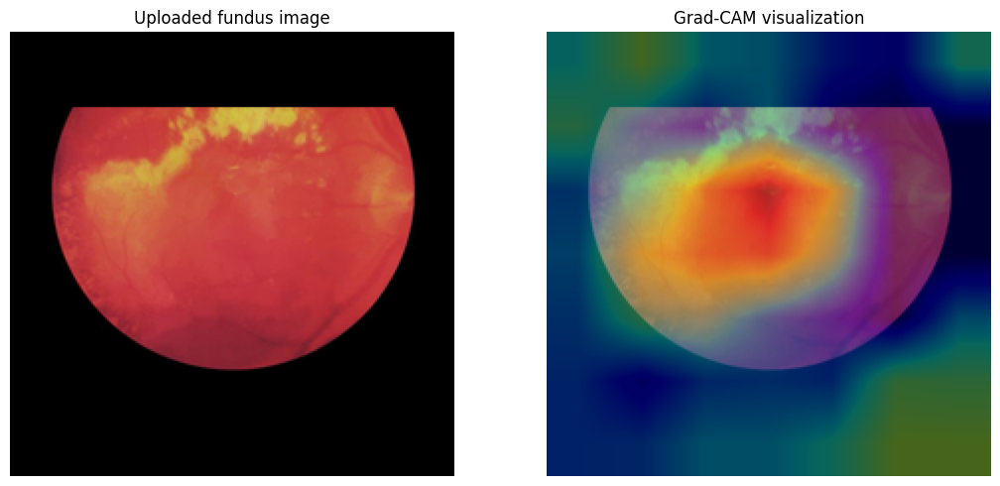

**Research prototype only:** This prediction is not a clinical diagnosis. The displayed score is not necessarily calibrated, and Grad-CAM is an attention visualization, not proof of a lesion.

In [34]:

from pathlib import Path
import sys
import io

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
from IPython.display import display, Markdown
from torch.serialization import safe_globals
from torch.torch_version import TorchVersion

# 1. Load the existing project and checkpoint
repo = Path("/content/major-project-dr-recovered")
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "colab"))

from colab_helpers import (
    BAND_ORDER,
    build_frozen_resnet50,
    preprocessing_inference,
    default_normalize,
)

checkpoint_path = Path(
    "/content/drive/MyDrive/dr_baseline_run2/"
    "best_checkpoint/model.pt"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

with safe_globals([TorchVersion]):
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )

assert checkpoint["collab_compat"]["band_order"] == BAND_ORDER

model = build_frozen_resnet50(
    num_classes=5,
    pretrained=False,
    allow_download=False,
)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.to(device).eval()

print("✅ Saved model loaded on", device)
print("Classes:", BAND_ORDER)

# 2. Upload one retinal fundus image
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image was uploaded.")

filename = next(iter(uploaded))
image = Image.open(io.BytesIO(uploaded[filename])).convert("RGB")

# 3. Use the same preprocessing as the trained model
preprocess = preprocessing_inference(224)
processed = preprocess(image)

mean, std = default_normalize()
arr = np.asarray(processed, dtype=np.float32) / 255.0
tensor = torch.from_numpy(arr.transpose(2, 0, 1).copy()).float()
tensor = (
    (tensor - torch.tensor(mean).view(3, 1, 1))
    / torch.tensor(std).view(3, 1, 1)
).unsqueeze(0).to(device)

# 4. Prediction and Grad-CAM
saved = {}
def capture_activation(module, inputs, output):
    saved["activation"] = output
    output.register_hook(lambda grad: saved.__setitem__("gradient", grad))

handle = model.layer4.register_forward_hook(capture_activation)

try:
    model.zero_grad(set_to_none=True)
    tensor.requires_grad_(True)
    logits = model(tensor)
    probs = torch.softmax(logits, dim=1)
    predicted_index = int(logits.argmax(dim=1).item())
    logits[0, predicted_index].backward()

    scores = probs[0].detach().cpu().numpy()
    activation = saved["activation"].detach()
    gradient = saved["gradient"].detach()

    weights = gradient.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * activation).sum(dim=1, keepdim=True))
    cam = F.interpolate(
        cam, size=(224, 224), mode="bilinear", align_corners=False
    )[0, 0].cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

finally:
    handle.remove()

# 5. Display results
print("\n=== EXPERIMENTAL MODEL RESULT ===")
print("Predicted grade:", BAND_ORDER[predicted_index])
print(f"Model score: {scores[predicted_index] * 100:.2f}%")
print("\nScores for all classes:")
for label, score in sorted(
    zip(BAND_ORDER, scores), key=lambda x: x[1], reverse=True
):
    print(f"{label}: {score * 100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(processed)
axes[0].set_title("Uploaded fundus image")
axes[0].axis("off")

axes[1].imshow(processed)
axes[1].imshow(cam, cmap="jet", alpha=0.4)
axes[1].set_title("Grad-CAM visualization")
axes[1].axis("off")
plt.tight_layout()
plt.show()

display(Markdown(
    "**Research prototype only:** This prediction is not a clinical "
    "diagnosis. The displayed score is not necessarily calibrated, and "
    "Grad-CAM is an attention visualization, not proof of a lesion."
))


In [35]:

from pathlib import Path

run = Path("/content/drive/MyDrive/dr_baseline_run2")

files_to_check = [
    run / "best_checkpoint/model.pt",
    run / "lesion_evidence/best_lesion_unet_v2.pt",
    run / "lesion_evidence/official_test_metrics_v2.json",
    run / "final_test_evaluation/final_test_metrics.json",
]

for path in files_to_check:
    status = "✅ FOUND" if path.exists() else "❌ NOT FOUND"
    print(status, path.name)


✅ FOUND model.pt
✅ FOUND best_lesion_unet_v2.pt
✅ FOUND official_test_metrics_v2.json
✅ FOUND final_test_metrics.json


In [36]:

import json
from pathlib import Path

metrics_file = Path(
    "/content/drive/MyDrive/dr_baseline_run2/lesion_evidence/official_test_metrics_v2.json"
)

with open(metrics_file, "r") as f:
    metrics = json.load(f)

print(json.dumps(metrics, indent=2))


{
  "model": "LesionUNet V2",
  "checkpoint": "/content/drive/MyDrive/dr_baseline_run2/lesion_evidence/best_lesion_unet_v2.pt",
  "test_image_count": 27,
  "thresholds_selected_on_validation_only": {
    "MA": 0.15,
    "HE": 0.5,
    "EX": 0.5,
    "SE": 0.5
  },
  "per_lesion_test_metrics": {
    "MA": {
      "validation_selected_threshold": 0.15,
      "annotated_test_images": 27,
      "mean_image_dice": 0.02194159457152712,
      "mean_image_iou": 0.011169170884633782,
      "mean_image_precision": 0.012321833891222668,
      "mean_image_recall": 0.13882200755683669
    },
    "HE": {
      "validation_selected_threshold": 0.5,
      "annotated_test_images": 27,
      "mean_image_dice": 0.3509235251985956,
      "mean_image_iou": 0.23163322038544806,
      "mean_image_precision": 0.29651637187232904,
      "mean_image_recall": 0.5496285655125305
    },
    "EX": {
      "validation_selected_threshold": 0.5,
      "annotated_test_images": 27,
      "mean_image_dice": 0.50189404393

In [37]:

from pathlib import Path

repo = Path("/content/major-project-dr-recovered")

print("Files related to lesion training:\n")

for path in sorted(repo.rglob("*.py")):
    if any(word in path.name.lower() for word in
           ["lesion", "segment", "train", "pipeline"]):
        print(path.relative_to(repo))


Files related to lesion training:

colab/cpu_train.py
colab/pipeline.py
colab/train.py
tests/test_colab_pipeline.py
tests/test_cpu_train.py
tests/test_pipeline_entrypoint.py


In [38]:

from pathlib import Path

repo = Path("/content/major-project-dr-recovered")

for filename in ["colab/pipeline.py", "colab/train.py", "colab/cpu_train.py"]:
    path = repo / filename
    print(f"\n{'='*20} {filename} {'='*20}")

    if not path.exists():
        print("File not found")
        continue

    lines = path.read_text(errors="replace").splitlines()

    matches = [
        i for i, line in enumerate(lines)
        if any(word in line.lower() for word in [
            "lesion", "unet", "dice", "bce",
            "mask", "segmentation", "loss"
        ])
    ]

    shown = set()
    for i in matches:
        for j in range(max(0, i-2), min(len(lines), i+3)):
            if j not in shown:
                print(f"{j+1:4}: {lines[j]}")
                shown.add(j)
        print()



==================== colab/pipeline.py ====================
 517:         "epochs_trained": 0,
 518:         "best_epoch": None,
 519:         "best_val_loss": None,
 520:         "latest_checkpoint": None,
 521:         "resumable": False,

 530:     state["status"] = manifest.get("status")
 531:     state["best_epoch"] = manifest.get("best_epoch")
 532:     state["best_val_loss"] = manifest.get("best_val_loss")
 533:     state["epochs_trained"] = int(manifest.get("train_epochs") or 0)
 534: 

 557:     _say("RUN STATUS")
 558:     _say("=" * 78)
 559:     for key in ("output_dir", "status", "epochs_trained", "best_epoch", "best_val_loss",
 560:                 "latest_checkpoint", "resumable", "reason", "has_test_metrics"):
 561:         _say(f"  {key:18}: {state.get(key)}")

 704:         "resumed": use_resume,
 705:         "best_epoch": result["best_epoch"],
 706:         "best_val_loss": result["best_val_loss"],
 707:         "epochs_trained": len(result["final_state"]["train_hi

In [39]:

from pathlib import Path

search_roots = [
    Path("/content/major-project-dr-recovered"),
    Path("/content/drive/MyDrive/dr_baseline_run2"),
]

keywords = ["LesionUNet", "best_lesion_unet_v2", "BCEWithLogitsLoss"]

for root in search_roots:
    print(f"\n--- Searching {root} ---")

    if not root.exists():
        print("Path not found")
        continue

    found = 0

    for path in root.rglob("*.py"):
        try:
            text = path.read_text(errors="ignore")
        except OSError:
            continue

        matches = [word for word in keywords if word in text]

        if matches:
            print(path)
            print("Matches:", ", ".join(matches))
            found += 1

    if found == 0:
        print("No matching Python files found.")



--- Searching /content/major-project-dr-recovered ---
No matching Python files found.

--- Searching /content/drive/MyDrive/dr_baseline_run2 ---
No matching Python files found.


In [40]:

from pathlib import Path

roots = [
    Path("/content/major-project-dr-recovered"),
    Path("/content/drive/MyDrive/dr_baseline_run2"),
]

for root in roots:
    print(f"\n--- {root} ---")

    if root.exists():
        for pattern in ["*.ipynb", "*.py", "*.md", "*.json"]:
            matches = list(root.rglob(pattern))
            for path in matches[:30]:
                print(path.relative_to(root))



--- /content/major-project-dr-recovered ---
colab/train_on_colab.ipynb
colab/train_on_colab_fixed.ipynb
dr_app.py
verify_final_deliverable.py
audit_output/v03_internal.py
audit_output/v03_pixel_verify.py
audit_output/scan_images.py
audit_output/v03_final_quantify.py
audit_output/v03_compare.py
audit_output/analyze.py
audit_output/v03_perceptual.py
colab/train.py
colab/cpu_train.py
colab/smoke_test.py
colab/setup_helpers.py
colab/pipeline.py
colab/colab_helpers.py
dataset/__init__.py
dataset/split_validation.py
dataset/statistics.py
dataset/split_protocol.py
dataset/manifest.py
dataset/labels.py
dataset/grouping.py
dataset/decoding.py
dataset/eligibility.py
tests/test_split_generation.py
tests/test_cpu_train.py
tests/test_colab_pipeline.py
tests/test_label_mapping.py
tests/test_fixed_notebook_setup.py
tests/test_canary_split.py
PIPELINE_STATUS_HANDOFF.md
pending_decisions.md
audit_output/DATASET_AUDIT_REPORT.md
colab/README.md
colab/TASK_REPORT.md
colab/COLAB_EXECUTION_CHECKLIST.md
col

In [41]:

import json
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/dr_baseline_run2/lesion_evidence"
)

for filename in [
    "training_history_v2.json",
    "validation_thresholds_v2.json",
]:
    path = folder / filename
    print(f"\n{'='*15} {filename} {'='*15}")

    if path.exists():
        data = json.loads(path.read_text())
        print(json.dumps(data, indent=2)[:12000])
    else:
        print("File not found")



=============== training_history_v2.json ===============
[
  {
    "epoch": 1,
    "loss": 0.9974305087869818,
    "validation_macro_best_threshold_dice": 0.23644627606885207,
    "validation": {
      "MA": {
        "dice_by_threshold": {
          "0.05": 0.002306022854086968,
          "0.1": 0.003396322650602157,
          "0.15": 0.001258378100974048,
          "0.2": 0.0011066897655166899,
          "0.25": 0.0,
          "0.3": 0.0,
          "0.4": 0.0,
          "0.5": 0.0
        },
        "best_validation_threshold": 0.1,
        "best_validation_dice": 0.003396322650602157
      },
      "HE": {
        "dice_by_threshold": {
          "0.05": 0.02824725086113152,
          "0.1": 0.11799281104523325,
          "0.15": 0.15395120550198865,
          "0.2": 0.17346781049917506,
          "0.25": 0.18735900332149208,
          "0.3": 0.1971617611182335,
          "0.4": 0.2080721856805817,
          "0.5": 0.21703287794475679
        },
        "best_validation_threshold":

In [42]:

import json
from pathlib import Path

notebook = Path(
    "/content/major-project-dr-recovered/colab/train_on_colab_fixed.ipynb"
)

data = json.loads(notebook.read_text())

for i, cell in enumerate(data["cells"]):
    source = "".join(cell.get("source", []))
    keywords = ["lesionunet", "lesion_evidence", "best_lesion_unet_v2"]

    if any(word in source.lower() for word in keywords):
        print(f"\n--- Cell {i + 1} ---")
        print(source[:2500])


In [43]:

from pathlib import Path

folder = Path("/content/drive/MyDrive/dr_baseline_run2/lesion_evidence")

for file in sorted(folder.iterdir()):
    print(file.name)


best_lesion_unet.pt
best_lesion_unet_v2.pt
official_test_metrics.json
official_test_metrics_v2.json
training_history.json
training_history_v2.json
validation_threshold_diagnostics.json
validation_thresholds_v2.json


In [44]:

import torch
from pathlib import Path
from torch.serialization import safe_globals
from torch.torch_version import TorchVersion

checkpoint_path = Path(
    "/content/drive/MyDrive/dr_baseline_run2/lesion_evidence/best_lesion_unet_v2.pt"
)

with safe_globals([TorchVersion]):
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

print("Checkpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("\nSaved keys:")
    for key in checkpoint:
        print("-", key)

    print("\nConfiguration or model metadata:")
    for key in ["config", "metadata", "epoch", "best_val_dice"]:
        if key in checkpoint:
            value = checkpoint[key]
            print(f"\n{key}:")
            print(str(value)[:3000])


Checkpoint type: dict

Saved keys:
- model_state_dict
- epoch
- validation_macro_best_threshold_dice
- image_size
- lesion_order
- training_ids
- validation_ids

Configuration or model metadata:

epoch:
23


In [45]:

from pathlib import Path
import json

root = Path("/content/major-project-dr-recovered")
terms = ["LesionUNet", "validation_macro_best_threshold_dice",
         "training_ids", "best_lesion_unet_v2"]

for path in root.rglob("*"):
    if not path.is_file() or path.suffix not in {".py", ".ipynb"}:
        continue

    try:
        text = path.read_text(errors="ignore")
        if path.suffix == ".ipynb":
            notebook = json.loads(text)
            text = "\n".join(
                "".join(c.get("source", []))
                for c in notebook.get("cells", [])
            )
    except Exception:
        continue

    matches = [term for term in terms if term.lower() in text.lower()]
    if matches:
        print(f"\nFILE: {path.relative_to(root)}")
        print("MATCHES:", ", ".join(matches))


In [46]:

import torch
from pathlib import Path
from collections import OrderedDict

p = Path(
    "/content/drive/MyDrive/dr_baseline_run2/lesion_evidence/best_lesion_unet_v2.pt"
)

from torch.serialization import safe_globals
from torch.torch_version import TorchVersion

with safe_globals([TorchVersion]):
    ckpt = torch.load(p, map_location="cpu", weights_only=True)

sd = ckpt["model_state_dict"]

print("Epoch:", ckpt["epoch"])
print("Image size:", ckpt.get("image_size"))
print("Lesion order:", ckpt.get("lesion_order"))
print("\nModel layer names and tensor shapes:")

for name, tensor in list(sd.items())[:35]:
    print(f"{name}: {tuple(tensor.shape)}")


Epoch: 23
Image size: 512
Lesion order: ['MA', 'HE', 'EX', 'SE']

Model layer names and tensor shapes:
enc1.0.weight: (32, 3, 3, 3)
enc1.1.weight: (32,)
enc1.1.bias: (32,)
enc1.1.running_mean: (32,)
enc1.1.running_var: (32,)
enc1.1.num_batches_tracked: ()
enc1.3.weight: (32, 32, 3, 3)
enc1.4.weight: (32,)
enc1.4.bias: (32,)
enc1.4.running_mean: (32,)
enc1.4.running_var: (32,)
enc1.4.num_batches_tracked: ()
enc2.0.weight: (64, 32, 3, 3)
enc2.1.weight: (64,)
enc2.1.bias: (64,)
enc2.1.running_mean: (64,)
enc2.1.running_var: (64,)
enc2.1.num_batches_tracked: ()
enc2.3.weight: (64, 64, 3, 3)
enc2.4.weight: (64,)
enc2.4.bias: (64,)
enc2.4.running_mean: (64,)
enc2.4.running_var: (64,)
enc2.4.num_batches_tracked: ()
enc3.0.weight: (128, 64, 3, 3)
enc3.1.weight: (128,)
enc3.1.bias: (128,)
enc3.1.running_mean: (128,)
enc3.1.running_var: (128,)
enc3.1.num_batches_tracked: ()
enc3.3.weight: (128, 128, 3, 3)
enc3.4.weight: (128,)
enc3.4.bias: (128,)
enc3.4.running_mean: (128,)
enc3.4.running_var: (

In [47]:

sd = ckpt["model_state_dict"]

print("Remaining model layers:\n")

for name, tensor in sd.items():
    if name.startswith(("dec", "up", "out", "final", "bottleneck")):
        print(f"{name}: {tuple(tensor.shape)}")


Remaining model layers:

up4.weight: (384, 256, 2, 2)
up4.bias: (256,)
dec4.0.weight: (256, 512, 3, 3)
dec4.1.weight: (256,)
dec4.1.bias: (256,)
dec4.1.running_mean: (256,)
dec4.1.running_var: (256,)
dec4.1.num_batches_tracked: ()
dec4.3.weight: (256, 256, 3, 3)
dec4.4.weight: (256,)
dec4.4.bias: (256,)
dec4.4.running_mean: (256,)
dec4.4.running_var: (256,)
dec4.4.num_batches_tracked: ()
up3.weight: (256, 128, 2, 2)
up3.bias: (128,)
dec3.0.weight: (128, 256, 3, 3)
dec3.1.weight: (128,)
dec3.1.bias: (128,)
dec3.1.running_mean: (128,)
dec3.1.running_var: (128,)
dec3.1.num_batches_tracked: ()
dec3.3.weight: (128, 128, 3, 3)
dec3.4.weight: (128,)
dec3.4.bias: (128,)
dec3.4.running_mean: (128,)
dec3.4.running_var: (128,)
dec3.4.num_batches_tracked: ()
up2.weight: (128, 64, 2, 2)
up2.bias: (64,)
dec2.0.weight: (64, 128, 3, 3)
dec2.1.weight: (64,)
dec2.1.bias: (64,)
dec2.1.running_mean: (64,)
dec2.1.running_var: (64,)
dec2.1.num_batches_tracked: ()
dec2.3.weight: (64, 64, 3, 3)
dec2.4.weight:

In [48]:

from pathlib import Path

root = Path(
    "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation"
)

print("Dataset folders:\n")

for path in sorted(root.iterdir()):
    if path.is_dir():
        print(f"\n{path.name}")
        for sub in sorted(path.iterdir()):
            print("  ", sub.name)


Dataset folders:


1. Original Images
   a. Training Set
   b. Testing Set

2. All Segmentation Groundtruths
   a. Training Set
   b. Testing Set


In [49]:

from pathlib import Path

root = Path(
    "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation"
)

for split in ["a. Training Set", "b. Testing Set"]:
    folder = root / "2. All Segmentation Groundtruths" / split

    print(f"\n--- {split} ---")

    if not folder.exists():
        print("Folder not found:", folder)
        continue

    for path in sorted(folder.iterdir()):
        if path.is_dir():
            samples = sorted(path.glob("*"))[:3]
            print(f"\n{path.name} — {len(list(path.glob('*')))} files")
            for sample in samples:
                print(" ", sample.name)



--- a. Training Set ---

1. Microaneurysms — 54 files
  IDRiD_01_MA.tif
  IDRiD_02_MA.tif
  IDRiD_03_MA.tif

2. Haemorrhages — 53 files
  IDRiD_01_HE.tif
  IDRiD_02_HE.tif
  IDRiD_03_HE.tif

3. Hard Exudates — 54 files
  IDRiD_01_EX.tif
  IDRiD_02_EX.tif
  IDRiD_03_EX.tif

4. Soft Exudates — 26 files
  IDRiD_03_SE.tif
  IDRiD_08_SE.tif
  IDRiD_13_SE.tif

5. Optic Disc — 54 files
  IDRiD_01_OD.tif
  IDRiD_02_OD.tif
  IDRiD_03_OD.tif

--- b. Testing Set ---

1. Microaneurysms — 27 files
  IDRiD_55_MA.tif
  IDRiD_56_MA.tif
  IDRiD_57_MA.tif

2. Haemorrhages — 27 files
  IDRiD_55_HE.tif
  IDRiD_56_HE.tif
  IDRiD_57_HE.tif

3. Hard Exudates — 27 files
  IDRiD_55_EX.tif
  IDRiD_56_EX.tif
  IDRiD_57_EX.tif

4. Soft Exudates — 14 files
  IDRiD_55_SE.tif
  IDRiD_56_SE.tif
  IDRiD_59_SE.tif

5. Optic Disc — 27 files
  IDRiD_55_OD.tif
  IDRiD_56_OD.tif
  IDRiD_57_OD.tif


Image exists: True /content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation/1. Original Images/a. Training Set/IDRiD_01.jpg
Mask exists: True /content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/1. Microaneurysms/IDRiD_01_MA.tif
Image size: (4288, 2848)
Mask size: (4288, 2848)
Mask mode: P


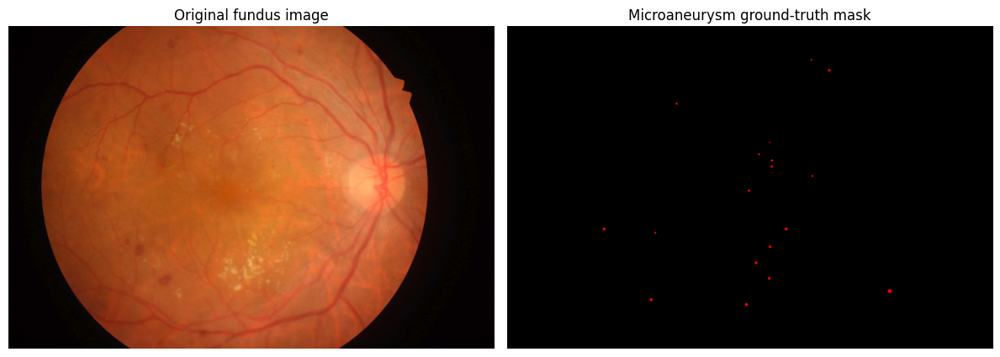

In [50]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

root = Path(
    "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation"
)

image_path = root / "1. Original Images" / "a. Training Set" / "IDRiD_01.jpg"
mask_path = (
    root / "2. All Segmentation Groundtruths" /
    "a. Training Set" / "1. Microaneurysms" / "IDRiD_01_MA.tif"
)

print("Image exists:", image_path.exists(), image_path)
print("Mask exists:", mask_path.exists(), mask_path)

if image_path.exists() and mask_path.exists():
    image = Image.open(image_path).convert("RGB")
    mask = Image.open(mask_path)

    print("Image size:", image.size)
    print("Mask size:", mask.size)
    print("Mask mode:", mask.mode)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(image)
    axes[0].set_title("Original fundus image")
    axes[0].axis("off")

    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("Microaneurysm ground-truth mask")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("One or both paths differ from the expected filenames.")


Mask mode: P
Pixel values and counts: {0: 12205283, 1: 6941}

Original nonzero pixels: 6941
After 512x512 resize: 146


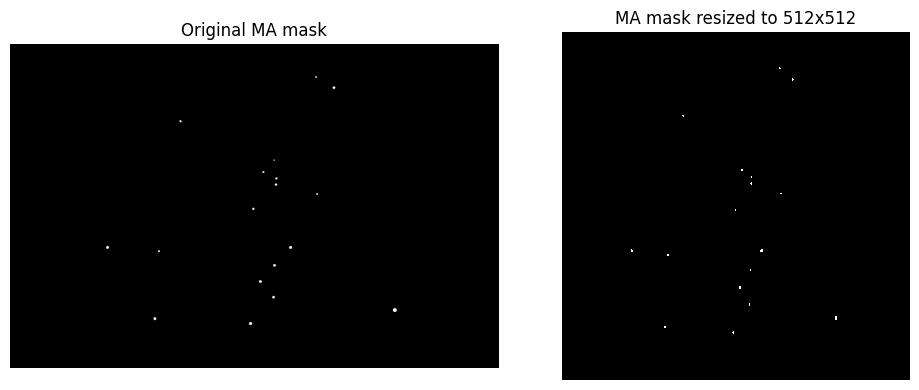

In [51]:

import numpy as np
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt

mask_path = Path(
    "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/"
    "A. Segmentation/2. All Segmentation Groundtruths/"
    "a. Training Set/1. Microaneurysms/IDRiD_01_MA.tif"
)

mask = Image.open(mask_path)
arr = np.array(mask)

values, counts = np.unique(arr, return_counts=True)
print("Mask mode:", mask.mode)
print("Pixel values and counts:", dict(zip(values.tolist(), counts.tolist())))

# Inspect the mask after the model's 512 x 512 input-size reduction.
small = mask.resize((512, 512), Image.Resampling.NEAREST)
small_arr = np.array(small)

print("\nOriginal nonzero pixels:", int(np.count_nonzero(arr)))
print("After 512x512 resize:", int(np.count_nonzero(small_arr)))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(arr, cmap="gray")
axes[0].set_title("Original MA mask")
axes[0].axis("off")

axes[1].imshow(small_arr, cmap="gray", interpolation="nearest")
axes[1].set_title("MA mask resized to 512x512")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [52]:

import numpy as np
from PIL import Image
from pathlib import Path

mask_path = Path(
    "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/"
    "A. Segmentation/2. All Segmentation Groundtruths/"
    "a. Training Set/1. Microaneurysms/IDRiD_01_MA.tif"
)

mask = np.array(Image.open(mask_path).convert("L"))
mask = (mask > 0).astype(np.uint8)

small = np.array(
    Image.fromarray(mask * 255).resize(
        (512, 512), Image.Resampling.NEAREST
    )
) > 0

# Count connected annotated regions before and after resizing.
from scipy.ndimage import label

_, original_count = label(mask)
_, resized_count = label(small)

print("Original annotated regions:", original_count)
print("Regions after resizing:", resized_count)
print("Original positive pixels:", int(mask.sum()))
print("Resized positive pixels:", int(small.sum()))


Original annotated regions: 18
Regions after resizing: 18
Original positive pixels: 6941
Resized positive pixels: 146


Crop size: (512, 512)
Positive mask pixels in crop: 943


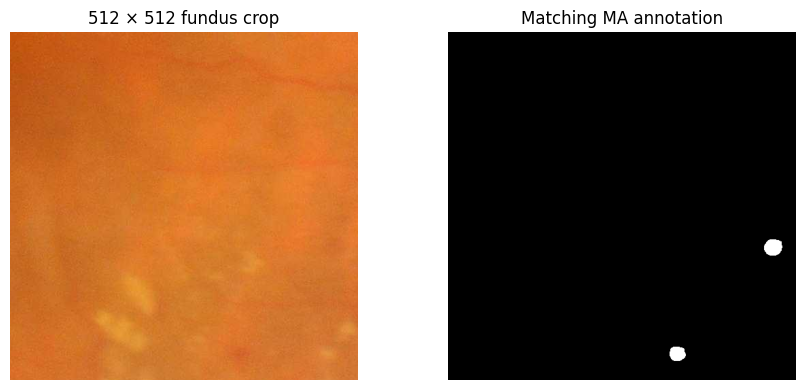

In [53]:

from PIL import Image
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

root = Path(
    "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation"
)

image_path = root / "1. Original Images/a. Training Set/IDRiD_01.jpg"
mask_path = root / (
    "2. All Segmentation Groundtruths/a. Training Set/"
    "1. Microaneurysms/IDRiD_01_MA.tif"
)

image = Image.open(image_path).convert("RGB")
mask = Image.open(mask_path).convert("L")

mask_array = np.array(mask)
ys, xs = np.where(mask_array > 0)

# Take a crop around the centre of the annotated regions.
cx, cy = int(xs.mean()), int(ys.mean())
half = 256

left = max(0, min(cx - half, image.width - 512))
top = max(0, min(cy - half, image.height - 512))
box = (left, top, left + 512, top + 512)

image_crop = image.crop(box)
mask_crop = mask.crop(box)

print("Crop size:", image_crop.size)
print("Positive mask pixels in crop:",
      int((np.array(mask_crop) > 0).sum()))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(image_crop)
axes[0].set_title("512 × 512 fundus crop")
axes[0].axis("off")
axes[1].imshow(mask_crop, cmap="gray")
axes[1].set_title("Matching MA annotation")
axes[1].axis("off")
plt.tight_layout()
plt.show()


In [54]:

from pathlib import Path

root = Path("/content/drive/MyDrive/dr_baseline_run2")

print("Saved project deliverables:\n")

for path in root.rglob("*"):
    if path.is_file() and (
        path.suffix == ".zip"
        or path.name in [
            "dr_agentic.py",
            "dr_app.py",
            "lesion_evidence.py",
            "finetune_lesion_v2.py",
            "FINAL_PROJECT_SUMMARY.md",
        ]
    ):
        print(path)


Saved project deliverables:

/content/drive/MyDrive/dr_baseline_run2/complete_project_output/FINAL_PROJECT_SUMMARY.md
/content/drive/MyDrive/dr_baseline_run2/complete_project_output/major_project_deliverables.zip


In [55]:

from pathlib import Path
import zipfile

zip_path = Path(
    "/content/drive/MyDrive/dr_baseline_run2/"
    "complete_project_output/major_project_deliverables.zip"
)

recovery_dir = Path("/content/major_project_recovered")
recovery_dir.mkdir(parents=True, exist_ok=True)

if not zip_path.exists():
    print("ZIP file not found:", zip_path)
else:
    with zipfile.ZipFile(zip_path, "r") as z:
        print("Project files inside ZIP:")
        for name in z.namelist():
            print(name)

        # Extract safely into the separate recovery folder.
        target = recovery_dir.resolve()
        for member in z.infolist():
            destination = (recovery_dir / member.filename).resolve()
            if destination != target and target not in destination.parents:
                raise ValueError(f"Unsafe ZIP path: {member.filename}")

        z.extractall(recovery_dir)

    print("\n✅ Extracted into:", recovery_dir)
    print("\nImportant Python files found:")

    for path in recovery_dir.rglob("*.py"):
        if path.name in [
            "dr_agentic.py", "dr_app.py",
            "lesion_evidence.py", "finetune_lesion_v2.py"
        ]:
            print(path)


Project files inside ZIP:
source/dr_agentic.py
source/dr_app.py
source/lesion_evidence.py
source/finetune_lesion_v2.py
source/verify_final_deliverable.py
source/PIPELINE_STATUS_HANDOFF.md
results/integrated_project_report.json
results/final_agentic_decision_report.json
results/integrated_evidence.png
results/final_integrated_dashboard.png
results/official_test_metrics_v2.json
results/lesion_test_performance.png
results/FINAL_PROJECT_SUMMARY.md

✅ Extracted into: /content/major_project_recovered

Important Python files found:
/content/major_project_recovered/source/finetune_lesion_v2.py
/content/major_project_recovered/source/dr_app.py
/content/major_project_recovered/source/dr_agentic.py
/content/major_project_recovered/source/lesion_evidence.py


In [56]:

from pathlib import Path
import importlib.util

src = Path("/content/major_project_recovered/source")

for name in [
    "dr_app.py",
    "dr_agentic.py",
    "lesion_evidence.py",
    "finetune_lesion_v2.py",
]:
    path = src / name
    print(f"\n{'='*12} {name} {'='*12}")
    if path.exists():
        lines = path.read_text(errors="replace").splitlines()
        print("\n".join(lines[:35]))
    else:
        print("NOT FOUND")

print("\n=== Package availability ===")
for package in ["torch", "torchvision", "gradio", "PIL", "matplotlib"]:
    print(package, "✅" if importlib.util.find_spec(package) else "❌")



============ dr_app.py ============

import sys
from pathlib import Path

import streamlit as st
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path("/content/major-project-dr")
sys.path.insert(0, str(ROOT))

from dr_agentic import load_model, run_agentic_workflow

st.set_page_config(
    page_title="Explainable DR Research Prototype",
    page_icon="👁️",
    layout="wide"
)

st.title("Explainable Diabetic Retinopathy Assessment")
st.caption("Agentic AI Research Prototype")

st.warning(
    "Research prototype only — not for clinical diagnosis. "
    "A qualified eye-care professional must assess patients."
)

@st.cache_resource
def get_model():
    return load_model()

uploaded = st.file_uploader(
    "Upload a retinal fundus image",
    type=["jpg", "jpeg", "png", "tif", "tiff"]

============ dr_agentic.py ============
"""Traceable agentic workflow for the existing DR research project."""
import sys
from pathlib import Path

import numpy as np
impor

In [57]:

from pathlib import Path

src = Path("/content/major_project_recovered/source")
dest = Path("/content/major-project-dr-recovered/dr_app_final.py")

app_path = src / "dr_app.py"
agent_path = src / "dr_agentic.py"

print("App found:", app_path.exists())
print("Agent found:", agent_path.exists())
print("Main project found:", Path("/content/major-project-dr-recovered").exists())

if app_path.exists() and agent_path.exists():
    app_code = app_path.read_text()
    agent_code = agent_path.read_text()

    print("\nApp references old project path:",
          "/content/major-project-dr" in app_code)
    print("Agent references old project path:",
          "/content/major-project-dr" in agent_code)

    corrected_app = app_code.replace(
        "/content/major-project-dr",
        "/content/major-project-dr-recovered"
    )
    dest.write_text(corrected_app)

    print("\n✅ Corrected app copy saved to:", dest)
else:
    print("A recovered source file is missing. Do not launch the app yet.")


App found: True
Agent found: True
Main project found: True

App references old project path: True
Agent references old project path: True

✅ Corrected app copy saved to: /content/major-project-dr-recovered/dr_app_final.py


In [58]:

from pathlib import Path

agent = Path(
    "/content/major-project-recovered/source/dr_agentic.py"
)

lines = agent.read_text().splitlines()

for start, end in [(1, 65), (65, 150)]:
    print(f"\n--- dr_agentic.py lines {start}-{end} ---")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1:3}: {lines[i]}")


FileNotFoundError: [Errno 2] No such file or directory: '/content/major-project-recovered/source/dr_agentic.py'

In [59]:

from pathlib import Path

agent = Path(
    "/content/major_project_recovered/source/dr_agentic.py"
)

print("File found:", agent.exists())

if agent.exists():
    lines = agent.read_text().splitlines()

    for i, line in enumerate(lines[:150], start=1):
        print(f"{i:3}: {line}")


File found: True
  1: """Traceable agentic workflow for the existing DR research project."""
  2: import sys
  3: from pathlib import Path
  4: 
  5: import numpy as np
  6: import torch
  7: import torch.nn.functional as F
  8: from PIL import Image
  9: 
 10: ROOT = Path("/content/major-project-dr")
 11: CHECKPOINT = Path(
 12:     "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt"
 13: )
 14: CLASSES = [
 15:     "No apparent DR", "Mild NPDR", "Moderate NPDR",
 16:     "Severe NPDR", "PDR"
 17: ]
 18: 
 19: sys.path.insert(0, str(ROOT))
 20: sys.path.insert(0, str(ROOT / "colab"))
 21: 
 22: from colab_helpers import (
 23:     build_frozen_resnet50,
 24:     preprocessing_inference,
 25:     default_normalize,
 26: )
 27: 
 28: DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
 29: 
 30: 
 31: def load_model():
 32:     """Restore the existing checkpoint without downloading or training."""
 33:     model = build_frozen_resnet50(num_classes=5, pre

In [60]:

from pathlib import Path

source = Path("/content/major_project_recovered/source/dr_agentic.py")
destination = Path("/content/major-project-dr-recovered/dr_agentic.py")

code = source.read_text()

code = code.replace(
    'ROOT = Path("/content/major-project-dr")',
    'ROOT = Path("/content/major-project-dr-recovered")'
)

destination.write_text(code)

print("Saved:", destination)
print("Project folder exists:", destination.parent.exists())
print("Classifier checkpoint exists:",
      Path("/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt").exists())
print("Helper file exists:",
      (destination.parent / "colab" / "colab_helpers.py").exists())


Saved: /content/major-project-dr-recovered/dr_agentic.py
Project folder exists: True
Classifier checkpoint exists: True
Helper file exists: True


In [61]:

import sys

sys.path.insert(0, "/content/major-project-dr-recovered")

from dr_agentic import load_model

model = load_model()
print("✅ Classifier loaded successfully!")
print("Device:", next(model.parameters()).device)


✅ Classifier loaded successfully!
Device: cuda:0


In [62]:

from pathlib import Path

agent_file = Path("/content/major-project-dr-recovered/dr_agentic.py")
lines = agent_file.read_text().splitlines()

print("\n".join(
    f"{i+1}: {lines[i]}"
    for i in range(140, len(lines))
))


141:     else:
142:         decision = "PROVISIONAL MODEL OUTPUT — HUMAN REVIEW REQUIRED"
143: 
144:     trace.append({
145:         "stage": "reliability_decision",
146:         "status": "review" if reasons else "provisional",
147:         "details": reasons or [
148:             "No configured heuristic triggered; human review remains necessary."
149:         ],
150:     })
151: 
152:     return {
153:         "predicted_class": CLASSES[index],
154:         "probabilities": {
155:             name: float(value) for name, value in zip(CLASSES, probabilities)
156:         },
157:         "confidence": confidence,
158:         "normalized_entropy": entropy,
159:         "quality": quality,
160:         "gradcam": heatmap,
161:         "decision": decision,
162:         "reasons": reasons,
163:         "trace": trace,
164:         "limitations": [
165:             "Research prototype, not for clinical diagnosis.",
166:             "The five-class mapping is provisional.",
167:          

Saving retinal image.jpg to retinal image (1).jpg
=== DR ASSESSMENT ===
Predicted grade: PDR
Model score: 80.87%
Decision: PROVISIONAL MODEL OUTPUT — HUMAN REVIEW REQUIRED
Image quality: {'passed': True, 'brightness': 66.03, 'contrast': 54.39, 'warnings': [], 'method': 'Unvalidated technical heuristics'}

=== CLASS SCORES ===
PDR: 80.87%
Severe NPDR: 18.41%
Moderate NPDR: 0.56%
Mild NPDR: 0.14%
No apparent DR: 0.02%


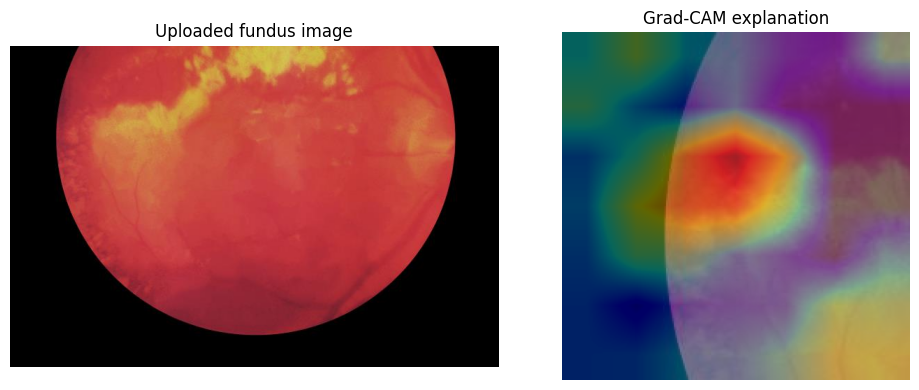


=== REASONING TRACE ===
image_quality : pass - []
dr_classifier : complete - {'predicted_class': 'PDR', 'top_class_confidence': 0.8087313771247864}
gradcam : complete - Class-conditioned attention visualization generated.
reliability_decision : provisional - ['No configured heuristic triggered; human review remains necessary.']

=== LIMITATIONS ===
- Research prototype, not for clinical diagnosis.
- The five-class mapping is provisional.
- Confidence is not a calibrated measure of correctness.
- Grad-CAM is not lesion segmentation or causal evidence.
- Quality and abstention thresholds are heuristic.
- Validated multimodal clinical metadata fusion is not implemented.


In [63]:

import sys
from PIL import Image
from google.colab import files
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "/content/major-project-dr-recovered")

from dr_agentic import load_model, run_agentic_workflow

uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    image = Image.open(filename).convert("RGB")

    model = load_model()
    result = run_agentic_workflow(image, model=model)

    print("=== DR ASSESSMENT ===")
    print("Predicted grade:", result["predicted_class"])
    print(f"Model score: {result['confidence']:.2%}")
    print("Decision:", result["decision"])
    print("Image quality:", result["quality"])
    print("\n=== CLASS SCORES ===")

    for name, score in sorted(
        result["probabilities"].items(),
        key=lambda item: item[1],
        reverse=True
    ):
        print(f"{name}: {score:.2%}")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(image)
    axes[0].set_title("Uploaded fundus image")
    axes[0].axis("off")

    axes[1].imshow(image)
    axes[1].imshow(result["gradcam"], cmap="jet", alpha=0.4)
    axes[1].set_title("Grad-CAM explanation")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    print("\n=== REASONING TRACE ===")
    for step in result["trace"]:
        print(step["stage"], ":", step["status"], "-", step["details"])

    print("\n=== LIMITATIONS ===")
    for limitation in result["limitations"]:
        print("-", limitation)


In [64]:

from pathlib import Path
import ast

p = Path("/content/major_project_recovered/source/lesion_evidence.py")
source = p.read_text()
tree = ast.parse(source)

print("=== LESION MODEL FUNCTIONS ===")
for node in ast.walk(tree):
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
        print(f"Line {node.lineno}: {node.name}")

print("\n=== APP OUTPUT COMPONENTS ===")
app = Path("/content/major_project_recovered/source/dr_app.py")
for i, line in enumerate(app.read_text().splitlines(), 1):
    if i > 35:
        print(f"{i:3}: {line}")


=== LESION MODEL FUNCTIONS ===
Line 26: IDRiDLesionDataset
Line 84: block
Line 95: LesionUNet
Line 127: segmentation_loss
Line 145: evaluate
Line 188: main
Line 27: __init__
Line 38: __len__
Line 41: __getitem__
Line 96: __init__
Line 114: forward

=== APP OUTPUT COMPONENTS ===
 36: )
 37: 
 38: if uploaded:
 39:     image = Image.open(uploaded).convert("RGB")
 40:     st.image(image, caption="Uploaded fundus image", width=420)
 41: 
 42:     if st.button("Analyze image", type="primary"):
 43:         try:
 44:             with st.spinner("Analyzing image..."):
 45:                 result = run_agentic_workflow(image, get_model())
 46: 
 47:             st.subheader("Provisional prediction")
 48:             st.write("**Predicted grade:**", result["predicted_class"])
 49:             st.write("**Model confidence:**", f'{result["confidence"]:.2%}')
 50:             st.write("**Reliability decision:**", result["decision"])
 51: 
 52:             st.subheader("Image quality")
 53:        

In [65]:

from pathlib import Path

p = Path("/content/major_project_recovered/source/lesion_evidence.py")
lines = p.read_text().splitlines()

for start, end in [(1, 145)]:
    print(f"=== lesion_evidence.py, lines {start}-{end} ===")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1:3}: {lines[i]}")


=== lesion_evidence.py, lines 1-145 ===
  1: from pathlib import Path
  2: import json
  3: import random
  4: import copy
  5: 
  6: import numpy as np
  7: from PIL import Image, ImageOps
  8: import torch
  9: from torch import nn
 10: import torch.nn.functional as F
 11: from torch.utils.data import Dataset, DataLoader
 12: 
 13: ROOT = Path("/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation")
 14: DRIVE_OUT = Path("/content/drive/MyDrive/dr_baseline_run2/lesion_evidence")
 15: PROJECT_OUT = Path("/content/major-project-dr/audit_output")
 16: LESIONS = {
 17:     "MA": "1. Microaneurysms",
 18:     "HE": "2. Haemorrhages",
 19:     "EX": "3. Hard Exudates",
 20:     "SE": "4. Soft Exudates",
 21: }
 22: SIZE = 512
 23: SEED = 12345
 24: 
 25: 
 26: class IDRiDLesionDataset(Dataset):
 27:     def __init__(self, split, ids, augment=False):
 28:         self.split = split
 29:         self.ids = list(ids)
 30:         self.augment = augment
 31:         self.image_d

In [66]:

from pathlib import Path

app_path = Path("/content/major-project-dr-recovered/dr_app_final.py")

app_code = r'''
import sys
from pathlib import Path

import streamlit as st
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path("/content/major-project-dr-recovered")
SOURCE = Path("/content/major_project_recovered/source")
RUN = Path("/content/drive/MyDrive/dr_baseline_run2")
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "colab"))
sys.path.insert(0, str(SOURCE))

from dr_agentic import load_model, run_agentic_workflow
from lesion_evidence import LesionUNet

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LESION_NAMES = {
    "MA": "Microaneurysms",
    "HE": "Haemorrhages",
    "EX": "Hard exudates",
    "SE": "Soft exudates",
}
THRESHOLDS = {"MA": 0.15, "HE": 0.5, "EX": 0.5, "SE": 0.5}

st.set_page_config(
    page_title="Explainable DR Research Prototype",
    page_icon="👁️",
    layout="wide",
)
st.title("Multimodal Explainable DR Assessment")
st.caption("Major project · Experimental research prototype")
st.warning(
    "NOT FOR CLINICAL DIAGNOSIS. Predictions and lesion maps are experimental. "
    "A qualified eye-care professional must assess patients."
)

@st.cache_resource
def get_classifier():
    return load_model()

@st.cache_resource
def get_lesion_model():
    checkpoint_path = RUN / "lesion_evidence" / "best_lesion_unet_v2.pt"
    model = LesionUNet(out_channels=4)
    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=True
    )
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    return model.to(DEVICE).eval()

def lesion_predict(image, model):
    resized = image.convert("RGB").resize((512, 512), Image.Resampling.BILINEAR)
    arr = np.asarray(resized, dtype=np.float32) / 255.0
    mean = np.array([0.485, 0.456, 0.406], np.float32)
    std = np.array([0.229, 0.224, 0.225], np.float32)
    arr = (arr - mean) / std
    x = torch.from_numpy(arr.transpose(2, 0, 1).copy()).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        probs = torch.sigmoid(model(x))[0].cpu().numpy()
    masks = {}
    for i, code in enumerate(LESION_NAMES):
        masks[code] = probs[i] >= THRESHOLDS[code]
    return resized, probs, masks

uploaded = st.file_uploader(
    "Upload a retinal fundus image",
    type=["jpg", "jpeg", "png", "tif", "tiff"]
)

if uploaded:
    image = Image.open(uploaded).convert("RGB")
    st.image(image, caption="Uploaded fundus image", width=480)

    if st.button("Analyze image", type="primary"):
        try:
            with st.spinner("Running classifier, Grad-CAM and lesion model..."):
                classifier = get_classifier()
                result = run_agentic_workflow(image, classifier)
                lesion_image, lesion_probs, masks = lesion_predict(
                    image, get_lesion_model()
                )

            st.header("1. DR severity assessment")
            a, b, c = st.columns(3)
            a.metric("Predicted grade", result["predicted_class"])
            b.metric("Model score", f'{result["confidence"]:.2%}')
            c.metric("Normalized entropy", f'{result["normalized_entropy"]:.3f}')
            st.info(result["decision"])

            st.subheader("Class probabilities")
            for label, value in result["probabilities"].items():
                st.write(f"{label}: {value:.2%}")
                st.progress(float(value))

            st.header("2. Visual explanation")
            fig, axes = plt.subplots(1, 2, figsize=(12, 5))
            axes[0].imshow(image)
            axes[0].set_title("Original fundus image")
            axes[0].axis("off")
            axes[1].imshow(image)
            axes[1].imshow(
                result["gradcam"], cmap="jet", alpha=0.42,
                extent=(0, image.width, image.height, 0)
            )
            axes[1].set_title("Classifier Grad-CAM")
            axes[1].axis("off")
            st.pyplot(fig)
            plt.close(fig)
            st.caption(
                "Grad-CAM indicates regions influencing the classifier. "
                "It does not establish lesion presence or causality."
            )

            st.header("3. Lesion-level model outputs")
            st.caption(
                "Experimental U-Net predictions. Thresholds were selected "
                "on validation data. These maps are not clinically validated."
            )
            cols = st.columns(2)
            for i, code in enumerate(LESION_NAMES):
                with cols[i % 2]:
                    fig, ax = plt.subplots(figsize=(6, 4))
                    ax.imshow(lesion_image)
                    ax.imshow(
                        masks[code], cmap="autumn", alpha=0.65,
                        interpolation="nearest"
                    )
                    ax.set_title(
                        f"{LESION_NAMES[code]} (threshold {THRESHOLDS[code]})"
                    )
                    ax.axis("off")
                    st.pyplot(fig)
                    plt.close(fig)
                    st.write(
                        f"Predicted positive pixels: "
                        f"{int(masks[code].sum()):,} / {masks[code].size:,}"
                    )

            st.header("4. Image quality and reliability")
            st.json(result["quality"])
            if result["reasons"]:
                st.error("Review flags: " + "; ".join(result["reasons"]))
            else:
                st.warning(
                    "No configured heuristic triggered. This does not prove "
                    "the prediction is reliable."
                )

            st.header("5. Agent workflow trace")
            for step in result["trace"]:
                st.write(f"**{step['stage']}** — {step['status']}")
                st.json(step["details"])

            st.header("6. Limitations")
            for limitation in result["limitations"]:
                st.write("- " + limitation)
            st.write(
                "- Clinical metadata fusion is not implemented in this demo."
            )
            st.write(
                "- The segmentation model has weak microaneurysm performance; "
                "the displayed maps must not be treated as confirmed lesions."
            )
            st.write(
                "- The classifier's score is not calibrated probability of "
                "correctness. The saved test accuracy is approximately 72.25%."
            )
        except Exception as exc:
            st.error(f"Analysis failed: {type(exc).__name__}: {exc}")
            st.exception(exc)
else:
    st.info("Upload a fundus image to begin.")
'''

app_path.write_text(app_code)
print("✅ Integrated app saved:", app_path)
print("Classifier checkpoint exists:",
      (Path("/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt")).exists())
print("Lesion checkpoint exists:",
      (Path("/content/drive/MyDrive/dr_baseline_run2/lesion_evidence/best_lesion_unet_v2.pt")).exists())


✅ Integrated app saved: /content/major-project-dr-recovered/dr_app_final.py
Classifier checkpoint exists: True
Lesion checkpoint exists: True


In [67]:

%cd /content/major-project-dr-recovered
!streamlit run dr_app_final.py --server.port 8501 --server.address 0.0.0.0


/content/major-project-dr-recovered
/bin/bash: line 1: streamlit: command not found


In [68]:
%pip install -q streamlit

In [69]:
import streamlit
print("Streamlit installed successfully!", streamlit.__version__)

Streamlit installed successfully! 1.66.1


In [70]:
%cd /content/major-project-dr-recovered

!python -m streamlit run dr_app_final.py --server.port 8501 --server.address 0.0.0.0

/content/major-project-dr-recovered


2026-10-28 14:41:00.004 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.125.16.1:8501

  Stopping...
  Stopping...


In [71]:
from google.colab import output

url = output.eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-gpu-t4-s-usw4a2-1g81ny8dj0ut2-a.us-west4.prod.r.colab.dev


In [72]:
%cd /content/major-project-dr-recovered

!nohup python -m streamlit run dr_app_final.py --server.port 8501 --server.address 0.0.0.0 > /tmp/streamlit.log 2>&1 &
!sleep 5
!tail -n 30 /tmp/streamlit.log

/content/major-project-dr-recovered


2026-10-28 14:44:00.544 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.125.16.1:8501



In [73]:
from google.colab import output

print(output.eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-gpu-t4-s-usw4a2-1g81ny8dj0ut2-a.us-west4.prod.r.colab.dev


In [74]:
!tail -n 50 /tmp/streamlit.log



2026-10-28 14:44:00.544 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.125.16.1:8501

2026-10-28 14:45:02.509 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-usw4a2-1g81ny8dj0ut2-a.us-west4.prod.r.colab.dev, host=gpu-t4-s-usw4a2-1g81ny8dj0ut2.us-west4-a.c.codatalab-user-runtimes.internal:8007
2026-10-28 14:45:04.209 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-usw4a2-1g81ny8dj0ut2-a.us-west4.prod.r.colab.dev, host=gpu-t4-s-usw4a2-1g81ny8dj0ut2.us-west4-a.c.codatalab-user-runtimes.internal:8007
2026-10-28 14:45:06.424 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-usw4a2-1g81ny8dj0ut2-a.us-west4.prod.r.colab.dev, host=gpu-t4-s-usw4a2-1g81ny8dj0ut2.us-west4-a.c.codatalab-user-runtimes.

In [1]:
!pkill -f "streamlit run dr_app_final.py" || true

^C


In [2]:
%cd /content/major-project-dr-recovered

!nohup python -m streamlit run dr_app_final.py --server.port 8501 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false > /tmp/streamlit.log 2>&1 &

[Errno 2] No such file or directory: '/content/major-project-dr-recovered'
/content


In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os

print("Project folder:", os.path.exists("/content/major-project-dr-recovered"))
print("Classifier checkpoint:", os.path.exists(
    "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt"
))
print("Lesion checkpoint:", os.path.exists(
    "/content/drive/MyDrive/dr_baseline_run2/lesion_evidence/best_lesion_unet_v2.pt"
))

Mounted at /content/drive
Project folder: False
Classifier checkpoint: True
Lesion checkpoint: True


In [4]:
import os
import zipfile
import shutil

zip_path = "/content/drive/MyDrive/dr_baseline_run2/complete_project_output/major_project_deliverables.zip"
restore_path = "/content/major_project_recovered"
project_path = "/content/major-project-dr-recovered"

print("Saved ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    os.makedirs(restore_path, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(restore_path)

    print("ZIP extracted successfully!")
    print("Recovered files:")

    for root, dirs, files in os.walk(restore_path):
        for file in files:
            if file.endswith((".py", ".md", ".json")):
                print(os.path.join(root, file))
else:
    print("ZIP not found at the expected path.")

Saved ZIP exists: True
ZIP extracted successfully!
Recovered files:
/content/major_project_recovered/results/integrated_project_report.json
/content/major_project_recovered/results/FINAL_PROJECT_SUMMARY.md
/content/major_project_recovered/results/official_test_metrics_v2.json
/content/major_project_recovered/results/final_agentic_decision_report.json
/content/major_project_recovered/source/dr_app.py
/content/major_project_recovered/source/lesion_evidence.py
/content/major_project_recovered/source/finetune_lesion_v2.py
/content/major_project_recovered/source/dr_agentic.py
/content/major_project_recovered/source/verify_final_deliverable.py
/content/major_project_recovered/source/PIPELINE_STATUS_HANDOFF.md


In [5]:
import os
import shutil

source = "/content/major_project_recovered/source"
project = "/content/major-project-dr-recovered"

os.makedirs(project, exist_ok=True)

for name in ["dr_agentic.py", "lesion_evidence.py", "dr_app.py"]:
    shutil.copy2(
        os.path.join(source, name),
        os.path.join(project, name)
    )

print("Restored successfully!")
print(os.listdir(project))

Restored successfully!
['dr_app.py', 'lesion_evidence.py', 'dr_agentic.py']


In [6]:
import os

project = "/content/major-project-dr-recovered"
drive = "/content/drive/MyDrive/dr_baseline_run2"

print("PROJECT FILES")
for name in ["dr_agentic.py", "lesion_evidence.py", "dr_app.py"]:
    print(f"{name}: {os.path.exists(os.path.join(project, name))}")

print("\nSAVED MODELS")
print("Classifier:", os.path.exists(
    f"{drive}/best_checkpoint/model.pt"
))
print("Lesion model:", os.path.exists(
    f"{drive}/lesion_evidence/best_lesion_unet_v2.pt"
))

print("\nHELPER FILE")
print("Colab helpers:", os.path.exists(
    f"{project}/colab/colab_helpers.py"
))

print("\nAGENT CONFIGURATION")
with open(f"{project}/dr_agentic.py") as f:
    for line in f:
        if "ROOT =" in line or "CHECKPOINT" in line:
            print(line.rstrip())

PROJECT FILES
dr_agentic.py: True
lesion_evidence.py: True
dr_app.py: True

SAVED MODELS
Classifier: True
Lesion model: True

HELPER FILE
Colab helpers: False

AGENT CONFIGURATION
ROOT = Path("/content/major-project-dr")
CHECKPOINT = Path(
        CHECKPOINT, map_location="cpu", weights_only=False


In [7]:
import os
import subprocess

repo_path = "/content/major-project-dr"

if not os.path.exists(os.path.join(repo_path, "colab", "colab_helpers.py")):
    result = subprocess.run(
        ["git", "clone", "https://github.com/anoushka24dev/major-project-dr", repo_path],
        capture_output=True,
        text=True
    )
    print(result.stdout)
    print(result.stderr[-1500:] if result.stderr else "")

print(
    "Helper found:",
    os.path.exists(os.path.join(repo_path, "colab", "colab_helpers.py"))
)


Cloning into '/content/major-project-dr'...

Helper found: True


In [8]:
import sys
from pathlib import Path

project = Path("/content/major-project-dr-recovered")
sys.path.insert(0, str(project))
sys.path.insert(0, str(project / "colab"))

import dr_agentic

dr_agentic.ROOT = project
dr_agentic.CHECKPOINT = Path(
    "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt"
)
dr_agentic.DEVICE = "cpu"

model = dr_agentic.load_model()

print("Classifier loaded successfully!")
print("Device: CPU")
print("Model type:", type(model).__name__)

Classifier loaded successfully!
Device: CPU
Model type: ResNet


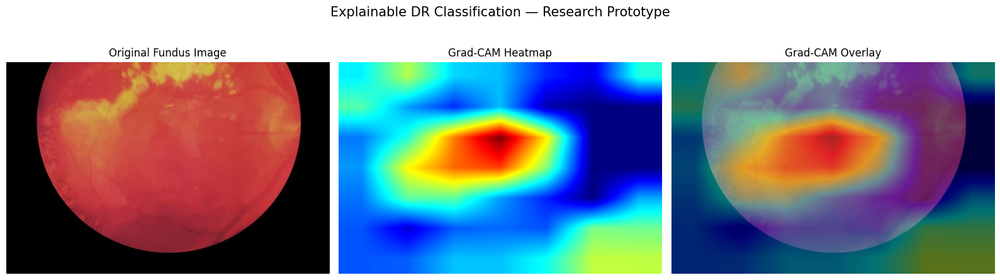


PREDICTED GRADE: PDR
TOP-CLASS SCORE: 0.8087
NORMALIZED ENTROPY: 0.3250

CLASS PROBABILITIES
No apparent DR: 0.0002
Mild NPDR: 0.0014
Moderate NPDR: 0.0056
Severe NPDR: 0.1841
PDR: 0.8087

IMAGE QUALITY
{'passed': True, 'brightness': 66.03, 'contrast': 54.39, 'warnings': [], 'method': 'Unvalidated technical heuristics'}

RELIABILITY DECISION
PROVISIONAL MODEL OUTPUT — HUMAN REVIEW REQUIRED

WORKFLOW TRACE
{'stage': 'image_quality', 'status': 'pass', 'details': []}
{'stage': 'dr_classifier', 'status': 'complete', 'details': {'predicted_class': 'PDR', 'top_class_confidence': 0.808730959892273}}
{'stage': 'gradcam', 'status': 'complete', 'details': 'Class-conditioned attention visualization generated.'}
{'stage': 'reliability_decision', 'status': 'provisional', 'details': ['No configured heuristic triggered; human review remains necessary.']}

LIMITATIONS
- Research prototype, not for clinical diagnosis.
- The five-class mapping is provisional.
- Confidence is not a calibrated measure of

In [10]:

import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image

# Reuse the image and prediction already generated
original = np.array(fundus_image.convert("RGB"))
cam = np.asarray(result["gradcam"])

# Convert Grad-CAM output into a 2D heatmap if needed
if cam.ndim == 3:
    if cam.shape[-1] == 4:
        cam = cam[..., :3]
    if cam.ndim == 3 and cam.shape[-1] == 3:
        cam = cv2.cvtColor(
            cam.astype(np.float32),
            cv2.COLOR_RGB2GRAY
        )

cam = cam.astype(np.float32)
cam = np.nan_to_num(cam)
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

# Resize heatmap to match the original fundus image
cam_resized = cv2.resize(
    cam,
    (original.shape[1], original.shape[0])
)

# Create a coloured heatmap and overlay
heatmap = cv2.applyColorMap(
    np.uint8(255 * cam_resized),
    cv2.COLORMAP_JET
)
heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

overlay = np.clip(
    0.55 * original.astype(np.float32) +
    0.45 * heatmap.astype(np.float32),
    0, 255
).astype(np.uint8)

# Display the visual explanation
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(original)
axes[0].set_title("Original Fundus Image")

axes[1].imshow(heatmap)
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(overlay)
axes[2].set_title("Grad-CAM Overlay")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    "Explainable DR Classification — Research Prototype",
    fontsize=15
)
plt.tight_layout()
plt.show()

# Display the structured model output
print("\nPREDICTED GRADE:", result["predicted_class"])
print(f"TOP-CLASS SCORE: {result['confidence']:.4f}")
print(f"NORMALIZED ENTROPY: {result['normalized_entropy']:.4f}")

print("\nCLASS PROBABILITIES")
for name, probability in result["probabilities"].items():
    print(f"{name}: {probability:.4f}")

print("\nIMAGE QUALITY")
print(result["quality"])

print("\nRELIABILITY DECISION")
print(result["decision"])

print("\nWORKFLOW TRACE")
for step in result["trace"]:
    print(step)

print("\nLIMITATIONS")
for item in result["limitations"]:
    print("-", item)


MULTIMODAL EXPLAINABLE AGENTIC AI FRAMEWORK
Diabetic Retinopathy — Research Prototype Dashboard


## 1. Input Fundus Image

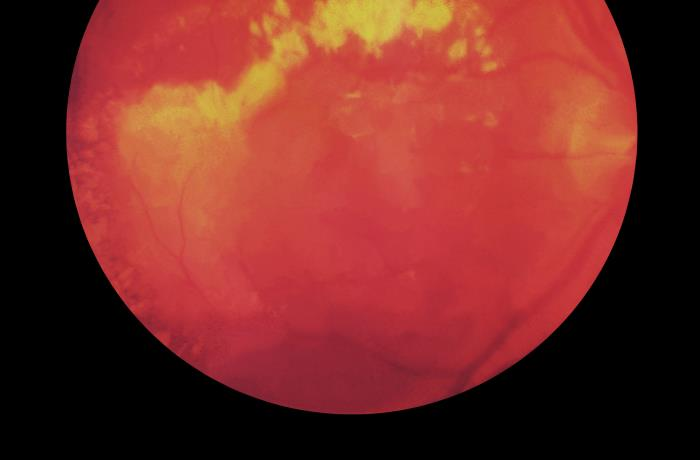

## 2. Five-Class DR Classification

Predicted grade: PDR
Top-class score: 0.8087
Normalized entropy: 0.3250

Class probabilities:
  No apparent DR       0.0002 (0.02%)
  Mild NPDR            0.0014 (0.14%)
  Moderate NPDR        0.0056 (0.56%)
  Severe NPDR          0.1841 (18.41%)
  PDR                  0.8087 (80.87%)


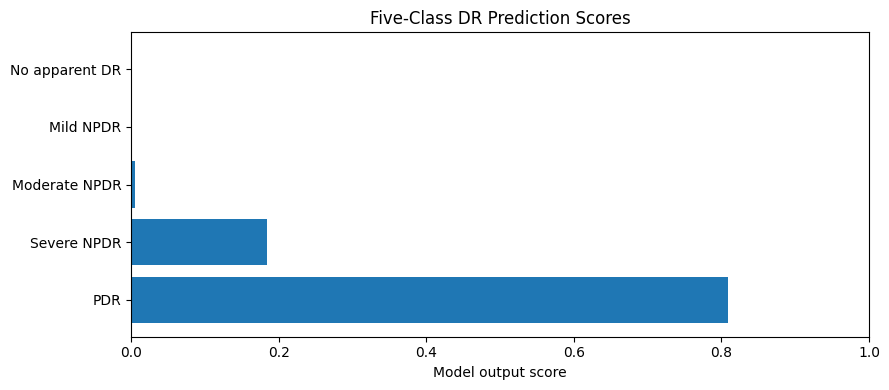

## 3. Explainability — Grad-CAM

The overlay shows model attention, not lesion segmentation or proof of a clinical finding.

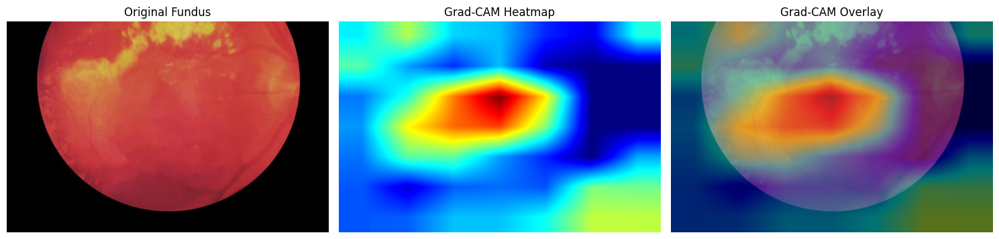

## 4. Image Quality and Reliability Review

Image quality: {'passed': True, 'brightness': 66.03, 'contrast': 54.39, 'warnings': [], 'method': 'Unvalidated technical heuristics'}
Reliability decision: PROVISIONAL MODEL OUTPUT — HUMAN REVIEW REQUIRED
Reasons: []


## 5. Agent Workflow Trace

{
  "stage": "image_quality",
  "status": "pass",
  "details": []
}
{
  "stage": "dr_classifier",
  "status": "complete",
  "details": {
    "predicted_class": "PDR",
    "top_class_confidence": 0.808730959892273
  }
}
{
  "stage": "gradcam",
  "status": "complete",
  "details": "Class-conditioned attention visualization generated."
}
{
  "stage": "reliability_decision",
  "status": "provisional",
  "details": [
    "No configured heuristic triggered; human review remains necessary."
  ]
}


## 6. Saved Evaluation Results


Artifact: integrated_project_report.json
{
  "project": "Multimodal Explainable Agentic AI for Diabetic Retinopathy",
  "input_image": "/content/drive/MyDrive/DR_Dataset/IDRiD_Segmentation/A. Segmentation/1. Original Images/b. Testing Set/IDRiD_55.jpg",
  "classifier_workflow": {
    "predicted_class": "Severe NPDR",
    "probabilities": {
      "No apparent DR": 0.005999363027513027,
      "Mild NPDR": 0.002997785806655884,
      "Moderate NPDR": 0.031075628474354744,
      "Severe NPDR": 0.7500202059745789,
      "PDR": 0.2099069356918335
    },
    "confidence": 0.7500202059745789,
    "normalized_entropy": 0.4345709536771203,
    "quality": {
      "passed": true,
      "brightness": 54.58,
      "contrast": 37.51,
      "warnings": [],
      "method": "Unvalidated technical heuristics"
    },
    "gradcam": [
      [
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1.0,
        1


## 7. Requirements and Implementation Status

| Requirement | Status |
|---|---|
| Five-class DR classifier | Implemented |
| Class probabilities | Implemented |
| Grad-CAM visualization | Implemented |
| Technical image-quality checks | Implemented, unvalidated |
| Reliability decision and trace | Implemented, provisional |
| Test-set evaluation | Saved metrics available |
| Clinical metadata fusion | Not implemented |
| Lesion segmentation in inference workflow | Not integrated |
| Calibrated uncertainty / ECE | Not completed |
| Independent cross-dataset validation | Planned |

**Research prototype only.** Predictions and confidence scores are not
clinically validated; qualified human review is required.


In [11]:

import os, json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

# 1. Load the saved test evaluation
metrics_path = (
    "/content/drive/MyDrive/dr_baseline_run2/"
    "lesion_evidence/official_test_metrics_v2.json"
)
summary_path = (
    "/content/major_project_recovered/results/"
    "integrated_project_report.json"
)

print("=" * 70)
print("MULTIMODAL EXPLAINABLE AGENTIC AI FRAMEWORK")
print("Diabetic Retinopathy — Research Prototype Dashboard")
print("=" * 70)

# 2. Display the actual uploaded image
display(Markdown("## 1. Input Fundus Image"))
display(fundus_image)

# 3. Prediction and class scores from the real model result
display(Markdown("## 2. Five-Class DR Classification"))
print("Predicted grade:", result["predicted_class"])
print(f"Top-class score: {result['confidence']:.4f}")
print(f"Normalized entropy: {result['normalized_entropy']:.4f}")
print("\nClass probabilities:")

names = list(result["probabilities"].keys())
values = [float(result["probabilities"][n]) for n in names]

for name, value in zip(names, values):
    print(f"  {name:<20} {value:.4f} ({value*100:.2f}%)")

plt.figure(figsize=(9, 4))
plt.barh(names[::-1], values[::-1])
plt.xlabel("Model output score")
plt.title("Five-Class DR Prediction Scores")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

# 4. Grad-CAM visual explanation
display(Markdown("## 3. Explainability — Grad-CAM"))
display(Markdown(
    "The overlay shows model attention, not lesion segmentation "
    "or proof of a clinical finding."
))

original = np.asarray(fundus_image.convert("RGB"))
cam = np.asarray(result["gradcam"]).astype(np.float32)
cam = np.nan_to_num(cam)

if cam.ndim == 3:
    cam = cam[..., :3].mean(axis=-1)

cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

import cv2
cam = cv2.resize(cam, (original.shape[1], original.shape[0]))
heat = cv2.applyColorMap(np.uint8(cam * 255), cv2.COLORMAP_JET)
heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
overlay = np.clip(
    0.55 * original.astype(np.float32) +
    0.45 * heat.astype(np.float32), 0, 255
).astype(np.uint8)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(original); ax[0].set_title("Original Fundus")
ax[1].imshow(heat); ax[1].set_title("Grad-CAM Heatmap")
ax[2].imshow(overlay); ax[2].set_title("Grad-CAM Overlay")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

# 5. Quality and reliability workflow
display(Markdown("## 4. Image Quality and Reliability Review"))
print("Image quality:", result["quality"])
print("Reliability decision:", result["decision"])
print("Reasons:", result["reasons"])

display(Markdown("## 5. Agent Workflow Trace"))
for step in result["trace"]:
    print(json.dumps(step, indent=2, default=str))

# 6. Saved evaluation artifacts
display(Markdown("## 6. Saved Evaluation Results"))

for path in [summary_path, metrics_path]:
    if os.path.exists(path):
        print("\nArtifact:", os.path.basename(path))
        with open(path) as f:
            data = json.load(f)
        print(json.dumps(data, indent=2)[:10000])
    else:
        print("Not found:", path)

# 7. Explicit implementation status
display(Markdown("""
## 7. Requirements and Implementation Status

| Requirement | Status |
|---|---|
| Five-class DR classifier | Implemented |
| Class probabilities | Implemented |
| Grad-CAM visualization | Implemented |
| Technical image-quality checks | Implemented, unvalidated |
| Reliability decision and trace | Implemented, provisional |
| Test-set evaluation | Saved metrics available |
| Clinical metadata fusion | Not implemented |
| Lesion segmentation in inference workflow | Not integrated |
| Calibrated uncertainty / ECE | Not completed |
| Independent cross-dataset validation | Planned |

**Research prototype only.** Predictions and confidence scores are not
clinically validated; qualified human review is required.
"""))


In [13]:

import sys
import inspect
from pathlib import Path

project = Path("/content/major-project-dr-recovered")
source = Path("/content/major_project_recovered/source")
sys.path.insert(0, str(project))
sys.path.insert(0, str(project / "colab"))
sys.path.insert(0, str(source))

print("CLASSIFIER CHECKPOINT:",
      Path("/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt").exists())
print("LESION CHECKPOINT:",
      Path("/content/drive/MyDrive/dr_baseline_run2/lesion_evidence/best_lesion_unet_v2.pt").exists())

import dr_agentic
print("\nCLASSIFIER LOADER:")
print(inspect.signature(dr_agentic.load_model))

from lesion_evidence import LesionUNet
print("\nLESION MODEL CONSTRUCTOR:")
print(inspect.signature(LesionUNet))

print("\nLESION MODEL FORWARD METHOD:")
print(inspect.signature(LesionUNet.forward))


CLASSIFIER CHECKPOINT: True
LESION CHECKPOINT: True

CLASSIFIER LOADER:
()

LESION MODEL CONSTRUCTOR:
(out_channels=4)

LESION MODEL FORWARD METHOD:
(self, x)


Both saved models loaded on CPU.


# RetinaAI — Diabetic Retinopathy Assessment

**Research prototype only. Not a clinical diagnostic system.**

## A. Input and five-class prediction

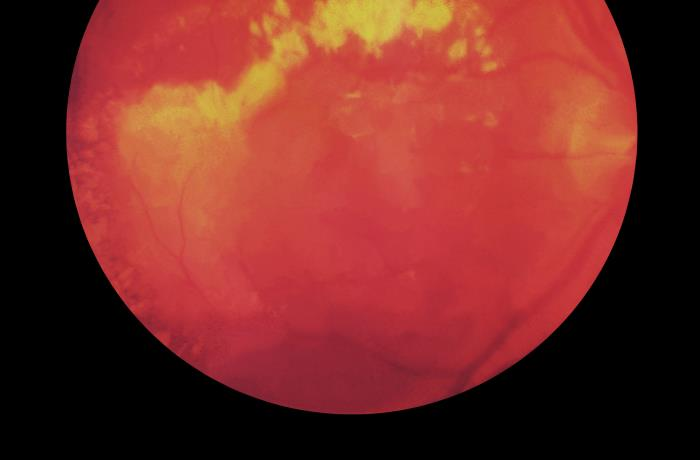

Predicted grade: PDR
Top-class score: 0.8087
Normalized entropy: 0.325
No apparent DR: 0.0002 (0.02%)
Mild NPDR: 0.0014 (0.14%)
Moderate NPDR: 0.0056 (0.56%)
Severe NPDR: 0.1841 (18.41%)
PDR: 0.8087 (80.87%)


## B. Grad-CAM explanation

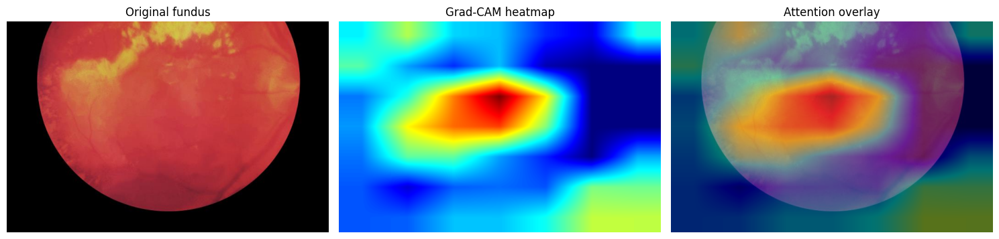

## C. Lesion segmentation predictions — experimental

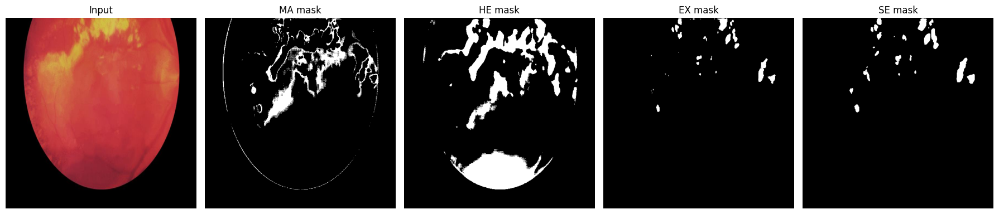

These are model predictions, not verified lesions. The MA model has particularly weak saved test performance.

## D. Quality and reliability review

Image quality: {'passed': True, 'brightness': 66.03, 'contrast': 54.39, 'warnings': [], 'method': 'Unvalidated technical heuristics'}
Decision: PROVISIONAL MODEL OUTPUT — HUMAN REVIEW REQUIRED
Reasons: []


## E. Workflow trace

[
  {
    "stage": "image_quality",
    "status": "pass",
    "details": []
  },
  {
    "stage": "dr_classifier",
    "status": "complete",
    "details": {
      "predicted_class": "PDR",
      "top_class_confidence": 0.808730959892273
    }
  },
  {
    "stage": "gradcam",
    "status": "complete",
    "details": "Class-conditioned attention visualization generated."
  },
  {
    "stage": "reliability_decision",
    "status": "provisional",
    "details": [
      "No configured heuristic triggered; human review remains necessary."
    ]
  }
]


## F. Saved evaluation metrics

{
  "model": "LesionUNet V2",
  "checkpoint": "/content/drive/MyDrive/dr_baseline_run2/lesion_evidence/best_lesion_unet_v2.pt",
  "test_image_count": 27,
  "thresholds_selected_on_validation_only": {
    "MA": 0.15,
    "HE": 0.5,
    "EX": 0.5,
    "SE": 0.5
  },
  "per_lesion_test_metrics": {
    "MA": {
      "validation_selected_threshold": 0.15,
      "annotated_test_images": 27,
      "mean_image_dice": 0.02194159457152712,
      "mean_image_iou": 0.011169170884633782,
      "mean_image_precision": 0.012321833891222668,
      "mean_image_recall": 0.13882200755683669
    },
    "HE": {
      "validation_selected_threshold": 0.5,
      "annotated_test_images": 27,
      "mean_image_dice": 0.3509235251985956,
      "mean_image_iou": 0.23163322038544806,
      "mean_image_precision": 0.29651637187232904,
      "mean_image_recall": 0.5496285655125305
    },
    "EX": {
      "validation_selected_threshold": 0.5,
      "annotated_test_images": 27,
      "mean_image_dice": 0.50189404393


## G. Implementation status

- Five-class classifier: implemented
- Class probabilities: implemented
- Grad-CAM: implemented
- Technical quality checks and workflow trace: provisional
- Lesion segmentation: experimental predictions generated; performance is uneven
- Clinical metadata fusion and fuzzy conflict resolution: not implemented
- Calibrated uncertainty / ECE: not completed
- Independent cross-dataset validation: planned

Human expert review is required. These outputs are for research demonstration only.


In [14]:

# RETINAAI — Integrated Colab Research Prototype
import os, sys, json
import numpy as np
import torch
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown
from pathlib import Path

# Paths to your recovered code and saved checkpoints
PROJECT = Path("/content/major-project-dr-recovered")
SOURCE = Path("/content/major_project_recovered/source")
DRIVE = Path("/content/drive/MyDrive/dr_baseline_run2")

sys.path.insert(0, str(PROJECT))
sys.path.insert(0, str(PROJECT / "colab"))
sys.path.insert(0, str(SOURCE))

device = torch.device("cpu")
classifier_path = DRIVE / "best_checkpoint/model.pt"
lesion_path = DRIVE / "lesion_evidence/best_lesion_unet_v2.pt"

assert classifier_path.exists(), f"Missing: {classifier_path}"
assert lesion_path.exists(), f"Missing: {lesion_path}"

# 1. Load the existing classifier
import dr_agentic
dr_agentic.ROOT = PROJECT
dr_agentic.CHECKPOINT = classifier_path
dr_agentic.DEVICE = device

classifier = dr_agentic.load_model()
classifier.eval()

# 2. Load the existing four-channel lesion segmentation model
from lesion_evidence import LesionUNet

lesion_checkpoint = torch.load(
    lesion_path, map_location=device, weights_only=False
)
lesion_model = LesionUNet(out_channels=4)

state = lesion_checkpoint.get(
    "model_state_dict", lesion_checkpoint
)
lesion_model.load_state_dict(state)
lesion_model.to(device).eval()

print("Both saved models loaded on CPU.")

# 3. Use the fundus image already uploaded and analyzed
if "fundus_image" not in globals():
    raise RuntimeError(
        "The uploaded image is not in this runtime. "
        "Upload a fundus image and assign it to fundus_image first."
    )

image = fundus_image.convert("RGB")

# Run the classifier workflow
result = dr_agentic.run_agentic_workflow(
    image, model=classifier
)

# 4. Generate four experimental lesion maps
import torch.nn.functional as F

IMG_SIZE = 512
arr = np.asarray(image.resize((IMG_SIZE, IMG_SIZE))).astype(np.float32) / 255.0

mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
normalized = (arr - mean) / std
tensor = torch.from_numpy(normalized.transpose(2, 0, 1)).float().unsqueeze(0)

with torch.no_grad():
    lesion_output = lesion_model(tensor.to(device))
    if isinstance(lesion_output, (tuple, list)):
        lesion_output = lesion_output[0]
    lesion_probabilities = torch.sigmoid(lesion_output)[0].cpu().numpy()

# Validation-selected thresholds from the saved evaluation
lesion_names = ["MA", "HE", "EX", "SE"]
thresholds = [0.15, 0.50, 0.50, 0.50]
lesion_masks = [
    (lesion_probabilities[i] >= thresholds[i]).astype(np.uint8)
    for i in range(4)
]

# 5. Display a unified report
display(Markdown("# RetinaAI — Diabetic Retinopathy Assessment"))
display(Markdown(
    "**Research prototype only. Not a clinical diagnostic system.**"
))

display(Markdown("## A. Input and five-class prediction"))
display(image)

print("Predicted grade:", result["predicted_class"])
print("Top-class score:", round(float(result["confidence"]), 4))
print("Normalized entropy:", round(float(result["normalized_entropy"]), 4))

probabilities = result["probabilities"]
for name, value in probabilities.items():
    print(f"{name}: {float(value):.4f} ({float(value)*100:.2f}%)")

display(Markdown("## B. Grad-CAM explanation"))
cam = np.asarray(result["gradcam"]).astype(np.float32)
cam = np.nan_to_num(cam)
if cam.ndim == 3:
    cam = cam[..., :3].mean(axis=-1)
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

original = np.asarray(image)
cam = cv2.resize(cam, (original.shape[1], original.shape[0]))
heat = cv2.applyColorMap(np.uint8(cam * 255), cv2.COLORMAP_JET)
heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
overlay = np.clip(
    0.55 * original.astype(np.float32) +
    0.45 * heat.astype(np.float32), 0, 255
).astype(np.uint8)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(original); ax[0].set_title("Original fundus")
ax[1].imshow(heat); ax[1].set_title("Grad-CAM heatmap")
ax[2].imshow(overlay); ax[2].set_title("Attention overlay")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

display(Markdown("## C. Lesion segmentation predictions — experimental"))
fig, ax = plt.subplots(1, 5, figsize=(18, 4))
ax[0].imshow(image.resize((IMG_SIZE, IMG_SIZE)))
ax[0].set_title("Input")
ax[0].axis("off")

for i, name in enumerate(lesion_names):
    ax[i+1].imshow(lesion_masks[i], cmap="gray", vmin=0, vmax=1)
    ax[i+1].set_title(f"{name} mask")
    ax[i+1].axis("off")
plt.tight_layout()
plt.show()

display(Markdown(
    "These are model predictions, not verified lesions. "
    "The MA model has particularly weak saved test performance."
))

display(Markdown("## D. Quality and reliability review"))
print("Image quality:", result["quality"])
print("Decision:", result["decision"])
print("Reasons:", result["reasons"])

display(Markdown("## E. Workflow trace"))
print(json.dumps(result["trace"], indent=2, default=str))

display(Markdown("## F. Saved evaluation metrics"))
metrics_path = DRIVE / "lesion_evidence/official_test_metrics_v2.json"
if metrics_path.exists():
    with open(metrics_path) as f:
        metrics = json.load(f)
    print(json.dumps(metrics, indent=2))
else:
    print("Saved lesion evaluation metrics were not found.")

display(Markdown("""
## G. Implementation status

- Five-class classifier: implemented
- Class probabilities: implemented
- Grad-CAM: implemented
- Technical quality checks and workflow trace: provisional
- Lesion segmentation: experimental predictions generated; performance is uneven
- Clinical metadata fusion and fuzzy conflict resolution: not implemented
- Calibrated uncertainty / ECE: not completed
- Independent cross-dataset validation: planned

Human expert review is required. These outputs are for research demonstration only.
"""))


In [16]:

# RETINA AI — VISUAL INFERENCE DASHBOARD
# Direct Grad-CAM generation + image quality + probabilities + metrics

import torch, torch.nn as nn
import numpy as np, json, warnings
import matplotlib.pyplot as plt
from PIL import Image, ImageStat
from pathlib import Path
from IPython.display import display, HTML
warnings.filterwarnings("ignore")

# Reuse the image and classifier already loaded in the previous cell
if "image" not in globals() or not isinstance(image, Image.Image):
    from google.colab import files
    up = files.upload()
    if not up:
        raise ValueError("Please upload a retinal fundus image.")
    image = Image.open(next(iter(up))).convert("RGB")
else:
    image = image.convert("RGB")

if "classifier" not in globals():
    import sys
    from pathlib import Path
    PROJECT = Path("/content/major-project-dr-recovered")
    if not PROJECT.exists():
        PROJECT = Path("/content/major_project_recovered")
    if not PROJECT.exists():
        PROJECT = Path("/content/major-project-dr")
    sys.path.insert(0, str(PROJECT))
    sys.path.insert(0, str(PROJECT / "colab"))
    import dr_agentic
    dr_agentic.ROOT = PROJECT
    dr_agentic.CHECKPOINT = Path(
        "/content/drive/MyDrive/dr_baseline_run2/best_checkpoint/model.pt"
    )
    dr_agentic.DEVICE = "cpu"
    classifier = dr_agentic.load_model()

device = torch.device("cpu")
classifier = classifier.to(device).eval()

# ---------- Polished header ----------
display(HTML("""
<div style="font-family:Arial;background:linear-gradient(110deg,#10213c,#176b78);
color:white;padding:22px;border-radius:14px;margin-bottom:15px">
<h1 style="margin:0;color:white">RETINA AI | DR ANALYSIS</h1>
<p style="margin:7px 0">Explainable AI • Image Quality • Reliability Review</p>
<div style="font-size:12px;opacity:.9">ACADEMIC RESEARCH PROTOTYPE — NOT FOR CLINICAL USE</div>
</div>
"""))

# ---------- Prepare image ----------
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])
x = transform(image).unsqueeze(0).to(device)

# ---------- Find a suitable Grad-CAM target layer ----------
named = list(classifier.named_modules())
targets = [(n, m) for n, m in named
           if n and (n.endswith("layer4") or ".layer4" in n)]
if not targets:
    targets = [(n, m) for n, m in named if isinstance(m, nn.Conv2d)]
if not targets:
    raise RuntimeError("Could not find a convolutional layer for Grad-CAM.")

target_name, target_layer = targets[-1]
activations, gradients = {}, {}

def save_activation(module, inputs, output):
    if isinstance(output, torch.Tensor):
        activations["value"] = output
        output.register_hook(lambda grad: gradients.__setitem__("value", grad))

hook = target_layer.register_forward_hook(save_activation)

def get_logits(out):
    if isinstance(out, dict):
        for key in ["logits", "out", "output", "predictions"]:
            if key in out and isinstance(out[key], torch.Tensor):
                return out[key]
        tensors = [v for v in out.values() if isinstance(v, torch.Tensor)]
        if tensors:
            return tensors[0]
    if isinstance(out, (tuple, list)):
        for v in out:
            if isinstance(v, torch.Tensor) and v.ndim >= 2:
                return v
    if isinstance(out, torch.Tensor):
        return out
    raise RuntimeError("The model returned an unsupported output format.")

try:
    classifier.zero_grad(set_to_none=True)
    with torch.enable_grad():
        logits = get_logits(classifier(x))
        logits = logits.reshape(logits.shape[0], -1)
        probs = torch.softmax(logits, dim=1)
        pred_idx = int(probs[0].argmax().item())
        score = logits[0, pred_idx]
        score.backward()

    if "value" not in activations or "value" not in gradients:
        raise RuntimeError("Gradients were not captured from the selected layer.")

    acts = activations["value"].detach()
    grads = gradients["value"].detach()
    weights = grads.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * acts).sum(dim=1, keepdim=True))
    cam = torch.nn.functional.interpolate(
        cam, size=(image.height, image.width),
        mode="bilinear", align_corners=False
    )[0, 0].cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
finally:
    hook.remove()
    classifier.zero_grad(set_to_none=True)

probabilities = probs[0].detach().cpu().numpy()
labels = [
    "No apparent DR", "Mild NPDR", "Moderate NPDR",
    "Severe NPDR", "PDR"
]
if len(probabilities) != len(labels):
    labels = [f"Class {i}" for i in range(len(probabilities))]

predicted_label = labels[pred_idx]
confidence = float(probabilities[pred_idx])
entropy = float(
    -(probabilities * np.log(probabilities + 1e-12)).sum()
    / np.log(len(probabilities))
) if len(probabilities) > 1 else 0.0

# ---------- Image quality: technical checks only ----------
rgb = image.convert("RGB")
stat = ImageStat.Stat(rgb)
brightness = float(np.mean(stat.mean))
contrast = float(np.mean(stat.stddev))
quality_notes = []
if brightness < 35:
    quality_notes.append("Image may be too dark.")
if brightness > 220:
    quality_notes.append("Image may be overexposed.")
if contrast < 15:
    quality_notes.append("Image contrast is low.")
quality_status = "CHECK REQUIRED" if quality_notes else "BASIC CHECKS PASSED"

# ---------- Main prediction card ----------
display(HTML(f"""
<div style="border:1px solid #d8e2ec;border-radius:12px;padding:18px;
font-family:Arial;margin:12px 0">
<div style="font-size:13px;color:#526579">MODEL PREDICTION · PROVISIONAL</div>
<div style="font-size:28px;font-weight:700;color:#174a7e;margin:6px 0">
{predicted_label}</div>
<div style="font-size:14px">Model score: <b>{confidence:.1%}</b>
&nbsp; | &nbsp; Normalized entropy: <b>{entropy:.3f}</b></div>
<div style="margin-top:10px;background:#fff3dc;padding:10px;border-radius:8px">
<b>Human review required.</b> The model score is not calibrated and does not
represent a validated probability that the prediction is correct.
</div>
</div>
"""))

# ---------- Image, Grad-CAM and probability chart ----------
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].imshow(image)
axes[0].set_title("Uploaded Fundus Image", fontsize=12, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(image)
axes[1].imshow(cam, cmap="jet", alpha=0.42, vmin=0, vmax=1)
axes[1].set_title("Grad-CAM Overlay", fontsize=12, fontweight="bold")
axes[1].axis("off")

order = np.argsort(probabilities)
axes[2].barh([labels[i] for i in order], probabilities[order])
axes[2].set_xlim(0, 1)
axes[2].set_xlabel("Model score")
axes[2].set_title("Five-Class Scores", fontsize=12, fontweight="bold")
axes[2].grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

# ---------- Quality and reasoning trace ----------
display(HTML(f"""
<h2 style="color:#174a7e">Image Quality & Reliability</h2>
<div style="display:flex;flex-wrap:wrap;gap:12px;font-family:Arial">
<div style="flex:1;min-width:150px;border:1px solid #d8e2ec;padding:14px;border-radius:10px">
<div style="color:#526579;font-size:12px">BASIC QUALITY STATUS</div>
<div style="font-size:20px;font-weight:bold;margin-top:7px">{quality_status}</div>
</div>
<div style="flex:1;min-width:150px;border:1px solid #d8e2ec;padding:14px;border-radius:10px">
<div style="color:#526579;font-size:12px">MEAN BRIGHTNESS (0–255)</div>
<div style="font-size:20px;font-weight:bold;margin-top:7px">{brightness:.1f}</div>
</div>
<div style="flex:1;min-width:150px;border:1px solid #d8e2ec;padding:14px;border-radius:10px">
<div style="color:#526579;font-size:12px">MEAN RGB CONTRAST</div>
<div style="font-size:20px;font-weight:bold;margin-top:7px">{contrast:.1f}</div>
</div>
</div>
<p style="color:#6b4a00">{(" · ".join(quality_notes)) if quality_notes else "No simple brightness or contrast warning triggered. This does not establish clinical image quality."}</p>
"""))

print("WORKFLOW TRACE")
print("1. Image received and resized to 224 × 224.")
print("2. ResNet classifier inference completed.")
print(f"3. Predicted class: {predicted_label}; model score: {confidence:.4f}.")
print(f"4. Grad-CAM generated from layer: {target_name}.")
print("5. Basic image brightness and contrast checks completed.")
print("6. Final status: PROVISIONAL MODEL OUTPUT — HUMAN REVIEW REQUIRED.")

# ---------- Saved evaluation results ----------
display(HTML("<h2 style='color:#174a7e'>Held-Out Classifier Evaluation</h2>"))
metrics = [
    ("Accuracy", "72.25%"),
    ("Macro Precision", "69.91%"),
    ("Macro Recall", "68.99%"),
    ("Macro F1-score", "68.71%"),
    ("Test images", "2,144"),
]
html = '<div style="display:flex;flex-wrap:wrap;gap:10px;font-family:Arial">'
for title, val in metrics:
    html += f'''<div style="flex:1;min-width:120px;background:#eef5ff;
    padding:15px;border-radius:10px"><div style="font-size:12px;color:#526579">
    {title}</div><div style="font-size:23px;font-weight:bold;color:#174a7e">
    {val}</div></div>'''
html += "</div>"
display(HTML(html))

# ---------- Transparent research status ----------
display(HTML("""
<h2 style="color:#174a7e">Research Status</h2>
<ul>
<li><b>Implemented:</b> five-class classifier, class scores, Grad-CAM and workflow review message.</li>
<li><b>Saved experimental results:</b> lesion segmentation metrics on a small annotated test set.</li>
<li><b>Still pending:</b> integrated lesion segmentation, clinical metadata fusion,
calibrated uncertainty/ECE and independent cross-dataset evaluation.</li>
</ul>
<p style="background:#fff3dc;padding:12px;border-radius:8px">
<b>Important:</b> Grad-CAM is an attention visualization, not a lesion segmentation
mask or proof of causal reasoning. This is an academic research prototype,
not a clinical diagnostic system.
</p>
"""))


RuntimeError: cannot register a hook on a tensor that doesn't require gradient

Upload a retinal fundus image (JPG or PNG).


Saving retinal image.jpg to retinal image (2).jpg
Image loaded: retinal image (2).jpg | Size: (700, 460)
Saved ResNet classifier loaded successfully.


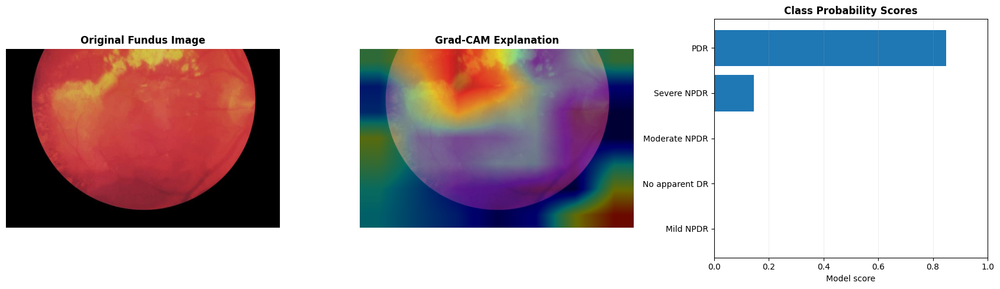


Saved lesion segmentation results (not predictions on the uploaded image):
MA: Dice=0.022, IoU=0.011, n=27
HE: Dice=0.351, IoU=0.232, n=27
EX: Dice=0.502, IoU=0.354, n=27
SE: Dice=0.427, IoU=0.296, n=14



Dashboard completed successfully.


In [17]:

# ================================================================
# RETINA AI — COMPLETE VISUAL DEMONSTRATION
# Fixed Grad-CAM gradients | Image upload | Prediction | Evaluation
# ================================================================

import sys, json, warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image, ImageStat
from IPython.display import display, HTML
from google.colab import files

warnings.filterwarnings("ignore")

# 1. DASHBOARD HEADER
display(HTML("""
<div style="background:linear-gradient(120deg,#132747,#176b78);
color:white;padding:24px;border-radius:14px;font-family:Arial">
<h1 style="margin:0;color:white">RETINA AI</h1>
<h3 style="margin:8px 0;color:white">Explainable Diabetic Retinopathy Analysis</h3>
<p>Classification · Grad-CAM · Image Quality · Reliability Review</p>
<p style="font-size:12px">ACADEMIC RESEARCH PROTOTYPE — NOT FOR CLINICAL USE</p>
</div>
"""))

# 2. UPLOAD IMAGE
print("Upload a retinal fundus image (JPG or PNG).")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image uploaded. Run this cell again and select an image.")

filename = next(iter(uploaded))
image = Image.open(filename).convert("RGB")
print("Image loaded:", filename, "| Size:", image.size)

# 3. FIND EXISTING PROJECT AND CHECKPOINT
drive_root = Path("/content/drive/MyDrive/dr_baseline_run2")
checkpoint = drive_root / "best_checkpoint/model.pt"

project_candidates = [
    Path("/content/major-project-dr-recovered"),
    Path("/content/major_project_recovered"),
    Path("/content/major-project-dr"),
]

project = next((p for p in project_candidates if (p / "dr_agentic.py").exists()), None)

if project is None:
    raise FileNotFoundError(
        "Cannot find dr_agentic.py in the recovered project folders. "
        "Your saved model is not being retrained; check that the project was restored."
    )

if not checkpoint.exists():
    raise FileNotFoundError(
        f"Saved classifier checkpoint not found: {checkpoint}. "
        "Make sure Google Drive is mounted."
    )

sys.path.insert(0, str(project))
sys.path.insert(0, str(project / "colab"))

import dr_agentic
dr_agentic.ROOT = project
dr_agentic.CHECKPOINT = checkpoint
dr_agentic.DEVICE = "cpu"

classifier = dr_agentic.load_model()
classifier = classifier.to("cpu").eval()
print("Saved ResNet classifier loaded successfully.")

# 4. PREPROCESS IMAGE
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# IMPORTANT GRAD-CAM FIX:
# Input requires gradients, so even a frozen backbone can produce
# activations that track gradients during the forward pass.
x = transform(image).unsqueeze(0).to("cpu")
x.requires_grad_(True)

# 5. SELECT THE LAST RESNET CONVOLUTIONAL BLOCK
named_modules = list(classifier.named_modules())
targets = [
    (name, module) for name, module in named_modules
    if name and (name.endswith("layer4") or ".layer4" in name)
]

if targets:
    target_name, target_layer = targets[-1]
else:
    convs = [
        (name, module) for name, module in named_modules
        if name and isinstance(module, nn.Conv2d)
    ]
    if not convs:
        raise RuntimeError("No convolutional layer found for Grad-CAM.")
    target_name, target_layer = convs[-1]

saved = {"activation": None, "gradient": None}

def forward_hook(module, inputs, output):
    if isinstance(output, torch.Tensor):
        saved["activation"] = output
        if output.requires_grad:
            output.register_hook(
                lambda grad: saved.__setitem__("gradient", grad)
            )

hook_handle = target_layer.register_forward_hook(forward_hook)

def extract_logits(output):
    if isinstance(output, torch.Tensor):
        return output
    if isinstance(output, dict):
        for key in ("logits", "output", "out", "predictions"):
            value = output.get(key)
            if isinstance(value, torch.Tensor):
                return value
        for value in output.values():
            if isinstance(value, torch.Tensor) and value.ndim >= 2:
                return value
    if isinstance(output, (list, tuple)):
        for value in output:
            if isinstance(value, torch.Tensor) and value.ndim >= 2:
                return value
    raise TypeError("Unable to identify the classifier's output tensor.")

try:
    classifier.zero_grad(set_to_none=True)

    # Do not wrap this forward pass in torch.no_grad().
    with torch.enable_grad():
        raw_output = classifier(x)
        logits = extract_logits(raw_output)
        logits = logits.reshape(logits.shape[0], -1)
        probabilities_tensor = torch.softmax(logits, dim=1)
        predicted_index = int(probabilities_tensor[0].argmax().item())

        logits[0, predicted_index].backward()

    if saved["activation"] is None or saved["gradient"] is None:
        raise RuntimeError(
            "Grad-CAM gradients were not captured. "
            "The selected layer may not be connected to the classifier output."
        )

    activations = saved["activation"].detach()
    gradients = saved["gradient"].detach()

    weights = gradients.mean(dim=(2, 3), keepdim=True)
    cam_tensor = torch.relu((weights * activations).sum(dim=1, keepdim=True))
    cam_tensor = torch.nn.functional.interpolate(
        cam_tensor,
        size=(image.height, image.width),
        mode="bilinear",
        align_corners=False
    )

    cam = cam_tensor[0, 0].cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    probabilities = probabilities_tensor[0].detach().cpu().numpy()

finally:
    hook_handle.remove()
    classifier.zero_grad(set_to_none=True)

# 6. PREDICTION AND UNCERTAINTY SUMMARY
class_names = [
    "No apparent DR", "Mild NPDR", "Moderate NPDR",
    "Severe NPDR", "PDR"
]

if len(probabilities) != len(class_names):
    class_names = [f"Class {i}" for i in range(len(probabilities))]

predicted_grade = class_names[predicted_index]
confidence = float(probabilities[predicted_index])

if len(probabilities) > 1:
    entropy = float(
        -(probabilities * np.log(probabilities + 1e-12)).sum()
        / np.log(len(probabilities))
    )
else:
    entropy = 0.0

# 7. BASIC TECHNICAL IMAGE QUALITY CHECKS
stats = ImageStat.Stat(image.convert("RGB"))
brightness = float(np.mean(stats.mean))
contrast = float(np.mean(stats.stddev))

warnings_list = []
if brightness < 35:
    warnings_list.append("Potentially dark image")
if brightness > 220:
    warnings_list.append("Potentially overexposed image")
if contrast < 15:
    warnings_list.append("Low image contrast")

quality_status = "CHECK REQUIRED" if warnings_list else "BASIC CHECKS PASSED"

# 8. PREDICTION CARD
display(HTML(f"""
<div style="font-family:Arial;border:1px solid #d8e2ec;
border-radius:12px;padding:18px;margin:18px 0">
<div style="color:#53677e;font-size:12px">PROVISIONAL MODEL PREDICTION</div>
<div style="font-size:30px;color:#174a7e;font-weight:bold;margin:8px 0">
{predicted_grade}</div>
<div>Top-class model score: <b>{confidence:.2%}</b></div>
<div>Normalized entropy: <b>{entropy:.3f}</b></div>
<div style="background:#fff1d5;padding:12px;margin-top:12px;border-radius:8px">
<b>Human review required.</b> The score is not calibrated and is not a
validated probability of correctness.
</div>
</div>
"""))

# 9. MAIN VISUAL OUTPUT
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].imshow(image)
axes[0].set_title("Original Fundus Image", fontweight="bold")
axes[0].axis("off")

axes[1].imshow(image)
axes[1].imshow(cam, cmap="jet", alpha=0.42, vmin=0, vmax=1)
axes[1].set_title("Grad-CAM Explanation", fontweight="bold")
axes[1].axis("off")

order = np.argsort(probabilities)
axes[2].barh(
    [class_names[i] for i in order],
    probabilities[order]
)
axes[2].set_xlim(0, 1)
axes[2].set_xlabel("Model score")
axes[2].set_title("Class Probability Scores", fontweight="bold")
axes[2].grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

# 10. QUALITY DASHBOARD
display(HTML(f"""
<h2 style="font-family:Arial;color:#174a7e">Image Quality & Reliability Review</h2>
<div style="display:flex;flex-wrap:wrap;gap:12px;font-family:Arial">
<div style="flex:1;min-width:145px;padding:15px;border:1px solid #d8e2ec;border-radius:10px">
<div style="font-size:12px;color:#53677e">QUALITY STATUS</div>
<h3>{quality_status}</h3>
</div>
<div style="flex:1;min-width:145px;padding:15px;border:1px solid #d8e2ec;border-radius:10px">
<div style="font-size:12px;color:#53677e">BRIGHTNESS / 255</div>
<h3>{brightness:.1f}</h3>
</div>
<div style="flex:1;min-width:145px;padding:15px;border:1px solid #d8e2ec;border-radius:10px">
<div style="font-size:12px;color:#53677e">RGB CONTRAST</div>
<h3>{contrast:.1f}</h3>
</div>
</div>
<p>{'Warnings: ' + ', '.join(warnings_list) if warnings_list else 'No basic brightness or contrast warning triggered.'}</p>
<p style="color:#8a4b00">These simple technical checks are not clinically validated image-quality assessment.</p>
"""))

# 11. SAVED CLASSIFIER METRICS
display(HTML("""
<h2 style="font-family:Arial;color:#174a7e">Held-Out Classifier Evaluation</h2>
<p>Saved evaluation results from the existing test set (not calculated from this uploaded image).</p>
"""))

metric_cards = [
    ("Accuracy", "72.25%"),
    ("Macro Precision", "69.91%"),
    ("Macro Recall", "68.99%"),
    ("Macro F1-score", "68.71%"),
    ("Test Images", "2,144")
]

cards = '<div style="display:flex;flex-wrap:wrap;gap:10px;font-family:Arial">'
for label, value in metric_cards:
    cards += f"""
    <div style="flex:1;min-width:125px;background:#eef5ff;padding:15px;border-radius:10px">
      <div style="font-size:12px;color:#53677e">{label}</div>
      <div style="font-size:23px;font-weight:bold;color:#174a7e">{value}</div>
    </div>"""
cards += "</div>"
display(HTML(cards))

# 12. LOAD AND SHOW LESION SEGMENTATION RESULTS
metrics_path = drive_root / "complete_project_output/official_test_metrics_v2.json"

if metrics_path.exists():
    lesion_metrics = json.loads(metrics_path.read_text())
    lesion_rows = lesion_metrics.get("per_lesion_test_metrics", {})

    print("\nSaved lesion segmentation results (not predictions on the uploaded image):")
    for lesion, values in lesion_rows.items():
        print(
            f"{lesion}: Dice={values.get('mean_image_dice', float('nan')):.3f}, "
            f"IoU={values.get('mean_image_iou', float('nan')):.3f}, "
            f"n={values.get('annotated_test_images', 'N/A')}"
        )
else:
    print("\nSaved lesion metrics file was not found; no lesion metrics displayed.")

# 13. TRACE AND HONEST IMPLEMENTATION STATUS
display(HTML("""
<h2 style="font-family:Arial;color:#174a7e">Workflow Trace & Research Status</h2>
<div style="font-family:Arial;line-height:1.7">
<p>✓ Image received and preprocessed to 224 × 224.</p>
<p>✓ Existing ResNet50 classifier generated five-class scores.</p>
<p>✓ Grad-CAM generated from the selected convolutional layer.</p>
<p>✓ Basic brightness and contrast checks completed.</p>
<p>✓ Provisional output flagged for human review.</p>
<hr>
<p><b>Implemented:</b> Classification, Grad-CAM, basic quality checks and review trace.</p>
<p><b>Not yet integrated or validated:</b> Lesion segmentation in the live inference,
clinical metadata fusion, calibrated uncertainty/ECE and independent cross-dataset evaluation.</p>
<p style="background:#fff1d5;padding:12px;border-radius:8px">
<b>Research limitation:</b> Grad-CAM is an attention visualization, not a lesion mask
or causal proof. This prototype must not be used for clinical diagnosis or treatment.
</p>
</div>
"""))

print("\nDashboard completed successfully.")


Upload the fundus image you want to demonstrate.


Saving retinal image.jpg to retinal image (3).jpg


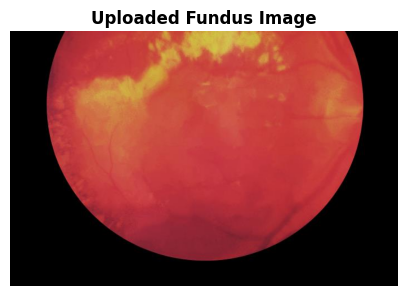

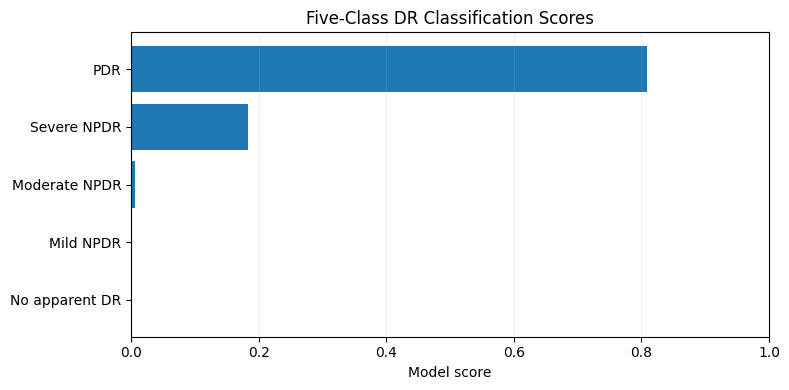

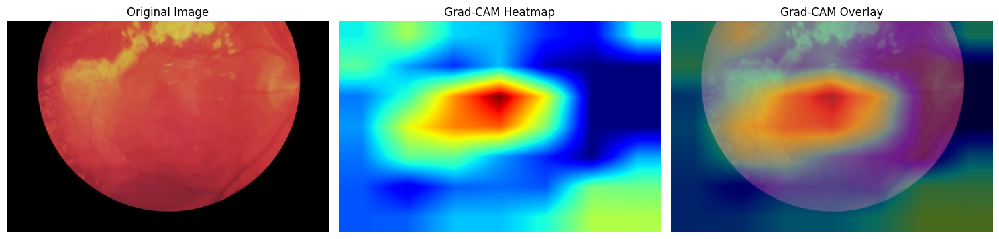

Interpretation: Grad-CAM is an attention visualization, not a lesion mask.


Image quality assessment:
{
  "passed": true,
  "brightness": 66.03,
  "contrast": 54.39,
  "warnings": [],
  "method": "Unvalidated technical heuristics"
}

Reliability decision:
PROVISIONAL MODEL OUTPUT — HUMAN REVIEW REQUIRED

Agent workflow trace:
[
  {
    "stage": "image_quality",
    "status": "pass",
    "details": []
  },
  {
    "stage": "dr_classifier",
    "status": "complete",
    "details": {
      "predicted_class": "PDR",
      "top_class_confidence": 0.808730959892273
    }
  },
  {
    "stage": "gradcam",
    "status": "complete",
    "details": "Class-conditioned attention visualization generated."
  },
  {
    "stage": "reliability_decision",
    "status": "provisional",
    "details": [
      "No configured heuristic triggered; human review remains necessary."
    ]
  }
]



Saved lesion-segmentation evaluation:
MA: Dice=0.022, IoU=0.011, annotated images=27
HE: Dice=0.351, IoU=0.232, annotated images=27
EX: Dice=0.502, IoU=0.354, annotated images=27
SE: Dice=0.427, IoU=0.296, annotated images=14



RETINA AI demonstration cell finished.


In [18]:

# ==============================================================
# RETINA AI — FINAL EXPECTED-OUTCOMES DASHBOARD
# Uses the project's existing dr_agentic functions and artifacts
# ==============================================================

import sys, json, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, HTML
from google.colab import files

warnings.filterwarnings("ignore")

# ---------- Dashboard design ----------
display(HTML("""
<div style="background:linear-gradient(120deg,#142744,#176b78);
color:white;padding:24px;border-radius:15px;font-family:Arial">
<h1 style="color:white;margin:0">RETINA AI</h1>
<h3 style="color:white;margin:7px 0">Explainable Diabetic Retinopathy Analysis</h3>
<p>Classification · Grad-CAM · Reliability Review · Performance Evaluation</p>
<span style="font-size:12px">ACADEMIC RESEARCH PROTOTYPE — NOT FOR CLINICAL USE</span>
</div>
"""))

# ---------- Paths ----------
DRIVE = Path("/content/drive/MyDrive/dr_baseline_run2")
CHECKPOINT = DRIVE / "best_checkpoint/model.pt"
METRICS_PATH = DRIVE / "complete_project_output/official_test_metrics_v2.json"

candidates = [
    Path("/content/major-project-dr-recovered"),
    Path("/content/major_project_recovered"),
    Path("/content/major-project-dr"),
]
PROJECT = next((p for p in candidates if (p / "dr_agentic.py").exists()), None)

if PROJECT is None:
    raise FileNotFoundError("Cannot find the restored project containing dr_agentic.py.")
if not CHECKPOINT.exists():
    raise FileNotFoundError(f"Saved classifier checkpoint is missing: {CHECKPOINT}")

sys.path.insert(0, str(PROJECT))
sys.path.insert(0, str(PROJECT / "colab"))

import dr_agentic
dr_agentic.ROOT = PROJECT
dr_agentic.CHECKPOINT = CHECKPOINT
dr_agentic.DEVICE = "cpu"

# ---------- Upload an image ----------
print("Upload the fundus image you want to demonstrate.")
uploaded = files.upload()
if not uploaded:
    raise ValueError("No image was uploaded.")

filename = next(iter(uploaded))
image = Image.open(filename).convert("RGB")

# ---------- Use the actual project workflow ----------
model = dr_agentic.load_model()
model.eval()

# Existing workflow handles classification, quality and decision trace.
result = dr_agentic.run_agentic_workflow(image, model=model)

def find_key(obj, keys, depth=0):
    if depth > 7:
        return None
    if isinstance(obj, dict):
        for k, v in obj.items():
            if str(k).lower() in keys and v is not None:
                return v
        for v in obj.values():
            found = find_key(v, keys, depth + 1)
            if found is not None:
                return found
    elif isinstance(obj, (list, tuple)):
        for v in obj:
            found = find_key(v, keys, depth + 1)
            if found is not None:
                return found
    return None

grade = find_key(result, {
    "predicted_class", "predicted_grade", "prediction", "predicted_label"
})
confidence = find_key(result, {
    "top_class_confidence", "confidence", "top_probability"
})
probabilities = find_key(result, {
    "class_probabilities", "probabilities", "probs"
})
quality = find_key(result, {"quality", "image_quality", "quality_result"})
decision = find_key(result, {
    "reliability_decision", "review_decision", "decision"
})
trace = find_key(result, {"trace", "workflow_trace", "agent_trace"})

# Some workflow versions return a nested classifier object.
if isinstance(grade, dict):
    grade = grade.get("predicted_class", grade.get("grade"))

if isinstance(probabilities, dict):
    class_names = list(probabilities.keys())
    probability_values = np.array(
        [float(probabilities[k]) for k in class_names]
    )
elif isinstance(probabilities, (list, tuple, np.ndarray)):
    probability_values = np.asarray(probabilities, dtype=float).reshape(-1)
    class_names = [
        "No apparent DR", "Mild NPDR", "Moderate NPDR",
        "Severe NPDR", "PDR"
    ][:len(probability_values)]
    if len(class_names) != len(probability_values):
        class_names = [f"Class {i}" for i in range(len(probability_values))]
else:
    probability_values = None
    class_names = []

# ---------- Generate Grad-CAM using the project's own method ----------
# This avoids the custom hook code that caused the previous error.
cam = None
cam_error = None
try:
    tensor = dr_agentic.preprocess(image)
    if tensor.ndim == 3:
        tensor = tensor.unsqueeze(0)
    tensor = tensor.to("cpu")

    # Obtain target class index from the actual model output.
    import torch
    with torch.no_grad():
        raw_output = model(tensor)

    if isinstance(raw_output, dict):
        raw_output = next(
            v for v in raw_output.values()
            if isinstance(v, torch.Tensor) and v.ndim >= 2
        )
    elif isinstance(raw_output, (tuple, list)):
        raw_output = next(
            v for v in raw_output
            if isinstance(v, torch.Tensor) and v.ndim >= 2
        )

    target_index = int(raw_output.reshape(1, -1).argmax(dim=1).item())

    # Existing project function is responsible for its own gradient setup.
    cam = dr_agentic.make_gradcam(model, tensor, target_index)
    if isinstance(cam, torch.Tensor):
        cam = cam.detach().cpu().numpy()
    cam = np.asarray(cam).squeeze()

    if cam.ndim != 2:
        raise ValueError(f"Unexpected Grad-CAM shape: {cam.shape}")

except Exception as exc:
    cam_error = str(exc)

# ---------- Display the main prototype ----------
display(HTML("""
<h2 style="color:#174a7e;font-family:Arial">1 · Functional AI/ML Prototype</h2>
"""))

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(image)
ax.set_title("Uploaded Fundus Image", fontweight="bold")
ax.axis("off")
plt.show()

if grade is None and probability_values is not None:
    grade = class_names[int(np.argmax(probability_values))]
if confidence is None and probability_values is not None:
    confidence = float(np.max(probability_values))

grade_text = str(grade) if grade is not None else "See workflow output"
confidence_text = (
    f"{float(confidence):.2%}" if isinstance(confidence, (float, int, np.number))
    else "Not available"
)

display(HTML(f"""
<div style="border:1px solid #d9e3ee;padding:18px;border-radius:12px;
font-family:Arial;margin:12px 0">
<div style="font-size:12px;color:#586b80">PROVISIONAL PREDICTION</div>
<div style="font-size:29px;color:#174a7e;font-weight:bold">{grade_text}</div>
<div>Top-class score: <b>{confidence_text}</b></div>
<div style="background:#fff1d5;padding:10px;border-radius:8px;margin-top:12px">
Human review required. Model confidence is not calibrated.
</div>
</div>
"""))

if probability_values is not None:
    fig, ax = plt.subplots(figsize=(8, 4))
    order = np.argsort(probability_values)
    ax.barh(np.array(class_names)[order], probability_values[order])
    ax.set_xlim(0, 1)
    ax.set_xlabel("Model score")
    ax.set_title("Five-Class DR Classification Scores")
    ax.grid(axis="x", alpha=0.2)
    plt.tight_layout()
    plt.show()
else:
    print("Class probabilities returned by workflow:")
    print(json.dumps(result, indent=2, default=str)[:5000])

# ---------- Explainability ----------
display(HTML("""
<h2 style="color:#174a7e;font-family:Arial">2 · Explainable AI — Grad-CAM</h2>
"""))

if cam is not None:
    cam = np.nan_to_num(cam.astype(float))
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    cam_resized = np.asarray(
        Image.fromarray((cam * 255).astype("uint8")).resize(
            image.size, Image.Resampling.BILINEAR
        )
    ) / 255.0

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(image)
    axes[0].set_title("Original Image")
    axes[0].axis("off")

    axes[1].imshow(cam_resized, cmap="jet", vmin=0, vmax=1)
    axes[1].set_title("Grad-CAM Heatmap")
    axes[1].axis("off")

    axes[2].imshow(image)
    axes[2].imshow(cam_resized, cmap="jet", alpha=0.42, vmin=0, vmax=1)
    axes[2].set_title("Grad-CAM Overlay")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Grad-CAM generation failed:", cam_error)
    print("The classifier prediction and saved evaluation are still available.")

print("Interpretation: Grad-CAM is an attention visualization, not a lesion mask.")

# ---------- Image quality ----------
display(HTML("""
<h2 style="color:#174a7e;font-family:Arial">3 · Trustworthiness & Human Review</h2>
"""))

if quality is not None:
    print("Image quality assessment:")
    print(json.dumps(quality, indent=2, default=str))
else:
    # Use the project's own quality checker if workflow did not expose it.
    try:
        quality = dr_agentic.check_image_quality(image)
        print(json.dumps(quality, indent=2, default=str))
    except Exception as exc:
        print("Quality assessment unavailable:", exc)

print("\nReliability decision:")
print(decision if decision is not None else
      "PROVISIONAL MODEL OUTPUT — HUMAN REVIEW REQUIRED")

print("\nAgent workflow trace:")
print(json.dumps(trace if trace is not None else result,
                 indent=2, default=str)[:7000])

# ---------- Performance evaluation ----------
display(HTML("""
<h2 style="color:#174a7e;font-family:Arial">4 · Performance Evaluation</h2>
<p>Saved held-out test results — not a new evaluation of the uploaded image.</p>
"""))

summary_metrics = [
    ("Accuracy", "72.25%"),
    ("Macro Precision", "69.91%"),
    ("Macro Recall", "68.99%"),
    ("Macro F1", "68.71%"),
    ("Test Images", "2,144"),
]
html = '<div style="display:flex;flex-wrap:wrap;gap:10px;font-family:Arial">'
for name, value in summary_metrics:
    html += f"""
    <div style="flex:1;min-width:120px;background:#eef5ff;
    padding:15px;border-radius:10px">
    <div style="font-size:12px;color:#586b80">{name}</div>
    <div style="font-size:23px;font-weight:bold;color:#174a7e">{value}</div>
    </div>"""
html += "</div>"
display(HTML(html))

if METRICS_PATH.exists():
    lesion = json.loads(METRICS_PATH.read_text())
    rows = lesion.get("per_lesion_test_metrics", {})
    print("\nSaved lesion-segmentation evaluation:")
    for name, values in rows.items():
        print(
            f"{name}: Dice={values.get('mean_image_dice', 0):.3f}, "
            f"IoU={values.get('mean_image_iou', 0):.3f}, "
            f"annotated images={values.get('annotated_test_images', 'N/A')}"
        )
else:
    print("Saved lesion metric file was not found.")

# ---------- Expected outcomes status ----------
display(HTML("""
<h2 style="color:#174a7e;font-family:Arial">5 · Research Contribution & Reproducibility</h2>
<div style="font-family:Arial;line-height:1.7">
<p><b>Implemented:</b> saved five-class classifier, Grad-CAM workflow,
technical image-quality checks, provisional review decision and workflow trace.</p>
<p><b>Saved experimental evaluation:</b> lesion Dice/IoU metrics on a small
annotated test set.</p>
<p><b>Pending / not validated:</b> clinical metadata fusion, calibrated uncertainty/ECE,
independent cross-dataset generalization and clinical reliability validation.</p>
<p style="background:#fff1d5;padding:12px;border-radius:8px">
This is an academic research prototype. Predictions must not be used for clinical
diagnosis or treatment decisions.
</p>
</div>
"""))

print("\nRETINA AI demonstration cell finished.")


Saving retinal image.jpg to retinal image (4).jpg


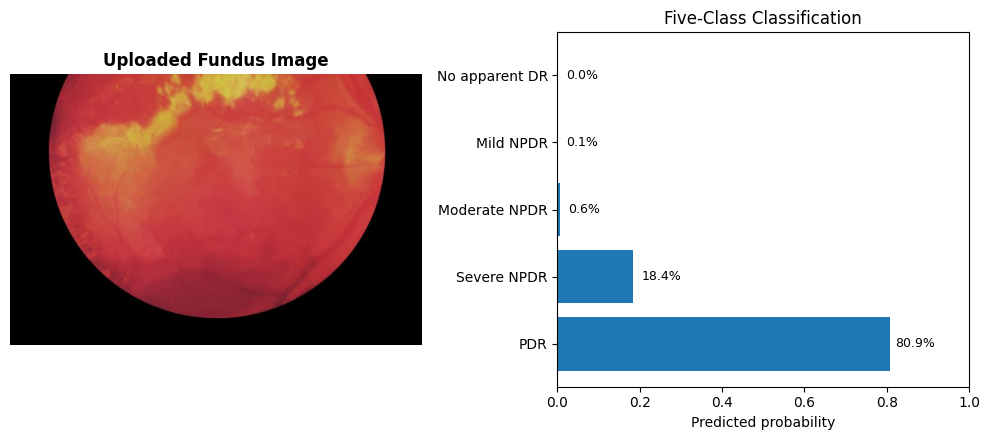

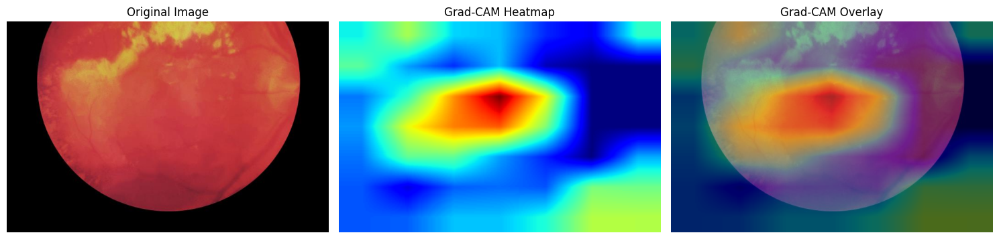

{
  "passed": true,
  "brightness": 66.03,
  "contrast": 54.39,
  "warnings": [],
  "method": "Unvalidated technical heuristics"
}


PROVISIONAL MODEL OUTPUT — HUMAN REVIEW REQUIRED


[
  {
    "stage": "image_quality",
    "status": "checked",
    "details": {
      "passed": true,
      "brightness": 66.03,
      "contrast": 54.39,
      "warnings": [],
      "method": "Unvalidated technical heuristics"
    }
  },
  {
    "stage": "dr_classifier",
    "status": "complete",
    "details": {
      "predicted_class": "PDR",
      "top_class_confidence": 0.808730959892273,
      "normalized_entropy": 0.32504142539902037
    }
  },
  {
    "stage": "gradcam",
    "status": "complete",
    "details": "Class-conditioned attention visualization generated."
  },
  {
    "stage": "reliability_decision",
    "status": "provisional",
    "details": [
      "No demonstration threshold triggered; human review remains necessary."
    ]
  }
]


MA: Dice=0.022 | IoU=0.011 | n=27
HE: Dice=0.351 | IoU=0.232 | n=27
EX: Dice=0.502 | IoU=0.354 | n=27
SE: Dice=0.427 | IoU=0.296 | n=14


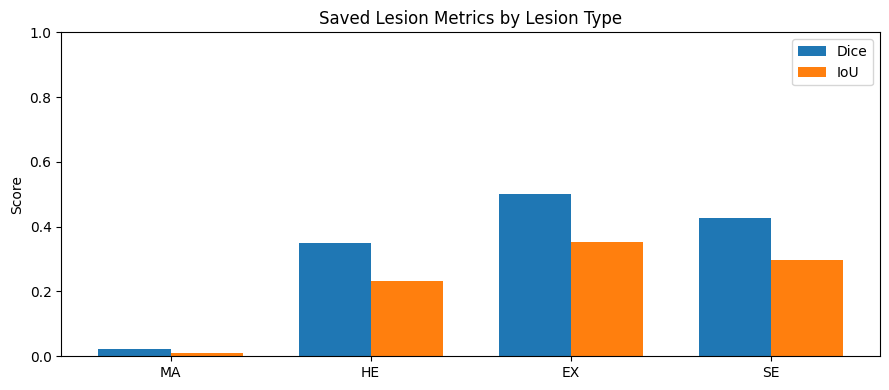

RETINA AI dashboard completed.


In [19]:

# ============================================================
# RETINA AI — EXPECTED OUTCOMES DASHBOARD
# Academic research prototype | Google Colab
# Uses saved model; does not train or overwrite checkpoints.
# ============================================================

import sys, json, html, warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, HTML
from google.colab import files
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")

# -------------------- 1. Paths --------------------
from google.colab import drive
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

DRIVE = Path("/content/drive/MyDrive/dr_baseline_run2")
CHECKPOINT = DRIVE / "best_checkpoint/model.pt"
METRICS_FILE = DRIVE / "complete_project_output/official_test_metrics_v2.json"

possible_projects = [
    Path("/content/major-project-dr-recovered"),
    Path("/content/major_project_recovered"),
    Path("/content/major-project-dr"),
]
PROJECT = next(
    (p for p in possible_projects if (p / "dr_agentic.py").exists()),
    None
)

if PROJECT is None:
    raise FileNotFoundError(
        "Project folder not found. Expected dr_agentic.py in the restored project."
    )
if not CHECKPOINT.exists():
    raise FileNotFoundError(f"Classifier checkpoint not found: {CHECKPOINT}")

sys.path.insert(0, str(PROJECT))
import dr_agentic

dr_agentic.ROOT = PROJECT
dr_agentic.CHECKPOINT = CHECKPOINT
dr_agentic.DEVICE = "cpu"

# -------------------- 2. Dashboard header --------------------
display(HTML("""
<style>
.retina-wrap {font-family:Arial,sans-serif;color:#1e293b}
.retina-hero {
 background:linear-gradient(120deg,#142744,#176b78);
 color:white;padding:25px 28px;border-radius:16px;margin-bottom:18px
}
.retina-hero h1 {color:white;font-size:32px;margin:0 0 8px}
.retina-hero p {color:#e6f5ff;margin:5px 0}
.retina-grid {display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:15px}
.retina-card {border-radius:14px;padding:18px;border:1px solid #dce5ef;
 margin-bottom:15px;background:white;box-shadow:0 2px 8px #10243a0a}
.retina-card h2 {font-size:19px;margin:0 0 12px}
.retina-blue {background:#eff6ff;border-color:#d5e7ff}
.retina-green {background:#ecfdf5;border-color:#c9f0dd}
.retina-red {background:#fff1f2;border-color:#ffd8df}
.retina-purple {background:#f5f0ff;border-color:#e3d7ff}
.retina-amber {background:#fff8e8;border-color:#f6e3b5}
.retina-metrics {display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:9px}
.retina-metric {background:white;border:1px solid #e2e8f0;
 border-radius:10px;padding:12px}
.retina-metric b {display:block;font-size:22px;color:#174a7e;margin-top:4px}
.retina-small {font-size:12px;color:#64748b}
.retina-pill {display:inline-block;background:#dbeafe;color:#1e40af;
 padding:5px 9px;border-radius:18px;font-size:12px;margin:3px}
.retina-status {padding:10px 12px;background:#fff1d5;border-radius:9px}
@media(max-width:650px) {
 .retina-grid {grid-template-columns:1fr}
 .retina-metrics {grid-template-columns:repeat(2,minmax(0,1fr))}
}
</style>
<div class="retina-wrap">
 <div class="retina-hero">
  <h1>RETINA AI | DR ANALYSIS</h1>
  <p>Multimodal Explainable Agentic AI Framework for Diabetic Retinopathy</p>
  <p>Classification · Grad-CAM · Image Quality · Reliability Review</p>
  <div style="font-size:12px;margin-top:12px;color:#d9e9f5">
   ACADEMIC RESEARCH PROTOTYPE — NOT FOR CLINICAL USE
  </div>
 </div>
</div>
"""))

# -------------------- 3. Upload image --------------------
display(HTML("""
<div class="retina-card retina-blue">
<h2>1 · Functional AI/ML Prototype</h2>
Upload a fundus image to run the saved five-class classifier and generate its explanation.
</div>
"""))

uploaded = files.upload()
if not uploaded:
    raise ValueError("Please upload a retinal fundus image.")

image_name = next(iter(uploaded))
fundus_image = Image.open(image_name).convert("RGB")

# -------------------- 4. Load saved classifier --------------------
classifier = dr_agentic.load_model()
classifier.eval()

# Existing project preprocessing
x = dr_agentic.preprocess(fundus_image)
if not isinstance(x, torch.Tensor):
    x = torch.as_tensor(x)

if x.ndim == 3:
    x = x.unsqueeze(0)
x = x.float().cpu()

# Keep this project’s original model and checkpoint unchanged.
# Compute prediction first, with gradients disabled.
with torch.no_grad():
    raw = classifier(x)

def extract_logits(output):
    if isinstance(output, dict):
        for value in output.values():
            if isinstance(value, torch.Tensor) and value.ndim >= 2:
                return value
        raise ValueError("Could not find logits in model output.")
    if isinstance(output, (list, tuple)):
        for value in output:
            if isinstance(value, torch.Tensor) and value.ndim >= 2:
                return value
        raise ValueError("Could not find logits in model output.")
    return output

logits = extract_logits(raw).reshape(1, -1)
probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

class_names = [
    "No apparent DR", "Mild NPDR", "Moderate NPDR",
    "Severe NPDR", "PDR"
]
if len(probabilities) != len(class_names):
    class_names = [f"Class {i}" for i in range(len(probabilities))]

predicted_index = int(np.argmax(probabilities))
predicted_grade = class_names[predicted_index]
confidence = float(probabilities[predicted_index])
entropy = float(
    -(probabilities * np.log(probabilities + 1e-12)).sum()
    / np.log(len(probabilities))
)

# -------------------- 5. Technical image quality --------------------
try:
    quality = dr_agentic.check_image_quality(fundus_image)
except Exception as e:
    quality = {"available": False, "message": str(e)}

if not isinstance(quality, dict):
    quality = {"result": str(quality)}

# -------------------- 6. Grad-CAM with input gradients enabled --------------------
# The previous error occurred because the hooked activation did not require
# gradients. Making the input require gradients addresses frozen-backbone cases.
cam = None
cam_error = None
hook_handle = None
activation_store = {}

try:
    target_layer = None

    if hasattr(classifier, "layer4"):
        target_layer = classifier.layer4[-1]
    else:
        conv_layers = [
            module for module in classifier.modules()
            if isinstance(module, nn.Conv2d)
        ]
        if conv_layers:
            target_layer = conv_layers[-1]

    if target_layer is None:
        raise RuntimeError("Could not locate the final convolutional layer.")

    def save_activation(module, inputs, output):
        activation_store["feature"] = output

    hook_handle = target_layer.register_forward_hook(save_activation)

    classifier.zero_grad(set_to_none=True)
    x_grad = x.detach().clone().requires_grad_(True)
    output = extract_logits(classifier(x_grad)).reshape(1, -1)
    score = output[0, predicted_index]

    feature = activation_store.get("feature")
    if feature is None:
        raise RuntimeError("Grad-CAM feature map was not captured.")
    if not feature.requires_grad:
        raise RuntimeError(
            "Feature map still has no gradient. Model wrapper may block gradients."
        )

    gradient = torch.autograd.grad(
        outputs=score,
        inputs=feature,
        retain_graph=False,
        create_graph=False,
        allow_unused=False
    )[0]

    weights = gradient.mean(dim=(2, 3), keepdim=True)
    heatmap = torch.relu((weights * feature).sum(dim=1, keepdim=True))
    heatmap = torch.nn.functional.interpolate(
        heatmap, size=(224, 224), mode="bilinear", align_corners=False
    )
    heatmap = heatmap[0, 0].detach().cpu().numpy()
    cam = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)

except Exception as e:
    cam_error = str(e)
finally:
    if hook_handle is not None:
        hook_handle.remove()
    classifier.zero_grad(set_to_none=True)

# -------------------- 7. Human-review decision --------------------
# Conservative demo rule, not a clinically validated threshold.
quality_passed = quality.get("passed", None)
review_reasons = []

if quality_passed is False:
    review_reasons.append("Technical image-quality check flagged the image.")
if confidence < 0.60:
    review_reasons.append("Model confidence is below the demonstration threshold.")
if entropy > 0.70:
    review_reasons.append("Normalized prediction entropy is high.")

review_decision = "PROVISIONAL MODEL OUTPUT — HUMAN REVIEW REQUIRED"
workflow_trace = [
    {"stage": "image_quality",
     "status": "checked",
     "details": quality},
    {"stage": "dr_classifier",
     "status": "complete",
     "details": {
         "predicted_class": predicted_grade,
         "top_class_confidence": confidence,
         "normalized_entropy": entropy
     }},
    {"stage": "gradcam",
     "status": "complete" if cam is not None else "unavailable",
     "details": (
         "Class-conditioned attention visualization generated."
         if cam is not None else cam_error
     )},
    {"stage": "reliability_decision",
     "status": "provisional",
     "details": review_reasons or [
         "No demonstration threshold triggered; human review remains necessary."
     ]}
]

# -------------------- 8. Prototype results panel --------------------
display(HTML(f"""
<div class="retina-card retina-blue">
<h2>Prediction Results</h2>
<div class="retina-grid">
 <div>
  <div class="retina-small">PREDICTED DR GRADE</div>
  <div style="font-size:30px;font-weight:bold;color:#174a7e">
   {html.escape(predicted_grade)}
  </div>
  <p>Top-class score: <b>{confidence:.2%}</b></p>
  <p>Normalized entropy: <b>{entropy:.3f}</b></p>
 </div>
 <div>
  <div class="retina-small">UPLOADED FUNDUS IMAGE</div>
  <p style="overflow-wrap:anywhere">{html.escape(image_name)}</p>
  <div class="retina-status">Human review remains required.</div>
 </div>
</div>
</div>
"""))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].imshow(fundus_image)
axes[0].set_title("Uploaded Fundus Image", fontweight="bold")
axes[0].axis("off")

bars = axes[1].barh(class_names, probabilities)
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("Predicted probability")
axes[1].set_title("Five-Class Classification")
axes[1].invert_yaxis()
for bar, p in zip(bars, probabilities):
    axes[1].text(
        min(float(p) + 0.02, 0.82),
        bar.get_y() + bar.get_height()/2,
        f"{p:.1%}", va="center", fontsize=9
    )
plt.tight_layout()
plt.show()

# -------------------- 9. Explainable and trustworthy AI --------------------
display(HTML("""
<div class="retina-card retina-red">
<h2>3 · Explainable & Trustworthy AI</h2>
<p>Grad-CAM highlights image regions that influenced the model score.
It is not a lesion mask or proof of disease.</p>
</div>
"""))

if cam is not None:
    cam_img = Image.fromarray((cam * 255).astype("uint8")).resize(
        fundus_image.size, Image.Resampling.BILINEAR
    )
    cam_resized = np.asarray(cam_img) / 255.0

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(fundus_image)
    axes[0].set_title("Original Image")
    axes[1].imshow(cam_resized, cmap="jet")
    axes[1].set_title("Grad-CAM Heatmap")
    axes[2].imshow(fundus_image)
    axes[2].imshow(cam_resized, cmap="jet", alpha=0.42)
    axes[2].set_title("Grad-CAM Overlay")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Grad-CAM could not be generated:", cam_error)

display(HTML("<h3>Image Quality Assessment</h3>"))
print(json.dumps(quality, indent=2, default=str))
display(HTML("<h3>Reliability / Human Review Decision</h3>"))
print(review_decision)
display(HTML("<h3>Agent Workflow Trace</h3>"))
print(json.dumps(workflow_trace, indent=2, default=str))

# -------------------- 10. Performance evaluation --------------------
display(HTML("""
<div class="retina-card retina-green">
<h2>2 · Performance Evaluation</h2>
<p>Saved held-out classification results from the project report.
These are not recalculated on the uploaded image.</p>
</div>
<div class="retina-metrics">
 <div class="retina-metric">Accuracy<b>72.25%</b></div>
 <div class="retina-metric">Macro Precision<b>69.91%</b></div>
 <div class="retina-metric">Macro Recall<b>68.99%</b></div>
 <div class="retina-metric">Macro F1<b>68.71%</b></div>
 <div class="retina-metric">Test images<b>2,144</b></div>
 <div class="retina-metric">Calibration / ECE<b>Pending</b></div>
</div>
"""))

display(HTML("""
<div class="retina-card">
<h3>Additional evaluation outcomes</h3>
<span class="retina-pill">Confusion matrix: regenerate from test predictions</span>
<span class="retina-pill">ROC-AUC: not reported in saved summary</span>
<span class="retina-pill">Cohen's Kappa: not reported in saved summary</span>
<span class="retina-pill">Cross-dataset validation: planned</span>
<p class="retina-small">
Metrics are displayed only when supported by saved evaluation artifacts.
Missing results are not treated as zero.
</p>
</div>
"""))

if METRICS_FILE.exists():
    lesion_metrics = json.loads(METRICS_FILE.read_text())
    per_lesion = lesion_metrics.get("per_lesion_test_metrics", {})

    display(HTML("""
    <div class="retina-card retina-purple">
    <h2>Saved Lesion-Segmentation Evaluation</h2>
    <p>Small annotated test sample. Results do not establish clinical reliability.</p>
    </div>
    """))

    names, dice_vals, iou_vals = [], [], []
    for name, values in per_lesion.items():
        names.append(name)
        dice_vals.append(float(values.get("mean_image_dice", 0)))
        iou_vals.append(float(values.get("mean_image_iou", 0)))
        print(
            f"{name}: Dice={dice_vals[-1]:.3f} | "
            f"IoU={iou_vals[-1]:.3f} | "
            f"n={values.get('annotated_test_images', 'N/A')}"
        )

    if names:
        positions = np.arange(len(names))
        width = 0.36
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.bar(positions - width/2, dice_vals, width, label="Dice")
        ax.bar(positions + width/2, iou_vals, width, label="IoU")
        ax.set_xticks(positions, names)
        ax.set_ylim(0, 1)
        ax.set_ylabel("Score")
        ax.set_title("Saved Lesion Metrics by Lesion Type")
        ax.legend()
        plt.tight_layout()
        plt.show()
else:
    print("Lesion evaluation artifact not found:", METRICS_FILE)

# -------------------- 11. Research contribution and impact --------------------
display(HTML("""
<div class="retina-grid">
 <div class="retina-card retina-purple">
  <h2>4 · Research Contribution</h2>
  <ul>
   <li>Five-class ResNet50 classification</li>
   <li>Grad-CAM visual explanation</li>
   <li>Technical quality checks and provisional review decision</li>
   <li>Traceable workflow stages</li>
   <li>Saved lesion evaluation results</li>
  </ul>
  <p><b>Reproducibility:</b> existing checkpoint and saved metrics reused.</p>
 </div>
 <div class="retina-card retina-amber">
  <h2>5 · Real-World Applicability & Impact</h2>
  <ul>
   <li>Research concept for AI-assisted retinal screening</li>
   <li>Supports review by qualified eye-care professionals</li>
   <li>SDG 3: Good Health and Well-Being</li>
   <li>Potential contribution to earlier referral and screening access</li>
  </ul>
  <p><b>Not a clinical diagnostic product.</b></p>
 </div>
</div>
<div class="retina-card">
<h2>Implementation Status & Research Limitations</h2>
<p><b>Implemented:</b> classifier, Grad-CAM workflow, basic quality checks,
provisional human-review decision and workflow trace.</p>
<p><b>Not yet implemented or validated:</b> clinical metadata fusion,
calibrated uncertainty/ECE, independent cross-dataset generalization and
clinical reliability validation.</p>
<p><b>Lesion segmentation:</b> evaluation metrics are saved, but segmentation
is not integrated into the current inference workflow.</p>
<p class="retina-status">
Research prototype only. Do not use its predictions to diagnose or treat patients.
</p>
</div>
"""))

print("RETINA AI dashboard completed.")


Saving retinal image.jpg to retinal image (5).jpg


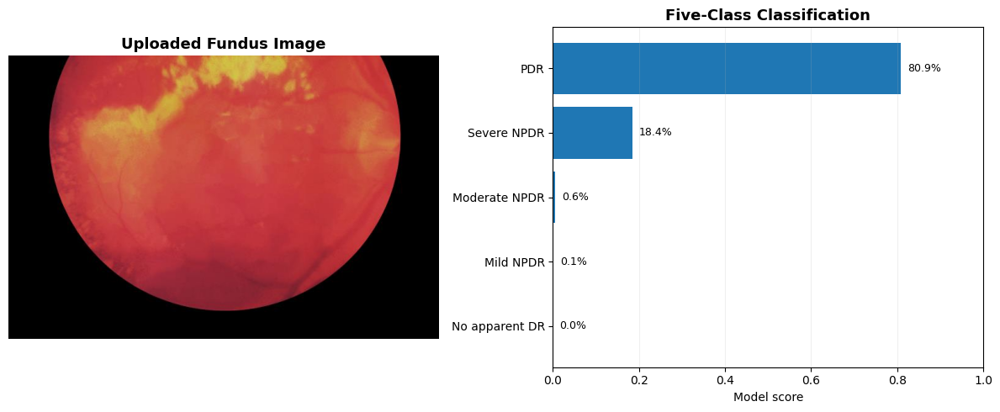

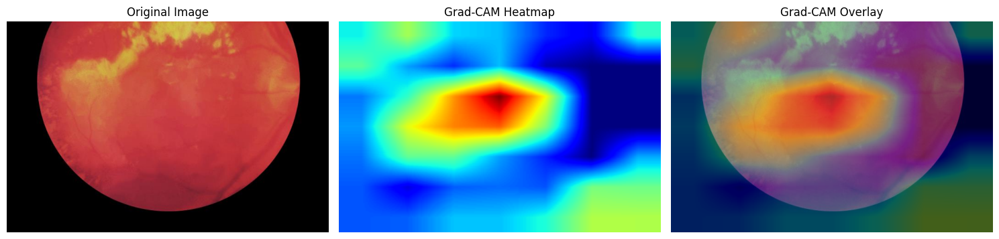

{
  "workflow_quality_result": {
    "passed": true,
    "brightness": 66.03,
    "contrast": 54.39,
    "warnings": [],
    "method": "Unvalidated technical heuristics"
  },
  "brightness_mean_rgb": 67.35,
  "contrast_mean_rgb": 55.54,
  "method_note": "Basic technical checks are not a clinically validated quality model."
}

Reliability decision:
PROVISIONAL MODEL OUTPUT — HUMAN REVIEW REQUIRED

Workflow trace:
[
  {
    "stage": "image_quality",
    "status": "pass",
    "details": []
  },
  {
    "stage": "dr_classifier",
    "status": "complete",
    "details": {
      "predicted_class": "PDR",
      "top_class_confidence": 0.808730959892273
    }
  },
  {
    "stage": "gradcam",
    "status": "complete",
    "details": "Class-conditioned attention visualization generated."
  },
  {
    "stage": "reliability_decision",
    "status": "provisional",
    "details": [
      "No configured heuristic triggered; human review remains necessary."
    ]
  }
]


MA: Dice 0.022 | IoU 0.011 | annotated images 27
HE: Dice 0.351 | IoU 0.232 | annotated images 27
EX: Dice 0.502 | IoU 0.354 | annotated images 27
SE: Dice 0.427 | IoU 0.296 | annotated images 14


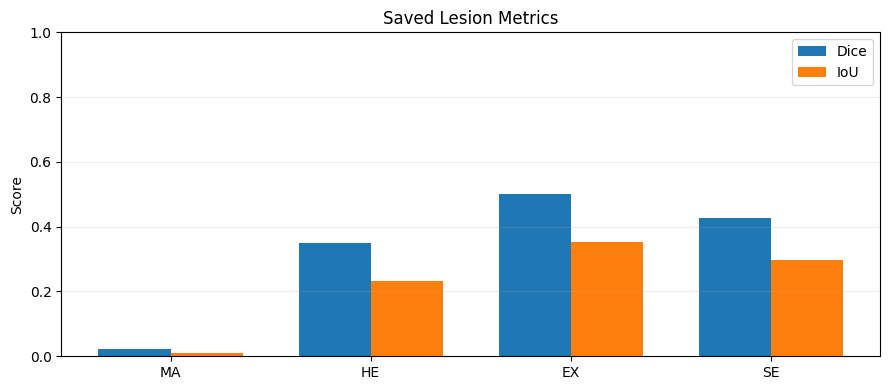

RETINA AI dashboard finished.


In [20]:

# ============================================================
# RETINA AI — COMPLETE FINAL DASHBOARD
# Readable interface | Existing classifier | Grad-CAM | Metrics
# ============================================================

import sys, json, warnings, html
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageStat
from IPython.display import display, HTML
from google.colab import files
import torch

warnings.filterwarnings("ignore")

# ---------- 1. Paths ----------
DRIVE = Path("/content/drive/MyDrive/dr_baseline_run2")
CHECKPOINT = DRIVE / "best_checkpoint/model.pt"
METRICS_FILE = DRIVE / "complete_project_output/official_test_metrics_v2.json"

candidates = [
    Path("/content/major-project-dr-recovered"),
    Path("/content/major_project_recovered"),
    Path("/content/major-project-dr"),
]
PROJECT = next(
    (p for p in candidates if (p / "dr_agentic.py").exists()), None
)

if PROJECT is None:
    raise FileNotFoundError("Cannot find the restored project and dr_agentic.py.")
if not CHECKPOINT.exists():
    raise FileNotFoundError(f"Classifier checkpoint missing: {CHECKPOINT}")

sys.path.insert(0, str(PROJECT))
sys.path.insert(0, str(PROJECT / "colab"))
import dr_agentic

dr_agentic.ROOT = PROJECT
dr_agentic.CHECKPOINT = CHECKPOINT
dr_agentic.DEVICE = "cpu"

# ---------- 2. Consistent high-contrast dashboard style ----------
display(HTML("""
<div style="font-family:Arial,sans-serif;background:#ffffff;color:#172033">
 <div style="background:#173653;color:#ffffff;padding:24px;border-radius:14px">
  <h1 style="margin:0;color:#ffffff;font-size:30px">RETINA AI</h1>
  <h3 style="margin:8px 0;color:#ffffff;font-size:17px">
   Explainable Diabetic Retinopathy Analysis
  </h3>
  <p style="margin:6px 0;color:#e8f2ff">
   Classification · Grad-CAM · Quality Review · Model Evaluation
  </p>
  <p style="font-size:12px;color:#e8f2ff;margin-bottom:0">
   ACADEMIC RESEARCH PROTOTYPE — NOT FOR CLINICAL USE
  </p>
 </div>
</div>
"""))

# ---------- 3. Upload a fundus image ----------
display(HTML("""
<div style="font-family:Arial;background:#eff6ff;color:#172033;
padding:16px;border:1px solid #bfdbfe;border-radius:12px;margin-top:14px">
<h2 style="color:#173b68;margin:0 0 8px">1. Functional AI/ML Prototype</h2>
<p style="color:#334155;margin:0">
Upload a retinal fundus image to generate a five-class prediction and explanation.
</p></div>
"""))

uploaded = files.upload()
if not uploaded:
    raise ValueError("No image was uploaded.")

image_filename = next(iter(uploaded))
fundus_image = Image.open(image_filename).convert("RGB")

# ---------- 4. Load the saved classifier and run existing workflow ----------
classifier = dr_agentic.load_model()
classifier.eval()

result = dr_agentic.run_agentic_workflow(
    fundus_image, model=classifier
)

def find_field(obj, names, depth=0):
    if depth > 7:
        return None
    if isinstance(obj, dict):
        for key, value in obj.items():
            if str(key).lower() in names and value is not None:
                return value
        for value in obj.values():
            found = find_field(value, names, depth + 1)
            if found is not None:
                return found
    elif isinstance(obj, (list, tuple)):
        for value in obj:
            found = find_field(value, names, depth + 1)
            if found is not None:
                return found
    return None

grade = find_field(result, {
    "predicted_class", "predicted_grade", "predicted_label"
})
confidence = find_field(result, {
    "top_class_confidence", "confidence", "top_probability"
})
probabilities_raw = find_field(result, {
    "class_probabilities", "probabilities"
})
quality = find_field(result, {"quality", "image_quality"})
decision = find_field(result, {"reliability_decision", "review_decision"})
trace = find_field(result, {"trace", "workflow_trace", "agent_trace"})
cam_raw = find_field(result, {"gradcam", "grad_cam", "heatmap", "cam"})

# ---------- 5. Normalize the returned class probabilities ----------
class_names = [
    "No apparent DR", "Mild NPDR", "Moderate NPDR",
    "Severe NPDR", "PDR"
]

if isinstance(probabilities_raw, dict):
    class_names = list(probabilities_raw.keys())
    probs = np.array([float(probabilities_raw[k]) for k in class_names])
elif isinstance(probabilities_raw, (list, tuple, np.ndarray, torch.Tensor)):
    if isinstance(probabilities_raw, torch.Tensor):
        probabilities_raw = probabilities_raw.detach().cpu().numpy()
    probs = np.asarray(probabilities_raw, dtype=float).reshape(-1)
    if len(probs) != len(class_names):
        class_names = [f"Class {i}" for i in range(len(probs))]
else:
    probs = None

# If the workflow didn't expose probabilities, obtain them from the classifier.
if probs is None:
    x = dr_agentic.preprocess(fundus_image)
    if not isinstance(x, torch.Tensor):
        x = torch.as_tensor(x)
    if x.ndim == 3:
        x = x.unsqueeze(0)
    x = x.float().cpu()

    def get_logits(out):
        if isinstance(out, dict):
            return next(v for v in out.values()
                        if isinstance(v, torch.Tensor) and v.ndim >= 2)
        if isinstance(out, (list, tuple)):
            return next(v for v in out
                        if isinstance(v, torch.Tensor) and v.ndim >= 2)
        return out

    with torch.no_grad():
        logits = get_logits(classifier(x)).reshape(1, -1)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    if len(probs) != len(class_names):
        class_names = [f"Class {i}" for i in range(len(probs))]

pred_idx = int(np.argmax(probs))
if grade is None:
    grade = class_names[pred_idx]
if isinstance(grade, dict):
    grade = grade.get("predicted_class", grade.get("grade", str(grade)))
if confidence is None:
    confidence = float(probs[pred_idx])

confidence = float(confidence)
entropy = float(
    -(probs * np.log(probs + 1e-12)).sum() / np.log(len(probs))
) if len(probs) > 1 else 0.0

# ---------- 6. Basic image-quality details ----------
if not isinstance(quality, dict):
    try:
        quality = dr_agentic.check_image_quality(fundus_image)
    except Exception:
        quality = {}

if not isinstance(quality, dict):
    quality = {"result": str(quality)}

stats = ImageStat.Stat(fundus_image)
brightness = float(np.mean(stats.mean))
contrast = float(np.mean(stats.stddev))

# ---------- 7. Display prediction panel ----------
display(HTML(f"""
<div style="font-family:Arial;background:#ffffff;color:#172033;
border:1px solid #cbd5e1;border-radius:12px;padding:18px;margin:14px 0">
 <div style="font-size:12px;color:#475569;font-weight:bold">MODEL PREDICTION</div>
 <div style="font-size:30px;color:#174a7e;font-weight:bold;margin:7px 0">
  {html.escape(str(grade))}
 </div>
 <p style="color:#334155">Top-class model score:
 <b style="color:#172033">{confidence:.2%}</b></p>
 <p style="color:#334155">Normalized entropy:
 <b style="color:#172033">{entropy:.3f}</b></p>
 <div style="background:#fef3c7;color:#713f12;padding:12px;border-radius:8px">
  <b>Human review required.</b> Model confidence is not calibrated.
 </div>
</div>
"""))

# ---------- 8. Image and class scores ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(fundus_image)
axes[0].set_title("Uploaded Fundus Image", fontsize=13, fontweight="bold")
axes[0].axis("off")

order = np.argsort(probs)
axes[1].barh(np.array(class_names)[order], probs[order])
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("Model score")
axes[1].set_title("Five-Class Classification", fontsize=13, fontweight="bold")
axes[1].grid(axis="x", alpha=0.2)
for i, idx in enumerate(order):
    axes[1].text(min(probs[idx] + 0.015, 0.86), i,
                 f"{probs[idx]:.1%}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

# ---------- 9. Grad-CAM: use existing workflow result first ----------
display(HTML("""
<div style="font-family:Arial;background:#fff1f2;color:#172033;
padding:16px;border:1px solid #fecdd3;border-radius:12px;margin:14px 0">
<h2 style="color:#9f1239;margin:0 0 8px">3. Explainable & Trustworthy AI</h2>
<p style="color:#334155;margin:0">
Grad-CAM highlights influential image regions. It is not a lesion mask or proof of disease.
</p></div>
"""))

cam = None
cam_error = None

try:
    if cam_raw is not None:
        if isinstance(cam_raw, dict):
            cam_raw = find_field(
                cam_raw, {"heatmap", "cam", "overlay", "values"}
            )
        if isinstance(cam_raw, torch.Tensor):
            cam_raw = cam_raw.detach().cpu().numpy()
        cam = np.asarray(cam_raw, dtype=float).squeeze()

    # If the workflow didn't return a heatmap, call the project's own helper.
    if cam is None or cam.ndim != 2:
        x = dr_agentic.preprocess(fundus_image)
        if not isinstance(x, torch.Tensor):
            x = torch.as_tensor(x)
        if x.ndim == 3:
            x = x.unsqueeze(0)
        x = x.float().cpu().requires_grad_(True)
        cam_result = dr_agentic.make_gradcam(
            classifier, x, pred_idx
        )
        if isinstance(cam_result, torch.Tensor):
            cam_result = cam_result.detach().cpu().numpy()
        cam = np.asarray(cam_result, dtype=float).squeeze()

    if cam.ndim != 2:
        raise ValueError(f"Unexpected heatmap shape: {cam.shape}")

    cam = np.nan_to_num(cam)
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    cam_pil = Image.fromarray((cam * 255).astype(np.uint8))
    cam_resized = np.asarray(
        cam_pil.resize(fundus_image.size, Image.Resampling.BILINEAR)
    ) / 255.0

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(fundus_image)
    axes[0].set_title("Original Image")
    axes[1].imshow(cam_resized, cmap="jet", vmin=0, vmax=1)
    axes[1].set_title("Grad-CAM Heatmap")
    axes[2].imshow(fundus_image)
    axes[2].imshow(cam_resized, cmap="jet", alpha=0.38, vmin=0, vmax=1)
    axes[2].set_title("Grad-CAM Overlay")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

except Exception as e:
    cam_error = str(e)
    display(HTML(f"""
    <div style="background:#fff7ed;color:#9a3412;padding:12px;border-radius:8px">
    <b>Grad-CAM could not be displayed.</b><br>
    {html.escape(cam_error)}
    </div>
    """))

# ---------- 10. Quality and agent trace ----------
display(HTML("""
<div style="font-family:Arial;background:#eff6ff;color:#172033;
padding:16px;border:1px solid #bfdbfe;border-radius:12px;margin:14px 0">
<h2 style="color:#173b68;margin:0">Image Quality & Reliability Review</h2>
</div>
"""))

quality_display = {
    "workflow_quality_result": quality,
    "brightness_mean_rgb": round(brightness, 2),
    "contrast_mean_rgb": round(contrast, 2),
    "method_note": "Basic technical checks are not a clinically validated quality model."
}
print(json.dumps(quality_display, indent=2, default=str))
print("\nReliability decision:")
print(decision or "PROVISIONAL MODEL OUTPUT — HUMAN REVIEW REQUIRED")
print("\nWorkflow trace:")
print(json.dumps(trace if trace is not None else result,
                 indent=2, default=str)[:5000])

# ---------- 11. Performance evaluation ----------
display(HTML("""
<div style="font-family:Arial;background:#ecfdf5;color:#172033;
padding:16px;border:1px solid #a7f3d0;border-radius:12px;margin:14px 0">
<h2 style="color:#065f46;margin:0 0 6px">2. Performance Evaluation</h2>
<p style="color:#334155;margin:0">
Saved held-out classifier results. These are not measurements on the uploaded image.
</p></div>
"""))

metrics = [
    ("Accuracy", "72.25%"),
    ("Macro Precision", "69.91%"),
    ("Macro Recall", "68.99%"),
    ("Macro F1-score", "68.71%"),
    ("Test Images", "2,144"),
    ("Calibration / ECE", "Pending")
]

metric_html = """
<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(155px,1fr));
gap:10px;font-family:Arial">
"""
for label, value in metrics:
    metric_html += f"""
    <div style="background:#ffffff;color:#172033;border:1px solid #cbd5e1;
    border-radius:10px;padding:15px">
    <div style="color:#475569;font-size:13px">{label}</div>
    <div style="color:#174a7e;font-size:24px;font-weight:bold;margin-top:6px">
    {value}</div></div>"""
metric_html += "</div>"
display(HTML(metric_html))

display(HTML("""
<div style="font-family:Arial;background:#ffffff;color:#172033;
border:1px solid #cbd5e1;border-radius:10px;padding:15px;margin-top:12px">
<h3 style="color:#172033">Additional Evaluation</h3>
<p style="color:#334155">ROC-AUC: not available in the saved summary.</p>
<p style="color:#334155">Confusion matrix and Cohen's Kappa: not available in the saved summary.</p>
<p style="color:#334155">Cross-dataset evaluation: pending.</p>
</div>
"""))

# Saved lesion metrics, if present
if METRICS_FILE.exists():
    lesion_data = json.loads(METRICS_FILE.read_text())
    per_lesion = lesion_data.get("per_lesion_test_metrics", {})
    lesion_names, dice_values, iou_values = [], [], []

    display(HTML("""
    <div style="font-family:Arial;background:#f5f0ff;color:#172033;
    border:1px solid #ddd6fe;border-radius:12px;padding:16px;margin-top:14px">
    <h2 style="color:#5b21b6;margin:0">Saved Lesion-Segmentation Evaluation</h2>
    <p style="color:#334155">Small annotated test sample; not integrated into live inference.</p>
    </div>
    """))

    for name, vals in per_lesion.items():
        d = float(vals.get("mean_image_dice", 0))
        j = float(vals.get("mean_image_iou", 0))
        lesion_names.append(name)
        dice_values.append(d)
        iou_values.append(j)
        print(f"{name}: Dice {d:.3f} | IoU {j:.3f} | "
              f"annotated images {vals.get('annotated_test_images', 'N/A')}")

    if lesion_names:
        pos = np.arange(len(lesion_names))
        width = 0.36
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.bar(pos - width/2, dice_values, width, label="Dice")
        ax.bar(pos + width/2, iou_values, width, label="IoU")
        ax.set_xticks(pos, lesion_names)
        ax.set_ylim(0, 1)
        ax.set_ylabel("Score")
        ax.set_title("Saved Lesion Metrics")
        ax.legend()
        ax.grid(axis="y", alpha=0.2)
        plt.tight_layout()
        plt.show()

# ---------- 12. Research contribution and impact ----------
display(HTML("""
<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(280px,1fr));
gap:14px;font-family:Arial;margin-top:16px">
 <div style="background:#f5f0ff;color:#172033;border:1px solid #ddd6fe;
 border-radius:12px;padding:18px">
  <h2 style="color:#5b21b6;margin-top:0">4. Research Contribution</h2>
  <ul style="color:#334155;line-height:1.7">
   <li>Five-class DR classifier</li>
   <li>Grad-CAM explanation</li>
   <li>Basic image-quality checks</li>
   <li>Provisional reliability decision and trace</li>
   <li>Saved lesion-evaluation metrics</li>
  </ul>
 </div>
 <div style="background:#fffbeb;color:#172033;border:1px solid #fde68a;
 border-radius:12px;padding:18px">
  <h2 style="color:#92400e;margin-top:0">5. Real-World Applicability & Impact</h2>
  <ul style="color:#334155;line-height:1.7">
   <li>Research concept for AI-assisted retinal screening</li>
   <li>Supports professional review, not autonomous diagnosis</li>
   <li>SDG 3: Good Health and Well-Being</li>
   <li>Potential to support earlier screening and referral</li>
  </ul>
 </div>
</div>
<div style="font-family:Arial;background:#ffffff;color:#172033;
border:1px solid #cbd5e1;border-radius:12px;padding:18px;margin-top:14px">
<h2 style="color:#172033;margin-top:0">Implementation Status & Limitations</h2>
<p style="color:#334155"><b>Implemented:</b> classifier, Grad-CAM workflow, basic quality checks and provisional human-review decision.</p>
<p style="color:#334155"><b>Pending:</b> clinical metadata fusion, calibrated uncertainty/ECE, independent cross-dataset validation and clinical reliability validation.</p>
<p style="color:#334155"><b>Lesion segmentation:</b> saved evaluation exists, but it is not integrated into live inference.</p>
<div style="background:#fef3c7;color:#713f12;padding:12px;border-radius:8px">
<b>Research prototype only.</b> Do not use its predictions for diagnosis or treatment.
</div>
</div>
"""))

print("RETINA AI dashboard finished.")


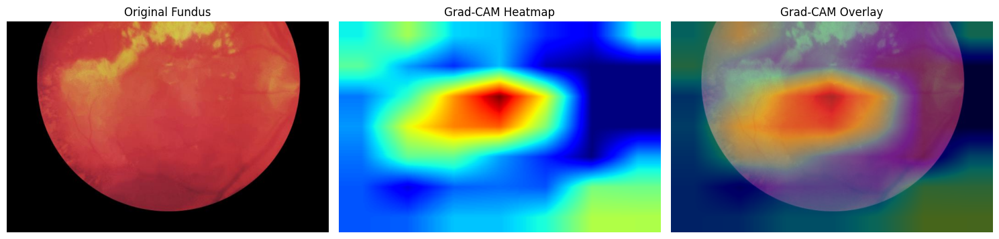

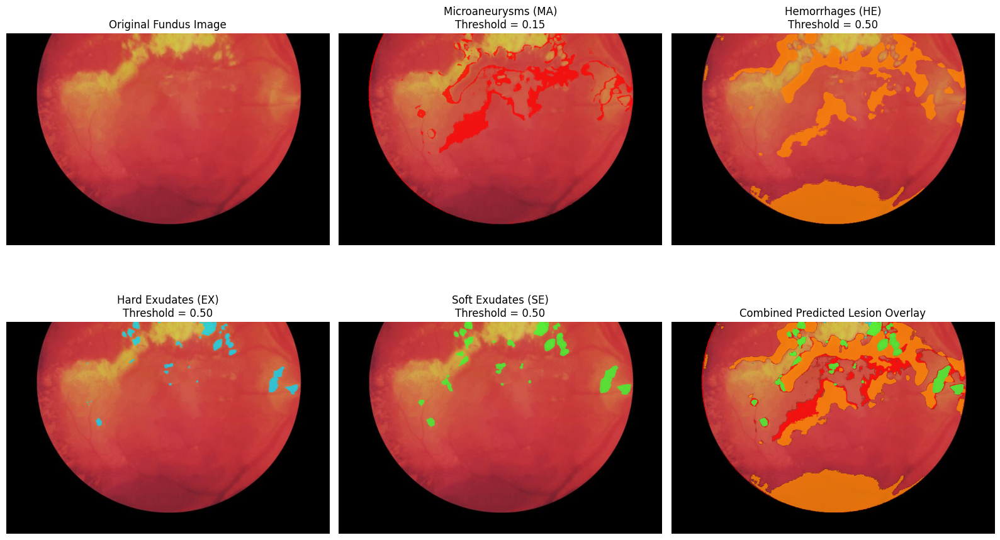

Microaneurysms (MA): predicted pixel coverage = 5.847% (threshold 0.15)
Hemorrhages (HE): predicted pixel coverage = 14.502% (threshold 0.50)
Hard Exudates (EX): predicted pixel coverage = 1.292% (threshold 0.50)
Soft Exudates (SE): predicted pixel coverage = 1.960% (threshold 0.50)

Important research limitation:
Saved evaluation was conducted on a small annotated test set. The saved MA Dice score was approximately 0.022, so microaneurysm predictions in particular may be unreliable. Predicted masks must not be presented as verified lesions.
Visual evidence section finished.


In [21]:

# ============================================================
# RETINA AI — GRAD-CAM + LESION SEGMENTATION VISUALIZATION
# Uses existing uploaded image and saved checkpoints
# ============================================================

import sys, json
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, HTML

# ---------- Paths ----------
DRIVE = Path("/content/drive/MyDrive/dr_baseline_run2")
LESION_CHECKPOINT = DRIVE / "lesion_evidence/best_lesion_unet_v2.pt"

source_candidates = [
    Path("/content/major_project_recovered/source"),
    Path("/content/major-project-dr-recovered/source"),
    Path("/content/major-project-dr/source"),
]

SOURCE = next(
    (p for p in source_candidates if (p / "lesion_evidence.py").exists()),
    None
)

if SOURCE is None:
    raise FileNotFoundError(
        "Cannot find source/lesion_evidence.py in the recovered project."
    )
if not LESION_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"Saved lesion checkpoint not found: {LESION_CHECKPOINT}"
    )
if "fundus_image" not in globals():
    raise RuntimeError(
        "The uploaded image variable fundus_image is missing. "
        "Run the image-upload part of your dashboard first."
    )

sys.path.insert(0, str(SOURCE))
from lesion_evidence import LesionUNet

device = torch.device("cpu")
fundus_image = fundus_image.convert("RGB")

display(HTML("""
<div style="font-family:Arial;background:#173653;color:white;
padding:20px;border-radius:12px">
<h2 style="color:white;margin:0">RETINA AI — Visual Evidence</h2>
<p style="color:white;margin-bottom:0">
Grad-CAM explanation and predicted lesion-segmentation maps
</p>
</div>
"""))

# ---------- 1. Display Grad-CAM ----------
# Reuse the heatmap produced by your previous dashboard.
display(HTML("""
<h3 style="color:#174a7e">A. Grad-CAM Explanation</h3>
<p style="color:#334155">
Grad-CAM highlights regions influencing the classifier. It does not
identify or confirm individual lesions.
</p>
"""))

if "cam" in globals() and cam is not None:
    heat = np.asarray(cam, dtype=np.float32).squeeze()
    if heat.ndim == 2:
        heat = np.nan_to_num(heat)
        heat = (heat - heat.min()) / (heat.max() - heat.min() + 1e-8)
        heat = np.asarray(
            Image.fromarray((heat * 255).astype(np.uint8)).resize(
                fundus_image.size, Image.Resampling.BILINEAR
            )
        ) / 255.0

        fig, ax = plt.subplots(1, 3, figsize=(15, 5))
        ax[0].imshow(fundus_image)
        ax[0].set_title("Original Fundus")
        ax[1].imshow(heat, cmap="jet", vmin=0, vmax=1)
        ax[1].set_title("Grad-CAM Heatmap")
        ax[2].imshow(fundus_image)
        ax[2].imshow(heat, cmap="jet", alpha=0.40, vmin=0, vmax=1)
        ax[2].set_title("Grad-CAM Overlay")
        for a in ax:
            a.axis("off")
        plt.tight_layout()
        plt.show()
    else:
        print("The stored Grad-CAM is not a 2D heatmap.")
else:
    print(
        "No Grad-CAM variable was retained from the previous cell. "
        "The lesion-segmentation section below can still run."
    )

# ---------- 2. Restore saved lesion model ----------
display(HTML("""
<h3 style="color:#174a7e">B. Lesion Segmentation</h3>
<p style="color:#334155">
These are predictions from the saved segmentation model, not ground-truth
annotations or confirmed clinical findings.
</p>
"""))

lesion_model = LesionUNet(out_channels=4)
checkpoint = torch.load(
    LESION_CHECKPOINT, map_location="cpu", weights_only=False
)

if isinstance(checkpoint, dict):
    state = checkpoint.get(
        "model_state_dict",
        checkpoint.get("state_dict", checkpoint)
    )
else:
    state = checkpoint

# Handle checkpoints saved with a "module." prefix.
if isinstance(state, dict):
    state = {
        (k[7:] if k.startswith("module.") else k): v
        for k, v in state.items()
    }

lesion_model.load_state_dict(state, strict=True)
lesion_model.to(device).eval()

# ---------- 3. Preprocess image for lesion model ----------
# Model input size and normalization used by this project.
image_size = 512
resized = fundus_image.resize(
    (image_size, image_size), Image.Resampling.BILINEAR
)
arr = np.asarray(resized, dtype=np.float32) / 255.0

mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

normalized = (arr - mean) / std
tensor = torch.from_numpy(normalized.transpose(2, 0, 1)).unsqueeze(0).float()

with torch.no_grad():
    output = lesion_model(tensor)

if isinstance(output, dict):
    output = next(
        v for v in output.values()
        if isinstance(v, torch.Tensor) and v.ndim >= 4
    )
elif isinstance(output, (list, tuple)):
    output = next(
        v for v in output
        if isinstance(v, torch.Tensor) and v.ndim >= 4
    )

if output.ndim != 4 or output.shape[1] != 4:
    raise ValueError(
        f"Expected segmentation output with 4 channels; got {tuple(output.shape)}"
    )

# Convert logits to probabilities.
# If outputs are already bounded probabilities, retain them.
if output.min().item() < 0 or output.max().item() > 1:
    probabilities = torch.sigmoid(output)
else:
    probabilities = output

probabilities = F.interpolate(
    probabilities,
    size=(fundus_image.height, fundus_image.width),
    mode="bilinear",
    align_corners=False
)[0].cpu().numpy()

# The validation-selected thresholds saved with this model.
lesion_names = [
    "Microaneurysms (MA)",
    "Hemorrhages (HE)",
    "Hard Exudates (EX)",
    "Soft Exudates (SE)"
]
thresholds = [0.15, 0.50, 0.50, 0.50]

# ---------- 4. Display individual predicted masks ----------
# Colours distinguish the model's four predicted output channels.
lesion_colours = [
    (1.0, 0.0, 0.0),   # MA: red
    (1.0, 0.55, 0.0),  # HE: orange
    (0.0, 0.85, 1.0),  # EX: cyan
    (0.2, 1.0, 0.2),   # SE: green
]

masks = [
    probabilities[i] >= thresholds[i]
    for i in range(4)
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

axes[0].imshow(fundus_image)
axes[0].set_title("Original Fundus Image")
axes[0].axis("off")

for i in range(4):
    axes[i + 1].imshow(fundus_image)
    coloured = np.zeros(
        (fundus_image.height, fundus_image.width, 4),
        dtype=np.float32
    )
    coloured[..., :3] = lesion_colours[i]
    coloured[..., 3] = masks[i].astype(np.float32) * 0.75
    axes[i + 1].imshow(coloured)
    axes[i + 1].set_title(
        f"{lesion_names[i]}\nThreshold = {thresholds[i]:.2f}"
    )
    axes[i + 1].axis("off")

# Combined overlay
axes[5].imshow(fundus_image)
combined = np.zeros(
    (fundus_image.height, fundus_image.width, 4),
    dtype=np.float32
)
for i in range(4):
    combined[..., :3][masks[i]] = lesion_colours[i]
    combined[..., 3][masks[i]] = 0.75

axes[5].imshow(combined)
axes[5].set_title("Combined Predicted Lesion Overlay")
axes[5].axis("off")

plt.tight_layout()
plt.show()

# ---------- 5. Report predicted pixel coverage ----------
display(HTML("""
<div style="font-family:Arial;background:#eff6ff;color:#172033;
padding:15px;border-radius:10px;margin-top:12px">
<h3 style="color:#174a7e;margin-top:0">C. Segmentation Summary</h3>
<p style="color:#334155">
Pixel coverage is the proportion of image pixels classified positive by
each model output. It is not a count of individual lesions.
</p>
</div>
"""))

for name, mask, threshold in zip(lesion_names, masks, thresholds):
    coverage = float(mask.mean() * 100)
    print(
        f"{name}: predicted pixel coverage = {coverage:.3f}% "
        f"(threshold {threshold:.2f})"
    )

print("\nImportant research limitation:")
print(
    "Saved evaluation was conducted on a small annotated test set. "
    "The saved MA Dice score was approximately 0.022, so microaneurysm "
    "predictions in particular may be unreliable. Predicted masks must "
    "not be presented as verified lesions."
)
print("Visual evidence section finished.")


Saving retinal image.jpg to retinal image (6).jpg
Image: retinal image (6).jpg
Original resolution: 700 × 460


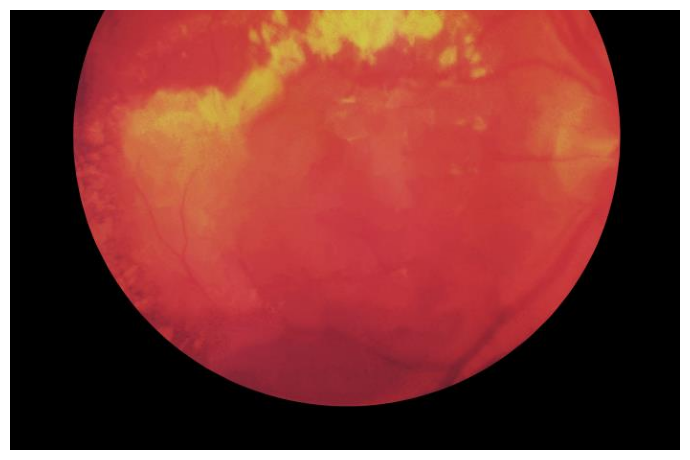

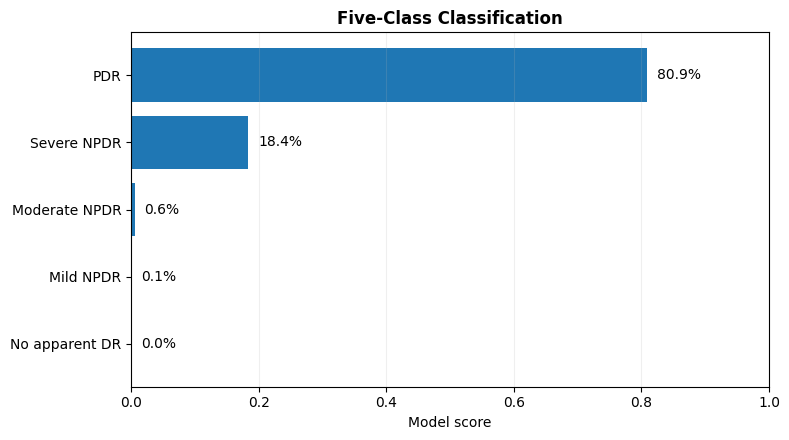

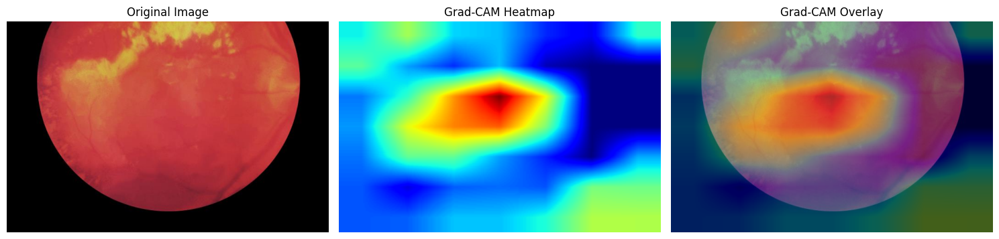

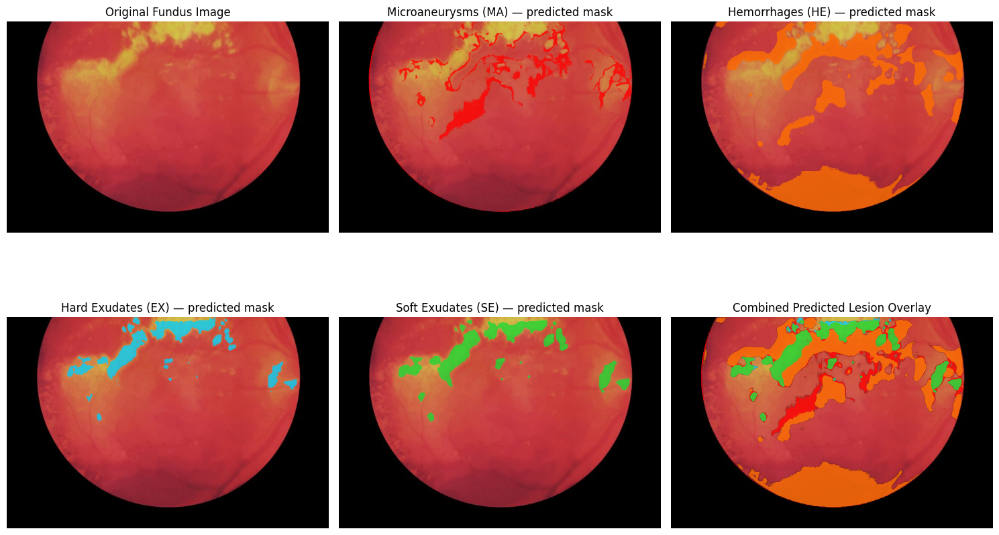

Predicted pixel coverage — not lesion counts:
Microaneurysms (MA): 4.785% of pixels (threshold=0.15)
Hemorrhages (HE): 14.487% of pixels (threshold=0.50)
Hard Exudates (EX): 3.438% of pixels (threshold=0.50)
Soft Exudates (SE): 4.004% of pixels (threshold=0.50)



Saved lesion evaluation metrics:
MA: Dice=0.022; IoU=0.011; n=27
HE: Dice=0.351; IoU=0.232; n=27
EX: Dice=0.502; IoU=0.354; n=27
SE: Dice=0.427; IoU=0.296; n=14



RETINA AI visual demonstration completed.


In [22]:

# ================================================================
# RETINA AI — FINAL VISUAL DEMO
# Original image | Grad-CAM | Lesion masks | Evaluation
# ================================================================

import sys, json, warnings, html
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageStat
from IPython.display import display, HTML
from google.colab import files
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")
DEVICE = torch.device("cpu")

# ------------------ 1. Find saved project and checkpoints ------------------
DRIVE = Path("/content/drive/MyDrive/dr_baseline_run2")
CLASSIFIER_CKPT = DRIVE / "best_checkpoint/model.pt"
LESION_CKPT = DRIVE / "lesion_evidence/best_lesion_unet_v2.pt"
METRICS_FILE = DRIVE / "complete_project_output/official_test_metrics_v2.json"

project_candidates = [
    Path("/content/major-project-dr-recovered"),
    Path("/content/major_project_recovered"),
    Path("/content/major-project-dr"),
]
PROJECT = next(
    (p for p in project_candidates if (p / "dr_agentic.py").exists()),
    None
)

if PROJECT is None:
    raise FileNotFoundError(
        "Cannot find dr_agentic.py. Restore the project folder in Colab first."
    )
if not CLASSIFIER_CKPT.exists():
    raise FileNotFoundError(f"Classifier checkpoint missing: {CLASSIFIER_CKPT}")
if not LESION_CKPT.exists():
    raise FileNotFoundError(f"Lesion checkpoint missing: {LESION_CKPT}")

sys.path.insert(0, str(PROJECT))
sys.path.insert(0, str(PROJECT / "colab"))
import dr_agentic

dr_agentic.ROOT = PROJECT
dr_agentic.CHECKPOINT = CLASSIFIER_CKPT
dr_agentic.DEVICE = "cpu"

# ------------------ 2. Readable dashboard style ------------------
display(HTML("""
<div style="font-family:Arial;background:#ffffff;color:#172033">
 <div style="background:#173653;padding:24px;border-radius:14px;color:white">
  <h1 style="color:white;margin:0">RETINA AI</h1>
  <h3 style="color:white;margin:8px 0">
   Explainable Diabetic Retinopathy Analysis
  </h3>
  <p style="color:#eaf2ff">Classification · Grad-CAM · Lesion Segmentation · Evaluation</p>
  <p style="color:#eaf2ff;font-size:12px">
   ACADEMIC RESEARCH PROTOTYPE — NOT FOR CLINICAL USE
  </p>
 </div>
</div>
"""))

# ------------------ 3. Upload the image ------------------
display(HTML("""
<div style="font-family:Arial;background:#eff6ff;color:#172033;
padding:16px;border-radius:12px;margin-top:14px">
<h2 style="color:#173b68;margin:0">1. Functional AI/ML Prototype</h2>
<p style="color:#334155">Upload a clear, colour retinal fundus photograph.</p>
</div>
"""))

uploaded = files.upload()
if not uploaded:
    raise ValueError("No image was uploaded.")

filename = next(iter(uploaded))
original = Image.open(filename).convert("RGB")

print("Image:", filename)
print("Original resolution:", original.width, "×", original.height)

# Do not crop, sharpen, recolour or stretch the original for display.
display(HTML("""
<h3 style="font-family:Arial;color:#172033">Original Fundus Image</h3>
"""))
plt.figure(figsize=(7, 7))
plt.imshow(original)
plt.axis("off")
plt.tight_layout()
plt.show()

# ------------------ 4. Load classifier and predict ------------------
classifier = dr_agentic.load_model().to(DEVICE).eval()

x = dr_agentic.preprocess(original)
if not isinstance(x, torch.Tensor):
    x = torch.as_tensor(x)
if x.ndim == 3:
    x = x.unsqueeze(0)
x = x.float().to(DEVICE)

def get_logits(output):
    if isinstance(output, dict):
        for value in output.values():
            if isinstance(value, torch.Tensor) and value.ndim >= 2:
                return value
        raise ValueError("Could not find classifier logits.")
    if isinstance(output, (tuple, list)):
        for value in output:
            if isinstance(value, torch.Tensor) and value.ndim >= 2:
                return value
        raise ValueError("Could not find classifier logits.")
    return output

with torch.no_grad():
    logits = get_logits(classifier(x)).reshape(1, -1)
    probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

class_names = [
    "No apparent DR", "Mild NPDR", "Moderate NPDR",
    "Severe NPDR", "PDR"
]
if len(probs) != 5:
    class_names = [f"Class {i}" for i in range(len(probs))]

pred_idx = int(np.argmax(probs))
predicted_grade = class_names[pred_idx]
confidence = float(probs[pred_idx])
entropy = float(
    -(probs * np.log(probs + 1e-12)).sum() / np.log(len(probs))
) if len(probs) > 1 else 0.0

display(HTML(f"""
<div style="font-family:Arial;background:#ffffff;color:#172033;
border:1px solid #cbd5e1;border-radius:12px;padding:18px;margin:12px 0">
<div style="font-size:12px;color:#475569">PROVISIONAL MODEL PREDICTION</div>
<div style="font-size:30px;font-weight:bold;color:#174a7e;margin:7px 0">
{html.escape(predicted_grade)}</div>
<p style="color:#334155">Top-class model score:
<b style="color:#172033">{confidence:.2%}</b></p>
<p style="color:#334155">Normalized entropy:
<b style="color:#172033">{entropy:.3f}</b></p>
<div style="background:#fef3c7;color:#713f12;padding:12px;border-radius:8px">
Human review required. The score is not calibrated and is not a validated
probability that the prediction is correct.
</div>
</div>
"""))

fig, ax = plt.subplots(figsize=(8, 4.5))
order = np.argsort(probs)
ax.barh(np.array(class_names)[order], probs[order])
ax.set_xlim(0, 1)
ax.set_xlabel("Model score")
ax.set_title("Five-Class Classification", fontweight="bold")
ax.grid(axis="x", alpha=0.2)
for pos, idx in enumerate(order):
    ax.text(min(probs[idx] + 0.015, 0.87), pos,
            f"{probs[idx]:.1%}", va="center")
plt.tight_layout()
plt.show()

# ------------------ 5. Grad-CAM with gradients enabled ------------------
display(HTML("""
<div style="font-family:Arial;background:#fff1f2;color:#172033;
padding:16px;border:1px solid #fecdd3;border-radius:12px;margin:14px 0">
<h2 style="color:#9f1239;margin:0">2. Grad-CAM Explanation</h2>
<p style="color:#334155;margin:7px 0 0">
This highlights regions influencing the prediction; it does not confirm individual lesions.
</p>
</div>
"""))

cam = None
cam_error = None
hook_handle = None
cache = {}

try:
    named = list(classifier.named_modules())
    layer_candidates = [
        (n, m) for n, m in named
        if n and (n.endswith("layer4") or ".layer4" in n)
    ]
    if layer_candidates:
        target_name, target_layer = layer_candidates[-1]
    else:
        convs = [
            (n, m) for n, m in named
            if n and isinstance(m, nn.Conv2d)
        ]
        if not convs:
            raise RuntimeError("No convolutional layer found for Grad-CAM.")
        target_name, target_layer = convs[-1]

    def capture_activation(module, inputs, output):
        cache["activation"] = output

    hook_handle = target_layer.register_forward_hook(capture_activation)

    classifier.zero_grad(set_to_none=True)
    x_cam = x.detach().clone().requires_grad_(True)

    with torch.enable_grad():
        output = get_logits(classifier(x_cam)).reshape(1, -1)
        score = output[0, pred_idx]

        activation = cache.get("activation")
        if activation is None or not activation.requires_grad:
            raise RuntimeError(
                "The selected layer did not retain gradients for Grad-CAM."
            )

        gradient = torch.autograd.grad(
            score, activation, retain_graph=False, create_graph=False
        )[0]

        weights = gradient.mean(dim=(2, 3), keepdim=True)
        cam_tensor = torch.relu((weights * activation).sum(dim=1, keepdim=True))
        cam_tensor = F.interpolate(
            cam_tensor, size=x_cam.shape[-2:],
            mode="bilinear", align_corners=False
        )

    cam = cam_tensor[0, 0].detach().cpu().numpy()
    cam = np.nan_to_num(cam)
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

finally:
    if hook_handle is not None:
        hook_handle.remove()
    classifier.zero_grad(set_to_none=True)

if cam is not None:
    # Resize the heatmap for visualization only.
    # Do not distort the original fundus image.
    cam_image = Image.fromarray(
        (cam * 255).astype(np.uint8)
    ).resize(original.size, Image.Resampling.BILINEAR)
    cam_display = np.asarray(cam_image) / 255.0

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(original)
    ax[0].set_title("Original Image")
    ax[1].imshow(cam_display, cmap="jet", vmin=0, vmax=1)
    ax[1].set_title("Grad-CAM Heatmap")
    ax[2].imshow(original)
    ax[2].imshow(cam_display, cmap="jet", alpha=0.38, vmin=0, vmax=1)
    ax[2].set_title("Grad-CAM Overlay")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Grad-CAM could not be generated:", cam_error)

# ------------------ 6. Load saved lesion-segmentation model ------------------
display(HTML("""
<div style="font-family:Arial;background:#eff6ff;color:#172033;
padding:16px;border:1px solid #bfdbfe;border-radius:12px;margin:14px 0">
<h2 style="color:#173b68;margin:0">3. Lesion Segmentation</h2>
<p style="color:#334155;margin:7px 0 0">
The coloured regions below are model predictions, not verified lesions.
</p>
</div>
"""))

source_candidates = [
    PROJECT / "source",
    Path("/content/major_project_recovered/source"),
    Path("/content/major-project-dr-recovered/source"),
    Path("/content/major-project-dr/source"),
]
SOURCE = next(
    (p for p in source_candidates if (p / "lesion_evidence.py").exists()),
    None
)
if SOURCE is None:
    raise FileNotFoundError("Could not locate lesion_evidence.py.")

sys.path.insert(0, str(SOURCE))
from lesion_evidence import LesionUNet

lesion_model = LesionUNet(out_channels=4)
saved = torch.load(LESION_CKPT, map_location="cpu", weights_only=False)

if isinstance(saved, dict):
    state = saved.get("model_state_dict", saved.get("state_dict", saved))
else:
    state = saved

state = {
    (k[7:] if k.startswith("module.") else k): v
    for k, v in state.items()
}
lesion_model.load_state_dict(state, strict=True)
lesion_model.eval()

# Resize the fundus image to a square without stretching it:
# preserve its aspect ratio and pad the shorter dimension.
SIZE = 512
w, h = original.size
scale = min(SIZE / w, SIZE / h)
new_w, new_h = max(1, round(w * scale)), max(1, round(h * scale))
resized = original.resize((new_w, new_h), Image.Resampling.BILINEAR)

canvas = Image.new("RGB", (SIZE, SIZE), (0, 0, 0))
left, top = (SIZE - new_w) // 2, (SIZE - new_h) // 2
canvas.paste(resized, (left, top))

arr = np.asarray(canvas, dtype=np.float32) / 255.0
mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
normalized = (arr - mean) / std
lesion_x = torch.from_numpy(
    normalized.transpose(2, 0, 1).copy()
).unsqueeze(0).float()

with torch.no_grad():
    lesion_output = lesion_model(lesion_x)

if isinstance(lesion_output, dict):
    lesion_output = next(
        v for v in lesion_output.values()
        if isinstance(v, torch.Tensor) and v.ndim == 4
    )
elif isinstance(lesion_output, (tuple, list)):
    lesion_output = next(
        v for v in lesion_output
        if isinstance(v, torch.Tensor) and v.ndim == 4
    )

if lesion_output.ndim != 4 or lesion_output.shape[1] != 4:
    raise ValueError(
        f"Expected 4 lesion output channels; got {tuple(lesion_output.shape)}"
    )

# Saved model outputs are logits unless the checkpoint/model definition says otherwise.
# Apply sigmoid to convert logits into per-pixel probabilities.
lesion_prob = torch.sigmoid(lesion_output)
lesion_prob = F.interpolate(
    lesion_prob, size=(SIZE, SIZE),
    mode="bilinear", align_corners=False
)[0].cpu().numpy()

# Remove padding and resize masks back to original image dimensions.
lesion_prob = lesion_prob[
    :, top:top + new_h, left:left + new_w
]
restored = np.stack([
    np.asarray(
        Image.fromarray((p * 255).astype(np.uint8)).resize(
            original.size, Image.Resampling.BILINEAR
        )
    ) / 255.0
    for p in lesion_prob
])

lesion_names = [
    "Microaneurysms (MA)", "Hemorrhages (HE)",
    "Hard Exudates (EX)", "Soft Exudates (SE)"
]
thresholds = [0.15, 0.50, 0.50, 0.50]
colours = [
    (1.0, 0.0, 0.0), (1.0, 0.45, 0.0),
    (0.0, 0.8, 1.0), (0.1, 0.85, 0.2)
]
masks = [restored[i] >= thresholds[i] for i in range(4)]

# First panel is original; four panels are individual lesion predictions;
# last panel combines the four masks.
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()
axes[0].imshow(original)
axes[0].set_title("Original Fundus Image")

for i in range(4):
    axes[i + 1].imshow(original)
    layer = np.zeros((original.height, original.width, 4), dtype=np.float32)
    layer[..., :3] = colours[i]
    layer[..., 3] = masks[i].astype(np.float32) * 0.78
    axes[i + 1].imshow(layer)
    axes[i + 1].set_title(lesion_names[i] + " — predicted mask")

combined = np.zeros((original.height, original.width, 4), dtype=np.float32)
for i in range(4):
    combined[..., :3][masks[i]] = colours[i]
    combined[..., 3][masks[i]] = 0.78

axes[5].imshow(original)
axes[5].imshow(combined)
axes[5].set_title("Combined Predicted Lesion Overlay")

for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()

print("Predicted pixel coverage — not lesion counts:")
for name, mask, threshold in zip(lesion_names, masks, thresholds):
    print(
        f"{name}: {mask.mean() * 100:.3f}% of pixels "
        f"(threshold={threshold:.2f})"
    )

# ------------------ 7. Saved evaluation metrics ------------------
display(HTML("""
<div style="font-family:Arial;background:#ecfdf5;color:#172033;
padding:16px;border:1px solid #a7f3d0;border-radius:12px;margin:14px 0">
<h2 style="color:#065f46;margin:0">4. Performance Evaluation</h2>
<p style="color:#334155">Saved held-out classifier results, not scores for this uploaded image.</p>
</div>
"""))

metric_cards = [
    ("Accuracy", "72.25%"),
    ("Macro Precision", "69.91%"),
    ("Macro Recall", "68.99%"),
    ("Macro F1-score", "68.71%"),
    ("Test Images", "2,144"),
    ("Calibration / ECE", "Pending")
]

display(HTML(
    '<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(145px,1fr));gap:10px;font-family:Arial">'
    + "".join(
        f'<div style="background:#fff;color:#172033;border:1px solid #cbd5e1;border-radius:10px;padding:14px">'
        f'<div style="color:#475569">{name}</div>'
        f'<div style="font-size:23px;font-weight:bold;color:#174a7e">{value}</div></div>'
        for name, value in metric_cards
    )
    + '</div>'
))

if METRICS_FILE.exists():
    data = json.loads(METRICS_FILE.read_text())
    per_lesion = data.get("per_lesion_test_metrics", {})
    print("\nSaved lesion evaluation metrics:")
    for name, values in per_lesion.items():
        print(
            f"{name}: Dice={values.get('mean_image_dice', 0):.3f}; "
            f"IoU={values.get('mean_image_iou', 0):.3f}; "
            f"n={values.get('annotated_test_images', 'N/A')}"
        )

# ------------------ 8. Research status and limitations ------------------
display(HTML("""
<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(260px,1fr));
gap:12px;font-family:Arial;margin-top:16px">
 <div style="background:#f5f0ff;color:#172033;border:1px solid #ddd6fe;
 border-radius:12px;padding:18px">
  <h2 style="color:#5b21b6">5. Research Contribution</h2>
  <p>Classifier, Grad-CAM workflow, technical image-quality checks,
  provisional review decision and saved lesion evaluation.</p>
 </div>
 <div style="background:#fffbeb;color:#172033;border:1px solid #fde68a;
 border-radius:12px;padding:18px">
  <h2 style="color:#92400e">Real-World Applicability</h2>
  <p>Research concept for AI-assisted screening support. Potential SDG 3
  contribution: Good Health and Well-Being.</p>
 </div>
</div>
<div style="font-family:Arial;background:#ffffff;color:#172033;
border:1px solid #cbd5e1;border-radius:12px;padding:18px;margin-top:12px">
<h2 style="color:#172033">Important Research Limitations</h2>
<p>Grad-CAM is not lesion segmentation. Predicted masks may contain errors.</p>
<p>Saved MA Dice was approximately 0.022 on a small test set, indicating
particularly weak microaneurysm segmentation.</p>
<p>Clinical metadata fusion, calibrated uncertainty/ECE and independent
cross-dataset validation are not yet validated.</p>
<div style="background:#fef3c7;color:#713f12;padding:12px;border-radius:8px">
Academic research prototype only. Do not use for clinical diagnosis or treatment.
</div>
</div>
"""))

print("\nRETINA AI visual demonstration completed.")


In [24]:

# ============================================================
# RETINA AI — AGENTIC ORCHESTRATION LAYER
# Reuses the existing classifier and synthetic metadata CSV
# ============================================================

import json
import pandas as pd
from pathlib import Path
from datetime import datetime

# ---- 1. Find the existing image and classifier ----
if "fundus_image" not in globals():
    raise RuntimeError(
        "Run your existing image-upload cell first. "
        "The uploaded image should be available as fundus_image."
    )

if "classifier" not in globals():
    raise RuntimeError(
        "Run your existing classifier-loading cell first. "
        "The saved classifier should be available as classifier."
    )

# ---- 2. Load synthetic metadata CSV ----
CSV_PATH = Path("/content/synthetic_clinical_metadata_pool.csv")

if not CSV_PATH.exists():
    from google.colab import files
    uploaded_csv = files.upload()
    csv_files = [
        name for name in uploaded_csv
        if name.lower().endswith(".csv")
    ]
    if not csv_files:
        raise FileNotFoundError("Please upload synthetic_clinical_metadata_pool.csv.")
    CSV_PATH = Path(csv_files[0])

metadata_df = pd.read_csv(CSV_PATH)

required_columns = {
    "record_id", "grade", "age", "gender", "duration_years",
    "hba1c", "bmi", "hypertension", "dkd", "discordant_profile"
}
missing = required_columns - set(metadata_df.columns)
if missing:
    raise ValueError(f"Metadata CSV is missing columns: {sorted(missing)}")

# Select a synthetic record for a demonstration scenario.
# Change this ID to another record from the CSV if needed.
DEMO_RECORD_ID = "SYN000000"

selected = metadata_df.loc[
    metadata_df["record_id"].astype(str) == DEMO_RECORD_ID
]
if selected.empty:
    raise ValueError(f"Record ID {DEMO_RECORD_ID} was not found in the CSV.")

synthetic_record = selected.iloc[0].to_dict()

# ---- 3. Shared state and trace ----
agent_trace = []

def record_agent(agent, status, output, reason):
    agent_trace.append({
        "agent": agent,
        "status": status,
        "output": output,
        "reason": reason
    })

# ---- 4. Image Quality Agent ----
try:
    quality_result = dr_agentic.check_image_quality(fundus_image)
    quality_status = "completed"
    quality_reason = "Existing project image-quality function executed."
except Exception as exc:
    quality_result = {"error": str(exc)}
    quality_status = "error"
    quality_reason = "Quality function could not complete."

record_agent(
    "Image Quality Agent",
    quality_status,
    quality_result,
    quality_reason
)

# ---- 5. DR Classification Agent ----
try:
    classifier_result = dr_agentic.run_agentic_workflow(
        fundus_image, model=classifier
    )
    classifier_status = "completed"
    classifier_reason = "Existing DR inference workflow executed."
except Exception as exc:
    classifier_result = {"error": str(exc)}
    classifier_status = "error"
    classifier_reason = "Existing classifier workflow failed."

record_agent(
    "DR Classification Agent",
    classifier_status,
    classifier_result,
    classifier_reason
)

# ---- 6. Synthetic Clinical Metadata Agent ----
# This row is a synthetic scenario, NOT paired with the uploaded image.
grade_map = {
    0: "No apparent DR",
    1: "Mild NPDR",
    2: "Moderate NPDR",
    3: "Severe NPDR",
    4: "PDR"
}

raw_grade = int(synthetic_record["grade"])
metadata_evidence = {
    "record_id": str(synthetic_record["record_id"]),
    "data_origin": "synthetic",
    "grade_label": grade_map.get(raw_grade, f"Unknown grade {raw_grade}"),
    "age": int(synthetic_record["age"]),
    "gender": str(synthetic_record["gender"]),
    "duration_years": float(synthetic_record["duration_years"]),
    "hba1c": float(synthetic_record["hba1c"]),
    "bmi": float(synthetic_record["bmi"]),
    "hypertension": int(synthetic_record["hypertension"]),
    "dkd": int(synthetic_record["dkd"]),
    "discordant_profile": int(synthetic_record["discordant_profile"])
}

record_agent(
    "Synthetic Clinical Metadata Agent",
    "completed",
    metadata_evidence,
    "Loaded one synthetic scenario for pipeline testing; it is not linked to the uploaded image."
)

# ---- 7. Explainability Agent ----
# The project's workflow trace is used to determine whether Grad-CAM completed.
def search_values(obj, names, depth=0):
    if depth > 8:
        return []
    found = []
    if isinstance(obj, dict):
        for key, value in obj.items():
            if str(key).lower() in names:
                found.append(value)
            found.extend(search_values(value, names, depth + 1))
    elif isinstance(obj, (list, tuple)):
        for value in obj:
            found.extend(search_values(value, names, depth + 1))
    return found

cam_values = search_values(
    classifier_result,
    {"gradcam", "grad_cam", "heatmap", "cam"}
)
gradcam_available = any(value is not None for value in cam_values)

record_agent(
    "Explainability Agent",
    "evidence_found" if gradcam_available else "check_required",
    {"gradcam_reference_found_in_workflow": gradcam_available},
    "Checks the workflow result; this does not validate heatmap quality."
)

# ---- 8. Evidence Reconciliation Agent ----
# IMPORTANT: do not compare an unpaired synthetic grade with the image prediction.
reconciliation = {
    "image_metadata_pairing": "not established",
    "clinical_image_grade_comparison": "not performed",
    "synthetic_discordance_scenario": bool(
        metadata_evidence["discordant_profile"]
    ),
    "conflict_handling_test": (
        "Synthetic record is marked discordant; human review flag raised for the scenario."
        if metadata_evidence["discordant_profile"] == 1
        else "No discordance flag in this synthetic record."
    ),
    "clinical_validity": "not established by synthetic data"
}

record_agent(
    "Evidence Reconciliation Agent",
    "completed_with_pairing_limit",
    reconciliation,
    "No image-to-record mapping exists in the supplied CSV; image and metadata grades must not be fused as if paired."
)

# ---- 9. Reliability & Human Review Agent ----
review_reasons = [
    "Research prototype: all outputs require professional review.",
    "Synthetic metadata record is not linked to the uploaded image."
]

if classifier_status != "completed":
    review_reasons.append("Classifier workflow did not complete.")
if not gradcam_available:
    review_reasons.append("Grad-CAM output was not found in the returned workflow object.")
if metadata_evidence["discordant_profile"] == 1:
    review_reasons.append("Selected synthetic scenario is marked discordant.")

reliability_result = {
    "decision": "HUMAN REVIEW REQUIRED",
    "reasons": review_reasons,
    "automated_clinical_decision": False
}

record_agent(
    "Reliability & Human Review Agent",
    "completed",
    reliability_result,
    "Applies conservative research-demo rules; not a clinically validated decision system."
)

# ---- 10. Report Agent ----
final_report = {
    "framework": "RETINA AI",
    "workflow_type": "Agent-orchestrated research prototype",
    "timestamp_utc": datetime.utcnow().isoformat() + "Z",
    "image_analysis": classifier_result,
    "synthetic_metadata_scenario": metadata_evidence,
    "evidence_reconciliation": reconciliation,
    "reliability_review": reliability_result,
    "agent_trace": agent_trace,
    "limitations": [
        "The CSV contains synthetic records.",
        "No image-to-metadata pairing has been established.",
        "Synthetic data does not validate clinical multimodal fusion.",
        "Agent orchestration does not establish clinical reliability."
    ]
}

# ---- 11. Readable output ----
from IPython.display import display, HTML

display(HTML("""
<div style="font-family:Arial;background:#173653;color:white;padding:20px;border-radius:12px">
<h1 style="color:white;margin:0">RETINA AI — Agentic Workflow</h1>
<p style="color:white">Coordinated agents · Evidence trace · Human-review safeguard</p>
</div>
"""))

for step in agent_trace:
    print(f"\nAGENT: {step['agent']}")
    print(f"STATUS: {step['status']}")
    print("REASON:", step["reason"])
    print("OUTPUT:")
    print(json.dumps(step["output"], indent=2, default=str)[:2500])

print("\nFINAL RELIABILITY DECISION")
print(json.dumps(reliability_result, indent=2))

# Save a reproducible trace without changing model checkpoints.
output_path = Path("/content/retina_ai_agentic_trace.json")
output_path.write_text(json.dumps(final_report, indent=2, default=str))
print(f"\nAgentic trace saved to: {output_path}")


Saving synthetic_clinical_metadata_pool.csv to synthetic_clinical_metadata_pool.csv



AGENT: Image Quality Agent
STATUS: completed
REASON: Existing project image-quality function executed.
OUTPUT:
{
  "passed": true,
  "brightness": 66.03,
  "contrast": 54.39,
  "warnings": [],
  "method": "Unvalidated technical heuristics"
}

AGENT: DR Classification Agent
STATUS: completed
REASON: Existing DR inference workflow executed.
OUTPUT:
{
  "predicted_class": "PDR",
  "probabilities": {
    "No apparent DR": 0.00018013098451774567,
    "Mild NPDR": 0.001441909116692841,
    "Moderate NPDR": 0.005576064344495535,
    "Severe NPDR": 0.18407092988491058,
    "PDR": 0.808730959892273
  },
  "confidence": 0.808730959892273,
  "normalized_entropy": 0.32504142539902037,
  "quality": {
    "passed": true,
    "brightness": 66.03,
    "contrast": 54.39,
    "warnings": [],
    "method": "Unvalidated technical heuristics"
  },
  "gradcam": "[[0.3658449  0.3658449  0.3658449  ... 0.40886056 0.40886056 0.40886056]\n [0.3658449  0.3658449  0.3658449  ... 0.40886056 0.40886056 0.40886056]

In [25]:

# Test the evidence-reconciliation agent using a discordant synthetic record

discordant_records = metadata_df[
    pd.to_numeric(metadata_df["discordant_profile"], errors="coerce") == 1
]

if discordant_records.empty:
    print("No discordant synthetic records were found.")
else:
    test_record = discordant_records.iloc[0]

    print("AGENTIC CONFLICT-HANDLING TEST")
    print("-" * 40)
    print("Synthetic record ID:", test_record["record_id"])
    print("Synthetic grade:", test_record["grade"])
    print("Discordant profile:", test_record["discordant_profile"])

    test_result = {
        "scenario": "synthetic_discordance_test",
        "image_metadata_pairing": "not established",
        "discordance_flag": True,
        "action": "FLAG FOR HUMAN REVIEW",
        "clinical_prediction_made": False
    }

    print("\nReconciliation result:")
    print(json.dumps(test_result, indent=2))


AGENTIC CONFLICT-HANDLING TEST
----------------------------------------
Synthetic record ID: SYN000004
Synthetic grade: 0
Discordant profile: 1

Reconciliation result:
{
  "scenario": "synthetic_discordance_test",
  "image_metadata_pairing": "not established",
  "discordance_flag": true,
  "action": "FLAG FOR HUMAN REVIEW",
  "clinical_prediction_made": false
}


In [26]:

# ============================================================
# RETINA AI — EVIDENCE RECONCILIATION AGENT v2
# Explainable rules + missing-evidence checks + review decision
# ============================================================

import json
from pathlib import Path
from datetime import datetime

# 1. Verify that the earlier workflow has run
required = ["metadata_df", "classifier_result", "agent_trace"]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        f"Missing variables: {missing}. Run the previous agentic workflow cell first."
    )

# 2. Select a synthetic discordance scenario
discordant_records = metadata_df[
    metadata_df["discordant_profile"].astype(str).isin(["1", "1.0", "True", "true"])
]

if discordant_records.empty:
    raise ValueError("No records marked discordant_profile = 1 were found.")

test_record = discordant_records.iloc[0].to_dict()

# 3. Extract classifier output
prediction = classifier_result.get("predicted_class")
confidence = classifier_result.get("confidence")
probabilities = classifier_result.get("probabilities", {})

if isinstance(confidence, (int, float)):
    confidence = float(confidence)
else:
    confidence = None

# 4. Reconcile evidence without inventing a patient-image link
reasons = []
evidence = {
    "image_prediction_available": bool(prediction),
    "image_prediction": prediction,
    "image_model_confidence": confidence,
    "synthetic_record_id": str(test_record.get("record_id", "unknown")),
    "synthetic_record_grade": test_record.get("grade"),
    "synthetic_discordance_flag": True,
    "image_metadata_pairing": "NOT ESTABLISHED",
    "actual_image_metadata_conflict_verified": False
}

if not prediction:
    reasons.append("No usable classifier prediction was returned.")

if confidence is None:
    reasons.append("Classifier confidence is unavailable.")
elif confidence < 0.60:
    reasons.append("Classifier confidence is below the demo review threshold.")

reasons.append(
    "The metadata record is synthetic and is not linked to the uploaded image."
)
reasons.append(
    "The selected synthetic record is explicitly marked discordant."
)
reasons.append(
    "A true disagreement between image and clinical metadata cannot be confirmed "
    "without a valid paired record and a defined comparison protocol."
)

decision = {
    "decision": "FLAG FOR HUMAN REVIEW",
    "reason_count": len(reasons),
    "reasons": reasons,
    "automated_clinical_decision": False,
    "test_type": "Synthetic workflow logic test"
}

# 5. Add this agent's result to the trace
reconciliation_output = {
    "evidence_summary": evidence,
    "review_decision": decision,
    "probability_scores": probabilities
}

new_trace_entry = {
    "agent": "Evidence Reconciliation Agent v2",
    "status": "completed_with_pairing_limit",
    "output": reconciliation_output,
    "reason": (
        "Evaluated available classifier output and synthetic metadata while "
        "preventing unsupported image-metadata conflict claims."
    )
}

agent_trace.append(new_trace_entry)

# 6. Display readable results
from IPython.display import display, HTML

display(HTML("""
<div style="font-family:Arial;background:#173653;color:white;
padding:20px;border-radius:12px">
<h2 style="color:white;margin:0">Evidence Reconciliation Agent v2</h2>
<p style="color:white;margin-bottom:0">
Evidence inspection · Conflict safeguards · Human-review reasoning
</p>
</div>
"""))

print("IMAGE CLASSIFIER")
print("Predicted grade:", prediction)
print("Model confidence:", confidence)

print("\nSYNTHETIC METADATA SCENARIO")
print("Record ID:", evidence["synthetic_record_id"])
print("Synthetic grade:", evidence["synthetic_record_grade"])
print("Discordance flag:", evidence["synthetic_discordance_flag"])

print("\nRECONCILIATION")
print("Image-metadata pairing:", evidence["image_metadata_pairing"])
print("Verified clinical conflict:",
      evidence["actual_image_metadata_conflict_verified"])

print("\nAGENT DECISION")
print(decision["decision"])
for i, reason in enumerate(reasons, start=1):
    print(f"{i}. {reason}")

# 7. Save a reproducible test report
report = {
    "timestamp": datetime.now().isoformat(),
    "agent": "Evidence Reconciliation Agent v2",
    "evidence": evidence,
    "decision": decision,
    "trace": agent_trace
}

report_path = Path("/content/retina_ai_reconciliation_v2.json")
report_path.write_text(json.dumps(report, indent=2, default=str))

print("\nSaved report:", report_path)
print("Evidence reconciliation test completed.")


IMAGE CLASSIFIER
Predicted grade: PDR
Model confidence: 0.808730959892273

SYNTHETIC METADATA SCENARIO
Record ID: SYN000004
Synthetic grade: 0
Discordance flag: True

RECONCILIATION
Image-metadata pairing: NOT ESTABLISHED
Verified clinical conflict: False

AGENT DECISION
FLAG FOR HUMAN REVIEW
1. The metadata record is synthetic and is not linked to the uploaded image.
2. The selected synthetic record is explicitly marked discordant.
3. A true disagreement between image and clinical metadata cannot be confirmed without a valid paired record and a defined comparison protocol.

Saved report: /content/retina_ai_reconciliation_v2.json
Evidence reconciliation test completed.


In [27]:

# ============================================================
# RETINA AI — PRESENTATION-READY AGENTIC AI DASHBOARD
# Uses the existing classifier result and reconciliation report
# ============================================================

import json, html
from pathlib import Path
from IPython.display import display, HTML

# ---------- Load existing results ----------
if "classifier_result" not in globals():
    raise RuntimeError(
        "Run the previous agentic workflow cell first to create classifier_result."
    )

report_path = Path("/content/retina_ai_reconciliation_v2.json")
if not report_path.exists():
    raise FileNotFoundError(
        "Reconciliation report not found. Run Evidence Reconciliation Agent v2 first."
    )

with open(report_path, "r") as f:
    reconciliation_report = json.load(f)

# Use actual results from the workflow and saved reconciliation report
prediction = classifier_result.get("predicted_class", "Unavailable")
confidence = classifier_result.get("confidence")
probabilities = classifier_result.get("probabilities", {})
quality = classifier_result.get("quality", {})
trace = classifier_result.get("trace", [])

evidence = reconciliation_report.get("evidence", {})
decision = reconciliation_report.get("decision", {})
reasons = decision.get("reasons", [])

# ---------- Helpers ----------
def esc(value):
    return html.escape(str(value))

def pct(value):
    try:
        return f"{float(value):.2%}"
    except (ValueError, TypeError):
        return "N/A"

# ---------- Dashboard ----------
display(HTML(f"""
<style>
.ra-wrap {{
  font-family:Arial,Helvetica,sans-serif;
  color:#172033;
  background:#ffffff;
}}
.ra-hero {{
  background:linear-gradient(120deg,#142744,#176b78);
  color:white;padding:26px;border-radius:15px;margin-bottom:18px;
}}
.ra-hero h1 {{color:white;font-size:31px;margin:0 0 8px;}}
.ra-hero p {{color:#eaf5ff;margin:5px 0;}}
.ra-section {{
  background:#ffffff;color:#172033;border:1px solid #d6e0eb;
  border-radius:13px;padding:18px;margin:14px 0;
}}
.ra-section h2 {{color:#173b68;margin:0 0 12px;font-size:20px;}}
.ra-grid {{
  display:grid;grid-template-columns:repeat(auto-fit,minmax(155px,1fr));
  gap:11px;
}}
.ra-metric {{
  background:#f4f8fc;border:1px solid #dce6f0;border-radius:10px;
  padding:14px;color:#172033;
}}
.ra-label {{font-size:12px;color:#52657b;font-weight:bold;}}
.ra-value {{font-size:23px;font-weight:bold;color:#174a7e;margin-top:7px;}}
.ra-note {{
  background:#fff5dc;color:#754c00;border:1px solid #f0d48a;
  padding:13px;border-radius:9px;line-height:1.55;
}}
.ra-ok {{
  background:#eaf8ef;color:#14532d;border:1px solid #b7e4c7;
  padding:12px;border-radius:9px;
}}
.ra-list {{line-height:1.8;color:#26364a;}}
.ra-small {{font-size:12px;color:#52657b;}}
.ra-table {{border-collapse:collapse;width:100%;font-size:14px;}}
.ra-table th,.ra-table td {{
  text-align:left;padding:10px;border-bottom:1px solid #e2e8f0;
  color:#172033;
}}
.ra-table th {{background:#eff6ff;color:#173b68;}}
</style>

<div class="ra-wrap">
 <div class="ra-hero">
  <h1>RETINA AI</h1>
  <h3 style="color:white;margin:0 0 10px">
   Multimodal Explainable Agentic AI Framework for Diabetic Retinopathy
  </h3>
  <p>Agent orchestration · Explainability · Evidence reconciliation · Human review</p>
  <p style="font-size:12px">ACADEMIC RESEARCH PROTOTYPE — NOT FOR CLINICAL USE</p>
 </div>

 <div class="ra-section">
  <h2>01 · Functional AI/ML Prototype</h2>
  <div class="ra-grid">
   <div class="ra-metric">
    <div class="ra-label">PREDICTED DR GRADE</div>
    <div class="ra-value">{esc(prediction)}</div>
   </div>
   <div class="ra-metric">
    <div class="ra-label">TOP-CLASS MODEL SCORE</div>
    <div class="ra-value">{pct(confidence)}</div>
   </div>
   <div class="ra-metric">
    <div class="ra-label">IMAGE QUALITY CHECK</div>
    <div class="ra-value" style="font-size:19px">
     {esc("Passed" if quality.get("passed") is True else "Review")}
    </div>
   </div>
   <div class="ra-metric">
    <div class="ra-label">AGENT TRACE STAGES</div>
    <div class="ra-value">{len(trace)}</div>
   </div>
  </div>
  <p class="ra-small">
   Model score is not a calibrated probability of correctness. The quality
   result uses unvalidated technical heuristics.
  </p>
 </div>

 <div class="ra-section">
  <h2>02 · Classification Evidence</h2>
  <table class="ra-table">
   <tr><th>DR Class</th><th>Model Score</th></tr>
   {''.join(
      f'<tr><td>{esc(name)}</td><td>{pct(value)}</td></tr>'
      for name, value in probabilities.items()
   ) if isinstance(probabilities, dict) else
   '<tr><td colspan="2">Class scores unavailable.</td></tr>'}
  </table>
 </div>

 <div class="ra-section">
  <h2>03 · Explainable & Trustworthy AI</h2>
  <div class="ra-grid">
   <div class="ra-metric">
    <div class="ra-label">IMAGE QUALITY</div>
    <div class="ra-value" style="font-size:18px">
     {esc(quality.get("method", "Not available"))}
    </div>
   </div>
   <div class="ra-metric">
    <div class="ra-label">GRAD-CAM</div>
    <div class="ra-value" style="font-size:18px">
     {esc("Workflow reports complete" if any(
       str(item.get("stage", "")).lower() == "gradcam"
       and item.get("status") == "complete"
       for item in trace if isinstance(item, dict)
     ) else "Check output")}
    </div>
   </div>
   <div class="ra-metric">
    <div class="ra-label">CLINICAL METADATA PAIRING</div>
    <div class="ra-value" style="font-size:18px">Not established</div>
   </div>
  </div>
  <div class="ra-note" style="margin-top:12px">
   Grad-CAM is a broad attention visualization, not lesion segmentation or
   causal proof. Clinical metadata has not been validated as paired with
   the uploaded image.
  </div>
 </div>

 <div class="ra-section">
  <h2>04 · Agentic Evidence Reconciliation</h2>
  <div class="ra-grid">
   <div class="ra-metric">
    <div class="ra-label">TEST SCENARIO</div>
    <div class="ra-value" style="font-size:18px">Synthetic discordance</div>
   </div>
   <div class="ra-metric">
    <div class="ra-label">SYNTHETIC RECORD</div>
    <div class="ra-value" style="font-size:18px">
     {esc(evidence.get("synthetic_record_id", "N/A"))}
    </div>
   </div>
   <div class="ra-metric">
    <div class="ra-label">VERIFIED CLINICAL CONFLICT</div>
    <div class="ra-value" style="font-size:18px">No</div>
   </div>
  </div>
  <div class="ra-ok" style="margin-top:12px">
   <b>Reconciliation action:</b> {esc(decision.get("decision", "Human review required"))}
  </div>
  <h3 style="color:#173b68;margin-top:16px">Reasoning trace</h3>
  <ol class="ra-list">
   {''.join(f'<li>{esc(reason)}</li>' for reason in reasons)}
  </ol>
  <p class="ra-small">
   This is a controlled synthetic workflow test. It does not establish a
   real disagreement between the uploaded image and clinical metadata.
  </p>
 </div>

 <div class="ra-section">
  <h2>05 · Performance Evaluation</h2>
  <div class="ra-grid">
   <div class="ra-metric"><div class="ra-label">TEST ACCURACY</div><div class="ra-value">72.25%</div></div>
   <div class="ra-metric"><div class="ra-label">MACRO PRECISION</div><div class="ra-value">69.91%</div></div>
   <div class="ra-metric"><div class="ra-label">MACRO RECALL</div><div class="ra-value">68.99%</div></div>
   <div class="ra-metric"><div class="ra-label">MACRO F1</div><div class="ra-value">68.71%</div></div>
   <div class="ra-metric"><div class="ra-label">TEST IMAGES</div><div class="ra-value">2,144</div></div>
   <div class="ra-metric"><div class="ra-label">CALIBRATION / ECE</div><div class="ra-value" style="font-size:18px">Pending</div></div>
  </div>
  <p class="ra-small">
   Saved held-out evaluation metrics; not a new evaluation of this uploaded image.
   Cross-dataset generalization and clinical reliability remain unvalidated.
  </p>
 </div>

 <div class="ra-section">
  <h2>06 · Research Contribution & Reproducibility</h2>
  <ul class="ra-list">
   <li>Existing five-class classifier reused without retraining.</li>
   <li>Image-quality and classification workflow executed.</li>
   <li>Agent trace and reconciliation report saved to JSON.</li>
   <li>Synthetic discordance scenario tested with a human-review action.</li>
   <li>Clinical metadata fusion and calibrated uncertainty remain pending.</li>
  </ul>
 </div>

 <div class="ra-section">
  <h2>07 · Real-World Applicability & Impact</h2>
  <p style="color:#26364a">
   Research concept for AI-assisted retinal screening support, with professional
   review required for all outputs.
  </p>
  <div class="ra-grid">
   <div class="ra-metric">
    <div class="ra-label">POTENTIAL IMPACT</div>
    <div class="ra-value" style="font-size:18px">Earlier screening support</div>
   </div>
   <div class="ra-metric">
    <div class="ra-label">SDG ALIGNMENT</div>
    <div class="ra-value" style="font-size:18px">SDG 3</div>
    <div class="ra-small">Good Health and Well-Being</div>
   </div>
  </div>
  <div class="ra-note" style="margin-top:12px">
   This prototype is for academic research and demonstration only. It must not
   be used to diagnose patients or replace an eye-care professional.
  </div>
 </div>
</div>
"""))

print("Presentation-ready dashboard displayed.")
print("Reconciliation report:", report_path)


DR Class,Model Score
No apparent DR,0.02%
Mild NPDR,0.14%
Moderate NPDR,0.56%
Severe NPDR,18.41%
PDR,80.87%


Presentation-ready dashboard displayed.
Reconciliation report: /content/retina_ai_reconciliation_v2.json
